# RetainQ information-retention study

Anonymous. CPU only. Results below are executed. Run all to reproduce the full
study, including independent source capture. It downloads the official MovieLens
25M archive (~262 MB); raw data are not embedded or redistributed. Code, fixed
configuration, exact witnesses, proofs, checksums and results are exported together.

In [1]:
import os, sys, io, json, base64, hashlib, zipfile, tempfile, subprocess, importlib.util
from pathlib import Path
PACKAGE_B85 = '''
P)h>@6aWAK2mr^hQe7lvN2s3!000jN000R9002@&K}1bOE^TC0RZUkLHx%9bSG;q&NmD!nZfFu%5d#Tr2qdK4<n+X{=8Z=|BME)j
9v1!Wz0%mw?rcf#>)!kB{6t?k3S~Z%GOhK!h{~F&=g21iq7YLvOeSZ>nxVHT9MJssPqIc272OW8!;@dDqoZF=Ni1!OH2ZBv*YBvY
8>6jgNSKC>s$+Wpj)F~I^3-}EHB-
;M^#f_ut60%Z+bXGqrfa)a{E<zdMnplv^HVNvs8OC})I&*|?~IMKOs3J?RFlbKu~>@GP2AYnv?r$=1`APWO;b;v9}-
gZ7%o(C8}~2El$9H3I?ZLLs6$f7j&Xpg90v0ol8#{?v1YH@60*NQ@yX=Iv7yBd((jkb2>t!8Bv)=Q%LM^r;w{S*G0rZOa3;uEAH@
>Lc=pLuwAkI&A@#lRL-iwAvp9G@znfoOeENEIc{TrjH@~^P7#|d9B08Vn{Z-
$dUs9`92_XfpeD1u;>1doQpb$<$MHP9wAZbnRJ>Z$OZ7A6sKvw~j*@m@NW;L>g(67j6y;|itsifh)mbQ0FvoEo&w~v5CtX7^^BJT
P?#=w5f%_$gs&VZUtl8BV3L@JQ#Gb)AKT&h)DZl)3pX}d}cARTDPZ05d0^hp9up(A?(A+K}GkQ2$yDp^WfXoc)@EKZ#Y5ycskT*a
rR0(k_R6|^3a9OCI6eoMs05fCrT{TPFRa5gHNS{6Yql~!>$D9Rk+=C#mlaBtf&3Hw&an99K1vd@<#9V)X%k{#3;0c)57BSAwl^+}
Iob?Exhn$wa%ZKwON%$~Oz9d&k7%J25;lg+%Zg&b&=1p1GhnIpp+h~HbYnqqSp<f7wl2ukMe&}g=V-
1|nE+>X=&knH(DxuULO8V9*gFFW!{^8qa}RR^KnW0BklTbo-4q*+0p9g8@sq0ovorNx+V6f)E`KJ6JB*T4`|3$XIL-AV>&9iL{QW
8esJVPdg6uISEjb`<r<*@c82qLQ>9axAQj)G7PQrUMHkoYNQ_J6He<j=4#$=+L0D$HTU)>evy5d*vJsm+&KM7}(?|7#Hw7`Pd0vR
&*`48>|j}5Z>(;<98d_b#zwIA6dEr8$UZdI<DwtM)uhT&!P6f5qUlowT|952hqHZFDp8mUjrz0N5?N-
{d_=Y9%I5pj^0*uesgs~M~ATISI712&FuA?*RyJ$kW$E2)0brrY54=jO3@b4*u5JsdOe*T_w|>Hv-
9hV?3j!H+VMukt^{P>L2lV*HjVY6c<gS4wJM6a^$O@cB=*Bpq(<c(tDnC#avbS|zI_r)0hf%}<m&GiU5qZA)U^y%h6xNb6?mx~Tc
^3cH>>;F3Ba1266-sB&K1sf1-`QEj6%_n=e`|xpmI$MtiF9r1<Y%8uSI&UG-
j?)F!dsYQth9<JgV^@WYjJ#L#<@Phi_}04&UzQDVZyJ&xSql^L8^0PGEob4>Ba#QkGhUE<<SjeTHq#I+kw<cH#-
vCu4j_79T^|VRI$yLp_#_`@hrXfRHs0?m#HCTsX*94@-^tIQ#G3nXo9UU6*hMBUK)G@-
I+J0|XQR000O8L$Fd^qocHczySaNGy?zt3jhEBV{dL|X=g5Kb8l`{QqhjvAP{`dSFG}ES9X*{r{1Sj6<WhOUL65<!BO1P{d*UDNt
G86>zQF@@aGO-pYq~Xb0bL{!~Q4ig)(yZ({dQ2Trumo9XX(H`ybuDsT?Aw&_j1P_g(*1XBLBFhndWhNX#rW^1Xt(?iG;CtN@P#d1
G-dnA5pJrYQV3hNPokz0#oX9&6dohtskDy*aR`0_-`jMFTBorph}u@Kz{|sy1-
i=;hFr(^Iq9+N2zXL=Tbm>1Z=e_t~?~jTRw%H<tXv^s##+%Y5Z<F+wwCE`1dvr_E<v#FCjf<tVFhl=xCx4jc$(WNDSVq!xqK^so{
NI2N*1=N(2B&_T)^Y=%;80<G^q2DDZP5z>T04#;uVtpEY7#FSp-=#DC*VeF)qLFsW&=uIht;iJsvn7%{Q1aZkWUdbf#n@Vx-
D3hr1;>*GovW?>O(&sb7g#t<ae;Rlt3_PP~RrGZ7UL$CDJ85LK4kO-
F76(ryzV$IJLZF{Cef=?mB@jxB&zsQ^*(=1%QD1B=F3SXNoOtjn@Tg6#-
(DL)f1yFJc{*r{HV3DVs7uItM5~wEiR=dyskGmH?fwB!O9KQH000080LZXXU8_aHU`GG|08Ib@01yBG0CHt<b!l>CZDnqBb1rmvb
QQ`m3V<*S1<*Z*`4~&VC5LGZg4m`-+rir##|O`5?XSp+fJi-
=rstQNY8t(?QO+z9zza6gxnJsJMDLc5cKZ^EU<T6%P)h>@6aWAK2mtP`QeA3Mty(nz001@s000>P0044jbYW?3abI(Eb!2%jUtei
%X>?y-E^v8MQc`lv%g?LK&8$jIQ3y&cNzBX(RLIOr%P-
1JEXmBz(=AFZNzDVX6pBkqQ!4e8l$5vtP)h>@6aWAK2mpq#QeApvKG<Iu004YV000&M0044jbYW?3abI(Eb!2%jWq4s@bS`jttvu
Oo<VKS3`U;Nrfuuy0q~2Y_C|Ls-p0+V)c-Ct#W*-
QGpo%ONTP%{|p~HgyedEfDWJzkwHf)JUW<+FU+!@sI@$u)UY%_RWHk3`BRbE$Yi>|0Qg;(y|s@NCxK(DU6y7Ahs$;VC6;k%|A`ql
CA@zK$?YxZ86ZpUHliZqp%URKu)&+U(n<k_aFs$xUWB5%__MBXmzcU5^4dF4=aL(^37;%nd3k+;u=T?B;Hd9#nae(1){z__+u#xN
ABpXC9+Zeb#TR4;#n+oPkOe*EL}AKtYW_&;9wk^kc*{P-
2Ge!cX=qc4B|$KUwv@7d$;S$+3w*4>uCj~+(+){S+MPoMr+RlhY=xq1FI1Io*+D*FN+|6UAPS^xLXO;_{-
Kt9Tgt(TAcHpNv1EiJ0K`5LZ|JotzAfEQ_`ci|O1TD2K$!m!%k<z*M}O@IAA-B?6k@l^Ih+T77?sG+PLJ78ft6i-
8ds8)!y4*(VLw$1^-^(SB>a3sAeo*7sO(CST-m-X$nKMvco?-j*;_E4m-K|*lXJof*u6qj3&r-
9%y*rjFo{sMhhAfg~>HO+b~ff$<Bv_&2Gk1(Sy9;>o0t`}!}S?_HPMncxXa$u>ezm=Qef9XN6jl6AHRC%54i~bt6b_jBKyF&Rw?g
e+=w&{?3;4Q6!?(gI-48sWuUe>P2a)1tNu%F`efH*9?-(^9b4Vf^Um#Y+I1#dt7=XX3{wJV<T@)jg5fVrD0>wAy%`HwcMc{XV1-
(mNGJ17E{o&)JcRqjEYwR&%>25#!xv$iQ|Y<=hD#is00*GSh9B9fS<WnB(w8uUfAW$}n$GxA|~{g0+DLc?Jku%b7><qGx)$Ho^)h
$29YE2<uhO+5rW3fOoNy3^b8p&5FZ|MGgpPv8fbks^m@aiRy~7NDp<MQUe?dfXSV<|42pSp5S6grLy-
%e6)68kP>)?EN#V#^Q6=HC^B%Kziwi4v?<cXNVJph#+(Ynn;4`45UTCpc*AR_)5frYCcWKRN#m|PoSX0&nevutn5jNaD=-
u;@l>y3c#l!#xyCJ4>T;6A;{Gy?_5A2p+u#IbO46hlvUQExCOKoldU9~VnML*g77NI6834ivi1xt>R2HQV`cAyr_ds=d2~fVm{gO
|D{=>+%dahfYdT^UqFCY-
Fr7!uIenA$Wv{m1VdQM6S;Es9gFAWV6-3@MlKN-a20SQYxM5<gp9}%NHXPeDHM*Ss0MBR+ib+;K2U7_Zi&NGQ;C#~pO-
BHJw=16nMlG8q4{h6BqpBiMTZwAhE-FY1>eSzl;38xMP<cO=K$hrMh73Bq$=<0Y0i}0+?S17DUui^E-
xfh_@r~`mf=v+mcq9&j@MPTAHWbS_Ir>{NP&1ULg7+cC&EhhN`B5^{VOxJmcbE7BW_YZ!PB>&4olL=v;8N?Wx{S>GqnUK;SL*kbc
|<aKE<-
iD_3Md|U1pIiu0%l)RzmdVFk`Mg7IkLWY!tqHM{RJ3wS3uD673!hVGR2p*XzWV(9G=pfi=zK%3T3?T+ke^ANPS4N!~JC&0P|n2mx
>%e@(0?LBNG5ze<X2e=qY`K}j>g=MKd!#1Be2pI}v%mMG<XT7j!?$g=}B*o#XgVLw8+vD+6zxe+ldo?7;!S<N^+!Qnf!Jgr1$noj
6>09geUN_FfKdHASMmi6D{HU?~6xk+M}yH7Y$h&zgri~Rh4EV^e9m8Q#)+CqlesN)!Ui{U|ryd0D@$i#J$!E7EOT_8kZI1S8PS;C
h*65lh839qT8Xg;N24{a(kR<Fj6p?=E1o%Cf^pK(4kXp;i_u=4(^uAaSNhmLdXyndfm6=W>Up9R>)Y+qJo(XR+<U;c@5xu@tEAO+
)Db$Ur8R*^TV)hSwHziND7p}F6ceiG_!CvboDF4K#P3;ch{tZbXj*u!?izQbb6;fxpUZL-
$g@%WzTxJM#%X10>`1}6cFFOqqB8GbX#vv>yg_?}e34E^FK?#{q&2KSNo#f^(&6pGIK;o7^8Zxg2F)@T?yr+Xz8=J6%K0m=nI1`+
Y|pOEkf^6CB)0kChdTZ>X+yG1p2iT%aC9i9aQ3&XRp{THCevseF%%Qs-
g6*=QyPQD09eaSg6ShnC6G;6l>Uk<MtA+VjKu)1A)rSg)k>mxOu@RhlaAv>U)?uii>#Q??vW~khgLx-yXw`e|cfpVFgJ*mmr)3;B
qbF^5`L@q~!JW+8D9dUe_pzJW2aSNG=__~J-lKPvf=---dPxF2-(1>mu+E{l*w%H*-
iWCQnv1fRzspVUZJv0LN3@`L#Sv&|uQQq!unvOQ|ehvB1oJWv0L8e?6;H)@}(q7LQ=6XGcrR$j$-
5q`{+Hi~d49OHqaaoVWY)k`I5<NdD(><((9^fvYg40sByTm&)w=jGd+o}lYE?mOP<7$rmHRs--Bg^w5k1)S!9w?_oeL`siU5UJ4h
c~-
qj!T?BO=owaL<Yki1<rmk1EF^>zE4!%bYNw7#j{?#WHf<G`P8sVg@pGV(z5|<T?V;B0H7l8#lKInp5d=O&|tV38n`6na7&QkUNHE
A0-
ng#E92^mq9zj}G6W(I(l#`CL*`7E`yeI(Zy(@rp7^*cK^JhKD|Wnlz%;`e9JFd1Son4b!ekb3Ivb7{*7S1)v<owtq6G#^4S>kPPz
i6eaxIzgu?DXRM!D{{fKyEQZI`t>4CnK*2Pvy5rc%jF{x#ba_2yX&Evj#5%!w8aqm#Hy*i%?NElBU6S+|B6<Jg22O5<Un<{drZmp
CjGtG{m{=cuWk5`$A|x)ScBlyar^lc>}bbq(`Y6T7yP8TFPqKhrXeQ7{~ojTiwX;g#7ud|*}579@tth8;t9<>bm>RvXVF!<jAH0O
Z`N6c`@zjAYrsnQ6-_H<b@r4^5Z|BR@N&x3DU`|FNt4Oj^WLfa=eaCbhK+)r-
$_K#A34pJu}Y`W?+c%>F@UdRxQzOJsnM7K^n=D1alTP*Lv;;*FCN8T1;?C8Af9$(r;FF=Tz4p)l%_reqpoLAo8v(d8-
Xtnrs;cxy0-5=xo|Fr)-
^jnnOS5T;YG2>Hcduf0zu2cE)`xbwwV(V4&2ff_JWSr25gT%!2|!qIjT{l517G)S&p=KB(!5pcSKc^q!QBfh{V6lvfSx}YZ#NYF#
Mp1{`Jf-(9U=2}q-ys_?3P&6BeBy}@^tV9kyiCn^5<U2gUU&xCcIvV)-
D)nwU+8Mj7O83S72D08A<Pc@OZ6a^Ty4ym9;m60vKQ$fLjjVgNXu#~D_x58yU@o=UdGHi&tDyvS@tQ3qV>cNHB(PtXu{R()h$GgV
PLxN$q81~LH*uRJ##-|Pn@tIN36_YTGZ1<=^h`O!bZVA1<Zuew?4AUUM7N?;%T@wzR?PV*rW{i!N`r8Qij*-
gP%<1!iED46vo<x+%b!wj`JJlWWt6hIBNR0j|DMpB@_4OD(`ierD=IXsv?>cPt0+GPWRT`w%!qPoFmE#1UNs&?oNK^BLSG!Lpo&1
+mH;isN09R-Tnk%H?xx08ZBN7%qCZ6mTzVtnf-2p1McWm<I;G`$46DvvS%dE7#iq%N&OVk=HC-iB$`+yPrJDU=%|MvAg5}fCwW(d
<Y_fUtsk0N-
8Lwl?=?_<S=k>ZdmZd}6rK1E#aA!KWKAKnWmCqs~msNKraTb%UJVM|VPXoadfI$7jn*iwDgL!AHxeMGrEwI`17u*Erm>MhjA}DVa
rCnLm1tY~ut0W-
6V*maEMOI0Z_{)Uq8CKoB$Zzoo(9_eD??~}YZ|?(E_5jyKa#GvRViH`5kZ@8gkqw~1!ZD<e%cCSBl3{0;N6VY7kMkynFsy=Ep5Ba
gUKJFvf{KC(W(5?L+cp&+5z?_ag|+8CPwD;ht^a~EUegzx@|xa&xPp-cc3=3~SJ9b%)ns`e1Ptz6b999-
{cuH;(9yXBQ2Bw0!svtZHfU}S;DlG@w%mZ;A4Z!EXp!|CRq##w0jI(G)U2E5q3AJI&&xf`$YUQaiW*Ox#dL`6M}tLY-
V|ekwowrmMB@Y|oP5t*uChUu6F8_?jdh!C?gIY@|J1+tPXZ0*{QP^!?ddX<dXMtd2qxYm+;y-
&y$tb+m2PjH_gExYlDvf!1)Bz>e*nkF!DOEzeV_7SzK>M~cTXa9YlgfTn+Hogj(ob-Ad;C!#a08gONw-NXPDnGHl_t7heKe9?1W~
x!>G@a6nqbN5r&?~W{NxUViG>GN-%B=7{RNyD_len!mpG{+}biS-
773lW6wz#Vq~2?qr7SedcP&s%*MPNQrD36RLBMK6=f}+z}k*oA^EC1SS7LK;!{-
(#bNa=9w1Y@(&~5m6@0q*^xfsf<@Y9&Mm<N`sU68|hnNDX00Swpwhl>*a{vJv0eKixzY<m#ZL4ZL8JJr<P@7e?DJK^A^tLw$#OYi
1Pc?!Wv~%B`#A-
(kdOobeVBab>Dh7}T0tV0uT=&XYEOa;)7XFzI=HCu;cuK4#a8j)kad(fcK1XJeB<2c;S`lcavE(3Ja*9Jr1u0lh*~X+F<a0VpS^>
{;xCPr`@rsv=GwI%e3K8H9Dz^jIj<QY<BUxeuhOCTcrP~MS2;Vw9v%$MSKz_Q6WR<C+l=@7@LvlCkoKTw{e6VY7tv8G@U0dNk%cd
<2ro4f><*#|qrqRlpHt}d)&w!8(tR_X(kb0&q*j%>k{u(*@8O=&*j{j0zXSZiL)XvJ8CY(jCEFjFrVF&R|4@hCxA7LI2bO2baTmq
2iC3kV9*yxsZh76Z{;@$#)hwnH6OC4*;@y1#yfon;VWiXhTR0SxMge<oGp1^ZV`{J^yDxLABPy4ZLsXFAZxtq`@wFCI9j;Zn}^mY
!m-
97i<gDP?!0InIk4G4+<8JiMIFxvn8&SUCPtS+uN)59)84|qvijYe=^WatyHAJ(@@StW`DI5|1kxj=UzrGa$*4#?izv8Z{rOmDzll
;EZ~{&0IOzDAxL?>Xmkb47QJDLW_xhgro})S)t*CQb(|hO57ZIHhQI4y^v=AO+oCY!t(!s!w7Jj7+<-
3O<;&zhC`XvS2no8;EOq>>W70rY=J>aoWgd&gX>Ta-
y(M^f|cAGbC~pB!k0+JtAjxz=rV%f4%i@yJl?Dm)lpi7BAha5AW%zzrICtM@B@p(O-
89s$doO?8=^1F@%M)pv_X+1#n|sVv7ps?XwsnxG*aRRbS9&e{DuAT4OB@-
3ZLhZo2}s7W;g;JuS7GRuAgDOGHbh0FH~%C>oEuSS6TC?7J8^_P$?4;kvdD0dKqVA%jf%cFbT`hXO!Sfy}ZysK}{N<WK)GQUA@Z>
FFRRhPV_xQ9jjpaqQs~)W1*E{}GSjxWuSHp@g4(iauF$8DDb11YsQicw*zl?kH)8dW=d{?h;%PLt8k_T<ppEkQEcN@s4GB-
`2g$_!$J3ZI{s{bqKa^SQkD$xp?m|=0i261$zGFx)lzR&Bd+P7?xY(4%>I(E%~Om_GKd3#)o2?fR%P|+IGN{{sLFhR^xx6>o0U&6
}Lc|IkmB+Nmbh?O6qS%h*cbeJDF(2a5B@ljm4SvUYwf8R)ud0(A3o51sIuwpXI@Cpiw8@seKG&X4)0%P#si_`&oSYu_)KKU21B1S
`f5{G9NQxKAKw$;x@hI&>Vj}fr}xg8EB>(_tioEShL8MuA`iUb9M>++jnhIDN+(`Sc@g%lX=2VYfjmxU`Wy|U2q!c9i3xWN&N*+V
rdFK!7zghk!$W<lzewmEun~pn?<ca&XDAP;1n4PHDDf0Oizn-
R<8O>)Q3o#dT`l(at@&pvi4k;(yX*>1>^DKA2A3Y12m~H%)z+>J_ytiQ)}M@rWFCI_6&lv8e6oefm*_~x|ou2?cO>NuV>JuZl{28
No=3p6)APFq|}d_wv`kY#I-
FQjCj<ivZ(&tact^H^CncVo}STV&(^u7Rv!c4w=Gr=pJ}^8@xv2djZ`WyhfhkcJX{#}Z@%EL*V)Mf&(f#YR;5&?QvU`Y8A#g{9+x
e>92!+Gu}ar6FvJ7ePbZe;lM@GBQAP6D8$mdJBbAJ%8I-
x4oL$0yFn~`<*3(5yjEB(Rucg~U(G)oi0W;gh{&MjM=T#kmY#PV}h%G7mQ;GHil%)t0>3uoic@FF=kl*V*@#EuT>X&ZE8(6Z(4dH
o#O(x!{r$6%|pq`#gU#pn{C57GQ12ya?#vaK9r2L)NKxD<5AxXG=+QqY^OMO!Blj6S|r7qx#8Hc@}NkU&Q60_`Y*Cs~`0^0ueq#4
lnKn_4nWCWOmB3WO!<y9rmJZ5%!#+iCWr!y?C)XtNfEUv(o=p^1JXKxK+oxov}@7^@+v2!k$P&4)9ojQ$6PKnAR>k})~?FE+FpO=
xWq#9@nX@~R$P>qNfL>X?x_tYM$D8O@seIM|5iB=zlb)pI!=W3Jv-Nh15a4IounW#t>^2K+~Yeg=!S8mttXCDUtsl~X~j@lWnrM$
0`Q%k{N^wt>O6h8*(Fj5;P2O@Hwuyk~Q-%w-MAXU|tk1uFQyj=N}CYEf-s^*p(m{pS-
0yL#~U?zS6G|`l~Q8H(8;Zl1=8Qm|J(R8HG>V$lxK9_^8@yL-mz4g2XSx|g$_hP#yN4n|F4v;~3*OJaLh6`V)(3iki^duq1pb;DV
8c3?WOn(AgJ$qJJ8_gp2N{OY#l9ba14?!7OpLo(40`fOa8tr}rStWjOnCsIr`VvdB|F3pmDIrM?9YUxNx(v-
uYoLXMdPwyb!qyD^jq21ttLLE`+1nw!NmI=khxxk9`GhjIiBWP}a;GTc5yj_E#nMRxbjUHhCGN(?)AtTa0%y@sNhW%MAU%JPrh`U
_zs}-M+`c0ClV@karbP1`h6gJ;ixr-zUD8#1OJ0@m|E^<!Y_q{;Squ?Dz_TrW-ha~!J1-lC46+_?2O+!qLl!x<29}+4bBM&-
2cL({*;^-}SNbcNe_<OBE7hdX-
;MNby(XJX<xEKzt6`4$!FesU@GeS#c}*DI+PPD~cJq6CoqYiTJ>~0g)7$_J53(kJ{zlrU>f9}dyOUBkesx3VeZqirGw#O<tQ_QKv
?czUNPY`}!wELOw%ymo>jjQ|BUt+=k%7~9-v0UxuD{J1Bs06|VY7!KEiicX*Ki*!(0WFUc&nGhIqF=3`UaT-
{ezkNuNPArLpia@R`uT@5vLiL<{D-
kHu~6qYT|8#zV2{wmmk0Q46e*UW+S+1hRk1Ee?#Ryj80Bowj$W+%l=ga!nZtqyq`DVe}m$`zAgtS)=CqLuZksLjYLpQ9IBF1V&^o
|InsZzAT>$xlAAc>B4+4qfpGvc0nQ_3uYZzr<47XMGux{d4_Ip3K+J-*H(hCl%-`esmoy%5KaP%BL`T_(o4>d-
6$S<UTyu_D%t@zoUm@4RZvbTT!0qFDIhyC+4ombYpIwukC*cMR`(NE^6~~}J^S_bc#8Bj(Z5SfS7TLNIXUr(OvlKrVh7>T>s%miC
r&16I>@)h<QWf6$?<;W>%OAVa8T^Mz>~5{xs?<)~Gu|t;n$`A89!V=;q%5gy3oV;bOjT%(z?P%2MG|is2pIhJq|`I%Byr@xLa2k$
IVReCw@wYaqgo);-`5G%mm%YRX2UO*813YNW!;V-
4?aau+N>!3qWarHxn^GW_3e5+py={GZ91u=4<&VoSgTOtbmY{kUE1&yBPD4^AFFAD6t3k1y^Ok$jG-aXJmW>E@Q}YC!Eg4pBJ}T8
wB2g9DrW25aFcLF{{I0`O9KQH0000802i`SU0Ra$=y@jq0Q!Oe02}}S0CHt?VQFr0UvqSIWO*-
TcyMKMX>Db0baO6ndCfiBa@$6h@BRv`^8mnV(j;wZY|z*m&)B1EX+4`wX6A*(MS&zpAqD{o0A(>M{rjFv-
*6!*C;PBTl|=&Gr%#_geeT_S`SRsYWwJ_^Sqy)is@RvyWUx-
+DqW;mS|5Z{C3%(B={<aL;(X=Y$630H>$J$7<YAYT={CvhYWVWy%NOgi*g8?P-q-swi6ST6?uxR8UU^YdkLrbdl-
5aE7e!VH=hv#pg|m(8Tj7*2K(U1}v3XUeOL$+y01SBtZL)Ns!2SeZ6})`E-2r-
)lkd3gP_;@P;$@8x%l#72iZdZ+`QpWkRkC)Lx5@IWw=D8Hd8kDmZxgXB_IVwS#j97Vq>j_9@`D!+{8tv=!bg`nxB<0vcX3rED>wK
@xrcAm(GAkP_UNN;Ks*ryIn0cKRPKBj?{-PP@&L5YV<doNjzcN@;vG?Q8AG3y2b7NmeHO_ot*h|wMV?6f>Ua~ni?~W$CtW-
A+DR)1TR2HpC60^F09|Swmt}m2kftG0(j%b$>$RKas|1mPWsR6rkwoIrdHM1P=$8@0e)%-acfYxEF3Tj{)jWn7Zul*&Z=-
6zUZ)S9JH+*OdGZJ%TBVz$szX}0VRajO*kHJV1+F|ExG0_3TvV{S(bwcqg-CpVnB>c1m3Tgbg4NFw<V@nbkmoUE*dEPSJ_2@4Ghk
NLZ*37~m^=U%R-
R9cZ%;?RVai*x4GG<>h*y=@=usx|D#F!QDB^#>_CWP2R840tqvg(LZV9O8n<@etOfIk7c^Km2&)i*E+$VXQ_qRe+HF&3moDF_k+^
5Mo=&eR4fe$xH?YT|DtDb%sHeZ}U6L`qNthst-
ef($OWAT(L3{x%K+1&L3E$h8m7T^L9S!#8HGERZT{}pHZ<a1dTrRRcx$`UC^)E0GU2Th$-k|lNG)VHuf8m}Z5m3z(auyYIp0nD-
vQQQqdtga&xAxY`^Qwe3I2vOZ-YD=;}us5*h7G=BymUb^dAowgM%+&JTu!`@K-
vIn}S0*UFEQ*4_dR)8LkDI6H$H&_zH;A1zY&UNsZha9uX|86p0vX1iP>R9M-
@;~i65YkH{v+6{6qcusa0mr`(}v7#EVzDWmpy(B?y2)vac_54U2qA%(jvl3&)_N)aQ~?dbGY9DF%u~mdbWdT$S3pp=&XD9LTe)k!
|KQR{OAZ(0xD%y0V44xFHmDfMV=k{xM)E9Whlve0p)6hBC8>+g#6+gO;LrwIVjd_Zi%z3_!jNb<<~3;{}ux~H?$Zm68D{bo%3ShY
Ve~Wirwl-jU=_*J=hcLLj<xile$N%X6~jj3#3Bb?&2~9{Ht&_r$;!>5|p60#=&Nu`(@;cOJBf;u`4G2-
0V282|zQ!ya=|Zwew=1uQFup83F<^_;dX2=Q#iRB`!B<4%0-@c#q-$K8aO**d+)B^#0XbL*QajCFMQrT1f-
kSJ$ww##fWew_|s%8=?(?HjKn0O78Y?<`Hs20RjAJQnq$>*840QNFlUJt7Vz&fKv~yCCKu15$buxfcv2`6VuITZ2&S-
jQQf`KmPvdm!QFRpQTQQQD7%&t_D-3@^Bo15X4a;;#(ja*qWfGOLy)!fTP8i$N>^0EqrCrpEV7Jb&-
MAwe_b(K86sU8(%G31BAs!$|3_p4=t&HsotEk8_-nUH9WgjHj-
2p5tyI9C9v5M9cdVzl#2MDRLeABH)ttqemWQCE6l9789kp%X$kn0=|c~9TU>x!0&NH$ppTLJc~f$<dp$Ai{AV6;_z$7pDp5aCi!I
eJsGn$A-5ZQhBhFvDb-aKDd)=U_@ivCg#TC{{*)WY5YXda`{Pl6emW|M+)N48h?%!aqIbYBm`cH6(oWK6^FYrf7AkOP=0Jr$&u+~
*Jg9D<`Nz%<N>{4O~=ga8zmoalGsG)Z@Q&{U99$Eax8i&W0-
j`w&g+W$S=r_RpQPQf3NVyqrHf6HG4KtfhrHj%Lptz|?w{|&4saYc-aACk30LSTZ7o-
FvrPU&t0{&T2qH;x;U^=MAh%>d_@j%<1t(L){L6!(-
JJW^%><aWrfeFAS1x>$Gnx5b8bKTdS&uu*qynuGps3G~XWL=Ar)(Sx=*K`QzEI{1TIG%<GDx@hFL9K$N8O}!YS6PyK9R&R;x0tE9
XZtNapW(Rkc{o1yo=}1YgK<k#Dpxl25QL%}5tMCAHJ9dN{f$RPS*afIP%XKdSKpE{WUMOCEU@gz3ULbLV3dytVvS$OFkZB*b6$mu
zPFMW`=#(YEvq`(0Jrbl0OtTSS5HgO&+_4Tep=$XY&9uBG<Sj|pED?ad=}O!U9Vv_AYY<=9^V%rtrpoK%F;ZE%M48!nlABTz!SF2
SxGX(nPIixdKe5L?(>kLmOii??@GhsjU8mbscn5si%A}i40{GRgnrSoG+mHlk<}|s%WvQcMaTwa3=XgxG;y^6P1>+*@>o>qg{leC
f{_>bHrXzcvbs%oQCdZ?@1sqU1E>r{U3wpb`9n(g>3dWTuU6C*o2+y+S-%HnXIhcLoWZK-QZqEvMFL!4jX|Gk`V5ph7;)*SksUR1
VC_i<)DMUQ00&A6BQZQ3rzANC?+uo&z$H~!HY|IC4=bE?`jD(Zn}S<hZ1zcHB7+)Da#W=e&jBoWvracsn%;!t(e$XfN`}hxqp@aq
7o0F$q^6WE6*?|J&IChF973b9(TUAhXkftZg`Fsys4cZaHDJ85ig+^G!oQ#o2tLp1rVFl$fB;bzFA{RqwFN{mJLSeF8QMnx_}2n3
k2diNWNPKnu;PY$NF!>IfB;Cs$ET@$5U)W`(f1^);|f3Fh&X^!<i90lfmFf2mFG>wWaRhK3S|p+Bvp+V8U?pcSLEt~QbqctD_91J
3sYbQE#_0kM$QXl4{UMl<#AJToQ;&)#HuAq+C&QCN;PK3Tk{gE??e%UdN2BW6AI@#BVR6S=#&C)%x3o>_G$JMLm)u>oj%gDc;4H2
#zbKiGM~$@q&en;@m$g@PrgMILL<VprT(+VUx1#r2W|twFle&!yh_xpBq9MHu`83)$MD&)CPcH2Ho{%6JL4B_Mm7X~ecTe1t%yXV
p*%I(wn285W!6Wa`QTW)B3s$*LP_5PN^KBT>)NKSVK3y+D6Wg`apv-
;i$!1iBkW{mCe6Mx`%Bq&W6@xkS2q{^9MeCeUMFm^7{sw?8)App2rLp5a#Cb@oY-
T^Y|YYTnly}x!{Q{wWBcwnz#~3o{O6D0JRV|Zw9aJt?ZSX*NJbJv;UR8_NBM9eWh8%Pf@vs9Xc~)&B74AQ0k4SqI#;1X3IOms^T4
?0N=^na+6miHazfBx3&H#l*t{W{%pde^h*RS<wph@&?Ev*O-+(1X%(qRzjbBE~1WZ3LDDn*~-
nlS_+tU9kA*PZO7>)$bce|^AZB`tUtiWDo_^b2qkrV(aq9_c;g22L9Cc9eC0xXTRK0E^u@h<a>$}j}Ixh5$AO<w6dSYo=<P+2@0p
ihl33rW|+(zUFbwO&Rc`{v5B3sMezPW3kqB3Pb$iJeO%vo{7!Xf!*qTsTWwLr{LN!P#M08c{?$iJTNqZYmpH3ts~73zUuE9_$Ww)
K2NM(0beO$TtEPT#y{(DDFs<V(bf?!^L>OpGRPL4fx?0Kg<IK7{u)cL@WXU(RvXQpfmD^rXv&tE8`G<ld?{32RVCN&NOH+XbPs&^
s&{)c-&DRU7=Yp;`zbrASMN;X+cv$x!D$)sTJs?Mm-IPlZ;ffWM8Re9dV2syhYJi!B&S^<6QYsTbfjn-tKSDhD6EpoJ=Cp9|r|S>
YR?`;IZ;O^fCBb;l74T_{n$?GvE|n6AFDB;+zbI^2Yv*|NgRzbMKQ0Op{F-
hVM@`|JZ3h9@ENwL}9T@0Hwirtbi=i`W}!f%F3Wky-
l17+{6`lcOGmA;GhyF9oOM|zu(rUtx$yq?4Lh%Bv8HIWeL?Jum~x>A$7PXilEE!<V8PEavQ^PNAfc#a}A%(M1N<(fy3IJgu~HH4F
zSDvJ2%LJ`ew4Z3^b@@DzD$Aa;lc{O&l5urA|ds;PnW+2qnLK9Em)8&_CAP$hLsgvt%l!7S)WyI3enX*{JDGnAbYP@`LO^kKYOc}
Ck&*I`^C=AQc@edqeX@rwgE#lZ5t-bNE1aF`-
^$B$485qe`v@k&PW+>crI6UmA%FnXEButySCxIbg`BLDBdfh4YK*XLpt;9vj6$=pwWzNdoylB`rpm0f(6Om6U5Zr;)PfT5I>oC=8
IC5Znj0-PeQy8=V(TTy11;!$m%3zE%>Rix<2rbr~YDd-
{f8OSJw5i>>zI^8Q{YY7Y!@9WzFNSA1D;5i8|r9AX(NqEQWb($w2zPDI!hBSXKH_;EyzbGs0BoybO$R`Zx5Ke9-
<J6TybzgRRl*Rb~V~OPo4gCR`X%eW+GLkBEKFJu2L+Z=fCUGu@qb{(U3K+9uft4K`tb3x=6lSau-Qf!>kwchuEHMzdl`(04OLv|T
!u-6l%(DYqT4(HosjY}xX^kTh9a-Ok*vvX!3|LD+XYm-
7i?C_(G=oANtEct4f#^jzK4I4!S{6x%sAik;vu#{~&xBSPR^BcA4<A(iY0*qR;hfucyy8Z7B&z)awo<*9v2hz|VZ2+j1^W11nJ&s
$A@dT`!dq#asN^HZ|A^Onps2(`&HDo_1&}<z$(WMD-Hek3l94ou@*+n*VFj$+3f!H)wVZ;wfLTPwjyFb6*H}j?{wPy`6yKBpK{Ey
I72L)T-U-*m{}BGDyT}NlDU6szKR*8W<f=d-zrV0hJ;5*3<-
@2yY(Ri0bU@9T#;{Eu!&H_Z4^;lKZS20evaH>f#0ERJtkZRhhAD{6){2@$idj)B5i=PHSK9L&1sIQodsaw3gZGq?Oz%c$7pM2>3Y
n6CvTc4Jmj|VbNF~+{O|$?@6S)mwcnw?c-@=iIA5suLerIa|OQhTVHd^kt`wRfyw?YhLS!hN^213w_%Ci<8Y!F}b^A8TC;mc%zF-
@mfQ<{Bp`Nd%&UvVswp1!$a#+w4Ku-gh2Ec9CL>!FUtCo92!B2`#+rr!4Z_eF~%c{rQrMRyz6oPVkgLjtoaEsj@TY)3~@D<jx<+f
mdm7}<_aCRm_{Gz~+^5E`B9OH&py(6u7gL;ufuJlvVgK5~VBq8)KBvsd8X1f*?YyA@bCS95+#IQ4Ck(;JiICXN)&c3;)f{#C{SuQ
+9jpBM5Nv#{jASSUjs)E_K7Td{GX2rzn1P=o-
;;p|8+jMoz?vDO^78=*o1OiMc0j2@0nPhqDZ97d=t775tMV&qThGs?KOUnPBOc;itUanl@_{TzDbHw!FGR9A-
_`pX3L*sa>F*3{VJ(v8&|Fc;S`qvTez!&>K5&&Aj>tezdgvUx+l{}9UYkA$|=me8RW<FT3P7+oVDN?jvCx1^{9iQdLGtx;C>21Sk
-1hV&0*(^1VDP!o9#~Mf*iY3|QRFvkiOeACvtv_J7HMC~%6JKG|a`r5+a}(aQNNbYmC_2K~qbonVfsArH`+N~+SP-
^yY;zBsMHT#mw#K#5{)JRm%|joZl4pCs9_hq6_hMhu3((>eAvdjBSb!cIj~x^h8VwMHU`T)$yC65@yYSi9gJM14vVdjn-
0eZlI3y*S<Fb9T*{A3uf&so&f^-
0SCk4j`=X0B)Kb%rg^|MhpR=(O&>7cxurg#HAQ)9PD7G+E_hzx;=qa%ZgUf+XU2?jY*mOZ}|o%}6G0Wi18FB~wRNyw)t2D-
_RXX<F8ElI0^k(gJcx~c@8f_JIeT}ih#*7NVFpKRA+pd90h6P4`p{{T2Eg3MJcjezkVfy}lhL+v<ye*|zdnp2&uBs~XP`3%;vIEH
6C6W;?+Ria9frI6!q-&JrVr64nL7r~B{d>&X+Ap_i6E^isw?1kAtGLyMc*~?Pc#!Wz;vt4CVMQp7jcT-
3Tbc3x}tmarc6Pz!ukw@>aAZ&@cbwzbyFk!jt<SuH2N4$+FMdb?|ouZ^%B|*hEs=U>oE35PupprW8vnxn6R3vxUh7eAULIcDY3W7
3S>_KLjYGI`LYt4^CSzN?WKu3KIlEw)MPbZ!2oU_nYNGl~Qn)zJ+sb#~=pH(QG+@o$?Ca*1bH&RH-0%`Tt|2~LKC-
y6dzl5UAse=3H(l<9Ssg(X0qU5mmFlA64z}k%%?0Y*#qtdX?IM#M#tVX>!sBP3aG>ER)YE|UFxjF*LswBpuzG4j;<1;vw4uh4ZMF
s1&FF`4QTv9rx8af}zDR&eGDhw*s95%wEm?|VObhsQ4)n`(pCMqcg;xG<LWrs+!gF4Qe$b-Ey-YKJ+)zE$V?lODnP@{J5FSBoY+^
Vjy+Gln6=;Cq#;;7}b!Q^u5iss>n$>j+Cdw(ffaT<0lMY|G#w*|bvn!KI7G0W2z%!|@IBI2^zQDGAndukl2a;5dQSX8xP6uE?VhX
t{Mn+`bwkLeGgEpJH%T`zLZi?N2&3~0fSp{e8H%qXtqq7Wy6IIq!UX|nCHk`3Hugqf_}(1jT7*rl5#8?43c&D$arN!!WfcZAUzTe
2xtj9EfkR40T{MiBEhVr428)*D(y-)WzxcfcD!GIjb$c}g6y?@XH@$vR?vd|mR^I*s`>eI)Y-
7&$=;JOPsdA$LaUBvP6)?{2NAaT5JSPZW8L-V~|o=*uXA$)RnkLO9Xl5P_%wv*F8Ftu5Bu$e3rZXK4aJwp-
}hX0!C(U>rL0ZIJ299O1V4<Nlw`%F+_r7NDf1J9gCKo>CMecEB^rt7Qp-
34M`<4<OBdJc$C%01000WLTWV$y8a49&Prp(f|c)5IP{);z5~9TyrnjYp|4>7mSA``=YPHrQE1VV1K4tHiwEGO$Q#XOYk-lJO#*o
8W#_!Bd#qW8M5?k8r`x`fd8mhR@Kp`UR~G9)$@K1EnB-
`Cx>05xqa*kF?BSi0eXf?`bmu?t+Ix!Bh!ov+nZTHlXDSou6jrOdrHwp%T1MXhTQN0OEjxg!~qw6Px|_c^wg!;amD-
I0X~AK3R2A^G8?yUz&K1aM~PVF+IB+{uF#q6))@cMa<ef;KEOf+Rv7J*>qsrKJydW_-cKRk_Co)siJ)+53;;Oo-
~#bs#V3#YwvpVOm{UbESOp8PueY3cSL3T&F^Em&kprF9i%8>mOBv(K3UQl?n{YXEvjS{8_<Ni3-y3&6y`~zDtdQ09c;+|-
KMA}6ItIqbS>eKT?QFvEx|2V})?qjb4r!9Dbf}a%w~jj@>Lw`=qMFZ&*=9}y4p8ddrnAk(IGFqXbP;aToE}*3u{pnQcrbS+1{#Y6
200lSN`%W<U5pvbot)Xl>~7wmDOuax80+a~IEW<h!)?5;NC<C|0{Q;XIz>oX3RzHFg`+7b5ouIlO=1au_(GTA&-
BNej3!s((fFN7qFf7U4RMv<gbr%Ifn~SyDA?|%74F3@ji@dkb_Om3nE);o5`?RBV$<^mdT=J*CLBJUPx;Q5Q3D>GIgC?^xjEf(D?
OYlxw`hdxpU&iaQ2`I{U1nQA<(&ir{m7k4g`4@1@nRbA-wqzGSB$v7z45QNvF>e4C!k(xE8?j!HvL;5CA5)5rW(FX^NsJ&G14AeJ
*GypGAw}0rpY{<XshZcifbN^PP0Uow)H0i{ACj3KIokyE4vbfu3W93TIUp9fk;lD(Lj-Mt(05;oErTd@SLv2k;iU#h_phz%Lt7GR
7Oj8`plfg4T?Z6&M7Z!$w60>Hz;7&Sq#fl^;UWhc4&AF3%c^II|0xxSC5F4CFNzIQ3L-sGE!Me5!Z-
>V_6=7US2Oi<pWH@eC?HT=2t%eAqg7s%O@@w5a``sn}U<61PGro8}ni=76(xy;Rc~9ri-
A(gSydH!LaRP3wL~Xv4FG+D($_{65M7k$PG0^HIJton*CUlkG4EXEo88uXcH0KX02{e0FF_A6*M=GfDsQ_Hs^ev<S;Ou*?i0&!|w
zG;zbxt_Q3&Y|K-hKbhJyxd@@%Q5c<L!Wvjq(UE#jv9)-leHo0g==2mwse&$gFqfk>2yKf!`-
OchRU^^MMowhNJvl;ZMP|^0$Sy0C27|GXI>-
WmYcTHx!So0v8CuKqToHmAq}BE5#UET4{_clInBl~F05aEMIO!+Z!d@ASn3cFDGBMewl`OOu#}os+uwoLFwLY#B$fN<h*&t|7z!*
3th0DheN!fxq9WUt^$_-cB=nw@c)ks;!=yZcQjm|m^@?9sDdyFy;$Q#s-Ivv`<sJ7@*08U92XsbynlTzpt!TDDq#UGd-
JG@R$sI4Yg_+c3dxZ@75m4o^XV<4^|I@%s0!Hl>!6QEL-WAn}+SJTN27>e7|*9{aRuADX&DQOx!NgLKmf*AU%Yb)?je515LYE?XK
G9J+ZlXrBw<URa5q0eu{75sZiW-3+Nw~bYTX_y1!dTUp5@?-
oIJuaSHfwtL%Y_su*jk8${BMugGHqmAa{1&U5T(kiU15ZYNaB7U3$D76g()gQ=#7F_Z5jQsE+mt|01k6NSia+7h`-
h+i67WG%K7tX+qg*zp0V?HE4s)BrXKNg?gqgf!yc_`jeMA4grGKx8#*?$OBqYf8dd!NaGw5W+v+zOc@c&?x19D7?IbZ~D#_)VXZz
e<_U;%nFvHIW}`hR{F|F}AAWmNQ$Zg;>&elPl##opK=)I~D5v~?{$Z~18L@)^2A;^ekaMe(N{glVrspaFdB^$OSrZ@LE4UVH3g=b
V6Lfwf%$eKPqD&kh`O1T?^VlK!UIJw}_CbVhZ$wYqEnKtY)9Ko|p2?k`Z6Z~uK{U$kY}7wDfg6(hL<zlLGTbN|)oXdub8JAWl9BW
aT!d*7kT|Ak%CEJ;%Q0NQEh^6^lm;usfO&oNp;IzxeV&{2k8I+uXper-
3z_>3>wS~`#`dgR^`iwX2=xlWx@C$)}N_pPw+PzjnG(YRejxLfdEFk_>y3DM=ZZB9H|@oN>`+L?y_YhvuRYeS5`>GLOQL0+j<VD_
}$^8>a;)KNkGQj?ceybboutnlFBYL)VZAswo;@fw@~C$T;aksF-
@^*vY2bT8Vu*B9;FH=XMyJ9G=KRdV9=6h@lT=i0qEeq4srNGVw4GD{3IT_sye3t$$Pu78YRoaoE=cU*+iRVQp+HcRWMqtylsYHZM
FciOj0v-fZH3#6sVmB5WlX{-
xtlwHc#(GVu>yONbQTmkH);W4mEyB0TsBXLrM$sN;*5l^d3RJWlFwFwz!lTl^73u|VAw>N|8_JZQHJ+U0tH6-
hxj}GWUpX`FVAMJy>sCsrhim;*xl%T=vU{tz#2p{kDRc!aoqcAj%|1{mNZKd()mw)n3ptr_WIue5*^U=J*U~@Y}0T=?=H$c>EKr_
dGZ|6Yf0nr5iy`8@}5zXkIW6<lBSM6@MrrYiOXix;h`Ng*n;mx4D7!RrsAz~ct*Ta1dThaqc@`B6-eY_Qw-wdLUFAUWNbVd|9uR)
A^X-A=3^nFsH_G%etGDWPnPUChYdAtF`>ebhD*RbfWrTu>C_r%Oq?UXe_B-J;0!cBto#f{OXzgDgTe0-
YbASFU0I&Utn2e9yianqaDhx~6Y#>(sG<CoX3Zkh|e&(%!^o~zu^NJcb87H=1;I5=vEntL+1hcMDwpg+o&K1U5(uoZ3r>~1hj%cN
o<qHG*4Fbgz}%24uTJIWWYNwI1rp>XbsBQB96A?>!VF{R6(X>rfT7QlhHEvW4DI1XrhV7X0zMdn%tD=_%Mee&C6z@>c!>tm<^%ZT
<^Estx+dqIdM-
7VN9lJ2hV7n5)_joOC)xnx4u=a};``u}Uv9>=_&vQmj5eUP|x><Ei!ihcdM+9k<~E_8xbg2p|Rr=VC50i|EBA}xG0tY=g7M9a+1I
8B+JQSk;%tYf5Gr~1bRF0lYl9lZ4`UD5?~_`s<P$A;ou|9kkxS;yP7iv`^#MRXVITvW?q$ERf!Uj4$pOm>!=B-
s@xj&&=Tk*oCuoJZob-CMFFaMk=NIhpGmJ|$Vat3ZVHHyqTb;*spCDk<2XmSL%Wo+%qORq|IRaH|@2mE=1bA;;SP-
M)^9xM2L^AG+2U*9<QzhL6IP^Nr99m7i7gO_uiJMtgDMAi6YTBf7{tH5YWqbpgXQ$?ww=uW`isNgxh1TmBA9)mCWWkVrF?3Hp2Cu
!!LLbNnc8%-
C<YF(wIFY0ytj$YS9~ubinxn~QR0R*k;N#hKf78)Nunr@(InH^lb{y>mxT+3AlG<C$ZJp=XA$6d$TvXlE_CRZ+!P(U~LIOoHc2Ps
xrQm!A633A!GZK5=t`OT{C3v_;2F|2WK$pL%)azaA%7#!<&+Xm+a?C*aCrOzMFLo)josf{?46qpRH9MP@dQ=kwpq$coO)g8ZfJcA
4hjcF8t<p4Ts?VIXUUx1hK7q^p?UY=_Gd-
#V%<<vrc&${VX;^{T<yhRyLlPz=suTdPV<9c5_6B~M)SiRV#wnGOnW<F8n_81HVWYVi=^JGuadv7w5O-
V0Sm_;2sUAnl9bO)1>tUBJaW_p{Wxn-
K?*ro6c8yVBaa=<Z2XG=nWx5kw7sc4wuiaUL^QR${s`DQC{PhAU8<o&tjzR`mv~qn*dS(ZZFxNS*Vo%R`_p&fyzN>FxpEaO&1R>@
5sL#jtp%n)O2`0alfopDN+sLHS7f4VG5^7RolQDo*YrkHt%b0fJv1;)JIAa)Bozo3qg`W<3*`hr9+4;5z8~7}dA8gPD3eLi#*XXm
tF43!m3RPsJwP#}f7u?5=d#qF-xsei`Zgq7N&=1b<C18Y1bb4*c;clNw)XEKLRAMEQ{0y{x%Bw&D2qu&UdAoo1p=wmZCAm|l?pP)
~;cNU$Yr>`zqVSd<4@*cO6N#BlbVs?T215gi^ba((>$ty*=q58PHY|HPDj>AzO{^!1l<)VQN3(uVAA<W8~gaQk(YmfkML%3=9yPv
%E9%9MVRBWz38GzWoPy?)j(4Y!$$N(B}V0+l$rA28wQz%N~>zY~bu>)jB439NOOR7kHRxj?z{l}Iq8t1i#wC-
j?8@@Ax|Iy#Ks`Ixr6f>6ByP4hqDn6G9UegjTRWM5T=ZT+x`5dk;?5y6mO&`+VX??$q&=VM-
O>~q7)XT$+0igJ$<z){mz*G08ugC<vFGIG)u`_TPelBDt*pCp;8Z`_}LTuVK&es1f+b=?1Nw2^4GNuo1!v&Wt!@s+qzN!&4}sOL|
@>1$^td&gsH*Z9$!LvX(A?}REiGsiUNvTTm_>T=-
LMBDOE3a^eZjI$cAfmbZ_TGNfHig_ecFo5;K>O%4j{@zo+3<OtwmlbuEF4Qlj$gjhFm3Z#Q&Bpcn+YfgK{DhKjm$CZ?e~0Drr?`x
_m8!3Qbk{KMuu6YRcv%>o;c5qKGRBKu&?<z7{N&9Dp6piZA@;(nHr(Lt<kWSe@k3G#s~sNa8rH>59}lpf)9)9kLjXJ-uu?m6QWDC
Y!b>S>>9_5o;;SWUp_M@3A<nkiFOUcoX7B~P!D)ux_>Fioyz)gBA8;IbRDlG5t1ezNR&4t?0hoO0Hr^y5jsk*im~N}v;+ywL#ONd
fym((1u2^p4UFiP2`pZ5lU2zXaemEGz-}pgYeW3uv5BHc{@!k(F#j?nXGISSNyhMZcTR42zY+NOE^Z;7>YlSKQ_X4-
q`?;98qX4A={5yg_WBM}2FW_Uz-?R+hUW(fobR*H*pEf|!8CB1{rt7=|GN>Jugmk+o95f1V#XG7+xD@Z_O_&D>(=PFEpCB-YM!RE
xQv>qO^<tkd)3HxA@X<^>PN+b+di{q)#6?_sv{1kfYOTZ?cOQ~sI09nO9KzWE3n#{NLFk6KsrVNI)IAE)xu#3-
EUxT3KZ5r{;ZWoG5Xa|;&s!f0sK4hrJ*(E58_y+U%-kQ|(SNYIKdj!ylQ(#+!VmARuKpBX;-
|@*tN7iYl!2{qv6#l7gufN$V%`h$l`a=vnX3q-KC!rGeAxwh$kMGh5|{5s{<Qg=m;RHSv(d2fXN8*0)k-
gX=NGV1=+H^y$c&_mQ9Y@U)vCt3VaR@<0Fz3kcHc+)i}wP=f%o10eA-
;g1fy<>XZQ#Dj^3ep^5@#7&5Jl0R__HzAOFB_XHDgjhd7$P28L)jnGaEVN|wPp{bXDGtr;n(6vLsYdZTvGf5~HE@@9#Hy|=qSJsc
S?@H{1RhnV72w|CJkX>KtXxEc+$7q(USR-w_knxlz^E%tsYlfh&(8nG>)xO38E=D(Vwc=AZlfKE}#L*30zilvvngBwd<iDNElDS)
xkRbur6-wlISs9Q->S;tTKM`-!T{Vw0Qq=j8SKyfEEw1@Hgb>~>IbxLXY$Y7pavA{Y{Kme~~b!%1#+DO1(b-|-
|8{ZUW^=H$k$JFh_QnwROx9?7=TX~h2PC8ndbEOZ6XC4H`0sCrftbibP#;fQDuHu8A&F{_V4w`YKI6XSr(TbYxkd+zoWBUZ0j8L_
9%`@isJ>@uEl>TR6lR>w%im@E~rpESm>e2gZ!zfBRuUj{n>hcg{40QQ=dPL9vRT<%`WLRG~015=p(`rLOUCzw2W5ngpXzr9o)2dC
+M|gG_Oh@S{MT+fIR#$04qg?IENu_Me+96UG?&-
>zUUpTt1c#xTf&49Ovxe4OL;AN*Bl7}%)Z;hShjHmyrmiObS*dJGf;fxhP~;}4V>+LZT`|cmYzVr!Ep|=5S1moF``~!^yM-
H&wUx8rOAKhR;igPitO(qLE8=ViN_RN^U6N9b*eD|UeIoKXVsH%R{TaW5quu@01z<+Y^7nOzAzL2U$&A1I3Ew&DokQ_z;(aLzJHS
rlmp{u_){k<jS7tA@;q@nq-M?^UK6xI<aG+}&Tel77ROZ+Hr=8F}2GXjhf8ZbC#k-
Di9R*dXw8~Uus;DJ!<eD`zx1=)FuNhfMvHs);?tCjn7KYdS<A^3V7KSn_CcY+zkn`G388mWfokTq%fjf?5)2z|9Eq_SU>BQA3ZQ2
n*XmY)=s(s}S#|eTU0ULz(Ey<?7he{UwRn>dkSRLfMFN7KuDLCG?63&{9Fg(nPf}uS+OR=?k9X?(^O`F+$d9qKY_i?0N^&|z&ACo
U!4j5UB{X68#{{m1;0|XQR000O87qL=ZenHf>9}oZl&?x`_7XSbNa%FU3X>M^}b98lNc`tKsb#h~6E^v9ZTI*BWNVfmZU(w5MRZG
wa$zZTeG*b*X3>yNuhUDH|$E9jXZCi;fIg-pH6#x4@r@QqsW@h%oX19#gkMlmiK7BOX+uQG>M-
lD?yx?&<TM6<py^q9|NOBVJWwFWx;YmoQg6EMRi@kZ27isoH0+AKbG=hC1x3;&px29RTAf7i};U3Q;(PEiq1#C{zf)`Pm<Xd{kk8
%+dj09;M!vjviOMcJDoagg6@)`M-rwJpOV5Eo^@Vm-
l7`HO<V<mFf`ZHQiqgW`WA;^HsN|xoj+Wa$3^tvT4kb1f76TFrpC9B2qiSV2x%dM^3o6n=Oq4#-
oMO;GXMX}5W`}@c*w`N(oTE<`<E6ry6z=`Lg$oCg$G#uVv#Cx6Y!U6&5*6{y64bSd|=ibNjE|NO(yUx__9C!P?cho%&5BzBW|3B>
b-F}CMyt(7%%jNLayZ!yN(>=nyLDvoiKk6SJh$E*z?fZcfiXc4XQ+^;0x(D5!-
#g&lseg2I5c0qlL9f&4cDU_0q1`zM8?;BKcbC@}P2&Ba*X?$?$K77He;fw<_(=4^elHNd-w&JvVLQE`bKo5NcAwk5<DP#M9`xY7-
|ZZUgI>2m{B(5o`{kEmgLu#HIKk9E7QS<AANhwOusIKU{lkMJU}E!N3Pk)6B<Fz$58&~Thh0B(1Ta71V3n<{P)tb}&A|5tdXW(x&
(bU^<_nkRa}J!SIoKlbZ|>?KvJ&xNRLe{``2dg7?~;mXrAv_*H1ny6zMm=z_-
~qK1Og=?Q6VxT<_kaMgDJ!x4~^cAV|NbakI8%rjOW&Bi9u)hicKaU2NE*3=HgLHZE7V_zu-~gVc-
}659UIPEuUQ}ni@Wlf2_s#Fv>vMOe96_-eoJn#3Q7jmwuOT<_XV&d2}yaxqhEE;|~c(QvwM{^eRhk&JD9x6=)Z3IgJML^3`-
2JsK2=SU641YPGarI~y%{m4>YIhGF8RtHM39rDZdbFCohXLu%UU53j8*8O$Ni2&&c|$A7+C5_;{4SBtgc{=kQ|-
(O8ntp^B<%4MY`fbcSgI5f0H%+iS3k9wHVMcAe0-`r-34>AtOM!xWPC5Bm+W(G~cl0n4d(*6XIU=igDUIcU62uclT*1x0Wd-
z+iM+^OI$7RA1>Jnm5i8{Fj&`BB10A!O{`8FD!o_`!##bZIuwjm3i%|y`-7rKu`w>Fqht**o7Cp;Dz4+=wX-KV>_m#L_gB$QZ83)
JSc-;}vM(^R0Q<6$~$TIyMwM!vY(EsCni^s6RSy{|j7rrh*k6LL5Ba*78fsSnCEHv-
v)lnuIVxP6l_;M6QiAXK#Q8|XJRZ!l;>?%NF3V^Kr&8lOr*_xa`IN$|{zl2AOljnmo!B;%{N2qTDt7$Tz)$lAX$#{q%kC=o8DOe8
@Xf?6(J71O=mM!?O|2aId*zjY3jN08zGzSFh%T>uDJxj-
e1jD9tYvAx%yJRiQ8U(J6|21LfRh>BRyi7DlGqXYs(o!o|Fnlb>0h`~rs-
?rPtqfjoFRHQ1GA=0UgGKLis7s)nkGsee>#h0LTXut|(57a3NbJVF`Yu%$`FqL4+%Axo$T8GB7&T2Z)X;daQ9q0!}D{1JUdStZbK
?l+^^?=D*TGC~f-iw4M0Z@3Rx{9HL5)By5(^VD-50IS>8n8~w2t@Q7G_jAp0@wz-a+f}-
2hBKUTHk82k@bH>QyZh&)<lTfKwfD~sLhOO)ch0551uxOmx&O<JB$2PAwoKM&mn4FUi4WWr#$qQnZUymH!u=Mi>T1?3gMQ7c`I#h
G6-l9VsIOcl)=5@%FUDiV(zSRk=5~yZ!)~sfgdM+k-
BU+Jd1}Y5bhL|*JPC7KxU`2@dUy3R+K{|7GefMnFJ3pm~q~@a`K()*c(tQN+4CDkf>PHut?j&DkB3N6dIBYl%0(yW|@t~hID2)CR
wXTjTs9#D)?dv3(QtZDkj?L8Be~8(35DA8<_~wEX-
M*h8J#!eE@~D<<&ZOJf285dFUh{F%!mxIjK+rAcN&VNw7)^xlmEBeJJ6qjYZYmOga`<{Ni?O+m<+Y;kq3Kb%u@aIQ`D)_iT-Sjj_
HS>r`V%MU5Ra#vDD?D7lo9<5>lP#s-
BL?r$4*jPNHyW5&LVCs$S3<Z)o^J&v6TdmP)~iSgirGTjU<qBu=TU!Y?=UZjh^;0Y{8lcn`jWNB^~9d@zv0qTR|X(@0RY<F~6!}g
3xPRLTg-B4s$-
T$fU*$2~HOG{>W+7O;HK%1nbWez~L@qo>CKI~=_*HG&h{L!%4B1#PKgWS7^$JJVF!p`b?1QG#aDVrqugUB`sxlCiI0-
#n>g8rRc!U2I!gA0bHq2q2Z7aF+$>Cz=r**q5n4ZaVhfA&P6aLA%Z0yohV@WzrP6>oQ3hxd<FT5wdnWL_Id@epCTymr6?2Z36~l4
RBpO&ZW0-^)$+jikYd#e}G{<sRZ`qI1J_XOq`-
)N$O1#e0awdyK_<8H*>Sv{(dVoXcI~0gBo{QDuNK7smN&VIYxO#FC83aIWp>HF>qqH|(9X;s8RJXBmGo6!Z1Kw(hDZf#|vy86J#K
g(zra^7O)7VG{MdB`k=!FJc$YR&DWRn#TE?RUrP<=_5h7azu%s7TmWMt-
B|bK<+c<x!m>GaNo;`M$XMir;g0J4w^8?^<BqYi=hoktO%_|5w8Bm(m33(76Hh7eHVQT;as5dYH^%CxQf`fJ!gXYLUewUjkU(GGj
Ux>QUUCq^NP+qn$1f>yEUO*=N;BJ3QU?*cVAO=?42E_^ZGgr7Rcw(RHmG<=P+l3&QcW_7692moXH*L#&sYU$|R#^EH_QeU);6u8U
$$qr}|24BmpImCrye!yOP&itT5Bd<vPXx=FViHQI3{fK?{3<mCuaYdu6lGS`~q5;hsMhFI~zsa8)ces_%&fSLR9_EJil&=gfCiE7
VedJh%bQ3q#Xo5Hu!hFNnpop2uL=Oj-
9Z769pP0#Icb4Sdww$9&++=((4;j;*c`F3i_pfHxi5pi82h;MzYnQPcZl1cizFEXz(Wf@)f#1eKvm2Q$3rB;V-
(<BCEOsnT68#9Vu`Vy9^6dTm2SMrDoX>B@1S(zQ|O4Ql7VO&&!-
KhlBpCN2F+2bG7F^JRbn7yR?m#AXSQ(iCMEP=UAyVEiqG(Di0KgpkSAqGr*O$7zu_k5Y9)<C$C)k`9y|?W#i>92bn?V5xRMN;6!%
>+H41Z1#cesYwSPChg3ZGE|jay;XA2)d<h?XqLb+{`_(RZpFWH9F^s(8G6G&IxH6=S(6sSK%Q)>7?d`U86+8x@fT5yJ-
?W1n53^N>R1%X=2*lTi-
)1S8Em}jlnH=>BV?2U<GYI5b+H@wDZRo)F;7Y}D4|`PInhCY9nGyeLFJgdPFAkPJ+)U6Jf#7eN|(*twngDGY3lpaXq8}0>l+l@O`
$T2Is752V?qM?Jq84TtJO~^<>Hu>QCP=Tu5Vdz`E5s^WcVrs+J~kRx|SJ<xOEDYXwWv*#5}=uWgorb;MTlw9x_}S+H6s;f)ih=co
bP7Pavo-D#&Tn8FJ$b6oQ94#)mzpRZPh_ovJ`Oe)4dnDn29|-
L{{jv#@$SnPQFO+W+yL4!cpHmWx!!ZQxr=M6Hx0TCQ&)+(e%J6}xIpeY0)R)52G&tyZ_-bh54j6v0x_UAL}Iu&x-
a6WgG^+47CDm+MHGwWFGapeBeelFb|S+VYbgD?#-~?CDRIsvYx?X5X2LVR@`6Yi@6EkHj8+Kd4)-XSZK+)r;YfC`*okOm6?@3O@-
TK%j^ZaJZ)rdw58}MjpgMe)g0u)ZZOf!S~QteH~z}zUJVQd4j)x{w+sArtd037Qk5|u+u(Rh(($`4XAkn!{Si{D@YQ0JG_JY7;2K
co%Y-|&Z%9Vthrq3bZz_NZ*;rlvPMTNmYzyB*yH|6**GsUDg8cG@^}SAP<icW?mrt1Pw$50?)0~-
VWU5OdP{DHSHrVAqB}2x!Ecurm)CbPHAs;1Smc2)3Xn12*tHik@woKL4-B%2%g9&ywbkVPYX0LZg>wt(1F_-
7aAY!hOCnDhc|W@Oi0Br2L4NP?RgoIMnpzoEsOgU2q`pAa#S+b|vP)F<+-3aKdHAN@a-
E@phA2hxM$ve~%&OkZMklK#y5Px^K`*awhod{x?ncoiUrw(+4{wR_D}(=`K89$Z8WZclfg|liR#!+-
L0_XNZCRjli?Ecutg?xzjDm-SORt9S@5n!IF0ZwOg4|q_%u+o?S6HPbPOr~NMFGZ@NoZwSbt|ECJ*uXZwhgRX(pmbDgX=5db%>Rm
s~FS#8F_A~_fm(THq5KSPhM4x%u<lL(=n?p3eA911!&cjxCi1Mj#uP11|rGGGn(%OlxxOh)%z`jG5{$6BidOi6_qo_j>*)+`Q`21
<@H&muPGY|QdCp6kkq3Rr(r^BT2oO3bHGL2iVj!HSpDZ5f5cW1GW2L^<kFh2*pQ3S&F4?#w||k-
t1I&R>6gpvi;C7Sj@c3e;9q_Bi=Z}0W`8b5lMw{P_1&e4$QpwJjLO_9<#PiIuxBGveJUx#!=USS05EO4-
<9aE$MG`l9Cf;fPII&~fMKkjZFT!@n9?nk(UpNdpmHpf72M*}98RL2c$XYIwhd(T5By4AbpduEujd`sZ4_9l1xC+KZ-
?Z6e;<PS){}1D-r=iFhF37<km2<?Z8wG2H_6Vh-qalJ>rrPTgHCJI(W3{7?V)752|t?|KK%Ger@89)G!Bm)>FZXSmf@FMI}Ew9XK
8~MGFwY$hzt)3Q(t~{xcM?18J|u^cb9jU5ET%Ud5KaLft%6!aHOVG&*Xe~d&cSj0=dp0i`!f_#NuBGLlez50*&$e2iT(BywV|o{w
||qts2a-wSG2)-
^PY^yC;@0&g6gEvLU^27F&`UKk#t|7*^mnbeqKjPifhWu6ofL=akcwKH8@5++XYL2f_e&T9Jv)Ke&7t8!lC#m~4hS_AaoQxCY4ER
-{a#v2npPO>^SHzGhL4QQjtAcAwp`5kY?KMe0n98dqt@Y?sJ?C+DgqUiZTBQl*lcU?Y`8b^knmDlJidvw~=_+M>rC>;oc9OPfDOF
XTtV>eZpb|BC&q)&2%g7&F&a2k<-h`3Hd73uM6vhn>c-
1H)8Vg8gXU<*JVbZL8?73oU>qpRX~i5ay|cXPlu`HFs&9RzGOd_bs9d4aXM~x9Vk&$M|JVch2<}PR)D5<XmUt+~mzPXi9uOx@m(B
txDS<PIIyTUA~Mu{OGQp7*#^!_jdeSeK(gU?4UYJ8spdpuV$Rd+IRWt;P7M;DZE(nD1$xqp~C1Y`JSW?N%eJGA2Kgn{|``00|XQR
000O8Jg-t+-t5A276<?Ua1{Um8vp<Ra%FU3X>M^}b98lNc`tKxa&=>Lb#h^BE^v8`SWA!NHVnS!SE$p2?TL~md-QAy6lgn#9NMCf
OJEp^t;Fg$wpX&VP8a*%OH%SP*=+}y*n06L@+0Y|r>EbVvKA~UFO|wgt;&LZRCQK1HLJ>8B{wFE<{~vMy)aeOQeQ>RYAp(LlA4{h
s4`{}QLLYyo)#xvURWHTn!3?4j+wetrLLJM3SfgYjNOuyc`g&0==P-YLn9Y%a1nL3SS*rU7{h-
2{m*d0;4hUYAg&5k$FXl@e&VbMLWXbaitSjgOzneYXXzI~@M0ItKd^GxM$bi0<D`nzoo@q68vj0KDwmGhp^ex#JJt@X_&2QWy7zu
6dSUG_-A4UEEx{NCYkT%h0eW}*IlGNSX!)(9K|;0x9|pIe-
=|K<Y{zb4NB(D#8#!Kg%A>IF`@t;=9giDt7c;ePs8;(jKDpeDj?OjuL&JqF7O0YSmN+S!qW1HWvrKWecZz+>e%11%+LdW8><C*@n
Xb^~N~6f-
e*Bd)*@~nl2Rln`IQzwaeclI5XmH1itX0Cw%K4#LTT@o{VwZ<a^t`93Q>j^Aenj@?42ZFRROQ4O8Mz{9@bG5P36FwjHxiGfRp@rD
MO8_#y&WA^z>aneS7F6)>le}b8*Wx0#Bv)%tJyS)6-
30#ARp_id)&Gh88)pB`^Z_=hNg^<W$PzSiC4Y{p2@*`^&$?By$8+*YG%q#=cS#`lxOLJJM6&=whS1*b}zXsz%~K8`D-
@@JJA^2N+=`QU#RO(T9?}QOeQMn1sy?A+<b^?wqfsgOyJKEfA*xE;Kz~qfokxGBKd-GBu&muhR)wyP%Ms5IM}g6RwlO`;KyW-
2&&>Fg;7Tc;|~OECvj2v&2fNB0mOpK!t2P(!#U#nmC2Twg4clLJ`cC@>h7cg2e79U+Q*&Bmqg%;r>;_i&q{*_{WI4OHqwk9W=K4s
x!iK%Nw1C^gug_O{d5f#om2dZCp&bOe#bEQ{K8Vxz+Qk&AMdnZ0YrqO($pxFrHjCgGHzZNyrn7yQf{mzIIocqkZCN_vz_jvY@$gx
iK1*+I)g6bWs3$s6aayhE<q+EQ<gxo`MXpgM*^`eVW_T>rDXxMI*2f9_5(AjI3qyULeD6IPT~mYpMjK8B#@9A_(8&Dkw{iiqAHt;
RYGarr?^xCKSs)}Clrgeo~D!i@?8*2wqR@)vaMs_;<qy$hin3r9;cEKE1OU7#SUC1v4guqlXNmn8kII8j|u(y5y2n?OTHp+#osJ~
Fk6uy<8L-)@V{L0UJ>g?kSw-$OSwFuEp5mlwG654S9-
Z!P2>#jHHBF^3xQ|ZXVLs5(7Znga6xRpw<JPztXdU~d|=GElY<g;XoVD(_xj+yixkR-
;0yOz7I~RKi8RF1!+oQ0duTWOLloUHf)DOz+yoDIfwmCvYg<(iP#i?W?aMI&;I%>DWilVA2KSUuCsg@<1;c1J`1<2b*4uIGduQ~=
8UYvB1WxqDV1VUl%<n7PXOh9c-
AA=W0k?{n_33jDT8M<Q<q92~?6X$2ycj<SM@QC1)^N$9$!j0&N~M<y_#p~96Iwb0FJxn&Y?a^^_Hni7P8dBRO{D|yn~52#bc*e`G
KF_yGb3shI|{%s2Ud_b5x6e`YUJV!vwN($eB2WJ7j)O+O}b#~DR7Gucpj783v+MivbcZDY-Oj29#rjMqOl}h?w|^hvLXtmscdjGN
j9!K?X0q$B}o5hOkCu--
$ICQXkTkLA@N{bN_~PFDSYKnB87X7g;CfUieq_XM^I+q8lV$Q;DdXFH(p2&K5;&;%cox0y>XAc$qVVhz2U~akOUu1!Cl+QZZxBg*
6>37#Y2swfluyT05e2gYFB7`p{<ob;9y2YV-|#zD91ZV8PF8&{>=-
w%Smyt!jbi|87&JRUTB}Ft8D^fLVX~O5AGp+#sjKBn`SC#@g%C-
&(26w0*<?8(jss?!elSJ1LzrrapU2I^EL#!kbUsEucV6_+|k6Q658010?<l1tjN<zB?@oMMFcdnKT$^l#l~4eLn<#v=u0wHac0kV
D{t}!Ma=OAIE^I+hmu25#H1KxZvpki6nohCp0t>@y+6ANTaGmsij8j4-
vrTfcQGjIVeDHNkiAPxk<R7}hZKWyJ>HEQMXao^4|1eiqWb;}us+BDZ3i|CxVptv3gclJ+L1@axwBVS(s`3^RzoBY6m0ZGfC^vkZ
)Z$x_}U}AQEcgr>7=*lbzm!jVn{YWJg_eYYUBtI;9a{`WY|0p$Y^3%ytsZxFtOnMLBO*r6Jtp?b4j}$nDBhKNj*>>GRwrO*rQ#s_
_Rm+?D62-
14GLkKO=y72CX^~$Y`7ByRqE}tD>%_wjw*4=qY1A93wR1xNW?5PR{4Ip&RFKT_1@o`8_{S*oHS?uewrEnBM?Hk`kZ|5wMRP=k;H|
K+05Lx0HP)>~PaIoPQ3P9_X_~G|5K*p8kKZ-x7OkvPaacx<^$Ajfw(rN@#NWj{^WVzt_5iq$>)M-
|))`qEW62NoIZBy?X)b?#mtZSoERqB5JK#kn=;Mv`l;0LVMYe2S0lEu#G2CdM+-o-
6snAHX(Lc|GO^};2}`OyU!DcEtM5JEIYcXZk;x7qv4Cg_s8&SJ-=i8QKfaZJFdjE4zO8|7NG%|<Y=1Y-
c@KtIkWFNz3|<$U7Ti};oe4D_bW#ymuJY1WL70j&-3%*Ur<W}1QY-
O00;mVvQk}GaJ%)s4FCWWApigf0001UbaiBTE^v8`S>JQpHWGgKUx8~MD76%Ar%gK}j~;Sva?SMIrg7VuJC6qgk&uL%Bp85{Eqn6
6-?vy$qAb<dJj5ai?C<?{7x?lYr=54Fb5oz{dM%nwyR!8+CtrN=#mBA|?Me$(+j>)(M_q`^55G@rU2eoj-
6~W6Donkwu2QYB^~C8`*Yr#HwktLnNSrL3t%Q_|uI-$bQkbf-t_8{3wqch)>0h~Jqny`iTvM8PR)I^QT9t}Fy{%JWeJYw#wZt<Oe
uKx>RM_%pnuRGfvujkl!tS2e2R!yn>aJ=wLU~a)yw(LhKFJ_)ze7K$yiM_^(GKM67JR(zT&_<}P71vcuB%73Yn!f3bCs|3czPo6&
nyJgg1UvCcS|X!P8qKS>_}3+b<Vm`a-
AEp(!%6o4f6OK>>#Snw?tUn8+f3D+`$uK@=KPC19{&n*Xm+M#4?DskhukE?MCAZXKgzpO-C>`EFtAMbK2W-tw-
Ywh6T?+B)9d#EN5iTthB1|qY>>rP547b9}?QD3fbz1b~GMeKpLjaI<qwRomF>*aU-VgXTP~lr~1M8R@%GSJ5_qkOW`h2t4bqU#3*
UiywpBP6TLQtu5*o_jk9ZAD|#4D1@Sqh4dcjx$tahv%v#S_-t~7<EtgI&RjYl507x!O4e9)hb|?Hh2^-
0xeTZcLHO)Kx9YtzmiiSt_UoUH=tGRY0?PEp(UP7hOc(;cBHEa=Hni1t7@ZK84Lz5XV)f|rKT6jW$dXi-
c(Qe2struH{v@~cN<K_=lc74=zwO0!=AhZg$Om?guGx*6NWK~&?Sa1Hgv+AC|dC6(wySdk`+^st1{5=Pzg;{EZDM`QGb(45q>Ku_
Ntusqgt5PB-
@;l#EKDo_It1CY=pYmQK%Q&MlCfN%Wj5wR|%dlhK)dk{Z_LNVb?xrC%SwQ{}H>P=dHx6>%k#xN5r}sbqaQ!*F&3A7v-
(0`F{@f=6sX2Q}ka)=yfs-bYUowq9(u9>srZ=}~qM+Tz)90tpOan>m3CCtn&GZntviNz_uyhUQK)@l2dsP>Tasd$9l$N&Qq3H6vf
_~I<M%QG_yjXz(n<cp_<jEj+2*8cAH9;2pGJQ%I(35G8n;E~5y<p>X>zJfpGgu9fh5tt5uM?4cy?t8&^-
PU`CKd8KwIqx5mVm{YPEwgjrU4Un3|KSSuE>Mf@+w8}=pvai`rPmn?2L@CZX-
)mnO1_O<Y+;JsXTZmIe&e2cJ<HX^Z0LBhUs@MU~RMwzw1-Q)a@uaKmA_3B~k*_;ZfHUU~WqluozZ4p}NAfNxCRIzY4H76e4_-
PB*|`ID)I(D27_Ua9ddr|2{9Rr}7AS2}t(W#)q54Y5er9>vE!)+|K%37`~P}(tpjeCeQ@-
$!B|MgR|u`VWVkY!8CtR!P<z0c|b34W!FakTi0Hof~nFjJ2n)1sz>WXD^Xg^V)ENLm0wA(MqEk%mN(;Wb|Y=R8CH<nJ-NSu-
0$l`HyZ!daBNqWlPF`Z8tO|fxDs!~)mhNs>RhNL<nnzOh!6(;P?t!cNMT8BnszocbNncSV#O#lGJ8tymNI|%1K7#3^*%_Sv*68Ni
VqZCZcR2vY;N^KZ#M8Mx#<iq7TQsz6`}Tu(D^K|f7OF<potyrYS#0+N&fX({&@b~tJmM2C$|^X*=!q$TM)dxNv_V4+ii_-_MY%fN
(MqHM@jD2s3<>}y#0ujN3X)p<R;+s>g-
tzX1v})8x)^i%>bS{lh4kmrh>~&!Y_~ov!uN@P>txg0t!=(*ULm`^dI8<dDWqq2n6=5B*`Rl=~T0lpE?cXQMJDZo*|fKvtXDT=9q
2?ES>EdeE;hF?CTv>Ro}_Rdc!$7o}AwfgYjDg<2%Zp$u4Ku1(StV-jH_?eRtZ`x{R>13tbIh!PXeO424HxvUgKRQ@Ldn5Mvi|&%P
c3jx<JWjK2`N$3XLS0L_&`1B-+gzCs@|ncD|QQZ>Lc7Zl+h$FEEy)~Yl`z{MA&*ISCu1mAs-OKr(3o1=jB9mGPC6gn@_pcdj&hmk
`7lF2!1({328fOz$CGFNC~P|<|XRjKBt#P?$WzZ0WDTbOU;fZkS$i{ZKf!Cg)dj5u6dbzCl9M&j>75TTf9noD-
$gwK&Sso3^jX;5%M4Vl>W+Ary}V5-k62Z6Cyus4!(FMXL+$k}x3xY#a56b?eoo^~yO?;64eD*88j-
7=s=Kok^wf~}Z;LokC9$V|LJAO;-
EyQ(WgB@>i)5hN}c+5m(x&WKusb3~?i_4=x>QAk;zCF#BxZ`v^R+IfIit_DFEREfN`4rYC!0<s2Pygq*=asUoIL;OpOX*G+w!Zd+
KS$pBp{?)*$AXZJ$x6#T?SdAV8FcIhgjfaxH4fe3uXBXnt+0Y(=P%uhv0gH$M)GuK$_}aRw%_pkWxwGDruE0r3RqQ0I2CMC)JmC6
Iog@EHMS8#@UJ!E;iwx@(Y)Di~jRuN!f#sgr_D_q5-Zw9-ONj`Qfi6{Ehyr^+c$OTVEkG1@u0aB2-
vy$Jqqr&xTdBVH$Ikl|$~ieGw|arBq3rQuu1lbRXe}Rj0Pdl?r(%MN26a#(pPS*Mx)1r)V06I3O1Uulcv!+y0qP9OD>;@TVQbBcU
RiXKNIRJNF}9Q-6|}I9CM-Ue2)>08D;ryo11WyP7S0azwk7JjTk3W)z}nmyViY+TIxc{NMJROxfW{!Lc~0IdIH48R)P>h9CeeXT8
Uu`WA+-YB3&8z;sN4>^{@S(@N+D-qlOu`$LyVmk_8^d3t9+C8$4)JN!Xz-
D3LT6^XE`^RcM<xkdjPP~ue;jbm%3O2|7gl`w&kRu%wX7v;lQ5Q92oNV5L&hNVIU{e;pAG7K>+VX2iXwz4zOBL-
U|ZM7SK;9OcQ1w>pixFe#CRL6&lL`Xoql9?~fM6T488dY7XoWHW48Xz;Oz*!(%Hz^EST!cKm`bygX^`M29knc7m)2W^k1Wr)^GzU
T6YLL1H6!C?flG<HAX?+N?I-pvsB9h#utyq7?IF(GcfOlfB8&@YXz5$iQ^fRlpC-
njP>ZyrxaVo;IF)EueB2LZ)wU56$~C1TL8Zv0cK&lqj&vB-kaY7=|`7G}YMLz>^1*u1pOLpe3P)st7N3kqG7%D7y^N(<9@Au?LKF
9x8N2B)W=o89-4{^Y9GWhlx|!LYJ`Uk_TabkU4J<76Wf{zH+0}7f|#*)cYb|5jSgPN-CWf)Fo@dR7vC>z5&L0PD#*rAY8hF?Z{81
u8v}m(<PK9IG+EB%p<TS?D80B$X~m{M4~>T&lexGn@~RWf~E{k5Yv!o<Wuv|)7>7x3Sc|u8zNu3h?8J}jJ)?i)y*FMlGsD+jbta0
Y_BCXLFnd88%j$RA}tim7Ms~hN44G+8!QX;ClhaumU?t7NEXqbltl>1SJqI$yk7x@MZ*&vMd7wU@-
P$6xe+#1gWthyAqVgf#*jgG&0Qar{t(V_6gf<c|4?=9%RXnB@!UKP8m2AVP>nBQgyk@KrF!SkM6Wr}x_TR8hxxPZmcXa!Pz>@+T<
&LbbTTK<Rw&i`iDGGvR9m6i-
cdXP5(zZu)E$dTWhzSaSVH)~Eifv%Le#xIk9w0ju*o(lA<a;X*vsV<n~(;Nb?BYAOX)jLCQmI?r>S=htw&e0_lpCrzaESv&~{hOG
jYwcVTlq}?iwyt&C#gG<%4)Fg2p5ide&gFaF0ROq1Xx#Kr5)2Am^HPyXc5PsOB%(tH|U@Jn@T>$%k6pFf2m<jh;afF4o01nYLXT_
iq>^J<@~D4(PEj7R&;mTXr<P+t4{02-
y%7KCe&}oN%<ic;Q_1`ttqTpMQJ*?){~_zWn9G+jv|Q29kK8z()dfY#xU9hF%oO?eHw)ug03LLJV$ZPf0xW92{ZNRZ@SvN@tnRPD
2y$iwEQ~a(sSF%4v{H50AFeq<Vg25;z|}A{>x>KJHiNgM9}l1!;0*${uVO4(9_V+_=lbBTYZpd-
!#aMyOuHv083}G?|vV9&HH?*1#=8^X*1%Ss`h_D$KXZ6mA<mkewRcGA>4MKkWH>cnGjZxxWfHhzfW$AefBUBbS{52Dchs3^!rJc3
9s_?w(|y1d@;05fH#a>ILC!xorgxN$3*E1ebYoctO`jYFS%KvlwYd?g%IG{_usAiBa8W3O{kcuM}E$y5z`!`h0raTG}<vln*Cf52
NvP|4wIk=i$T5Pa86~EbV-he3gvH+bgng?)}m&$K{W2FMqoJ{pvaj$MOu%MZy&q?ee3iyJ-
~u=I(ZPD>OQidg+S+m;QAurT^Cn<IkxHbJXnB_~6(DjZ5e19!KK6GL?(|rYu~ByIFrNp1pC)jyQh^??;9980{L0;hB_$&7~X<_GP
Llq>5Wc$z;M;w@C^%sw>-
BLIt5DJyyDGW)zfy*TfSC3`rMsa*Srf)6_+c|2++p$%}jlvQR|bfKxa)?D>R;;1V0gZ<N_xV^E+((<SAFsA*^mt(-
ISj!ujEJK&|CMb_aDG52%<-qoXUBTLU&yr@ohZ%8h>T^)~MYeb!tbk!*3Y?eq#c9$}lvi(o~2T)4`1QY-
O00;mXvQk}FZiN_Pm;wNbr~&{A0001VXk~A5c`k5dW{jIdkS>6-r2p<dZQHhO+qP}nwr$%!r)}G|ZM)~r#Jt(OS-e_h?lY<~zK9}
K5D}wgq+^95om(1SgJLCMAh0*Gg5u$UqL(qXGk38dU}fOsAoxE6MK5M)<6`PWKrd!v=wd2jYHV*}3dP3<<?P~QYG@1Pv9YY9?R?b
I=(nrS7_TxcjO;$=eYLdFsO*iDZ%nT3$I((P<VX=Y10znvxp4FIu^0>HfovwWFj6@Y4faP+2P^ibo_=oiR?qh*mx0<$X(mOdyHks
ia8YM1m5puMxniTnPi}`z{nJhT>A6R<RaKuAU5EV5r4bENexmC7QlE)zvZ$V`Dj2@P!F}x&6g7IV?4~nXfA^a`#!5Y=v|VW{mWr8
Taye^r=_E(Ycd-w!MS}148T=cyshW3^W&LF_ohifmR}VT@>$=y=UD<VcSj#Gz#hV?M#*J4dHtIW;Ugb8r>9v0H`+68_<e~mWJ-
TIk|HV!F+Tob(Jo-iW?4{w|!B8|wuclUIJiofkDw?)uNwRZvoxi4Yv*>Ai3zzCcg`9yg4Tny{DVliGWcQ;TW!h{5W2JjS&6)^}c7
DFmt}d`jhfGvku`ozf&+hW3Y{MW_%C7LW#cl$tY^QsKOPYFMC6A*HTw@cQ3a-
BT)fIh2!4A2w8Tj;zGi{^jyspa4cN?vheW^@jVGD&8;h)uIeCR3sRqwjOK3;a;Wc6870{e;(5dU>{UC=VS=`xU^X&$+Ki?+{bk}P
cYoZxEDHL2}pnuV<Gp0~kx7#51kYQI(ss;aALBdu1|uBxwgdQW9Gxe8v^hWtP3mZuqJ=$`ErS<(E*l3F|MJ@#3&?re1v%Q&PyG7&
urn<}KTJvOMkD8Js~q{GzNf*k4$P#f)2?YUW1RhQ@E759Z}cw0=at=p)Lc%{$ys@K-
djvDXQ_BA~CelUtEr@+%8bz~4hAdMiX&W=j=wvs_RU(HV`j=99t?G^#5(&VC{osh!<U+rsy!>veFFDIjY?Yg}H>yMXD-X_pFqinI
b))a>dSf9fUKX*nMpb+rvzs8;uG|<;SSK4Ei(0N$JLect6bwq=L#JS;YF!BV9H-|u?X-
<>Ei@if&DU`;u*mulF&dD~_d`v_Vq6QIjFQXpjX|O{dOmZQPZPjB01h3*uJEC4=%EYb~eU(5G+v5l{s%jx<zo(sJYFyK>W8M~p%C
zrNC0Uj0Zqus+I@Ql5>*$H^SxY8tFfZ|A1`Ut}x+^rP?YAdf9aN@IRtpd<(j#j&QoWsL4oX?O=54|z9H5iv^ZO^+RiRmMuN%ldI}
!t687f%y!u}C4qfIJ|upnlYOIL3ZT*nSQoD9l8z*^H7`-rtYJmM9-B9t>RFt7)MXEq#M>2jFrE<Zp4DxI5nq=kzQKM8zG-
>|G>Mu$KliB3*$#+#jKX{Bn61%VQ<r{(P#xu(?FR^KEoMg&l^52-
#29v6{^>%%uR5&Y}83bGp!N3aO&lgSSPTo%w?sY{GY%{1+Hui=}sK!IP$8}pq_;zN<Qmvn51wo0Vn?=O6GyKOv_yG<x%=vrU2LOj
V#1Y;^a!z(Zj*ip<t=&LL|((4R*h}$%E&o<3BMp-PWkF`pgGPR{{UUC4H;06tl?IgAqu*@hL{C1tfi76G1BIbYaSX$bg7b~OPK#T
W<&H2VD64Mc&8x+DDG5MS>%w|6A8eSyI{?9(2Gn&wSi4kA64|9n8H^v)kr<DzZCObpR1xg@;L=w?8V*rM?bmlR0$3RfAv_0o1cXt
!=sRN8@a@bLcC}oQg0QE(s0)XtxI&@?d(Iq8T!T`N62=vIwPhYUCkd{Z4y&)TC-
l0T($i#|{!aqi4rc5bf+4zJ1fcw*@=aVKXst*qS?;9VJ+6~ETw54KK{8MBE$Ekb~=x?sYe*2L(LWzMaCoy+(BztXV77cR+NH*@0q
&V7H5@V>`dPT>f(MSx|UPuNe{LSP$W6<`BQdP)RZ3|rvA%><|$U}u=nDD#uR>0WR+yO@{;054dI57$2>y_w7eC*f;QNc`{cNhBu4
eNzX$`>45x5RmYEa$rcnIK=-
gHr*I1z+>fLe*72XbS)rX**)B;T|?OsEsXH=A3YOK&9IfF`w#R*`Lj4{E+MGakGj%WjhCA)@69$(G~2MTuL*$#O2i3VpnXcN^x{c
3S|O(55A;$-=b842pTxNUWRS=y{-
D`i31`9t5^M?h&Vx<^hQ+)Ta)Exh)S{fOX>JXsjqNI2to1esKkwVWHqxgL)Es`R%fnDL>E+^pJ5m77q}s<3$h<4`lU~`t}D6(!D}
iK(pkKQbH)#LP_kj)?+bp$f-uIw`K-
3k1NqrgoC_>nqOWoObkq;(#9udtELQ1>NxPT;dG}uPLQZ_o<PVN;A8}>L;&2~(X59;>`5%U}IJ3;IU#&G(MAGil%z}c_9YBB0KN%
0qT33CMxs5sZSvAj3Q23io(7|yk?RS23?}BJC-y_^-B*<+|d0aJ}8Hwy~X)-
v+@DNY@A^yZPxi>aBY4))}s{xh96y6Evx;cGbwQ3zCbwFc9DUo$9EIWO~#X8x+jYVP+$G2j}`(01aDyNziH<4t^%RDFMWmty~=kw
A~;?!dHk0N#t5iZYhWF~c8!G2|oOB6rDe~hnGiA~{J3C1-
)U$R3ZgtU<_3qQV6oEaJ;Dks~J?@Q&nurV4Kw$j_P?RdQ&iot$wlfYvQ7^<)wB%F=x8pzHAWULl+25EQ1At^JkTq*X;LUshyX-(-
my(%_U$Iuo$FG|QWvYIAe?1+b@$qWjHz!25OG2}TQ_}su`$3}$gBQHuznXj@Xh619-
k1bM?r=cHY@l=^P3B)}oPDtxAE~N>k(;XMnDZMW+h-R=O?!hxKreI8kLufGEa57)7Jbm&?Yst6Blw$eLAzO!aA`0|qKNL)7;%-
qij`|#?=!}B<6Is$FJh||YpK@^53F#IP4fw5tx8V64;r_-k;MG{Bc=YBv-
+!U}>t^CR?}vSsPBV2hOo<QE!8~^EUz0&3z!eOGyhcsh&Bxz>9!~21bViL<4n#XVoB+d50CzkCJP<n6JTqWN|8s{2Qn0IPs%O(TF
pwjEMqPe&$wQcx={P?-
1ia1>PeZOJ1G~VLkIe4R8Qj51tJ8{M+?VD{w7&)*^$~`S6gJ&aEDE+pjxLK|=Z>7n(a3YyDH|4Wgm^zrZI*8ei^lVcz1zq&4?x`-
?Scgcx}toBs%1}PlFt#3WSi$wouN>{qi%dSr1kFLXUU4!137%$nahQtml3z!QFW1ML@BpN8sZs>QknEXkkSgw?uDd}c4wR+X0116
cU(r7JzegokY>c`E`u_0#K^f!t6D7&z+^B0YSsWmA1mUe^PT<64VRZ}BE5}l4PwV&BUq!BI-RxQqjf!Y2`n0JUu|`4tEjA*epg`A
N%j=b#D9jWufw6KbtyznBpE`<yA{O?r9sV{#6yF2V#Zt$rTlCzSynF{+)zdvq?KK9<81n)wv}rSacF2(U|BaeO8xuBMOXT=$SEl4
fY4)$ek6qun)#b(-
qTjDnozcM#(G}D*qB@*Lm4Q`qqqL*IQ6q#P$>XHm|Uf%*H!Kd1Igp!6*#Njd?F(RLYrf=#HL#JGi+K;O`5YN%o<$d#?1^|`_Y;_4
SA+a9<`)Hbt06Sdg^^S;QpwId2(r<Jh~Jhl-RK)cC1slHkV+=L9KkYDYc%JZlMXZ!1B^8dK6T3aHDK`#Xx^>_Sk-
1jx!GL;H{Vb%$d)mWpXZ12$G1~Ii8~*I#w99!$VD(bD!n;iy1;TJ6AWwIk}LP2VG8LIGD#>=Ywp?AG-
O%wQf4M=^`dEl{<Fk9K0~k$@Ty`XgybjTbt=h_Pe&kiH&TwG;R%nS^)Q#4Zysxc6nRJX8ZDYxPpu(JA(73e~#tgxR!5l$MUeZspm
>(y#EXrsDFv;`NnlCROLLn?HsOGAhc7=-Su@}3(LlV#@IA39ZCB@>1O!s4~}GILZepKByYS`^-
_9KiN+<>^V_gLDJswBXnElrysyzH!26OBknZX!KF@%|3JCZ|$dnaxr6Zz4w@aMfv7g3(Jd(f}n{!T;*-RM7bsv23m@--
>1$stBfr+4d2F&$fip1_lZj-
1CGy@>06?8gksLLO{y+ko1b36%vj9%y5pUJQimfBQ4O?*Q!h!@9y<v7hfLtq^g{m9(<#mR|elb){mDD=t$!&Tr~A!ad69V6hNBWU
u==xX}wq<f-
bW&}qn`e&wa7!HW1JHG3nQ2eI4)_~m;P=FEQBZmVs8;k;ufM;e7uZso&^&KE&$iO;v#c@7mxgFy_p$~IBqIgX}g%GeprqKYna&PZ
5-y%w$HWT5D4@kI4gQ9jXxNypmB=<1@`w(QDpW|=&RC&;Qd7E>*WxK--
?V`vPhScXFBlvzFlS`1HoC#t7#XgMx(BP$2FowEUNd4PhvubMdDKChl%*IT5dwD9ew!ZJ@&GI(&km`CAkQ0KzC02u8pca{aYNtB?
Z&oea9a2C$bQe!sStn{!7*LR%y1)PPVNo>B-?jkcJ^+8t8BtDYu`UBl%?7$F5JV=BIG;D6zVXB77B|dh(?L7vNLv5fXqQ7jxff-
t;^wS@9b`6F+3!wkcoTn{ivuC6S**T#H+}H5&yeUelL14W{Cfp$K)DZ#g20ve+9zn=_oc;8#h5bVKrLU;s7O_SLUKq+eNm;aM7QO
}!spnPL5-wK%wOgIMEW$b4PJBkE~0YjOw;jv2~5^RM}*Tu2O_C2n)+ej>Wujd2f6Y598F*Ky6(n%b$uj$%>_QfaBF-Iscq=Ux#2p
7WeXww>{hJeY@QI;@+&gMLl8iIvM^Fy6|^qNLGw0>Zj$MN(JAbS3`X}sKc_+*{Fe`@_0Nh*yXMs%kwao-
;MJ>W@GIbp3dbvGSNL!>0)^i94QqW~k)a@WHRbrmOxgPg5<hu%9hH0xs28u*dQQwwfE{T=sxc>om6;%ji8)<OyrO)O(fyW{v%mYR
*{=)(12>X=)_%D%^@N}AXl|6r9!Fb7_4zy@m?u$!J6dvnK0z@%sZqRmWu8}<f1+fb$PY;LFw<Nd2coS4zDI*@Uzi&nu4f3H8Zesn
X~rzz8CQwf?{Hw|(9;HPZZ-5ZZc*J_`X{yddch4TBc_8-
04zcrh3)`lMT~#cfMK*45`!X98DgYZIoVj`m$Cp#@Fv^AaV#WS*dw?f+(EYOmDw}$W=?kg!wTL!$b9%(Mf>oYu!GYCXEfn!grv8$
oN8+v(Won#*rd%QblJm}daI5LD5z~H1m~WTAVON|?CTH0&^~&xZ$2O>uNwh8$m~;wAi~)lI>GK&H&LuWS0z)J{zq-Okfz!ym`_ur
=t$vB;PztsX(UHn{_fdDp65o~*+AN!{Iy0Q(7W8(LWFIwD}F})qU>dQ1ByO@^XV8o*F!3$d2ogKw^>g^tC(>iF#!rE)b(#(RX0(d
>OL2s=Lv-=nc4_z`^TgjC_`|$^qN8aFhV6A#I@jG>t&aufO=Dbq4qZJ#R@jP@vB*mg0T8>-w(*Lj*j}wU83JBjFuW={-
>&<{q_x{JL?=Q0n0vqAUnmmyC<QXOd5n~ugKwj7K6*aY)CSEXpl}OvNS67`3`nU4un7@u+9_i2)cn@IGax=DGu21ecYi<m_&tHcV
(wj=Pg{yO|wpw^F@+I!MY^4RH#IRZq$aTXoHc{G@KT!`ejIG;E5k@36^&oZ9w`Y$TroGS-
S2r(lA@ke&5tmP>za+<^Gsxd*#lj+3roNc8BYP%hJyr^X8%b^3y^{!kIL7-
5nAeb#&Mc3=mYW)R67%pk@Wz=oCtH05iXFnFKepvc^NA!Hb`)T$Dju194b1C@+T|OvIpG9=vpU0DPRXI5L_5Qe66<ysU=1DGv{uD
66Lk&}@*?wMF|3S2XuEio^%T`v-YNA$k?(JY$+59sjUH+@w(H@l2gO<NK#c2Ub-xV=_YEk20JZqNtWV``-
q5S;nW!BUT>KSZMugy34&q3!1BKXefU7r>2`Qd5&k1>03)S<NV;`FgqTbeG&#9)N7NT*WzHzJTtMl+p@@WAo^k2zM)+DXFD;%kvL
Ywt*G%FJZGWclZH-
`!IYzVVmvpgviv4wFU~`!Mk&*8zU3o~+?b8GbC;6*D~Cf%vu6m}{uu;%h_$78?w|;s0GSNGwxKrXM~T8mgaXSug<mvjw?EjDy;EX
YowOJoOrv7GqCv0L40!KWwo2G;8RBRb%EtegZJYX0rZrfcMGEQh?<z7)<Hukg3*X2!Y3#F!*>Rdnuldn`D*aOI+8C~5IFn^5#L|!
P4|GkmzPWAE#czz6-
SNfibK=~w_(zHt+j(3`A(e+`N?lHj5rVq3nB+fv<!^YsY5aofB~}HUT`ssPXp+LSy)IGgX$11*o74U5;dyhSGlThBICKO<ZU!)Mj
Uz-dhzXH6FpHt4a-
xJ3BU!jySVS0;EO7B>4iHhxX97D*(oCayumF6f%ed_vWJkum+r`jTW|^dySNfc5y+jrA0I&FB9=uD4uX=b~jJ8(15JI`GsGX0LzW
Ni)kvGM`G$7nQk~fsWG{&j${d}V}CihfD-zdY+t56(98)put0p^e2Iat&N+dKc*x!#SrAQaZGmFcpcdiHP!RO3X(Q*G{INRFC^RR
*$?Y`9-
V5bjOH@;3S?zqb~<!Drah9+AqZg#PbKWPaS;0npXTHAAu4KRcKGzlhA<FFOxbQ2{<8Z{>`Af$Yy_%B&>=bKU{3TzeR$GSQMn*iNg
zAT_UEuu!IUCjS@u{YU+8V93Pz{~?F0EX@B?ayZO0nYP8|=ItwbJHU5S1R1brj6!Q7KH<odXEL(k*=3+!*omQ@NSj3JdU@%rzb9S
cr!hV*L<RUmM;8$NDfWA}zx;Y@>!vtjTGkv5&yJoM^(<PK+{W-e9KJnlKkx5)y?s1#R&jk<XqP=HYo%I3@Be#;zuUVyY-
3Yrn9?rcvBi&^-L-
vfA>#^wD2?M{S8+Xb)8Q6qylAK?>S(v@G!D%*EHFBQo>Ivhu2R7BnbK|YSt*UEmGTXLP4~q62jElXs(J%A@A|8ddg50BHX0C<1)}
5#l>oZXIT=e^^w}3e74OVDvzC8zLuY8eVONo@og*lElYEKi(G=I?dm`nHoS{bQnR8qk{>sK+j91?Nf?EejYf<EVT6;7~KB1y}h>l
fqw4{A?d<Bt>;Z87VnB^9i;G$pwVSi|$*g?Bs!3$$~3OpPEnWuUjb5VT+&wIBI3_Yh|tJ0{omgIhP?S>1GI8;Gjj0_=2Q4ZfFCt^
CUQO3L^$);eD6uOiGXm;zVS*Vh=sPTHMhAfPjuz3aZuNxOA<Ce2|TeTkpKdn|zA1tB#=2w4b`N1MsaBc6)rmdX~?l5Mm3fNIy(5p
USLd%WaBO{)=S@3$ob#reqjA!%2N*kxM=(7$PB9VA~C1TG#vDa+^EQz5VzWea&&$Z!6_*6FyXaD(vCM%yuAAU}<_NZ>iH&n;ho$q
%*Bp?PF(hq)KP?YlPthRyBY;VwfH1e_rU%pMIk#VpNYApXH<r(BhHuaI;qk^sFPYgBhx|{V5{|?mdA95WXuCMEAe1C{Ct{+A!m>F
A|ZrN$~$f1sRE$h<R`|kU-
I{<KEAdp&_6!j80Z=C_R6HgU9oVEP8R627&)SxM@>J6y#ys>Zz2Z3%ym3$$Sv~{3ra$Od?zNxKYT6<%$s*Vhkc;~qq2L4e}W_n%(
>)Sp|;<s6~Io77lW_g=AbiCIK;?VT_^{@)ZiU7L9YcpL5r7-
R});Pbds=a)#V5e$!)I^)Ke*S4<AW@V(q2yLZoI~6yrLI9yzU;@1M@2u+f#x%>=!h@BP=H^1>Z1+8{E|Bp2%Y!zjb!)1N`A~R!Fd
D^9Kl}pc7X#ATRg-KM#O*NxLJA>P`7RDINj+(=3@?lodSv&$gP3%+XZHiVGWC&LFPivO*R?6nCTbgTan#{e@@Hp3JN~XR&GAt3^P
XXwJH4`0CvDxB^0$l{;oZia}ei+HAuG_J!6gdRoMPWjG(@CAcw$(%eFM!g0Abhv|1aYPaP$?_f8$uqg|mo^<DfYzD8zj@Sm;ENCp
}c$jeRlIFCHu<@LJ1JgQECmjvx<sEmACAYj%962;QJhNu7i;_cKJ9M2$a6VSw`yh{8vDG=U-9v-
c)|LqG}#DW<>VHEHL@uy%3r*z8`f=f>6v0Pw{L~WwW2bVtt^^#`XsG8OOmL77>JSj-23$%{gg}f-9V=T6*O+xHu;9-FvJ`8z>o5-
REg8L_+pi+1;WlME4Q2Rx7Hni+`mw2oSO5_qmJyHBrZ#lh=WV&IF&F|oaVyX+%bIONL;XijgBNgHy+PVa>AGnT3S6t-
sW3NpT01f6q8dVhGhvkJSAcG|R@9*BQqeP_6GGqhMr6ys^Rt{Wvb91bZ3fV^hPo1;fp<AnQdL*_t&EDA2#<9mRaJqOJ<JeE%@};m
B9)c{JR4Dg(;9r%Kf(}7=Z1RFU+dcwH<(p?p0YXt2v%#9#?1Ttlth|)n&pjQ@%&-
%!G5LhX%uIPU%QR|hun@=h@)Hn1!3wIwql769w89+{f`kySqyzY#0iA###px8ZY(r<&jTar!=J0NCr)V-
tG`_r1!E`84l5QIMygyR^VEJX0`=y)?_=d!7Zl8IUGRef-o2kOtmEd)psus^b!4pmF6khY-
07yCPC$QA>uNpoO<@gF!!6lb8T7^#x5!z<1kd28J=7s>sf1iM5ppWEI-e%Jihda9wPz*}!1~h15FDrnj((RlA7}E1c&F;F-
3Vkf=8XD8NK5&3b&Gp*8D0V{zcnNS-tui@-
!<O5bFf;I#lS`8i)D_v<h64$f0!43XZ3)5f;;|~es+H?ZmG`5wL`Z34mRl4|FAj^xl8Hb%#lzWJk{}ojMvRH=<QexDB~k33s$>Mw
0I}Rn^Nd!nExKddyCB;;CMHt(Ug3YW>rhZ*C{{`ug-
V4M{d}>`+z+~fhpgN7iQH=q#{VP~_g&m8T2Z5&H7p6G_<%Rz3MQgVXq4J^tti<~IsjC?XesogW{k@&fmXB@p8ScL;u;0I;z}oX0S
C~o_e8{)(Zm|iygUxIa4>`PndVVzmP{UBe=TU8TC45@%%V;el0}AZ3oPB9d0+QQO{n|5^|a!w!WBy~=D9FoAuLbCa&1CfjSt~KnS
$0D(Q?V=!Oa$HXuYjLI$ky}1oXstDbILv8QgSS-
N&iJ`I<BrF3${HwSNXefMR2brvYIqc!k+&U^!Tf&YgK~=vgK!eQY&PP)X8aC25AGkTMGXA?^G^9U^PSwR-
}KX!ll{)t7FrAZ`H3)&Vj8glrJ*>DKzwGGyp37oFcmJg^1&{X-cgr}7Ix)}FNsEH?cgScb;Vs^Is4C*ZWDmJVz=+-
>rJrPlJe7+o!1O~Yq6$73@4zeI^SVV#R}i<H@C_>;Jgdwh9xsjVpiWjq*sj1)HV;yA8ceWbXN(0+EEFD|d$8V3rehd1|PmK^3Or)
x0e3jS5@KV;x?jhoMoeUaC`6dyVE+bDg>LOUR+=Hpww310wn$t5r^_Nq4QzK=ARW+yY$eCINdo(>v3_p<7Ry4-
Uh(ZYykm#f!XL$n;!;+=P}amvU0;8OPOkroN^Q#Xmf(_4r5!E$L+Y1Nf8mK+7dN5opJ2=x;WXQu%Lil#NtkN*lZ1A>(}xjHWrxM}
33qq~aLfe6-RsHKBCJPpl=6w3{}d8D79mQ%xJ(AT32zHl^TFst8<1h$Bn1<k2-
k7c~=6A{gcKe)9YsG#zpYy=>^Ec0e>1?LnYv<%opk<Uyz5m*ZDA0nB7oXt02QY7_**Gt+7Uw4CG37jr6$3Rudq(2H=L|h?Cw8jb{
afYi7AU{GLmChxGbT!r|m!Y>`S2XH38&n85H6<FN*C~7|g<s?$TW(F_!Q2Ig-HKk1;c7U;7ofGMyM7cR1cXY~o@ZiZoD4o*g=cAR
@KTtSlA)%5L@jcR;1{YdK0jIv-8K4w0uVRu$7paw*g9am*#D%-
TIK(<;LaS+{vj<W4tBE`;%SLC)}A+qw6R&Sv{(=3k2YEJ=`yl%9j>6RT|rxXhVg`d(4g!jDgY&u5O`c85&F^r0oK>HDi{_D?0$~d
wrr5k!hu6hEkKzb=j|>yZWjb4yFZHcNA3tU@VR8k&Xzol>kEl9AazY?)4w9|d>C*(W34PpE)bw4lkP*vl9Lfq#3+W`#)1}M23>a-
T$Dpy&+q3PV=*&KAio+rHn~iQ)|)%?B+SZ8mwk1<lQId-
l6MzN&lt#S*pH0;NsXudqZGWt7MjlMc*{wFAw|gGfPIy0&G?IcdK8owGnEoOo&=C`uq8vh>wxx3oKTvbf4`Yxyht}J&Ko*81>`Wb
oKy7nJ~B)tg_DTlCB%*od>6U?aF|Ok8!aP|Ne8B;OE#)q<RfF?%3q2j2-
$gOtrHq>8NR`ZLYKw9LBKAXIU1a~O}p7jw987;@Hm1E4}iGD5j|xQsl{<-qt7~k)6ZN$7D?cfLw%DdqR1nQ-oq4);jO0gD3%~Ivm
agV1E{T<2Yb4Qzsf21BH27QugK)X#mxKF;PQxanKE1;q(U%CjA1_};&3SnpeyTL<?Mfn$v8cGfGW2>aG))a<=Ij~MjFnxV^tC<;4
5IHTLXQ%_w~v1^205uWW<3@d+ggQUjU}<=}}*TPnGaze=;T#`P9iXyzM#(+~omNkEPyTKRJT>^wFjcrpX&5Qf0N*!bp85jhQLO1%
{PClja@_&5iL{Z*pa7`|r$oyumlQn=^@Z=1MEi1@~ZCZhU>0&WvqjKkyXi1;g-
WizFLC(8`UFj@zmCtjI6sF;Ai0j&5ZKq|A}<7@)oqDOR}D%6x{YQ)MF6B9{`pNTBkHo(#K4f8=2Wf}DTCC^(1`FCMgu_ULs-GYLG
h0P|!?x*t6~?w!*uSXIK_-a>fF!2B)+fAsOUz|NYh63tT#f(z3zi*4uDLx-
r&%o}sRSf=g+D!Q#1MSsh{BPa>34Og8Lb<^&67u74-vWY)YtOFUu<xi0wHX*UoG<)R)q~||3oh=$7{0JH02!1cHEH~7{vt{`mn5-
aM;TFZ_S0iq$Px9t2>n^;=_qg^J`+C{ohrGW9oU~qa(lSr;q(fHhH{n{6yO*^0;2R*RI&@<wiyhaq6SN=8{Wn#3<A(#qi1Psy{s;
;=5zWdBe}wWy6DSbqmj#W8Rp34KA@S(rxvw|teuRKhwo>M`HH?WJ-v1UzdvAB%ET+5_5Zn5%-
|;~qFx)b>1{M=V5WvCF*rj#{m+=~G$F>V8j2hd!9YND6JKhy<_C;?gAg~hqyFX+&FsjYsq>ZF0&gl%pX#IP@`Udr9`WgS8z1&;QV
E&hs7Ql%6lr+g?Mj{{0uRACQLtbAh5I_6bl3p+P%IR|N(vCSuvX=RhkhADxjAUYFy}ukjjm4`8IJMFJEP+K;*kxC%J}VEr=IAMHd
nP;F)#OO%bzdmlaI?Lg%upZb=Ena%Y{LbON0Cn!xg}GD^mf0wQLx>1M4F$|@Xko`<#fcc;pN)6y`)45)eZbOB_Pp_PU5c?6pAs`F
&SpM3#xuc&zkx8yw7?}iaa%V^gwKUU=SOoP%&Fvk9^s3xMqH|q1s^sez;e0w?j|Z;F3Kc%8b6IvG_Pi9xkZk@P~gRwOk0Y+`hZzs
3zGEI^O`7D3GC1B52S@V5kKZTYR`JJW$aAR%g|l2K%v7mwe{YHVQFcv=g$eh=;oy+@h%AOOR4k6hK0$ho2OTkX4d1E|FuT?n)P@(
Q(d*7fxcySZYO#keQN}(r`B3B~kIALyr@?)+UmXq;h1qT4;|9h041%gRz|^3nbrN`N{#w&A&2S9^;|#l6Y8`BwoNw=Rq%ny5{-
`J6xUe?Q?MAzEwr@aG2aWDmX^y_903q|C$i3w*S(B-
mPmO&PP_)&mRfteCGOHdC;38<yWZ=43|t*nw$FKyONmjNQBDo*}$|3(e2HA7>~&TN892xgIoG56$GOc-
{86(TLP!Ro%55&lt4k;Y*q4F2yC?h3U5b9H4lfdu%TX){ukFiMCy=9S2LBr%~tf@K$oI}_U*E-
Ojx5s;;7=E$??8@Z#~!VvNJf1G93MI94Jhg^j<$vBAf=8CrEaM^n|Z@b|xT5zzGCoy~T&~V&r+tDK5j|h$pA(unbb4Y<goHI&1jC
SIHMv>?<<qA=ZSq&rwA?KR?5g*u4`6wk%Xw$TH^JkSYNw!Bhcx4$Ca>S;&=OmbjW_@PziPeLx)p>hPf?8NNi=Qwv9R99^Ei9xT4j
KMfEuNs<%^r1Ez6O))IpEE9Lw%>+fWh+64!DxN1hA;9`KiMvUvbg0aiwKP#82=Zwh>r`CE^FLwS8zb!=-
o6c_&|Dsr?<(7hvvF4v+Pg$SEPul6Mwm#cBtk~=&+SvhlHKE*W&*H*sYE(9^0^C$CMnGq*)fP}vmlm)K34nsE>W_WA|!1s6I*&s3
oR&C8D5Qnatd{;g+o3tm4^Zv3gZ!JB~v`99T;FWN4`H^d%@6sySQV#qGyTe8L$8B+xIEmXTfhzDrK;{uM;T0PFHYR&K3RZ22TE_q
O83Yt3+P73_H3v0#I431#Fq~h93nmRHw%07|17lE(TVHf^F}(-
K>CTu0oq;8k^`Hr6t)joAn!Pen|1;UEUjS{tE}OCb7iy5wM)(m_(;bbf;-$=^-eJ=FJ-
F0F=%*b7?ub>dM=b+&PmHd%_p=BTL{h64RVYb0kw1HM7t~JvGWC`ry5Kdsj059+|9tx>NHocXw|&PWrdH5^s;RHBOk{uTXpLnY!4
xv~%HiWgQ=IlCRu5hOzGzOsKE(O9g_>L{Jxp4^x=P^P)rQVmMk^&Czq1*5TL+3)znHZph1pLAy-l5-
l;d#~2CqI8(xbSgqYv(=Aao%wX{q!Ieu7deVTT6q8LQID*|CHFz|L4kiZLMLM$3s8Qx{_=|;u!2N^&U6CD|E=|^uU0HSB6<Gg0Mh
~K~s)-6j=%Ji>m|O_Eczwp@=gsRCrbgvISI$6UH=VhD+s{1-8Bv<<-ZeXEIEZI12dM%V*k7EiL_)0yyJ}bLB-
g2Xvn`e|yUx9JN*gi|H?CJ9VmM}yp09#z)9`D0OMST+L^P`U_eDK$Kh=2Bm#XJcLt$*l*t_x-
VA}+xoU~^o>J^@c>}}H$t)P7gHMg{@_&^y*%*nA27xXPfWBD#XuWK>V@_xXjX|>HFSF^?~xv-nt(qt|w*FP|v*SL^^WzsjAkj+nP
tnK5?gXfE4bzD5wy&SPPThi%XdhWzj+YqgR8)*Zdrm@Pgv_lO(8Gzc@e^6oy1d{LGD9ONef^_TnIIH1V=LuCIxkeZkYVG+!ut^pt
v11r5Y51<xi)NTTE4OtTitTf@vdu*~X(X4@pQYuup?<f>2Pt_x^w^;0Xk{X7Sk5@ViV|(2e$!ElC3hY25c908Kl_1+iDprj!4$4e
p_aF=WDg1BTdPNd8t$+rP&g~UX&;GAQG3oi#6ARz09}3EIs~iNg#d*^!zqJC-7qQDR-
k!88>^WI^JUh&^v;+8S_`}R=~HLGFhTILt5t@4wi5l`mfKk3gVcYtktTK@r|Wn_qzvbGTHmKuCy9zI`ln~hl{NY1B@o+AUR6DkRP
y3MweKs(C6}ep0rwytq2U6+)pK6L4^;Set5ZN6;eT?6%buH+`<UBt>2)T7TzYYi*MM8?&q8w!{{{?qoX$Eg&#co)e71uFCr2UMwY
lXQr-Bp6?oXJSaDm_P=WqB!hruO2YQygHi^{9F-
QA0V9l14Hck1!fp7Sf8cy}JB>igiCY@y}JEvYxZ;P$6GQo+`zI5rz~v429et(n*cCinrD)_&mDi!!n0+X0f0auK>K@MKI!rsgG?E
?66h!(>d9aBJRDfj}G{UMUphsoVfEuX5k>Oh~Y@V@aejek_i?KNhq3js~yO2N08k+OP}Mg$M9O8<=T*0zux3%#}ZY=ISrUf5*Pe9
RD5rGBL1n{!g**wWfajW*egaZ28^h_?af6XjGCzcQ~3v)RV$r_|0<Z04LJAT9GsuMX8n7bM8UR@uu`_n!0}8XH(fk;hEoEn0Ehe@
8=KOGImp)3l;ktJT|SNb29nlwuJYSx}7hqZtlE|GOLkmx<x9hj#`=GdAR)6J5#NkRK;a{d0FdlkI(&^+xp$I;R}&Ml^W!3$+I^0T
Vz68R<`_BOT_hSxl~CPn~oC;3!9EC^65iUrv{h5D3`^}L^B~7@qA2@P4kYKlfaTu9P008<VLDgMH}HJG6y7*?9^5Hf{dC)Ft^Dxk
auaCIpd+v{=hY=G)#y_zOHZ>;%3$}{I>2wr}OkO)hk99ZDUQDr=KK-{R`B^5Obn-
4;sgmh(FW>I2JjOunVM(3qfaaGUW9sb6V3ltj&|^f5yAsoCBicLN$2s7xYFgGi?{zXrzd;fXhuB^D3x?@qqcJj0)>@AmWhI6TBw4
X^nMh7QTu5Fd$rBI)lI~*tk_8?$E;mBBbxIK`j?~krfkMsOZf-^O!?OJe$%*R9=!I7PS1SivX}9AH2j=pCH5+*p-
>SyhTSF2^fm^Zt4Js?rk)t3-AbfS|VZo&%%5;4w>R)%dh~4(kSUlx`W#$miV6-L8>4mi8<m~b1xw=1D3T3BEOSFQ%JByU#L6k1&-
d3C4{|#00Y5Bd_^QoUX8=7&y^%9*IirC>MSp@I1j$3!9+3N(Z33~eQZ5kCRo+MvmlU!g@o+&4+XvWvWuE?6ts_Lc&VI=9-
KplnP)E?+9JJScl?2lguS7^!|c4VnglC(KgcCAX(B{JD#Ml?YbnmuA$S5ADG#EGX?33d1k65`BZH4s(lv9@C;dxc#itLJR{G#3Ia
OcQ_dw@=Yj!b?qc8=KuRgir5Sn*^i19%fhz`HJ1IOep&dP<ymYLERyaYWv+#W{>sG^(N1WiF{Rpwkpb9Ab1esy1UbzYme?ieEy+3
P+5q5^{0Utx@IU~MlE6B%v6uClze3>tus^bagB!&x~g%-
HaeeF@%Sg)CPQbFmQF!+Ff!+r&2+mO0Jpmgfjbai(d5_y+ULUhw^>iu?|&d35utys|K?I6PYDCVar_KE#_c`?aTb#n|gBgiWbZO*
k3v4No(03}6-1`)^4IW;PxwP1M+ugVyz#aZcr_6c~HpKDfAZ%g*D)+9Q1;y53-
aEDLlfWOb7H#(e#G+ATG9Q12cTQukqQnX6AzrFr5>t$e$-
^1dbb!$Io9)sQ9<so*!UHp~*J_JO!}8S5j178&zfvBlxc627cyXViF=Wy$irfmjw7hPblsEVDVj=a(Sfzn0?JMS-
818t0wihI>P_1Q6NEcHMjK0^R<MndUS4zh`Aot*>|*1iN)lu7?b&hb#um=$=P>tmIdaA$|i`>4Ny-
a1^L`am*sA$f#NsW!rkry~A+E!80vBbeX{ES@VptyMn<CwRA~D`dO%DjLi{cxHXltQ)RbY7PMyX9HGEoM*8Ja2&;Z}ACPcv&D^QL
Y4Il#xG+fV^97L3ZFXIk7nbdNbW0eboFeng-
i#mLQsE}XgX7_oIC>mDP;eaHx3!l0Xg9|3@><o9A{a9qv0yM~9Wx?VAdf^JP8M2d{SOnF{Ju$hmS6{ce`#lhxu&nMMwLZcFDMP0@
UwUYV59kkl+W>esH4FGn!5=>1EG|*DuQNV^-
L{z#&v3#_>pNk7&(CaV9=NX?i(u2iGyRQSuhK0N>b8O@&W>$VFI?Vy!iqJfyL^WaLwW-iu~OHZrm{&agP7&3_L3^JF1<RwO)yFdC
LJJP$11jbxcO9Y^>9IHNnvpq1YfCIkX&C#(ashU6~ZHv4>8-
ALa#H$Bv2hbs_t!@CBM!DZQXk9ygoHnAZJ#62ZKPJ<~N2evlE$BSiYoLO*iw8@0@YAkN)ncLAwCA`TpH7a(BpF5q)dCUdU-
>eL}2=$<(w@5<-f5Pm}zaw<cWtZabr`te?o5XG?jBBlE&<gl^5A2-
jzH~ptEyBj3>`+kdf@*A9(aIhttDz~pMAThZk+1^1>Q*vos$7BYUp2Gl0DXYmzXJ4x3c0S8<Mj&f2BoCL-W9#@uBT(2l{vB-vh#q
;ucbD7>fh}Uv&wW5>&}{kfRY&7ss<#i^aB7u1G4$`aJ%22r!@u~aFeok)AyIogAT~qvqxTNXO~$(ZR%?x9n^H(1(KPYoX1b?<6rt
d{-+}_Vx<MdNR*;N03&I4+scey_32B8N12T8YO^Ne31z|TE=p28OW#93?J-
;6!rq=0Z4vmPzvKoQMJ{%>cSh`bdjuGwn7NAbnR;TQsZ%<u4bK%^A$R~n$gj|wEoT!e7LFI#H!}nPH!Fx&ZNH_wByV_;-
w#ytUUh94ZiXd@j%`U9cqXQn)_on-7ej6tdwVVhAsD=EUgOL8e<C>n#A1&fmurgI{RkXEOACRj|1bNw<`XGS_)L2%K-
FrAKA|5OWRXZXQFQHJe_(5(xAmBs_U95N;T_z_YZ{FI8od2LG66ZW(Sl9}_GmFY;&OITgnE&;>)6VBUK_7QvMvUbMV5212i?qRWR
ihDr-mWt3cY;ja+M0uNb!q$<3hMU|gCXs5$FYF1W)+)K;>Tc{8(D~=b9$Kve=~ZwSrx?mvh6mlKq&&rt71)-
{HdUUZZmjH)jZg!W_Pduf&O)L#rW^lg7v@uqA(ILa<H=fmt!JeWM*Mv`7g^%!0`Vn2qOzC2gm=gg2cXnxRhKjfWeHmaGpCDZMrcz
l9~NS&kwPYw=g=Awb)`Ke@>2Ydgs6Xu730^Tf6eBFRQw$FYBtxCnHl+EJ9*#VgV1^+UA^PoME;D5jhR$XJP=w#Lzs&#7sFH9Z{Xg
srCJi?T;-7z{Q=kux<SsMQ{LMbNEb(z~t~nIJL0@{x+iqM1uAW%}fvVPme(un3)`Xz|XG)ViQ>H8QH-
k6oX4_ZUAui$3$(ew{WLqr*rsb-e-ve79ybfhK7d)Kg&4<#<0!|>`V+m5||yBK(zdGEKCeQ6<S!Cz`5Fg<DsSWn90ex?ZCj))z!T
~ti`>w!Ik}}v;wNzlQ9J#&mdeJfUrP*Brpl=4Pd{xS-m)%0-
`e85A~r;wUNoyLBI+2gbhsX{`__PVsLC>1mgnm$$?Wyj|2Ct0onc#P5y`$fPU%X0FZeX{kOkuzr%^0v-x9TV`6M-
uVHMqrfp?_$WGJ*`p_LUy~x?gwE_ZT@9{-
IsKqzoy+P1HoT)(u;Ro^yu>nJ&C_rHNm_NDs#fib~xyi)c#qG=ZoJ?Q)C&g1nY$HT1D=Pxn<l=4o2gt1M04(37?cDv_$$x(vUH{#
G!80+oGP1oB!y21&gQ;RWdz%-
eobBeoBX03CDHk9I#3m*t2InFJ{(=LxW2P{EI0S~b;oi!V&f)LH;db)eTHFB1@hky5CuDu`_#E=$Am{{r<NcUt*YEbjzeF5lWC4x
siO78j7FKp3uko+&jB`iyUyi?UCw2hZk@y#5V1}Rj_uJ$d@o>z|4UP6+;orw7Op#C&k)=?}AG!BlDMLeT_5gBRZ0>-
#%vi*}p`jV5y*H1$AANo(uoM5$dwOk3Y-DY~s{X#;(m6k2=hrq!ia$IA>Yl&v_@<u=9fH8Se6cli6C;+d597DL-
7CNB&#&t{zTS^M_V=$C$&HQab9vqa{lIVhPT$7X#JBy3_$e2+uS{Uh^(f8Smwpx3UHv?2%Ri={UM@=V;CM}hCdPjs_L$SS!_(UVB
Ty%DVrKsTCiR_``N5_qw!kV3E-ijWt$^kj8JT|Yw?|ztHT`PfN8|IpltI5R@_u=hrbfnA-
r^~Zf7%Q|z`;S>+v25v1Z)8EW$}(IU>)D<!vHWZZ0&M*<UVny9RRX6cpJZ6N-
jtr!9)0&{7^rH0m3hMBLJi1NAL;&w(dU{p1b9bcp9EN;E%W(KC_2E1ZlwV1?~uh5%UxMGnUc+rk?=W2lzra0b|Jc0{Im<`Cae}G5
^pXn*cLlaBgM()X?~4;4}GUdy5#l(7z)_x%A%~onrW!d@+{7wE4aN>Hl6k{8jS*WBeNbQOxFsKW+0_ualtx1OxXQgx|>V1MR25@r
~{`1sa^3338VY!grJ1Kfe5;4~8%5`h)&8HhipK`d-
la4ej^l{7c>eUk5(7PjCLa$SXDj2Zzu7H2eNzQTw~ckIsg02F4Pkoz=>E@NTB~S$kcm1+klIXP;vq<|EG=8a3lQUby`Z3CWdMMMZ
2dxGzWHSOIS8DjxHo=8$=|{8&<o$8}`hWpvrR8m(8eu%t)5bwHx_EAkVmpo>pP1C$%J*RxvPou1W8>H%$0&f*!@%}kyog!d6_T_2
*YtA9RWarc#X;D_1?^Cf-GqFZ7W(&9f)<5_2Tf&&Mcf{aTD!@5z5{cv@?4Wsok#GU9u1Do?|Ng^FsenRHFbeJ=$)ehBcj82DHM+Q
guM!Ru_5?X#|n8flDWbSA<1hy-LCa&?c_t3i2#)-
+QgM<%?6K+rH;&blTlzV2PyIv=D4yR@%hWr4CniX+n$P+voMk2dUEfF5}%KUTE6JK8vGU2E%7;CxF$?uw*SM8?cJuG_Yz$}UvqwU
{uD7<?!_GIYq8Dd1ioRO3eD#HS#Nv@mr8^p?6mUBs4#&U$AnSWck{F*1N?;&pvWQTa5dS+7FJ+lpcI}%yT@MBY<;E&<&_@Xt3Y0O
r#tPtxMjmZ&NwAzo_!F)dSHG;G|=J*_|7KN#eab81{?5x0L8te!+xREG;D&wnkKmK+}$=I)w4_KJ8HXGHf?29_!+@QR~RG`#hLee
uo;r6Y{t=~Dq2ownWr91URYrRHvPo~Oq?y=}9OLMKF8!QkUoVw__<*{ax30{W1G}yvf$xEiGhX+mc(o$%zt^rD?%mS8a?OsnS(%<
laQ%et(K1NZU3ym|5?M52EG+7ovIG2XG>xyomyuU|PQXWwkd|+A;<jH;2li{j=;fw|McaGBAIV~BIw=LVi6I06)vxgcnD)YmhIhP
$2HKUBLz^%B3Nv86yw7?&(Mk6O>!4Gl&8Z(^(t8M+sJkZej8z~*6Qu}XDac=nGGeMcT8zV4XT(jIP&y!0&%?EY>9g_%bhFm8}I)g
F=NwUy1F3uCkFR7^pKXXm4TvE7>XGz(+P|fBp_wL{zV&I}vUPf>tKVtWz?;*1iTkgKlZ1m}#n4`US<m>6zwp1$&eEUn5>Q+o(@*f
P0z4sDCn$V*_FNAv)NvCl)R{y*P5`|vI7iM+lhT|`Sqt}A|aE7(ongKIE4k>|!CbiWPK^o2Y-?Yl-
;XjyKpA3ju_Yi4^SIL13A#_xx8__f^pj77&jsGsWoT)9Vry~Z@GS%NcQ=m37X<UT5W=hQ0SBbt~$yfNiB1P1nMjp0N=|jQI_Kg>p
y;iM-C+Y4lXgoap-yevOq4Ow=ffg{Rk+5DCnFjEb8@?@ON3~ThMxP&>O|~dKT(nGwbxBSJR=Q4|qGpHLP}?>>{&7X^?*g~OC$_9=
d9Bqt*kZu82i3Z6(A8VWW28kx|79IpyZ>wPr8?Y`{K76icI?MlDw0!Citf9fRJ%bpJl|8ggXD8(@UEjG!I(Lw_jaAc>4|#bP0mRI
YkDA?RhsWd8+SH>EqqO&QAA3*p`fGk*AyyB7d0vQC-)}tuD%>0=eixsR?<J;7}lk`Gbyp{gIy-
W+=cjo&IDfy=D?K0G96T$#N;*wi0;#K^?O`)HW%l`;O~Uv=)H$ZyM1K?JW7;H?-ei{U$~-
=d}?vUafP_8psdrvmPgo}8^P1Fk#q{Rl^Jm*biqx9&<zQXF5gLQ9ELnfY*a<DZE81LV}WD@FYb-SEe=pO_c-
1JiKFpVJ3BEb{ieeTlFrKxmkv=Td<ZsES`=z=SShH6%gyE0Yx|r#cl*CSgS0-qA<ZaPYmH-
7R4?rCxkaGTefSG7J5eK~LSN|j2q_b{1}qUoTAQj8i7m#Sus!0MC^j!%g}=vPKOO&$_*rIcE;YGCf%*m9tK&ErZ5(e9`{-
fvsv@!f%$4a?{Nph5av|-xg2W{JXd#mF$r2p9JY{X7I`7S}_&O@2AzC+q(IdvzoPtZtWVu*c6)k~nsbYR-
HJ_VsLGx+bW|9*Rw!#}QJV#4<d>oeliIs&Lzsgbbo!g-}W80nWj#a6EbKq~qE-$`lA`LsK?t^;hWA$ASg-hBWP(3F^7#<MSYSm~W
>^|k+sg>*&-84FDJRXYwA)?o^D>k-EW#c7!DS<7aI^jQ8w41_TLdU3^daVEfHF-)8Z*uZhOw+sH?T(l69N{*$PMkahecU8|J0-
3Dn&_0z!>5;0tFdhp%T&rg6S{eI%43xNt8maKFgg2y;7^Fdq3O^!*zh!7+ivfT;<s78jWpL~gS6$ZG@yXMcG|m>%R|}5q3Z~#ik!
cQ#?)NXC~H|0vL!OU7eWvOEFId`RuFb^MGljkKA`MEd0+(kXyFTQtlQT5A`Z6ZpoAD@hG&m)0YhUd*!!p#Q>m17vrWfWr+jkhZzu
<6?>RlHdCy=HXtEWE-(EVXs961CQyt_xm)sQrxe7af0VvXjgtxILCKE^OX%HLJ2L*EL%oA$VdVA-
74_FtaiMmgAvCPNZE@zvOa%d`+urD=S0*Yb4wk~|b*_aiykW05ot!|@9g!B<n>>b&3K=&6iKqr2k^0uTbwOzhzewP+4@~575vFH$
W5N51qaVFnsRKZrnt2u&54DwfC#AZ>5>>bu<=EZ#I{Y4Yij4ZIbs-SxAb1!^kNsb~qWd+GZv!?kjs8y^AQ6byE3EvvBl8J00#P1f
KyOInteXjV%EimTP7_S6N{{VP7Qo8hyvfuAHKr3u6KX(`JG`n?{{@F=K{yJH_!LK9p^O<}n-O4Z>J7-
^KdPa5RQ>`oM=;kW|wr#Y)p2nG>vtlOAvFh6|`a?Ks?jC#21>0jz$OW5~KDwIGBIO>|Z7@rctX4Q_*R^)pw9q6Q`A9B4I8E;7{H9
PbH-beV(E6yYD^~X9f){9D{SR})u*@$tt-
(WLl&hBJz2+a4px7p%S2x34eQZ`u*4W63ZL}y@fYYXPt=LLoYWXtmJywcQ(M0g%2O6Gcc4#$(>AVx}>r*Y=3wMg8HAJH2L)i5P6%
iw6Ar+pOdbXy9pyVahu?<<k`%8l<VP{=48AE*pT7znD=Ee`GxHS`tosPUVfz-BTh&w|>U^yvLVW5eAWWj(}Z8;NnZq-BGA7Wh^sZ
B$LT*yLiGpZT3LIWh+AzyPon@A~-r_WNi@V%zWU&W!2zX7ZQQ#*c?`<t-j)i+;DcWh3lDHd+Tf&I|v-~)1g&Z{Nn!wQOATA5^y-
FbYugH6jyEYG6VycPmnaw~NG3$w$w?Q#$ZO+*D{iw;|C|BJDERuTn3lmI%mZQHhO+nzhNZQHhO+qP}n-pyXJ!TW`-
>Y#&D9lBUwAm7OEbyM_!1cn1gv+nHG(Jy_HvV2*b08ho?pPtocY;8Fq-$qus!1{@t1D<p0lf+je5Ny=+${u!iznN6d4Qcgs428-
saM}I+4){^=ina%0KEATEBaKA7_QavF0v@$i>9o8rdmD+s1PWL@1pl(_U|L}6fUId(S@Y)M9joun)6M?TC7o?F9uMmHicN*5v8`-
M#!cptnt;z?@#`-
y4CDRymO%d%AHFY8e^I|4KL;i~DPz$`?oa6dgXiFGE+Ve$gp^%$MDXUhhOrqODuAz%Fcrv=XH)Xa@x!L|tqz?ikXbU|h&d%8BFc7
MA8lCCuN0Ml-mp(Cj9Te*Om&QtIKI#I3$|9ons(MnOV4EOxq9SoIe;l1fXeX{HV?@i?>W?KV*|b}K}S;1sGpVD9Y@DfGNho|NYqs
mal|qbOr348fFTJIcYE+`OSB~Yvw;GbQ#lf`E4``Y<z4_Mk})Jdw7yvS4w0d&z5PX92*lw|I^@ssZ}NH1y?p0cvMks-
K|clI8B;BHGm5vM<C&V1oiU+ksLd;FWI=?|1X!%+`E>U@Y|`ma2PT$1<t@>JLuEpo)}!Ce1Ti?|WiE&2smE}{^EDp(yIGht1>tK<
VputDuD4Jn%)O>lUWeoBnzAr6MbovjzEW`R_{`r3uVAA54`=SUn@aBf#!xU0$VV(^$$ddLx`aDPzwlX(@HsRus;n<om7RWwWjyaU
bPoIyOM^r}A@qznvjB2d3yy=|u038H^T_Q;QyeRh`Vn%5!Du{zC!3<^1BF$J&e~^LVvI4uKcysl)cXNT#%F~*mBGO3FQSauxz;7n
5TEsu{HsBYF_32Rn={hJiQP8|YVb}qJyGYOK3L1Qmo2$Ubara=&V*5OW7O*ar8rtdxfLE#ZdU7sInuaj&ZrW27=*)zcvIwxG4{OH
=xz=EL{+-%nty5;o#-
HF0hQAbaqiL`aeSwm;`<?L|J063Vb&*jruBnu<m!n{BE3c1`JbDQxg`j$fAWZg+9CL|&mJp>UMf)<`peUS)pauHc-Bmh*dTsRw?M
POZ3B!4{sZUnJ05c>XFYBhnGM!G5Sb!YnUrpZ=9(f}U}rQY%$%rCb9p6Rfvjefqb8jG8VQ8}#`Q6<*LVUlWSTqGX7=G5qF_>oAhG
>5TpVI7Bc4~c?#Uv9BBlV3AvD?Kk1xX_b}Gr827=YC2;^hv*&Q+1c8^E<oc4@TPha9PkQ$wxspA5<D^S;}N{vmK@|<C6`jcREe_~
I?H<KG2&mnt<gNLHkExoOJZv;Qm!0Gy{&MRnPvdIme)HqQWd=-
t;_bIA&$GY!TBfRn(V#S<S^J;(3DL26FJa!U4;WhJPANr$pzMB|3Yr>7*MQqT?{gS20JaQy|9ocbEscBLWnZ)<tZ-
n83pfsRkY>5<Ot&ZMgxOa9WzG7;j4x`y-LC@0m(>L#ni49cXXmk=ENRWGZxgNo5&I)#7sh#sV8T-
kghKVy@+S%=Kl8Bx73w+=AFQ2SZ!6!%dc4B9g1xkL81~fmDMp>dYrFDN+-
gF^B##&;zr>N!oG;C0yH*WH+2@y1F(ezF2pW@w>r5|$28;pC&b3!)d1PkUC@>z;rm_<f7agzivc#Vu1+oMh@z_k0-
JBaG6uMx!+*C6sD6*A?&xSP4g;#4wg8Op*su?(oUC_Y138Gn3n2CzP0R~P6{4SmM2bx3ohavF#}6gq4JAWv8X7n>b@Vi%{$Qp)yu
_QWAuLpZR>@h2`158bw?4;oOU(E;^c8jvZ}ZU~yYdT&j?@V*={Zck-DpPv>A<$sFFo;D_BM^{Oc6I-
P1$V)kci|<2)rg5CiB>p^z$x*_---**h<YH}QU)&gdE!Xs#AGoz%Z}mx?w%hy47zq9YK&Z<g3760*6g~axJmWm-
+GZ(`Rg1Vz7oy9{YpJP<A{gq6^5dRTc<&6EMYAfe+F7~&<j>s2+8Ag}xF<_7&%mJ5vMLJ)y&UWmRC4JVOM2<<j~~amJs6_6yP8|O
ib)gpc^*m5d|%P8WH1-IjgE>&Gbyp0n2O&87DcyT#*@6e-
E|zmj2zDyVIoP1;<Vv3i5dmK1cIcC3vImnP&n`o5yixLg(?3sV^rEEAyidb1t^=!!?E;-
O`K!Y$FI61eETTFmZqLl%#__7*2CIoCA$ylO8HF_Y$`)!C(c}HdNnoWo3@y(q(Q%I$;7{PKryd)X2>B?Squs;L#6`2Q_eV&Ps@n|
(|3#xDK@gwD&F$Zjs`Z|aqxx&SK3J3zJvLSNdyFALvD6saJ4>Fc{Sy1DmJx?O|BFES(7X^Kh+Nh2f8YFIs6`aCaGr?ye-
?6{956eg#dVE-wc1$(L(mLx%6eHd0b7o4|Zj)Dtk~HO=gr#7ekkvX)biM(%^O?%zx>ISRq%=mC?~x?~zY-jufwWkF~UO)j+%V3(4
ae#pCpc69<$Tm+`#Vb}pR-
R6Pbz7FCF!G@#*JhKv<oxGXs+Fwa9m54i{f^M|aEQ24OVxHYu6mP9UxxPxZFyDffHZrp)X&d13JDiDt&sD_eC$;~_dV4mQbZrG*?
jK&$6M%3o?Er|v+&ShP8@B|D@+-{+TtFpeGeMl&-
Od&LR_h7l%hzEfusCMrOKXu>9Ibea4%^&SyzE~{{pg@{JmpJ=@872th3B74m?Pvm@rmgQRa~Ks~IZiT^@N_9>F_GvzqtQDh<5L48
xX&;)(|{pId+M*~nm`#ifU8q&_xj$DgC;e?9zul0U3O}V=4=Jhr?PFH;uR|XE@Q4ki9$;7H8WFe`V(;CIxiPU)M{<4PSkhvT`AV4
_1N?4u6Z@NV@N7${X6bi2mHpf$p~^V_(yd$D#spjtLH+#t(o>A7=^iH95ql%6CpvB6cb$|8c?qg+vI1w92Or0{gD;MzSAB80eYx@
GwRwmzj#KB1tcfv<|cZAd}g>D6&z8AXQ#O;E=^+#&2D(gG@O7MJA07iFnZu3?G494#HtTkTeAs-EWYBs60@_WwqBfId|3)dt1gcr
Uy8S%;@6r<SvS#qEvCe3EcEH~sO?TQ0xfM_Z^^dp*gah5`vk&!kos7?Rt7+^)iX0gv>bR^GOT7<orM<g<dm{49}B3UhC3<~4&32K
W6){4Nq|WEM9@Y86bllPYhthjB2(l^aBO@N6qiJ(A!x~|SngS*3N>o*6)n&?zZ$8WoUBb|5<1o{PowFlV_Z!&MB+jJP=8NWg9Fcg
k4Fxitm-l_I#gtHW2<nvCo8cI5;AD`^jZgV!x$^*0&&Z=d{(j2E8>?}Wv`W6rrOK0611>nF>VO+spla>&iL(eJ5Y2RFE&UGN46$H
KPxCML*!~Y)bC45Jjqfzj^!#>COCUK=EW2ZZQAmWR`_S8vDy%`@=ozR@ZohNQ3-S|Ql!)0Kj4|374^7=-
EC(mCGw4I34fI@%i^;oa~d&BJE=hLAU-L#OK4GSB2o(e1LBo!H2G?r8uPZIFYDG?bnIDGszkJqP_2$sm?s%V%?`{A0#(ma-
;ahQp9Uukw(G?_9HO;Xba-kb=E+i2oJkG>r4I<)y`M!j)~?VZP%63kkp^Gpi!738kC6emtR5MLAc#v+>L$V23g(QyikmGJ%&@{u&
)Z>74)<0*t+t!0qa#aUnc&1YxX-!DlK{3x3QG@5LM1|qNHr&+A*q3DqLnpYMG`xZt-
nPwXG;1YeA;}S9b<l~xNz}Ro#6f}Vz^^SlXTGDd$y4+BCM>u4cF{)i|PPwlie>1j!JOHiL6?*`Bo2jQvN-_tSk_c=>Z@(Bu}1ku7
{P<$-
LnKbzZYm;6rxM)$m!`u39&5X8?W5ik;i#u*VeB@Y<%W7=0EDpn_c*J*&OC%gT~yaPXJ35q!?pSSHq!^rSs`b9#t7vkN!#nYqdy3F
ysg>-~33pnE#p^K4XXmRQ6jRko`bT~0;OYxDgVE;5YOgcgl6IEz-iT(8Un>^Wlb)(jOSH|VMTOw0rkZyE$waRJMGl$GHeAHwM)l3
vRj&)04U6slvHiKz0`A(fK=GJv}n83PDBm3HMmT*a|o-FyxSL@KWme7OW6LL!-
kgDz@$PfNW_&@A@st4e;5PRR|!0%Yv!RAu#86%53-
p7>FH_6Jt0WNLfcM~lM&Jm&`Mu^Yh;s$N&+s5i+%k+XLa`^hX(OjXtvuOf9~M#)i*$XALL<w}JoL1ZgP$f59#(U8BNJ7?~vB$BZ+
oFQJeC+({Bh&$nD#G6p8Zz4c&YuuGcCc`TkMQHgiS6<;%?q3`yc1?vn`xQh1(1c2=!s6$Yl9Z-
JEFltlw2+J(IG*zpbArvBz#)px;rwIU1U<$n^^ej>PqwC1<>bh%#`G9B3tPhQ!^3e3`&Hl23s~V2WvfEp<K`TKhj?Ev7c3>j8h&V
*>nP0moCC^s0NV3HNkB-
(IQk;@;^g!(GQOU}7Pr&w*5V2|Y)ma}@Qet?lfhj+0bNZQ`+<&6hfo9hP*P{Q5s8DU$Kc(7$Yn8hFoh^XgY;v|VTr2<=1p2Hd_S+
%)YLh{Kvof3qxk1xOdrPaQx&3YSm}g-
*g$mB>WD^iF%miJR}3*IYjxcemm$6klC)_YF%i;E82540<2jUDt&twz(50MyXk`piR;634Wi6@`Wdx14W_v+<R12K@{x~mUl9=#J
Bc9r^^dXAg;T=zD6w;Z2gcuAwAx0PW@)!}uYH;mxviUVuFTxll0-zW=dbYxEi-ILQbh%ssFj_K5Kq0`2h^5^SOy7{`C*qq6AD8Ys
R0eTTf4D=d0P;oDOmDSmxK4z*C=&e4Wo{G=hwFF@?Qdxg)tNmwR#jl9#=rV_Uzgv;2X<@>@-
LpygyJ7VPmrdQyrLF=RY((!1fF)ub2`C*{Cs~RRF@kYGzgXRIU5<<gv>{#bWN*qL!O_BCbp4bp-sk(;JQBjj4qr_j6@TS@}bYvn<
}mmXVw`#bN1{=yVrzv=ouRg9VP0k>t_IDV=}xINbUso((CLpuDS+7W60C1Gx_;l$ceGJ<U89bN*Y8_T7H&u-
**dwOv3Y0b{H9W0q>DK$gG<LRB$(6_PV4YPCYKT1H5wfb#FGUb3AryUvt)0`4R?;l5B5{HEkSk>PV!$ax~<pm}6tQA^pU>HdY^K>
!9I#r&wPqTj#BQDg?e|S$ZNfT-@V^4!6glL|;U-qdXMIxp(&tT&mY^uruGLS@Aj8gOK?Yikz;AUQ?b*8+gtNz#UJvHw|w-
TysERI=t+EKC{Sb)a_(o&=>na7d7Y1XQkgvbsb~O>E4%`6qbdrT`(c~V6r_=dZVR*&|U}gU+FqL@|+FF3Lj>QM%zh=wmWCOE2-
BjTli<G)MLD)9x1`fVE|VkK9{|5)(pIl%YNGuJW#cx2nT3i6qgFa>PB2|SY#Vv&S6aoDbvz~w1~c+>L0`7!9Po2*)_tG=As2^uOu
{o%3VWK8FChlK^WGC!_~8JV2l=b2G0|aM~*d$dAXcey}WW1quaq@tUpi+vsL(mS`1ERQ)iF=DsxnDCOU3JN@!JCOcVDFIlxNyzdS
m&;86z+Htb}ebvG{Lu;Ez>U!J<kaM=;rV04IEVDbOHyQAoCzjYS)f4CM|(C=vhd1W5^+q?Dx3-
C7#F<0nmes?NNVLFEZM*CVmAIwerHhnW{+QCLQ5hI;8m|nTh$Qg|czyOU2t$dq>G4wW{$koXb$2r&A^&ZDOaa_C2N>Ji@?Mmd<lQ
q~9S1le+#&gZ3H8O<ts$Xyoo#FBn!N%Y|t97U98G)|E##AQ(KVB-6LZRDRoU&g{1ei+=!0^S5-
9)ffCdW?<bYL2%w7CLE9WtK{8h|iIP+}T&hizfh#1HMUN5DOOE#3dR*XrGK!(&K5D#T%PeySNhfof46mlQVA8UxJ1Vi_4&8w1d)k
;awl*7TV{KX1dMs0a6WD0WVIH338yGid8E97k=&2RWnhwfq32g6Fibt2vQ6R6#rC#&W%;4Cdo}%xcey4T(}Ekfbz(roJv$d{;<x6
Qm<{RtqUJ=oDkZ@U0z?<i-
{H$cugu6hfkhtI1RNpC1SyEL+PrEH|$cw}pJ$ocPm)s4~^F#cDA65!tcAW1l@$bF8jZ&Hiy?_Q;Cv7^Y|}Q6~bDtL(+L$wOpl6d|
u(V3%i~wz6>=W!X!Hm3cv_6XyE;N(pkRm~HWcy1`Bi#NjK|TWK5^%15ANg3TYatWg}RY`3q-
Lo8GQ9)!q7qz5M@y+EVbVLdW&=;x|Y)_nomyuF}B-
B^#gB#pI0NW`ckbk}LtvLw~h+(`x#IUJ#lr?Ms}VO(cMj5Md=fi1T30p)Q4Z%kmDG&DL!N#_@jH`yIY5_X*ASuTpXrXA%SiAb*{U
IQko2-WBQl2LQbK%ay>kXRt9ZF5&;=ci?^LMS)09^E7NWroaAy&tH%PDC>Zj@UJs$qKOC)^-
4u$@?srpQrM?JUr2W32s$z^wd~a%+#QvVUaF=+x8~SJZs@K<$GCNIHLQ@cfZ0?(vRG-^`7X|p9@Wuh|!-j2yLbN-
f|_O1i(a?oXc181g3I**UsbnuW0?-MNZ)}@x|Uubazh>Q%pHryXj$g%qCPErdvHJxy8Vo2K3tA-
r6;zs03vIOO#zMq<UC|RLP4xvqlJS1$t=^L)Hg{ETZrGKp7$>L;w}X8`Jc=<E^&=6E-xW1C#GROo>?qiHt-
1c+Y7NkDE!#!PdL9(V!F$S(CPmTZhkv!{cGw0TNm<*LRrzx!2D#9;F+_kt*7a;qK&fLdtIXh4I5GBEyP&auP9mbGKat-
!a7U3}Fj5wNJ<)b+&|dP<+6=jQdX6=wmS<1OhF&ma+<gG0Hp+7~6H#3=@Y=Fi^ShtFuN0rQYY(&7SxqIH47)l|w+M`9Nv@b3vPlY
gg4J=7pbl$)y?66xfE-6GAsh^{<~WenYns8X+$@EXHm-
86b<`hUikG+q_#0^XT&+vk~KA23lsX6kq5!FIaEbb*lqqimM<R{#bXo!Z&*!NID_idOKgTaLt=3+PEtv<A^yoAC^kVAU-
IpiS+yH-LV`rmvaZa<gZ<DR?uOvqc1@E!0YUc?CZ}}qo+mNJ#pQ!8GG&YF)rCSh`EqMmqp_Khk=vWsj`C$X%xfg5%HdgfELZ*5sw
dah}HNr>Gb78c;)$1Owk%iIWWTSn4gaC^2C$Y;Pc~%1p*Lc32?rj_AUxh2T6AOviyaoc!IMaZv#a`oZiisb+NQH7<+=p5d#FO9E4
H#oYjyZ30MzAlLr6vC5Gjysnux-
^6V@`SX>k+@k97;u`$0?t+MxDzFc62kz*6F2?@l26P%j`eQUrO*Me<Tb$S~P6PXMis5}(>h?|vDLs){7Ov(nu)hMF88<NXQzc$q8
?577rgdC=uQ_EzmW{`Q&@eFOR4C7VTU1OoGau5Niqu@E_P`1Vgq_54;_@C!fj7{YbMX{esVCWRrQjM@Rb-UG=W4jH!*SZ_LO@t%i
?laz2<?K%5k{<na(>5tgm`(}#%fk&*=|n5T@BXlASU~JiNXBhWvh9F8aa9bgimvNgi1ESC+kH3Ed0;gsKk{m&#e^DxaY;~)bD_gP
E2P~y7zij16YAr8e$S>*;o0`6XDlnSx*m8j-
$b)#=OXKhyJ~R6K2~VM90_2V+M;o6L1YB)<*J;y)MY&p4<88S^Ooj6g1t1xgV*W@Iq`5Lx7X1m0Ig^S_I@sn6tr!6!38!rlg3E27
oADXU%=(zQ3iK9?lmHh>&*J22WN3=_6~;M18;|lz*<p0&(b2=szwPxFeLyhW$ZR!hIw9-qw__t!-
HJZarlh++gaE%ItjsW=&+!D<Lldv&?D}l;meq*H2f2ucMWk6U^U9|KDH`BlIbwZ*HqVLm>Mo73fC071+5@&!`!qTIdhsmv|0@DEQ
G&LBydDT(-=!5M#=?zab1A)Bxr(W7y-<**LC2EGa$yuFGbiQ#HHv(D;3gn7@?7c=E-
I>h=T<m$5ymdewMsWSAbY4@Fk9v2v^*sfBdha(2+Z#ah?Q}o%w_h&aEM+Lfc4s&?DO+st69V{Kjd&fl0%^Ek1B^J`}~c18H=u)fO
C3V)@*JX5M5q1!o&+9~5}s=~3XGX*m^mrUw&3{Tvh6sts#m*dW6h5ARhjihatX>|7LaoPF5$n0JS-H_?QEeU@#^;J(f`)G|~b^U|
EsFIXmKxF1|S7l?cp7G<RDukJ~R+ONNtY}_E9-
Qjm^8~jL~;?9LA4J^X))!m=Cb4~~ZIA*Rq7(J*6UJxyB#H_k5(6F8!cwEt>c3<HAa~{*4MFUrKn-Mcc&r8B|u}AM7(1UWKMwv~W8
FA+vk6@F6?ph)eOethG_Y7H--
;0=+j724bUTS5%0mqKsYFjcVbV4{&oYI@B=ww4#q?O45i7}37U!Y3+W`#hD*ShB85wM8oqpZE(5$3hbA5}lvK=7<_vQ)wHs_ePo#
@y5mU|GGtg%WYoCr;}#X8Mi&^D{jMbQ_6l%<AOP5hGEGTBW{&C*Sq3b%<sq_aZ17&*$hepQS$-
mzQtm&uEUz?%7We*wG@muwWnkbtiNaT9rEMSa@Tp2tO(>Ld_HKd^34IX7pCI`~}ne3qJC@4|Y%N2pcp`zz6tt4=DD&(;GV@B2-
2F%Q#g;Vye?D{woI(@saGja|!~=C-
<l8YjU8_m4GF8rL!UZUy<F}dxHCAo!b5A{JdW8hw~JFu=*(4$;yaEJzOte7xAti_8oBRRu#X!;!ekIr3{zb8ariEx$Tt|7%#g8^N
&PJ!FbXC5~==z-
SJrB*&2F#yc{~(4R<36L8Qsc5wj?n_ILCYqavPr1PvO7?dn5rDZAgzjBbq0=^Jg$xx*K)?H~ix@^O@eZ4}V)CY6Z9G%D;hb-
?$Q86bPB;GE~E#WD-
b%?g)R=U0#8UD58$h7u&7cm8$(sd&yHKd^5;O&oq$6nYn4($XYv()DY(tViSv*EO9!Wtnk0M+Y4bh~p*VTuLIG$_?YRZ#!L-r-
$_2O4r4&qK7{mQ)z83_HqZ??fag4^`<iB&GIZ(mwq=QI@xVmQgO{LvUQ;Ib{iHFLn-_HkrsD+&!Q02<aXAX^ZVP%*0Gj|+zb^_G+
`O}k=;!`U+=%7D!^?+`+$cWy_OYZD*bWQjiuvQ8rNS8ou?D*2&>9f)J#D<lgWb|FHmZWy~Z=k&|=$gr@N!PzfgngPzBAl-
N*fhLW<ty>+Dk)-6o6ga+e+)w-;Vwhm2?fg}-
um`XurTZ$2Q0`CY;^+O}>dRglHsib+zalm<gMacS1?r^hbI>UH=*hVGmGLI)i;BF)WXpdFc~yrcA#IMYWFLvF|>zL3aFbd86xrbf
H&l6|j2mJ~`Fg`&~C)TwE5C)rBrzm@xx`%Gue_V!Awzh*hlcX898vOU;B`YiNH248=b&naiS9+T+~z3_=&7YNxLZ2#%^1{=hnL5u
^yoRDo()v8I5sa824XW9$(vvahql5~|a3d1u?Vz6`{HA=UT{DpUch%bGycv{~az&`h2(Cr!=!LqStpi~Nd&3)IneGwTu-xzXJFq8
0~$8mE)CCtY(D4#CwZgPZxI*BAwNZCjPRWLm7%`{+l_2Zo>8_><5D9taRs$JCJHsy+YEhi3_wzHnVz=w$%BFrN}h-
QZoOCUtj0D_^8(ZXy1$4E-VhxkN$@KNb6T7}s9{^a-
deb}OL@AAW5p|bUOr>(8p@$|kmdZ0Ikazx(eI5>CWTS^p*2~}$|zW_cF$yYPYSV-
8kX28JxZU)~*yWE(Ody=ud0q8thrVS~pm3bg7))JyC=QE^aP~4Ww;bSr|MA~BByZ9FUrW4NKAo-wTH4Ma;c*#A8Z#h$#GZ3eL0Yy
DoZk<85;cMOD`ntxACFh7v0ny;O%`}~wukv&20o6>Y%6eu&;7-
6An7It+dsh^TAXAQNHS_gMmv40$=Na=T%~*&;Irb}u2@5Zyi{UTV7H}b}+G-
j~CihH;NsKr{z$*^?&0abqA39=OluO1ZTaz3!4nkKw4K!2?RYlT7swp*6I|UTu=~a*2!k6q(gGGSRdG{d0bugGN6b?b_yw*~^osR
PJ&SpNALKw>wq{+g9GJu=%;@5E2Bz+-
_H7fvV2|$JDrQ5_7Iu^v2%~I`RTJ&*CSen$bOjdY&{W6&1pk_@7DDGKCd4??A>1d?nz?R}XJ05EIrI!!CvfV<8)uQZ<<r~w^b$@C
C67rC>nfv5%F{1Xwe15cD<cN?}glU*^rP#t7i0tj)qG5y@l%Rmf)*Ibx$A<ED?Z5~rkYYFaWMyU}-
Sn{TuC245=X|pplE|Nun_3i^1y4Rw$CUgtvFvHV<AJzzS7&d%NVQJZ3jrTYv}i)1i+caA_c^IXURP~oQhesMa=Khk)GQ)u;LP)~v
_O+P0mOH_5PE>Y$A-
$89{gz9%1o~z$nL0hLxx%RfS~BIOzYSwor7~SPeim5m!UX^BH<bQHRL$JHL(r2KOVBYH=D!3?&fisOXJVhxTpn-
4Hr+@?IV|~Kr!;X7)9+|T|WA|EGd0C{@es<J;<!@qc4p+9ojBgTl%Z!PZg^XbKYDiQoTEh(u`YvV7d4T1wzKrbSxSR;ck})X*J?g
oYVj+jUh*ot+kcG@0L3B+xF1CPdZ*mhFIC~wRoZE+|Uszv!t^*t7sn-
{4!O*!bylfYApL$ixARat`>CX;)X*lFV0+nJnVJ|P*N<I8zCM^@K~Fy^;!1iADTHr9%=eW<7WLWN%+~+)$!IV8%i|+_h^cl%>ZyD
ri(g6tdjtAxAG(DVK&hNuZ2PclL|r@ULJ&mRQD1z5cQkn@<|y8{2=tN-ILHb;v9rNw4IUC@U`xAqKP+1=Y=0cGNR(ma~8AhH{~4#
=b-05vYyzVLHP40>R6ss%yMaMel|uz8gTLWV{8f7b-@^Y<Antppl4ocyCxS$Q5t(-m*K0c0JJuJR3EX5PfwMN`r0HsWB*h&b-
H98Tfzf1$CDuYP<o|r9+NCrjK^7PAU18D9J2p0!B_||4tf0iy2vf966k~M4mEaJ>LD-VGcQpT`ncb<Cv6u^R1HraFPOVGK1-
0)9K}S#`CW2+zS2a?SvZ*T-86WCJ*KY0RiBE`A<Z`S&vKricojq(V2So#2x6qSTPHF_AQZ%maU(pPjP^eiL-
9r))~zpn`*qv|bU#$_!@`T}5|fy6gWKD9Y&0cTa}P++pp|VCz%M#EV8|zvOC?B!tC%s>2Ry}9?K7>DMa)hMJ!pLJQ1*YzcWS-Ne*
<<Owl|OO<LLpz=U%vVQ0$_6XuDd=y?C{d#_W?9PK^_;$(Yvfy+%K=yolz04sX6FcagjkMbFOM4fL_PJKC8|o?j>V!?J&~8F8P$QH
lDT*FShGQn8&`x4F)L18w5Oh$~0~8iX6Np;<T{beJgCPySbKraACoKTueCd2AE9gZ#AP0`GvQn5#Wt`vSj@=+l&^0<Ng3U!1Qy!B
Ktf87wHEJ%V0{53ER;qJr*gRTIIS7vbFyfHHh6;Td7GnN;UX8!=Q5+n%IfF5>4Jd1oldPHq*W%3p{TX<x7y1WvTrDjF-fG@M*kXo
G%c4(+G^U2MsYYh|+DSH=)FkiR*IWm=oX9A*{2%)u8;ty+LX#X3;6#q~!Ce#yo4)X#S8??w2Mv<fuiVIvF1ILk;TTa~GETxOU2d;
KBUx0H!%<#JvV9dlpLQU{in`49!qzqdfir-kPiNumX)_=Dq&3-r~1?kks5mu4lGTwmd)+U7Oar0T9UAD$8l(iXd-
?=t~xxaYwMDY7gbT)}B$=O*8D%g^OLboKCniQ%M&<2wQ~E&UO&ju}Y{Qh+}11v;~n)G}+smHhkRQzp5^7(jcz%na~!^1L6c_~~kd
Mb$j72&~*Q_Er6ik=44?$RiYtC~3df<Nwt!KTZ)Zo|^g_egf|8h^#Fu$>}1|04G!KYcl+f*y2d-
)iT)9&5tq0Bbd)qnlx&X6p4<@Eg8dpMFgDcIg)Q<y<*j0Jb{^;tivyCthuPXz}tgV=_)7MlXFS<5)fKMZsl>o@_ClkuL2-
ZK~vb~ugXv>q}@sW98iG|)ZR{5_lWY%vc`mR4rf6%wPLolKdxI6ijBk7Nl+QjM0?F;<-
qv6cm_fW28!B+hTB%rgw7abc}G!{@l4D6v~%*wmTjcG7$$~0j$E+xVb<NCCAlIRQ#V!$Zj`poQF%s^L8Up2Td<e8rLS`~G>Lu3Hx
s!Nhfu?xB-b9O+8&mAkt*zJr2PR*=t-xSJ9G`@2TCyAw7N(uY@WH!$xMgS>@aC^Pe9Xsm}aLeum0@A_-cHHdY?W@%b+xiy;T1bQx
hB$_X-<m4NavjUqAL0u{;^F04XfMwpe$p4uB(#a`O)Q(b}eeM36DL&-
35OKXT}Hau6;()QB>ege2B}YH|Z2j&2uf9$QlwjD#_8mMpiaj@RakJCbjV;K@gnF5VvezTqomtpCkYPsKFCYKL}Pasaa=$tB0He}
aFc!~>ZK&iA7dwfT;6sG;V8VYuwmEQXwOw)fLQIVB(S7QVaD>!(y&Xhd(E;HBJN#u<S|gERTl>b|Tq#=HMhBh;hEKhPmyhmtGOyR
{JRF@I6mU9T;rOmRe*4$Da)$PASE8<U*gjJUR3R5>DBx~6sanJKbQcuKKz?W97g>r~p6Tq~8blS1uA5UcCjb~JEIscl#9gH^6!j<
`()LYj)}lQG85N<reRmd+b$#qEH15t?xhXx0N>{S)SmFR}=&hnjzB9Qu(%q2GT+t684AQzte>Tf%|24GKs{%3p)^EK~?f3A|0V&U
zpU^WsVvd8%xL(w0(Xk{j<BSe)mT8)!tHFrB11O|PNh)KAakRhEHxE;bpApbvro>PUEF)5kTc9ccBof`)?6=Vb_}^T6s>e(ZhzAy
1x~RfF~~!%)M<R-FnyxUtO-
)*agGczDJ0%@xuD4Gkm(8{aa8nwd+(4^4oyr^Bf=KgnmsUNhRiQU9*}v`kPwMHCaVeT4RKxWCJC9tx#YDBH}*Uf_wSZG>RRKenau
>Vfr<JP9rt$fc4G!d1t<`s;-
4vKx#U%Bs(d_Sre)yi6_HfhTSoVT*A=U&#B##t=lenr6kQ^Nb}!KgnEDU)M2DMc93ATsF;%pN_fzSt@sV>>Mg(m1!S2G~)&mB{l+
jF1K+oT`LwY$)wC#UvbcG3*sy3TsB7S@6g9yv?A?1f)_X^l+*Q?PZEOsHy=6Tl=_8%+9LW`!Bbi4Q}k}7o;F**)$VG!c?qGJaesh
9e;iYJ`lIoz-Ij#6TsMiVSVu6?)+SS@i>p;M{}5jt`zkQ?4ij?V4WCDyiM!vYCV64ls)^=$b2_(#@D$#{A_6b1@;s&RSl}gpWs{>
l2<!<$#kY81?)c37+nUa1E4F${B>sr7YkVHQpO~$h*eeRrwf`<R_|pMS_q29w<eg<6zk;!AHqKY)TN;$;v6_qSh|e4b%#+Z<55o2
_ZLOHtMBg77Yj{GQm>kc#Cl@ssl}>E$^;M!n;5)Spjp{ywd5>3DzhSEgtY35)eRk>IrYo%&?mVx_!(pzf1B1)=I!w}T7Z(9#!9Hx
xhqxfxS5#|`9-
=_%V48<FtA9ZQ`fG!EnmtqWgz5y{;lRG`g1bl5m$}0C<u07*r64xhSFrX0DN{nZ8@SdrZ*b>vqB8=mLKMYb${V1-
lr9U&dAkNm$7*=G_yqvV_fL;VsTj=~-Eeq$<Bs?nO%qph;CY+nDh{4g@_On)%vii{2?P8f$zP>N##CMCuForCaQ>AI;-1t^@-
()rrrdK+K6i*)d;lTYPr>C>XL9-
H5#ouqOJgneWsoNBq90Fa3UxB{iLed~NS;BwbuR4&1V9khq`C@s#!%sn1qP3uj&a1CwA{@Q(kJ?T?oFzMKW?6Vp$d2#Y^bX~UjuH
oZc1Bz`CP3>c)%=yBF4{L09<14@UnJr&dODe0kTQwK4;3bGkCeZdPuDKfrTcYy*-
hm<;KYu>qC|6gd5j@Z*yi9cXLRRjnfWO8f_X=XTR2sGz@&_lFFD!y04k^b_}I!*xk+S#TeX0QC~-
(NuD8jSIS7^3xFu`dB@8H5&06Z;d_97QOK;8R>aPE-Eko{1sj~j0Jd|Ku3CtaM5B9xPS{b(`kC`<fDQVaH^FfuFGR3-
W!Z@)oH%SGaWYy8Y1jjY@=Mx|Of4?Hu6cHR?R2I5UJ@0WGHB?SYmItp{6*?@F2XZ;a9U&VFryR0)`Aw;cW<ZZ)HM0agv;vYI`$z-
E~Yi70=-
e+f|URx(q_ySVuYY>@y1)<)!py%@6!)pY|A11f0#@5|79*&n3@02T(U7Svi~n~$<FxyzX^+R164`ZU1N(WcBWwTcZS=^k#d6?ng$
S_?q@ij-yu+n^e2E=l%P-
o0*VaucP1vpm6Gx)iktiDo%{N;^4aTL%lzW|>U`z%%JaEtTD5P)%!H^EK!{b41;HVOKtW0XEx)kP01^ctA~F&pA}Sot&Msw0=6<&
0W-Q}Gxqub!H~kAL2n`NYz{ui)2qC;A-1qO|y9LO{0HC0RPEJHc1PqT1AODsWAut8JB+$nI$tMSCkMbApiQrs8$OV*0Z-
Rzun%m0*z+<2XpdcnDz2CykKLivV>?hz5fDd*I@HB7*3EBoEgJ6J(gnAc;!1F*ynN(KOSf87dhd4f<4Hn>{euM(}HlRTFXI#dPd=
3!;=#v6F58}!9lR_ps1xfGh@BRalL6D>1M?iw=$JjPBpxDMfIs^_ANC23=1wh8t^$#FN`9;@!qYnhwpF05X7wY#5`8xWcMu7R<!U
O>$=HU^%2f*0I+y`+A1A<|32~qf^00e-
5`w#``@FHgTCD2Eh#yt)v{FcK7nO9*1@@GK(t(e1(4)!SQ4(T?$?XyJrMFn%3#<CB`8XN+K68Av<o0P}>Z)}Wbcm&^N9k%wt_&7g
rlaOFx96waRhewpwU|}8~0xrvc_6%f)ep}fE6#l{C(dEg-BmkG7{+~g*!G1OdSo@Gaut0tpjI1C<yok8~<T9A^2I<HsPefu~LEZ%
bD2w1&(ZBNhdDKP(2mk>AiU8u}%rJ7_cjp+)%NKR5rGFCX{QY7e#QX#T$7@e@^xV;d1Q6|B{e2gG+BDS_g_SmiGk;~regT!05Pkq
!3Mx1R6ja2NKmd`_;lRbkB7g&bFeVUzKa$7%*)IEX5dPEpA4YJOciBFF;r?fH!S_JFn9}$G33Mp^Pj)3+krLtljQst7O}l<w-
+v~*)RTXe&wsNLOJh4f?6Xhk2Y&;Ccnoj;{4mkZJ__lK^TGz9fWLbx(C7M1Rp250-
aNn9D}n(GNBKZ*u77KSgWar#zY5`mFrcm<(u{r^GrlvK+%RygBJM-JJ9Geo`QhV!hUtL7U52&@cF{C`!V1&h-
%ir792kHftp5s;5&;m9AfX6Gn=zXb0rCUVBZ38f{Gc%jXh6jC8R!6HJO%*BK@#89<wXGobJMK=ZsA;nI0v)+0{U+H`Cs>7zvTt6j
t*{)4j#V5L<D~n`x5+)L0$!ocoh3wf+XMXUhc90pkBfPBg#e*4LT^+(iCgTTBzE7K-
9red+lqrj_;ug%i?YL_$MHlJ*;v?Xb9p|nfRR*r|GQjaVX`R^a|TDu_282cvvhs;XCX740yUXg?Knc*1kI2rAvClGQuV2RXk|V7p
cd2wqe^ayN>A2l<Dy;9EXT5mHXVZeqVS`nDdNA)nisIN$wJKlH(xAvPd^V(_$UbxK3jj>yh(8GVJaZZ@%_$c)5OsRPR4BUv7bY5B
G0O8jzY_3ja-RXzc5hRFuDIk8($^!c4b|tK@}t%vWA%x?PaZo02}wiESul^VGE@TgS={DcbVMx09a3NWcR2-
vP4;tyJQxFt@295@7<H<V_>8zqT9?=J~u)uXp;WRFr~uh>r(j51Cq-MxNf+kUYHu{3D%@kM}G>ZB&q$#3wXcQbzjGppvX6kCRKC6
7QRra|t=8OHM3yzn^^TjtaZ9!iinhrNMQS1vd0%x6)(HKC?Z52d2h*kWA6|eE;P26;D;+LUp>FX3f>GaBYwts?#$qP+DwiXV98!9
O_<VH%mXGe~Vs%%Mh>7=?<55&ruT4EEi4J?7?Vl!a96@s&!vZeLlwAWEWPxt3PLXe!il9-
HxBMd%wu?jq{=IdyN^@TL8jttKGG^FfdH;+-
`C15<L!06Jl;%AO<W}os*BvGCyzm_!n^RtlvA=)I=`MeTd#bV&`CCz$q=LB6fyp_JV;R${>8EzRuoI{EdK~{S&Ai=ITy<WDc&X*k
5(uiMQ(kj-
O+mOqDSdJR5E!H%RQhYDoot1`1qPYbe`7p}TE0ru1b4)@9w^(SJUNY*{+ark<s!b(2=~a=PGoQ5(BR3Jg||L|9I2wX!nCQ+8Eff>
cHxSaT4=7Am4O(w$>i2Ic-b>@^V;FgkQ&wf$3FOBH$CnhA0ghVKF--
&~}>47NQ%*BLZSZqv?7N}_Xi$3;M!DlO>F($rOqfm!ZuRdZ819r1gQtUqvZ*E@&iK`$elSMkKyc76_q&f>wi;!B(5@SLZ>!)f+P2
yZK0b-
EdkyRBs3hHbpz%Mu;$^HNFZ+N5!0XoPBA>O4lKdg8l!Hf7w{&X;9<kX3~>3ha0XAI+Y4!Zg0&Me5<Hx4hR?Q#{I+PjPlVxWy+{32
M1ZoEU)JW02!Tjb9+s*NUGsCOkvMAA_5g?Zq9=AIk1NUH@iG6GO2U#RVaqng;%E6kx0wwtZr{<oQ;4%BXUt!!TQn7su%r$r6d$`*
@>_&<Qe)b%wH^MMJ0Lv)f{NW`$7Y%#ij^_Jy-oKTp{Fzs1~AGh4kI@^EW5WUV#7jHCW$hs(05ue9OGMO}#de2-
oakRuh{vr1Ia`odqQ;DzA5>Vunw`yndfAKD@g=Q^bA)h{R*a`I!-ojW}RGAO=zNv%-
Mko{5{yNL^M!agr+B9VY<aag#7tHR%}v*aD|c_-yfp;6^9m#a#9Ht)qhP%Z76Ev=kYe#_Yv!JJ3YR!J05ZjRc?a{5(+f7;N`^M+9
E_VF&=!^vSw@Q_md$bK2Fg5j_rdUogz=WkIx_VF(NUX-lRT_WH6zI1>Wx=PwfEW?*@veKAC-
K3e;t+sW<)Gw%77ZEl$(_ZUndrnB4#=lg;P0H&;-
4bV#>BG?LZBX<QRTubs9jOT@p}lRJbcpWP+azreWBKUa?dfP{_&Rd>s&LcF=UjqA)e*n`4F*KKVp4sUav;Ps@otF`c)oQ|dx<>c6
qtOUig_RKN>P%OcIQN{uwV}*zu=aoJl<WawNroC3NNep-5)ZVyly`r#UmnrY1YFf2*9=}2sU<H9AqU-
)nw!GGbrlnbW(HZ_RGW0aW)*c`mG==R!}8Cr!cY^v-
Zs8DJ7EvPEl6)C1QpD(<GL}8P>388D*l*7sUK+elQ2|^Mf{@f%kG$Z5&`%;^`(~JX`o}ej~v*)p2)m!PdQ1?wXreR7d9h+uv_t#;
OOWemAtcuf~<P3_7ja<!yzF(89Zu1tb6Pg-yVw-SmB0)sCEnEx7}0hLk#w_OJeoV6v`qTqK!Xf{rs8;!}6Dfhv707mp0@-
lX4hb5u4aD{g?KFQ3hPF_+0aQoE14Xogt%{S5>`6S|hw%M=jx(!4<TO3nVR-py~Po%U|xqQgq%_GA}xOE{R4pM91Qd)DaJfr}+WI
|A*Zad;t_H+!x0qQ5JJ#q{3h#>(t7AusQxN`B!zgTxpy%_~`TBKPBzACvQ8Dr+mu?xJA59N6D&=v1qQ9N;eECN|7nZ<`t`<bohQs
q4#G4Mn(Zs<LzDh&utcK)XOFav%I&<gXk`Lou&;+$6HM)#N*<`{ilY)OO)P+QHk~rMwc+H<YYc<Lr{v!x#`&#R?>Xc#!vO^M#;0q
Ia7I<JWj7G4vbc51wj0?amIIx|SOt7`tfYTbCI{On6>*%gUiRWIc=CjiTd8ah`a<@Nxe4>@~}t;W`0xc}9<Wyo%z|s&%!N`%=rr-
oQ(#!W>W|?|Md%9r~GlfxM0BZGvbd58RkO^LiFZ_G%*t`tF?L_`bCbkA9Rxm7L~?{~_mFBh%j4TkSx)pzdRVt|`<+k8+RYYC^c`B
S#VtEA8nQh8v}I`#KuD5~3>_Ii$>naS!10&^XIgiRR0E4z6aJ+!5h#7jtYqr(VDpKbDhkDwjz)a*$BR-CbH>iM!V*wzHnci(p)$D
b}rW%FLF9Ac2_{t)0*}L%2)oJ4864-{ba&%O<2|jKew<xEhss93L|iTj6Vc_GZKPN1-
lT!o#1mwNk5a@co_Zj`K_SR2wSQCgiY_e=W`%q^NKQ(bsVTo^^5-
3*<D7mrvPy3KIGZD4Ah>6|B|udziY~KAw*Sp87i{#o`=6u?IZ!Lew`QSWIDehrn#bGu3_{xzAJ^V3z}83vXKHC~zJ%41wvtgB@F7
bscf=X3k&#BWyIU;bkp?p9kt2-
!{r6R18so^QDrryS>S7sRc7}cSluuf>Xf~3*AVn8nSb=bhZt@VMJCZuoY*|DR;t6c#@$O&w=P>8<ZWrg!kI>_2HPw5s=T&Ck!SaG
dPg>*!h9Ld2HK&Dz^4HDin<Pr$kr%%G0MO$*r09i|W~6XAZk|;wo4t_evASU2SN`oBvDrvmC>{CUFV+0fu613p9;{z5L^R#ta+qF
W}qMM~$o5?$kkKUBJ6?R_d8yBWeV4v$$B58|c&`bW;vcX9l0Vv1KzP>Eh^C%_LKEldPbtnW6Lz-
j=l6G<jyZutAHjJKFO}w+fHj9-
JD_#xTYds9DovO~hnEPYlzPYe#<TT^Vihp)(eCvpNl*u|auB|EMa;T<S49fvRaJ)sd7YhEV{+%J_Axv}289kZ2z3n^lA;-
R38OawqH5^GB=@8|&hP(wO8lH*T>NjMo<jsuqFP$2$`<%iAkNkGR#4r9z6#Cc1W3!h|y<gi1r8J)E~_*2r~yry-@e-G6c-
U6HF!KXZXcGGbL_PHlF&*GZL~yV*Qzcm<9T^=4Y<8BVhP%Okjs<Gi_OCFQ)q3CyBh2QWI1yx$_hb8SQmHwwiHA89xHMa(46$Gj$F
`Aic}WIv$oz&QiC?y1(%8YDJ#pr^k`=CD4crENxpO!V!IIaX{DR3m0Ad$BdEmZj6$sj3dzaJ}WamwvjDe{!Psb^`+!!%s6M!^CkY
uz4)|qi5#2?F;Ow2+#bRY6OJEx~uxg|M*<E6q~<SwK6%<U9Ac$*{30+h5eIouugSk?5u}qvsrvc?sDd3HOyyxk?r$9b0r3G)D#-
!=1qcE{xZF+{=y#bauC^98_<(U-
irG|9d}1`M%CBA%_~NGD+%3BA3oILz<!%A3*$#=ZDU2GMe{{tU{)$J@=kJ+gK6;`s^83z<%<+*!%4;WI=Tm9A<59=3)DBNZseXcz
aWPa^lZW?@F-A2WhC?x+pjxI0cz3MG`}G#fcn>hWhdsGc`GR!a0Q?q-$RZ-7th14kJ=w-
bN&4!>NQwNYYt2mSg};|GzI}{E=C>;QHFg@J$DI8wKL@Pf~Q&!B#L_~&aQdBZo1sIm$PZN@upv~#Izzj)jncem~CX+WZC_dB@)ds
uXC)fn;Os@YV~~*Sb;>`okVJ~zjnDv()!FmU;J$lt6zY^W<1cQi_!f&?J1Z&n^GxM`IM6MCr(EqIl|<eqR6yS$zBHO&$0IwysEJ)
?+%;-c<ys;LK9G%hwfifS{q$xK0PKcl`9BK2q87+G-
T2A^`=r=a;J`DUOKoqj(G%9T?aBYOFQ@DKP^f4e~Q04<y(k#sF#F6nelu5o)+q4`fp4*ql%b67s3rt)UEN7I2+*PBP7FH#yjRcA&
DD<PJ3KTonGaz%~b_d(jyJ-
K4C#PD2=sURl~4KB&2qv*mg{sHQl(KcGpwU*6Rv`cKK`kxa{}~n7L3OY<zEhdFJJfj2x~#2udBUnSS(fsC(ckwvIpj16+=ZQ|kdE
EK8c!+Fi=tly-
q$7@l+K(*@pa+q7|isv|r{i#(tuR`W_t%QQv}qS|}${ZUkWF^{!R2m$XB=d+`S%+Hu!i|jZ**x<oVZf~XJA#8BI`$u?ma1EA(*0I
3lK38}U7snaRk7X|t3iF+CnXKnR??+hpTpuRQzBC@_hlVN|XTys(H7@z==N!Xb7S^Pl&vFf10w_pz{%>54@eL!_W~YF9gwEzxkB4
5&sm{?%c|3VaN0V4vik6x4t^xr$1=3JGzwZho4Dp{y>KbpmSc{RH9&e^KdQw3Sd+G-
wj+HZVhr(V{@JT_`v^Uxk__isa^7s_2e`DHkYQd3ui~v!0saiFO@jdNHu2zxGjj_O;P>vKENvfCYSJ;S{;^6#w>1=suKI<DzaWS`
!J$V%EY|}Qt^r7JMSQ`9EtQs9ys!Y-
o6!5gNR_M^lOCo`(la%*TK}*3m6ON$hVaw3%i1ZujFly25$X{2^;BhHV68bVw4H+NsKJXootgfmI$`~|?Z(3DdZ{CDC)O+G)M>ux
<)NTs8dai);8c7lz#aHWOB&(kGxLBZi9fN1tuWeQ7;b}uvwU^#u(w*{qtx%g5lZ<fTlmuA~xv99)x2}Hii@x6c-
!OcL5`wd@iWnY-sn0m(*B`YUc5zVyRnELZyyIPfk*6)s^HmOuwE6FfLG>pd-
_&*rv_TMGbh%O^YNp0}h$tWbDkyh&LDg0N%m$TB0-
Sg6b!t}H5KR1K3Z;$W7RlC4sraLA%u%S*(?_B1w3V6#kwmwq<?R_)7Od;nW?Uh^1FvbeO7k>%?0`ns&z0!&_Wrn9LZ*teH${Mw5w
aX#VqkfkB{2-Kw&FM3QxtRRQ+>28vo}8_W-ikKyjVN<sy~th&x|^%0k*21rI|DTwQzec(XnYA=w`1UPF#U8hTY(Nj{w3qk!*ya#K
eG7nsV}KTspdHoGhW0_$b7Msi;7%Pb2H7sHu-xqGj0f(Za<!{r-
cD#i+dcmqcqOGX6Ybwpr*_RQXz`t;^wK8r!bu9PDI9Q^`UKODe{jp_9PRTF2`pCT%7LT1<<i-qx5E+s2Z`Z-
o|o#^X)>Po>&$fvdRofyrKDkULL!JXru&!jJ}uHBCX2+{@RTE}b7~qD|2>0WmYrD;l3o-{y4vVR%)pXnHM+p<G*X4fdgtV<f-
R{TXVtECVNRKaaDY7#ANxhpQ+=#Pu)vm6!x+va96|WAwK;^=UWeiy`9NHbbr@ADR2KYfsJod<2?Tv6dHd2Y#8!ad*rtm>dqFud0)
^as)~@P9N0_yna8#$-9hDOTi3y;j&?r!*{J5nX~+IdIXb@MY*y8l;%H-
oI{W>fUc$6wr$(CZQHhO+qP}n{M)u|yZhZ)%~Z`@yiIngWOtG}bv{llRDa8@DBgugn%DC=KBS^c=X>+-
S$;{}2ZiNnEwnk;&f5>LDWUkn+E=|!oq8A9JLgpLlHDyGJ@ht+`X+YD)4F#t06C4;3~djtRowT5cw#WSEW1z=ShzkrBWP#m#kO*;
=rFNGZ5YGw>GY1M;^;z#MMg(3arh#-DI@rG&-2Tp-&aFI;qY`cBH-ceB7P&0)iLu%FyFbK?a=Fj$lLfZA|dyTxzh~q^{U#YW?<*>
4Sqc_E4mI$cpfV(Y#r1Juj~D`k<5(Zqa%o}fGs^t`SDK%0gSVUNiY+|W~q9s_S(Gcl5ZY*l(q(!a^`gj()zY5k@U_o#Qs|6so9w3
_&1m-jUAN+wuzggjU)Pgm-
R(5B0pk5w8!^J2I(4<k&`j+oVW)l?k7xx;dP7USL6kvDMHsgLFjBdL#!0EMo@y_@<bc%d&|LI<({mE;}^LpCr0Zw5wp=@l%2&9&}
c}6PP0lK*AV^0iEpTmV!vEX(rPwiHY0BXwR9w$-6Fsw?K;v_ak;GRabo|Fw;&HU9Fl#7{4nIdI3{wjvURua%IX|1+P77T*`-
qv(7k!V!Mknj%Pf@HIH=p0yE)j5)rjv;;1i{jyBnVN9(f)Vq2E;M6{#<oj`+yZpc|@#sx|SaC$|qL^w;=odSP1)a4!!@mn8n`GN{
7}2hOqr)!scQ+x@v&?GZQk!q%r#U=d*ot#LQ$YCiW_sMvhZvQ~CoV|;%!zxO(7@f1umdI%M6g{$q`)n$q28)!V6YtT?WiA`V9kHH
)(ho_7PyIw)6bs*J7FV!rX6GsmoRFkqihChn$4+#jGk?uo>c1CtRER*(Ygh#2>n^`|S8)*S8YJRF!wjj6?_@H<vq{)+N(8-
uu%dN|*55FZ%dB^CDSd>TmJvo7O#%;p2aP*2;ZxF{TC;z3B7pdbhtx?-
AHh+k+fBC(nhRaN$@uG9{=TUU<^9Z|#3V3jt)CD36qd9xU!+}-XV03&xgY(}MZG?>kaHZf}j(-
wCrjUJT+p3o!%w39!^q5k7R<NmV2ED&DaI8az|NQ?xYaB)mohnM}$8{tpMl8Mz`XgD>u&Qlni`9_7HFi18o^IFIsGPx$EidmQa;G
Ps7lEt>w-l~H4ivmRl^-{HG^pD4tvs<eEP1OXwoLr5dr~~AZ&P>mUWtek<P+(2bgLDKWU_~xLaNukUVy>+-
+aK!H$pFT@zsy*?CU(9R7jmMs^nUMbr8TPW<$CwX?H|+VEBeL#*d$bn$W?+H657~6HV51=1)}Z(eAKf4|i1==gVdK#MQ&HJNqzwN
bTI%N#Yup=SbI*QmKB{M$i_RbLzvaSo~60hyK;?@%6gh{3xj{>0}wc(<F)R?VUa_PVUY_zZ+7N9*nRgWDW;8Oth1zi+c45Hz6Rs-
@E4B&H_qVuPF}Q6V1sBP}I|=4tItY5OG~tNhrHr-
q79ly_eR&w^n^bGDS=puqwBZ+%x9XCXWm@k8Ui(qm;5zyQVUh3!HW!c3kjsscfs|n3n1!ZllCdCk3Q+D(s~8EamfRQO%_#G%dCCt
d}Pcwqr~hAOX!{vnXh0HtSSytuc9cGbA9}#HoLZ1tLw)s5??9HWuZ>(bWlzBdVM_VLGwpQ~vH`4Cob_nY<t)QainJO+SuXl=xO8Y
t^Q%y-s6BL8PE1=lRA@URIMeQVc5N1zrHMfOHCUPUZX=5j?f_m<3+Vd?;%=(S}1G(1Fbo8#X-Yxwg-or(x7nI6jV%?#v;jVzKQ;+
P8~c=AhU?aU#N%%|rNMH@8E~O)TvR)15sj_(1w;%z<(%@~(Lpz$U0pe6e6eoWH5m`MZoxX#a-
N1eA1$vVhyiUsZeBz_<&JJ6V_c)ATRfu*o0Yh_XFte$M1$LTSjmNruOEUjgCKl#K7iRt$clrhp0^BDIX|MWHU(9fP{1^tbz<IItg
uW>iB{+BNehQvEpKDPE~1BlAA+EC7)1Z9LB&X=`h}%!T_%da2M(jNbD%2wlFZUO}LQi%o&AS*0H--bAwCm9FFX`a+e=+HDSn+7(;
%RSD*UYsjKUK9qisexxSvmlg%$Hq%`0P;fY3b`)BW!3E03m3numD}t~ck)Pow&vmxS>=n26-xTokjybL-93d)4nE-Iq+3RMJgrWC
(q-eFxm;|R!23CJ1x8~Lq+`h976RwW|nkgk7Nk5iG{pQf$=>2Pt9N^@C)woeFqS3*Gm-7i@-
nx<{Jbg({amS5k@rbg+$)E&1to4^C<Jl#4@>tg$5~E?4qEBs`W<xGcJelauCgym$;nf*A#(b*lz%4xhVo11{;b?QI*QpSq+;O2Gx
ZXM2GSMx%naI3Z8^X7}b(xo*JJ{u9b&f9AVqTwR$?;4D;xzoh2UOgK{4b^?=YKOLIsdN>$wa`&#KFYz-
$AepOl<#KSMm*1Ve9G@49a*ESIRL6&D}k!TUwh&zyXq^qr01Xbf>pNo3gHyV-
!j>YT9&~(>wp~ZDyN0Q_^p4(Y*IgiyD%)G>a@cBr_ONVr&p^YG`nZ4kAHCE$z$zyrJ2-
v8ma)XmQa>Q_xoMFR^&>G9ZUQ4emAQuPMO=2(XZziIU)XRAFNfuVCK>dVe3t;U3EA9`Zjr%(1Zn`fGf?PXdtu)TNOLn4$>?1@}q-
K~-A<yuLFzHH7q;bjBYK;H3-(5FP-
4|CE0V0Lh(@oJu*5R{#^D6?Cn~lm%o9m<3m+Mo{tf7gB)U79unlWMflTS63sz4N)DO97+MqJg@>~1vw8OC?H2iz&wCY3ak>~R?sh
PELsX`p{XVKt7O5IA*>rHM=%gQusVfe0`KYQ*v1ab38>cu%yN<nP-
T$tqdz9)kI4Z1%ZCF1PCf2F{B!doPC)&|pBq?K2Ipo_(A%Bb3p%hpg$AOKs%RA2C71~);N8p*6WE3jj_zLoJwJtJ@o02U?n)paCW
H&%Q+a>)Nl+%IW<U{wYGnE)9&6(t;>l@d>CG$&&dr^`ixTt+&QD2Ao^UbU+1>o(+sXC{SNEFtCwQv%YIf?MVt5K;w$#?{<N`J+{b
Tz?B=jS01{eh7vHtPV@$LygAPz7wvz&Aj52AHzFrP0K$3H^P>fs%PI{@&M&Lps_c3O}QuObgI4+;{%#Tneg`&av}A2Kxv$k5Cb3M
3<druJI#C*qG7{O@mw{_W1>1nhm{chL_A;FVwR&zH&Lf`J*_Tl>xb-
(Qar8!99wET(5!zw~eY;|@1CdjL5!I(a~7ayah5;Oq?izPIQ7?;eMhKy|<8_q6)%?l$1Pcmw}?AI`ErNB8#*$g{sZ1n|Cpa3x1i3
mt^OpM3dM^HW21UytLr|Lq&U?(bjg2fpI3KKIWbQ<7s_>yNVhU;5x*Jf4NQ>D6!hsPq+=u>P39#(^ou^<RA@-
Ff|nDp;l_=hlyYEf2~&6CBbj8a?gI(BRC}>`(eO6p`@>7?W~yP?py33Y-6A>mLS(Hnn#`7VyYrJnGZo=<Kh*3%#<L)l-
ug0e$aBIuwK_Cg*uR`Uf~zFU-o{V?rCdE5n!ZCx@p8pa3~}0r%zfNk0Kz0QvZIMpoeV@3kEOc6BfC^C;-OQZxI&_8{a-
eDvuFV1wj0;V1M1;5x~l;5PtUrGElIfb3^~L_F{S*%!Q5WYPQoDc|s356VCEhyD-Bf8Y;5>n^|1AbQ^cf1>n9!(c6-
+P}nz9+4)W`Xf)^UK_A~j~<-zY|Z|I=@13}f^-
1cqx>fheFgk!@6$hj#zU|M&EM!gl+%~`_o4YS{D68%8^4aKf2D6qF*o|&*ZO?)G&jGhOVVoh{G>fN4DY5aIKQHwC*5H)5C7>{=!b
CXVfZ8`zLO3_&?Y$6PvO*)_@?F^hc-R?&%_YAKY`hFr0ri&{Rz)+$iMPYncUnQJ+J$@o%==qzd?UHZ-fb0lc=tqeFG{K6J7jeM`d
ck!>J~2%I`~-8?pFg)24X@OfCvu<Ce^V%-
q%@4Z3EY0YYPoo!ZCQ2ePxT!_YH1V9{dkH&p1*e|?~#lG{U1sMk70XRMSfKx)+g$ahlQkAq0%f*Gt#64!YtjLgu2vsyIt?61Dkk#
sNarA^;ag1A+>ysV^~Qy?TjUH<cY71)vyYjyLahuAx}UmF3p7e5axt1?xfgm&90BI{T;u!oI{^&P+@yoh~LcYs{~7C{CcN<haZNI
4R(ocm0V`%KU}a!w7ruq2Km^D|-
BXqZcMR;qKhZ*%f96_m(d9yGJaF~uKpympWd1Nsm9r=O;%H=rA~Wg$xe?lIA1dB84Q$hRk5ed)D|niV5p)tvV+t?~Ch?AK&a{XJY
MAn-Oj1x+ZQ%r?3s+nTpTdqU`ZZEd3D;98Oe(S!-
xKMi~nVr^a9t3MAqcje%JEYWbch(z~8g0y~J95^@{c4(BUS{pa9{$PkvdHJ7Q4F06}FRZ-
8*^M@mE%ITpPZ<{<WUGrEly@t`wJnG(J$F$^!mD@BP}gI%%L11ga)%S$QN_b?=jCHZb1*8x1p!3mG!5TI6j%tYzB*J@t=t4Q>>Z~
%IGQn(QhB1fr~iWJhv9G;bSUUb{S@EE@!-
YpGXYRl?2E;#pIFt0x|ns*dW1iLFYJq?XXej|Y$>b$pmf}jtdrxhc4VP%VmyfRbZ0z5Zn`^wI<N)T=D7D$k>6BA8Ebkq@7FGl8-
VOr$AjRJjEK2P*yyyKh%x<JP5k#Gaz}ysAZ~_A@s;T6GHEI(<daAmB>B)d9dWpEyfJwGQtw{E6?)|^40t3lbJnGT!XLTsmetJs#T
IY|4u@|-Q1t*KC>h#PZkBUqTc=2sUu||G;xFy__Z!-
ih0FiWhuM5&Zj2lL5`HNVtt2yI2bWyeMic5(knWgn>Jk}AFI<21HK4o{?{d8=*?;+B@V;$Nqwugu6Um|-
^mL*3;dK<0uVDr^gAM~Y@C8b|EQq9S2cH`p?du&I9c#x_Y?0t03rw67t}f-
%REKIEJpdy7&%x`o8(}8H6=H2|T_c;vY?vZBBt{?a$aX@Y<-x$N*gaw^+@s#1e+OQ6*D;4lwtoNLkP+?`+lq5sAZ}C1Z8O!-LHD-
E_&@X$tXn=M3=2v97cFy(7?Jk|#+~AuYXlr1rp1Oen-
6!M=RVSaD|%<<<`W9ny8e%BR%Ny?$V|sGbPH5N+9wDm`@PP6<!q`kCO>TiqsRA8EJ^w*ur=Ueu=_FvU$-
4s1(b6RlcDZuL|Xqfw#o=ubQ-X%to}H3NNyH;YqVd}+IIwIY2zg;@0Z-
w^ToI^0B&7_Y*PXT`?pwF1<UR9_buD3RdrUlIZA&XBcHFH`-
~5qOjLQ~+Sy1r=aGckd{5Q911V;47eij&3S+Mgpe^H3Z1**C*{dR>Uk_^TSS?R!VmNZFI?U$mpo+rd%z`#$l{V*;`&VD4MLi*)x3
B!#j9o#`!uej*-tPf7D!zVaaf|t|k6d^7+g%qVVOt3Ppt7+Vy{0d0odX&P;&RufD#LLz18z23c&{2aH}Ctf@^c*)Z9P-
j%#z&UPr5G>+tN4k`%CO*{Jb=f?IOeuM2WCErP2No!OL{B4B-240qW+rr7-
Nn9a*CZ0~cyK!bPt?_h4HjlY%er$Ajs;^ZO+g)u=LXZ?TGs^dk6TcrCakqR^NUkJ{oR_uEjv>16{Rkt~-
RNhO0u{a$^xc&;;WI>Di9v?RoXx2B~$9QL^~u1As9`<`bpxhWO)gLwmH{{Dehr_^EuIbdb#{ZrJp(dG%t4fOKoIl9|w*0ivgUZ<#
OSG~`4>APXwhpdRyc&LsH%xo|s9giN(>1dFsz2#G-2Ow@NM+U(=c&47Cea~r*UR2-
>`4|@~NHTtL!dkh8)ce=>nDFNOtsZFzY_BF>L|57OI(Ld5(l@>?H;BO*(01gxEqn2>P_ksIC6N52zR6)RDcxZZs%3^4PXpa`t_0i
QwqhZdQC-&P3EynL&fWW)4Xq%?rFA1RmEN8@ywJY)@c9n^TCOlQ(FBrplfUSWdD(uF7=ZHtxl>|a602X~d)sZ>#&r_I7G#-
`xt2J$;^|8Rk{nEDRg;}NWrwZO&eGZTYwNX#1vVSV6&F^X{snP!Df{fxbcOFLjn&lMD<2AW&ePTD501fG9z$6IDqeHtJ9YU=_Vr?
vwH2QyOAbBm)>kTL>;fDs?{ZRcE+hV@<2+7)MLaAozW@+v0-xz92Z+<6jAy0-
fMtx5yX!=cmXG>Ml_gSS^2u3i=Lq)Dh9<}XNLcylVLZRo2Z<ue+s7q6Bju3bc3qY;SLf{sVqr(|TKAVa=!9frYlD(rZC1%P$r?`&
{j=MBwiO#)-
=s@5h5C(5u==~*5raRm8eVa8eu2Wwh;OvSNTZMuFpQkH#DSx&5KpaKe7nn{PM)Jpac3e#4pSYVI!&<6xaKCSYmxECOEc9^^_@=|e
2U_T3FkPJPsI}qiQMJ-!>oyA&pIfdRtVXYo(&OlPaB7L$a>Lb-
6z%jcL)!>p$bWmWc19Z)>w#?<&neeu<_jr3AH;*D*YMl+*#wA2r}bC7~fvFEzv#RBO{%bvelcpG_K>l_!7?i7p}QNo5V;B{Okw|U
m`vYMJW`fM^RQ~dBucsOFQ`se}18U5eb9xgN}H2-
Gci>hQV<kKy1AL&eEWE!>d@taoxe1cxr%~Cq>LkvL|ZBIE_XDla^@E$j(7mckRyrThjHm`uRCel>72c#}4xGFA81}RJTLs7?3wdt
#=^D>P1@z(XJ{q8fr@DUPX;oC-
8k<A(;XkB2Lt%KJf!%e73EBG@c19t+Ui~HgWgRaghSGT_(7t<Cu8vx}x;({h84>%ldlMGYTa_SMFxugIq)_c+)!6yjsvue7N5DSK
V28r=2nQx{rASuX2H#=Tlr=Cz<Ls{P(-f0&h!8a8}iqoV-nEbBDoE211IVte%B9vTeZDWBIa7uS5n;TZYH+5M`4w7)|^o`u{Kk8%
h~j3o%4D%Xr51N!Uk;fpNe*8^U)|O8Q)+OGH_|_~5Egl4UIkfK!P4%`)LTZyco-%0Xn-&sOSbOlq}!qv`&*bkRTu&-
HI3;I_MrT|eV=pymAte;Q*z`yLxl-
q}z63@ZD@&8O^YlwYW8hGQ|airh~uq#SGz9r;1D_Yl9qXngcbo{~u?Gc%7JPEFYZFusb(bjZ9-
TgVsJ5FO6y(&zENz106Ef{d3QI%&-*M$0Uo9)FvOJX>{-
v)<i{g(BO%qj~W+&AlBGGc8#JDBPTt@DHksyo(0;j{2+oLyHM7eWg=8j@y&(HGY4Hp$BWEMI)@pcft`Ixe8mLdv+aDKf6*Tl-
e+s=oL+=+S$wucBCN+B3y=|cZeJPc-d`idX`LSC&Iwqz)ppQYxbU!-
56<)aOop|7e$}CduK*cJq{X&bz3R07<yb&_2=dTt@&9pCaa#iRb2~(K6K=!hj9v&yDc2P(M|q*z1v(H-
1(~f@Kxj<5iVS=(|B@WRjr)S?>%8gm!Mc0V)NkiDZeYjO0Mp&iq-L}&8sYJD{f%DWdt#NAqS)CNu02jCeatw7Ej=7<qfa^b}-
o*K&lhPx_AV|=r-
ZP41Z?cgzD5&=UroUt7WvY+_c!Sr^F{+1o;Dl@x_v9@_TK4Qp!gCziY0CG15^n8EP7IxJ()<CvBRA4%jne`w_!2`Z^txea&Lw1;@
CERC?hi-
w`~Gbem~|>tAY(p@K8PJg_8c8nwK^8Re~LD0CLvpO{+@94d@ApG4tu*R{p(uTuG7SUF=&(rVm#&dZ@amxsBN=qGTpq=g+Wm-TILp
)q`SyVd|WF}g`?+PE`&0i$vKbF1qnnex+fd}1}!+vdx@E}?Lk+zo>>@Hse%62${$`)vw(gj*tlLxW=dUub9N`>nk6SUYFkZmv?gA
udcS3&G=EQuq_WXOsszF6Qp8kJz#h_t)hj^&Qek<q%r-
XBm#vq4bgRZHTxx$xKRV&(2>*^}xY^q3+qLBx91B+ebl(D3@@aM^ljkwJO1|6k3dF;%~FsM`C){HiZaj7MDi42P5I~TV>i-
yFA^jw7T%QIFq|XsN+y~a5_Ju*~DTCNKI5T!5x+Lmb#)_46i|viM$sd4q0y`Ysz!Nu;pMygF2s0oQhHleo$K@Tf;aDv#v@HM&$)}
-MTcvY0PD(vXPSU5R4-t-F4)aAC37-
RB`qw5Elo*(zBXrkymj;O0x)d)Dx||kv?{m^jFtGUZEsr^)nWPg#UhgMijE4>&F<29dF+*UPF(mtD?-)ZzopwR^>Su7K|)A-
S@^wC(N{8Jv5{VgLJ`$NraqoRt9rljM{c$U&`J)xaAqFMAy<&2#$kRgwZI({~=*BZaMTsI!HJjwu@(bx9QHgjs#zjg#Vl5=_y#J7
rx&b7yWK(;W*fzj9Vx!L_1*~+&Jd`8t21OmhC4-!kc;w$#Hu<j;KX_Fqld)%g3cm(X{d-
blH<Xi=9J90BO=09@avHp49(%i2b!TYX1_C#*+|Q5Ce<EmE)uL|2jdk9@;2?xA;N-
>Pa&7X+mSPwQMgY3DRi469KXCBhH1zM_e>vYP%o%>%(qz8TypPj1U5>LfOP0f6iXOHKApF>P+)BN|)Qp5ecOHrkibC(m}Z~Q^hV+
zKy`+U(ixcR0-
_`_%&3l0J^%gYv?P;e}NskuyB7QNgM7`DOvY%Cq4f7YFEQ{2XK>+x6`+Yl={8Ec?B~{pII0S*a*|E?<sAWa4?Y6NE8eTL>8bf9LF
yH5#ihaH77g6Qe<TnQ=}03TsqhnPuWyi{s2)v6Mti~h4s&deeX!uCy_NiAVJmt?iLQ};d)*^eRSahzkuiIlgHom>~a}<t`@*_CZA
=JX*4WZydsN0o{tGBU~}HnWNL=*oV1XZ%F>@q+083MF5Ij6sUZ&wO;?yHt%nPY$y!@j^zR0jm#UpobX@F}G6obcpv?PR4$HRDcT$
Yvkk+rjCn+Ub!k2`EX4P1Oi)r1irJugrbrQOte9T_EBgLW>GC}UIuz(ZKfODMXZK3BnXbP*beVUOT!;tEm-
iq0-A4S)6j>=|};~bxBa;+&kW6`*hQwK~mp}r+=WKY12PW>0asZ=*N4^zA}%lM#wgi-xr!KWNSQO6rCxpzyMWMa0+%Agy9&T+BiP
&DtO6JzA84dCoLh-
2Hk_N#J%@m>{)ILk2yso+K%sFqqW!_UHVjxY`pR*<}FB!RBGv6+$)u~p5iD+6IUBEE4(65`zD4_iqHp=I|<_SaMI(NI!Rj4Gi!DB
pvbnhcYMcI|{aJ)23Ez&0u>{qLs!8a?sP7eTLx!RFhVMKWG+_~zMrND${c02^wK<toaQlGUj@1!uwVmgx&3$1+*o9y?G7@zYJ>s?
tBPfEZ|SKBBbyQ0pi;CgJ|;Y`bzFJm0VWDJso1g%hVonwG8ncHAf`OF0rSc{uJMXzUAjOG-
;SUiuZL0RC9KC?%@|s=dhXY4am5gXJYN?B|~=)5<{^?2Fc|X;6pRZf-gd*6>ql4j&LCQ6IbWVoY>fMhZjlp2t+Bpy8?Uf#l<vK4h
x)9=u6;n4=f6{$PuV#lrP8wZ3ha_>jpxvO_avvgb;hi}G0%#uE~JZ;&@C{OCaTaXTh)`_!H|3R|b_?38V==*}!Dj4=^9(%^(hg6_
-9%l`Q3k_*sM=<-
s?*7xoQQD5w~N)8&N$}9Ahv}dq9uNwSgmwY!%<pz<wxNtaC=%f5vV|iStr*AIrwGyehhI`KDXqseLQAx$=5Nbrn3VJJiUzE<E1{K
>THj1a*h@Xj6ZKfjXI&9*79>I4>eA|Ux#3;?78On-
w;m@VB&D<xsp6ao}l{@v;x6z=HAirCwo^M=OB>4}9^95aM%XX|uxwef+t^pFHkKBWk=|Cd;?m*RLI}lKBfN+8wnp&t0Ed%OWL<q-
DUbn}Yd{FHM0Gr5&K}Q}6cw4o`ISXSJw$|gQeHkQ>Sl_8~XT2Ev<xqME4jqDOf13d9dYEdqXPyc(?}ToYj*M<WW-MKX{n~=Av6x4
O&l0TcaT4h?Da?W3D|Mgy%~u;T{L*vhbXGkLjGBYF8yED|bE*_3<yIG3qG^M?Tr!c3tHzEC4wKgIBA7X@PX4Mii>2g6iuO)1^sY1
-Sz*SuT|1gMbD=~>pBjxo?=47z+NgOUip0}x!p0?6C={_1{|-ewCL*>)Xz5pvtaBw{H@dRBc<U}i-
W27w%;Sxy^pjB~tLl&#M3>F7(7+_`!#(EUVBoYDnPL|)+(9;VRg&rFJagU`U6mbg(U(FAYG$I{kbZQ1(B3#ZOB|Q2nQ_GyTW5U!p
)0fKkAZo0>5#9qqdlG_U$5(P^CTT{U<5i#RLF)4St71`!cN;sOWOmqh(`GiYME1pG1<i@GAOZV4UFQxCzZ72pVcsJTzxpO{Jz9Od
lXo+l!uMw-pChYm)~~)=}2MH5Vn3Pn;PTm7;D<c4XUiMq)P?>pLl|r7@=TfgCrsr228E}2cI(Z%AzVO9AWOq=uFk6*iqX4EASc3s
aSm~MZME@kiH_?-
g!uG;G+NF!D6un`~BKTN9sO9ksbIFr%;uVu=v|>5L(bxJX3^mg_>!)DM0<w)Ip~bQEtKQS43dkv&TT2sHb6aQl^E92SpB%5?R<g?
^@4qWLXr!UpY`vI~oM|=+(rg(H^GTDT|Cn`JFmWk=FO(t0=JtV;gvwFUF#R3bF$ARM?A-
XJ3P2ti9JpN%~@NgvB~UKedX>WKpXfNfP|u?F^x*`tOZ^Eo9y*R{<`^Ua0B9L@_$8QBIF=CM7T4!7*g>^*X=pTax*S<1MS2I(3I0
gaHE|wX~`_z8znIzd+Zi+%chy9Rm&IHy%nreUIJ|f>_u;;%N(-S5aZHP88$fy*o?4AtUZngl*%#COC8WKaizS=8-
^CHO+OjKV`>#h__;-
D(`AysiW>Zvn;=db`eA49`KYdaqNm@NB710?C|3)IZykHyOUNgOQGU?vK{7hVR<CO6Quz)TkkopvNTSxkT#d<t9+BsHIS{(232Ty
iwbd~1j<qnX+t7MgCI-
H{e=6#kgd!qyU2LrVHGi{N_V3YU$c%F_n<=P>+&2hAG_!An{9&@E7o5)F(ow+bi5{<iH^woy9_X3(ienR<*{tD(frA18QQ}l0<|>
M@W+kyA9BeeD<YbZ6nSC4Hskej;iXSL5iFT{OPx<#rIM&cbsC}7#Qg0ad-
$i<K#yv@*Um_oA{@$mtI27ogc!SC8eO7NkIPEEYQf6Ayzpzc*3jmmsZ;5E0&6Ot6<ql|3Ual<1cCPk)*BR`?p9gO%lqck{f-
1Gc7;1dv$Fh?(;Pzhz_EMYQ?uN3RT_a}8wsGmGffcjmBah!65fQp;KrmU>hs9<d+ek^9RN?X_n{OzPAE0KLA{b>TK$Eim*=Mv$V(
C8wV^G52XOgZMp!Or@PBBY2A)~-mq)WMe~ahwwB8?d#j+(a&w4D+^m^wkcBj7|D87fevdp^qR<~(06LhBWXns$fg__p-
4{HV160>g6s8S?fMdy&uqWm?kip1`Ia4P;6O}`tW^{08ET0a!J%j=>pKWM?fLdWag{I{HJK(Q{ISq$0v3OwkFe!+NAkJ7GYaW{36
o##{L{g!~n0zx=KCw8S)SsZvUPGpd|f|s{N;xSs0m+oG8@+-eMQz7^ijZ7)`%nA1Z#^PIp*<U|n0>7|d-sPK5c7YfgfP*a?t!#R-
oB_@ID#%iY?PJ*ANTE_}$fNT4Qd+|5Y_2&uh-
|61B$<xZvjzn%>_Tv@Jmtm1GIANc^;rbB?c_GK`NptuXYJQ=5xpFDmu`$S6QV2*)<mtUyG4&ZkwtHM`Oa%!-
y(YXuFs|9Xo4Jobiw;PRHpGz*OFQ^W0`Lt6{6m(%s;*w*q$G@L$ql{BRIo~$XaAr<%eq{E>m|9EZTT<Iijb`RfCd4&pViN1w0S&;
V$X+H5Yk|eanjo*}bq9c^+%z?9N{e#sWR1tvfo_V)6j=j+m1NK9c6GP2^!G<vF$rcjr>2_s|M$9O@ccCMz{>l&@^#`vMw*uPh0DB
+L7W$J#oNJZ<}gX&QClSo%wv;QWkIs6ou!G9qyC(QM-siWr>?+dJ1+X(#LN?x{s4IA@4sO41^Px35}2+5OLmiMfJW?+5)eGY8MOQ
u>u{H_5rZ-2J5LqNvU2HaK)OVq@*F-JGhmq3X?~a2_Xa+0A}tTX^`-&0ecIvE!n{J0(UA(Wv}Pi!<EXt^)x!(>bY4PY2@qtd-
=A<rMi!GpTu+mo1^v_sik9>xMRnC_S6*a4)4ILvcLTPEEu}GLh;$=u?FgCFD`Hln{oiR{<><2McsmQlK+$Y{VCM)4XY)sAIH8ZK{
MYg`5}QSA_ebna-
^?OL<CfiH(Upp5|dplOk7ul2C85)%qrO@v6+9qHV&>cTJb=LOw(iT~@5%vt9O~8~>1xuF62wXy<z5DzDL~r&&Iuf@kAUaf_qC$F-
KJKo=n|8ilPhu{N&yEAl9rMgH=#qn(}2Mm6<47hB|EP8|Y&sC={~;$Y!MmA0x#r$#eleTD@-
02e%12lhX<suIN6le&)@f@z70OFrv{wl*y$_gWa{DDBbUVe>Ov5-
75DqZf~qJPv!Hi;`}e0)Ec(TcC#Mf{;>upZSXY*z8Ru0s0A%Lt~9CSKlKD){6UyknRU=q6L$WnG#-
z(d5`C>oMlue%Lm@PFcB#UK_RSW2p#NgW|z?9iBrJ&kZ~J@iHfBJn|C2sXTItz{hLoM>X+CW|C^Hvam5DC|4|O_-
P}t4yLBxO+uWMv{=~SaP9^M)D>{*tu|B_Y#oyNKRg%(-MVhn-JcU5G%vc0^V8*U9{J+s!RxgQpvMC&6xnCjcpLa?%$ju!+6#Bdut
WXwB^Jg=rqSDa%ykUpeec7z@06Z=3SIoD%}7i&7TPn7L=nDFW$Lz!-1?+8YL`R6^PW!0zUyW$M=6`Ot=|aXtbz>V-
Df8nqN*OOco*tRzqUzuwB(vpU&3{fS^Be#ZqT_&C{XBQa9FFJ7HcXbGm8InK`J+4U*3kD8O+Z`3<s}#HxV4@AF(t)o^0hQw!2Vw=
`pr2_L(8WpJlY#8+S#v!eX67BqLyq1l0dtp#OU=!PT6jJ^jqvIBmO8=<veDN+~d6+})wlPgSzZ>xYY#0vt{B=i{EtDn5TmG2dGEd
O8Z$Ko!-
(FAfa*POki3RR_VCR!NZ+hx(1od%|Xle{ds;+Tvh5Bor=mt75bCktuXeH{o_$Cmx(w)z?hn$EI6&sfxH=8z;~BXWRx6O@EOaWjzc
5J8_oxs)&R=ovh5*w~djiX5wo!n{+;4NNf7!L6fF7xML%uXTybUQ!lsfj44IDOO@i%<E0HuOXdCBI^q|}!B>?uu$B;Ow)q`;^kgJ
GdqWKFnI3t-a9Cr5Lw#yp7-
acJ=tV8;qzR*^YrjbqZ5lQ?fsZ;0fZcfMecn6j0zoFn&!I9_b}VfS(Gb)@_I7pF7iTB8^;wE+**EWlV{cpGB0grHG3`_Hxl@Ux-
5{B^i(pi|MxT0f^;}w7dM&ee*|yAl$=B{9`aa-tTCz1|S7HqJZ~AI8)ha!IN)u0+_LN`etxyRx`Ld?~@s43wZL6;YfV_yqYvGPR{
Nvl>pIl@-
1>r8VZO#D`ps}}WlR`*PY_(eN^kD%RG83Rls7PYTUTo__P~+y<2AJ%v_`<~Pdh>(z)VDYp;R19Q&Hk6(mmuR$`<{!;8Slg>l^YsK
9_A-
V4e<6Y1ANnt4r>a0hoy|+grW7GV#cL8%21zSw~vJN3TQ#+(d(4&2#;ivbC@ckPj(hd&7%mFbjAP|sBG~W6+@W*pF!t(5b*ldpje&
fk?ylHD|EV76-
?p0CeExN_{Gtrspx!9xp$$sk=xK+qjjhia<7LOnOBF7jOQ^Tu{Z)xfH{y_mL$=iNEMWjlycf*a|9t%pP`&pX4*$tzAke-
K{Z8>V4pLq0sFWio9)G}=|KxnOc=;A>KM5PyXndS7!-wUB(De-tgQn0U@}b8!i07Q2+Ygs?jxRZ|H-+_`=MONPUXRo!(~B-
lRt?(r{&-E4DKM@TXwalJ6OCO(F21_+;=hir}t$Dv`sJ?#gB04SGX^>nI39PRdh3L1YCa;apR%f#-
LT<Q=06wW5tB7JE!K(Pd#|iO?9r>0v@a*n?8+`NIGBin^#32Ca<pp<QVR#=)=v@7mJH}$Qd6-Z$19G960h_dGbJ8-
<>?Un?axR$UeDLk3M4S!<%{+bodj@3I%3eb`7lxTXG)p-
zW6DHcV)Q#6&%4ZMihwJtuYi)WVW0%K>JR`2r(yl;ajD1Z0)1%(oR<FG@ycR<-
2Pq**8T0$f@*8#azy4FEESO6|Tfb0I);U?TA;Ar(2y1Gl#Jfw?s~x!A|ADZG05fGvfTv593q&sopmhUfk=-
P%^J?A`a8JB#Q^(Y!(w9@bj|f(`#QUnmy7EpCq><EbPIPtXK`_SO4cWVbpG5KA_6o+ii@(FKRwfh0;NMgi7{{yNFRSSW9G-
~)2dE0@YHr;=<~Jd-0o(rouuUpe1nx&^=anF!h9<Yj^q>wVLrCfTKV{~P;A^NPj57*!3`8@tbXj1{So%`+Sp+|gw9-
Jn345m3%3`ED0paQ%Dkgpd(P(mljIek0ClZ^S<cn_1e*xjRRSp|r*0ue&@=BHLM)WTu}D8KP8Q=}JomCR;kqs~J!;btxZ1Vz<3(I
f7?Tq&oQbCScW99WkuvpXPcv%-
ZxX;1rqhSh>wNM%=2SLJ%5k^E02wGG1d{e7ZNr+&a{N&kW9~2}rL=6>?eGBz$jc*P4)dOQQkn5)SsXd`Q36q+5%cn|;c<VW$|iyE
<iIiIuJXzK{8nH;$;qMQH%cF%u?%1BB?bcQ*~oN6-
U=Q6NDr7Nqn_&zO9D(#EAyn_mzwglH7eKzrpF(ZpN_c9%fprK_JY$&u>*BL{0u$QeCviw3<TGjV{@y#RXiMql;H_p;_<!_XZbBx0
~|vrs18%pVgyqtQjFoKRrda)tSwq<J4qLO#+qf`{6z1{`Kru<BS0SgW30q$1f>5o=EmT_Cl?cpq38_>$6&aN4e{RLkm_`s};P$b;
)5TxPbyqBTj+OI;Mdnvf7?o?i5P0$AG-qAp#tJHy3(*ZTP$d!L_A2ZMS{)gQ`Kv{#wzMzz86JQ2+<{?vlo^<DDbJ0y9j)cv8W7Ws
Rcu*CUJkjDI@=x`JHM){)C_0>MPEbyq<IE@cw5Y%omu7J?swoJJ*r~l|j!k}yYGkI{0=n}`Y!oKa9f&1fh6HTRxSptqyJIcqe-
2i<kFxCJ*|MRS1bE<EnIv>N=w055jB(2CH*N(h5VZ3pl2MJbH8e%U;fl*cUsii}XoP-
#ZAjg4u+0SBM6O@u=d~aa3{uS}&N?1s!ncN^qe=?qi-*3epVm}@5*BR*eK3>OKb>7+h6XIeUR+Ef>mUqs^u68o|^eBf{w^}-
tkRz)TX+dc)r*7L6*QPVgez1bwA-
$9{7=Ux3L9Jy^rj5AZ_r71+BOBeanHL6Th?b@IFI4=DK?3TWYPVe^NG{ZFvy#hcva83>`+(WY0BL#QanIzSxgODd)H?*N&G>}D34
*(PaMambDa%ZU)AyzO@ou^rzr{OkW)%0ztcf4SIRXB-Z->4-
)bj8BEenbl|J#>dWj?s87)2n`)w&)YsLey`S=vhld!5=|BU&R*0nqNMHj#{;@5{xvINocYlO<s%+D8SygNw~k@=stWLgCvEJ-
eAE`Eqz?S}iwxnmQ7L2Pz-TapsXSi(o_lg5mgKOoz!09|*S-
<~YEQAWN?VUm|<)yffyRy?#ahTIPc5>Ld7}jiW_Jx`G2Xt(pVk`E&=ma}Y4BEfGyOI_p({I$pFmu2e}Znr`Hr1nc6;f}gAD9mkTk
LAY>ywel;TPtb?udO|NJESUH!ZS5mcbtSMm3dwMsv9gfXY$+<-<b3dSACZ?xX#S?96s(B$h%0CWedg@Tt30Zht8~XdkeV#lg>)Y-
NZ9M?f^W72xjL|4H()fTyiMMq=c)VHh2yNl)4Wl$UlE4xj(}L*Rx;f{!#Mv}T0}&Gp^cf<XAU8E7PC1N`wQx$8L5eTm{s=Hb}a{G
xFfvjNtE~%+lqXB-
)wvLEr9KI&!sEJVAXwK%@cuwpSqFfK*P;9)hx^|P6HwVORNV<O)@NQn~B+plg=c{8q%Dv$EBQ%14y}!o;YtNwV_|!DHmX8R1fB98
OSnNA|nQU=<RY-eHosIChu#lkf48|M9w%;Njg^!mx&1wSH87fmq|S<wFF6_7wy#1{c8NNX%EDaRy=jRn@wrAwKIE@l&!p-
Xj#;mDx=rNYg8b8Ra2u7(xV?842}d{9F()D7Ei3STXL-
n3pcG>k**N}z#;V$kfw6{eOzIAL!DV;85dfQZ3G=Tl*mMo3)%BfRYhZ$3WAX-
l&~tP*+VqXcKih=A?vpxRhHCy$|*HZ0viLzMlGlkJ6c@l0^HKQ4T6J`Br5Rdvn6l4Ha||foxM7u68v6pB^Ysdw`WgBwLrX8QcH?{
LVny#y9GFo07*HzLV+8<5o98D7M}>9=$`(uj^6SIiXt|f#Y$X6+zwSij0QX~a}3UWc?Ey%WG#M}oV5j3y?WMJ_TWihz!u0-
myU0u@`=C`IT`N1|2m3jeP{>Y2U}I7E3dA7q5JHDUd6bFC1!o7EO$2c6JJ&SGI*kRtgCvp!mBw_>k*tw8vyWigA-
*^oO#FL)r@EDN!NkNP2p_#Cf4QRL;za{J%8M}^Y;sTo?4<+D$FbC0ugpXNekm+jn%eZ=uB<1z{;&4+WnHA8yQ`z-
gwF+)ZF?CTCpBDWFr@wTVtKn;}_vgzF>|XPiHJ~+u+PygX8Bbvl22H2W4S$+^At+q@4ETR?=wWU#8kX!)}XEN{)^-
n(>_0R4noN9j{#Nw?IDeJ$|_b(FOiafQN(w9P4B{?lSDW?v+=2wB;;tdCYJXaoceZ_JyL2W>j(9@PgYU*of4VerN53;T*I6z(DT2
=A^t=nRVD`s20<PCSW?-E(kjxHjTWVnqP#?8YjHo?~D!nD7Iu`FIK?s+(bw>2bSp>LZM!2JA0$jBq!!(e=d0cu@B>S-
deaA?!RekN&K5)XjRkpgANY%`Pvg2G&ixTYu^uR{pAfigRR*7<Te^6)BAcXFarvX5hA2_8VIY*LcfxCjRl8j(w#d#s6lZ&RsPrN%
QP5SkW^*7JxY(Yc4~LTQ8Hl*);}QO;Gq3MyV4pV<=(<yyhs6^UFngl`D@s$VTQFp2o?~d>e=~TVRdk>xn;DR7yB%|g{<`it}{!)E
2%12Zg_WxK`cJWu8T=5N`_?6Q&J6SeD7Ppfi)y@<;|=`9Py8x4dwDE^D+Y%@QV`TDA1=k>N2d@ZQhn5%$#skH+1Dq>*RV28+IFB<
^1cZe;5Aog=^`49i-
$6Fe`;^s4u&fpWcv7)}#@F7Q`C&r9Zx5uYV<m9+|JNd=Om))tArYdH9%?JIAKvl=hppabaQpY9mzOu=v4Ek|015x>>ksz}yYgoed
KY@pK4P5GpLrCQrF4#(2%Yo4H=gHs{d$sT^;wF6Bh^&_*TndMH{RbBLa$3%11b4l~UF)JZ#nNWsb8HcK1<rJUme>?Dw<s2;2GcHY
3Otj_}O6jJe%b1wE&MVRE1r;t^{oS2c*8pfrrymd<`*lJ$IAz=4hnYvs}U~m|M&=W!)e(s+1MVy(+OMXo_8f0TfzcnooSw`aitqi
lcvd||9nQe(`DcxzDYUJnPQR9npya?1d1Jxp$B9|xb`kMnBC6hgLOb9N_0c)raqG(EybW1mIZ7vU8z=df_nrGz#KcJ!MrBu1#9K`
@>_EBKTdM5xSM3No>Wi6#e$cuu0k4(BXAhB<&x~5ysc2IDO?SMojz389o_J?Dn(qGbXgzd+WJ%Hv9(vGtwMVl<eaCTisXEi~;^Z8
6|MUJe1!@#19V2(1bms%)slbjyru!O18*x)0cL`I3qH`LYUgJBy&pHhVf5v$ccd5)Goz%fkZxpiMsXYDEzc@)~SK@1T6i+IFA3{I
#P*+;w1>u?c#(x(A^^eSVE>pPm3e<IHNvZj|GUG&^4JM0+7b|Kc+Dg6;@u})3>-
d6c%?EO|rbCwAxXasBR#HZ|QJgXYg3WBb5blAT&f#|TL25a#r)TWLT6lbUj&a|%V_>;AzgAq1k<vkZVA5)EE;AxmRhY%vz?uc;wS
<m~)FB6gz<2P^+m-0>g@u}f5Rd%hrB0c=oynZq?ZZDWrHO4iU<CfRBRjP6>ro=|d40&D*=JJPGU%yxX*m-
A$oVGZbZ1Pt}K%eC4j6;`s>-Ls-?%RpJ&uF|}oKL}+=M2V;s3*i~YsSbmQDI){WYE&ZM462iT~;xl65gAVg!e-
h$K!i78(#mKXs<j*mt}o_)r0Tns}mll+NO_lv*&F3Hou5CPv_AiKiK|?sH?57w$wYItnBbb%HiPfQ5(EPrn4&(%|M*fNlE^WvyIS
kHl?a98R;h-stKK@JlQmt0vItUs8>YfA#)XwR`Dc9FHnecHJIJxE@+-_=p@9$Okr|&F&I`=o5G5`w66rDU7qc)q-
*OQ&5l#=!GiYoZ3dlWqn{$v&XR%=RIK_YXL)zD<*!y%k?$nWyh?gFqKJqkcQ&k&jTf(y7zd~EG0NmqJet^aR=QN7GeqCj3}%S?Zp
<`AbKM}&#@`-M2578i`_N=M;^?L%FLw0|NOCc32_G-XU0N&_k<zaQHi?BH+EHPL&J^+s07KPRg;)cV$OW;ZR8VLfxhOyx_jdr_Ju
FGWUP^?m5xLu?xGIW2Hpv_aw%oK`0NbAiBR)7M<ef%<1mQwh%W)DHy8ud5>p$0PgsJ`Ku(KPw0RDPUswWEby54SWNu`W!)b!3D+;
$DsW>LC_*~*%f>Vx++(lZsG)itPlRcL;GISKjtviCJ>?kvfra#pNYTcN>fds3MwIFGfxl~FgH9BPZLe-Un%&Sx-
z?4B0EI1&1Ty|4vNfhBSqD9$eCrqst)P9<LUr>HK*o59OEG0Khq<`5s6)_tgL$WQIO%sOpezYYBiFmLWH6zu)VJxXqsx=E-
Ln6sty9Au~lB5PcH2?%$+Si$wH>+>&T3fVqSIvnO!Wk>NEknxN0=yS91z6vk`eJl{UDInGPhiWK(^u}L2a)(aR{h9_B#~ZsQ-
^`QbsT7e<f{Cx}M=%pkf08FAS4r+Z-)ffIw^UYh>T%^8Or>&~XqiUQRaIDEEyQxk3`Eb`33;*z2j8K>C}uL}-
ucbF$d)S+7v6Bp?#aAx+W8yB!}HeS^12;LXc(9L-
B|Pc1_1L9X3~sl+G6Wp%@~<#vyU_Dy!4n^l^^d68aW^dpCACo2uEWI(XbZz_pBg-MU9gDs$ASX(J|2_3R12=seK8)gUE<55DPT~`
M>oZ%F$*=*jQ|MQQu+}C57CPV~W%&Eyr7rQEhH$@vgEp?kdCeQN_hy$ecK45K0k$;d|r%osgLpgTs7)&3|cWw<|9`l^MT3H(#j*I
)5;i<V_+{)gw@wjY6e|HXE8U`mGw6tcn}$V%rgZmqlA^N!4r{7-
I$~LmS%%*VSj(q}rnNQ~oZ+we&ItH)H>2gE$k>ZLWpQV+p(mr!rcm#;x_{@nY44aX2`^AT*iMVX;lUb5y7Oxy8~~`3ilEwD4v5uE
?pB-5`DlNrVScEn0tV;}zPlWU@g6aj^Czbkgebb+a?T_t+Q8L(bh#3|Toph0HS-x!^n!mR5~;`6d#gGA%1bePc(}-
08Wk^_|%jsLb$6Uax`CqrA7sQ;B-
=?4jM91kP#dhq?E&iRKWVFX!}f*J+>ijB@t8B$zNMBMbrn@+8uxbpG*pU8;=*Gv7bMJSC`;){HlHO2Hl%(jGnM5#;nG<blk;svdU
A-rWaQ+9qd+qhP^3bz!?0s%QMv{@yUuGF~KeK>aAjt$fRdEx$h%s8GtbcK}5Tl3Rf1Tc3B&U@n|w$z&e=P&uA@9O2k6F_7EA3tO@
BgTz?N{awbFbQ)8Rv!Z<y)X?FNwOj{#C3i#COm;)Rh|Du*V~>AN7D6l(&O+X64AXJ?({wcAgqN8>a=`UZv9dZn`<w5$!D6|F!R%T
EGgu)Sf<=d3DH2@iAZ>Vs9X}zgt|Q~<J4%MHoA<L-
5MBakdDcStgxtuqz;Cxyf1&`VO`WyJIo!3B0bF)=MN}s}*I#;WiAvC5)$DKrK<d@T%+6X{9!gaN8~x6KbH^LkbQ!q<tBhhwW`;pI
!+FfN#_=A(GkVu)m$K^{l1aV8b6B3k^7!2h$mbk7h|St_M;~~v)au23CRX*27tuHFQ!mbG@j~PEQ8c^z+LqAV&d(>0>+|2MBK^(q
5!#wH*=qmP{(dadRw&bGR_t200`~Yg!MFXaF0#GCadRW|y*dp(LKKa00B86MM-s<8F}4?}*+B04@w*)3Pdil=R*y1Vt<A=K#W-
PluLuU9z6BaDVXHG8sfi1k*TrN;S=eXo4k~XlCIe<NULTqYQN$RtH3M0`|0(T*XA(UjfDTR5m(3mg!=#S?w`g-
qtK9Q)6+gob0Zf=p3Xcjr7~yStj7SAj3BAVLW!T!D`wP<M0#xrMn$LqwBSe0ZtM(1Joiv+zi<OV{^NYV)=ZpRSC+OH1|678NnS=H
J!Fn=sGXHn1CkxB}8tbV7s-j}sPF5=Y2pkwJu{Iy;;@%F!Fo3{30-zM+A}Iwyv`B;-
lp;k;iMzN{$})s|^w<CO^H%42m(@C()BD!^*8SF<f5yOQapgF<K2%E><$w_sosLZcHeqQ|0RcpSz|Rgb5<Wdr0x!xT{M+G}2}5{`
r@$d|-
4A%YO=tkJNDePX;E3gbQE+(ybN>k3BV^PwWJG{401g!S3k~6p4tzYQr=TqmjI9tlOn}!R<K&=@?_SXh4CMK*Uk^|Xn=L?HMJ3}&o
r~ZI$T55~z%T#|;{d=>FwX+m4eWWJO#x!)44+hk6bAu9oe>Yu-rnA>AsU>0dq*!S7WqDm2nRqn0(@i#+6ej^2V)+jTfk3#EOr{?o
Lhj`@9SmX4Z^;G8$^IBr;rUH1Dt6X*$mndJRuy|i|R5UjT+<?yXF^r0P?#NJ0Ly#ZSUmQ<c|g<^hXM8YkfdhXOID(;vZf^Fqbd@t
*EQrh%pE`K-k7FNKh{C{)A5hI>seTn;4LvD;yY#sS5yu(*XaG=X!^*E+XDGp2Ar^@#8m5aE~cyMlH_vC@7Gy$NulNJl-W-qo7_l{
M_9P*WmsxLqC5QE{d7;n=^#AygD8*#_|ku5z!xbkjugEO>;N_fM7xdLq7yWKnGyLI2#-f|Mb;Yhmaqrr+-
%>GRXfhcF$azFi^UN%Qn00F59;4F59+k+qP}nHs7*sV<tN%_=5QZJJ{)ct@XTh4C(-
LA0fp9mE(cEhh3fmzXSq7xyeiT@A@HrEe#$YgIgD{LG@!BB8Ke$=-{1)u79^COu2>eK}-us+}wlY=k@vZX%L>9z=m;te!>5?=;7-
K+bE+O#qOg1a{r}<^@Dr6hXvL44kRSi0T%%_IFjz?uQCrR@aqKn&Zz`x3IgrU-vtoYo$KLweG>s)5;)WY|I(B~i#K9`)c?pjI>i%
?L%i>O`ze2`PyUYH<*EMAC;plVN9NAX_6=6|9sH8Oxdw23egP9oUPcJO2!O^W17GnMh{f*~uK2GD@#_3AR|W!+gb;!@i6>@6sr%!
Q-fba1D+Kd}u3HKtvmx|RK5p6FDO=7e{1L&q0sels5i|`D_(c}Jm>PwC|GpD=cyNQd3P8g-
Si|<)L@Lhy*$4xfhOqrqcJmGt0$K;)T?IvH^Dd%*eYq!qw1n{dj9B}J;XsHJDgzx&1N-
A`<Gr3{dI$yrAwHEMz7n|D@Bjb_kiUhX5A%K-
eZ%kpJfZ7*a`OE)!@_t~!dY|FCg$B8s}N)ih>LSE@9hwev<=8PFeGuQiBFBXv*kUi**ANt&CXxtl$WkQmc9>JyO!`iHF5ovm^}xj
yge?1!`GA-{~C8UdOlG_ZWSG)l}yfuBe%H~n=OpO`S*F6TW*()h#$-<Z1bdEO#gZnQB-
5ER=@8nA7`aqpuLK~yQR4x!>{swSOxA@{A*0pIS^JeoGDslVZN!7^ltB$eW)eWy}G&1AUn^uiSeksK<{>aBg7RfB;0Y5*9EE?v}a
4Z<LVl>B0sFnYeA`ainTGD0MWYeXgO&Zy10)82kp`ttMaTwxB`H<loXR=aXR!!E`mm+?4rz&OOfb58pnA+^792h8!^DeX+wu6Ra@
orF5C}TeRH97{k6AW<vPi5(q!`Jrhi$rx3&I}Q!zK!_Nh-
@gs+k&kmOm7%4Gj~NB1C?mndA?9%L*MCn4<8!ZBIDVJ0)8o(&UAq!x?KNtE;e3DZAW>e`yC27Qmr#dOZ`i=eZx^CM3>kQ;jOP<*?
X^c!B;me8Knvuc1l`h-t^u3a6d9L>m@_nE~ubWZ<`w`+AI`^$u)Sv%n;f_v?_h{G#XUkk`GA%0X-
8Sy6IWneuQ2U#JJaUNY72qjnN@EDtG&$yS`q$cW8InN=!Huf_(_OZL80;>9&kD@AYLxOdWj$N%+7!j6TKU?Q{aA2(|=RaA8bCcfa
7)=`1la#GN?P54rE>wPjI0g^JVrJa@$;V+f7yn3_a0?lbB5OXhE%{RuQ8eu4v$FVQKs_6j*ilfL97$i^+LUVw55ZqG;l4;cfy*;K
KIKSsyy98)HjVZ-vc9yY#BC<b6oyNgePa33w}x)}h2{c{It@d1$ByIe=}h*kzv73GPPWO~RQrl0;SbRWW(cp@MZrX5Zsr@K3$V5}
ETq}D^1bqv2eDokrY-
d;pGt{3xDqkgdpBtvx6#b{4!g2SB{PT7g6gdIoOXT!5z`xy4pu228{_wgQg_*L<SwMJX;QcX(Kgk;iKt^a(~*9FV93wh`DMj^59|
vhr$7rZ{x@@$rkyqG2dV;^1*YEK8T{(CO<Op<7|l$nmG5ua=Q9kB%2d``H3!7%<0=e2#hm(TD4bDwb7<zfIR!B#Zc?-
`dd5rNu6@;~@|N{GHu`o5Qq#Bo;C)1gkq28sEW<z&E)k3OnY2)TI>Y?NvKUpJ&kla2LM>gQ{92)}$Uvn&WU>bDC6XL53FMPCjm!}
srM6<(q?nyy!KSbs;?^P(b?=WK@L{;6OS4sF7aA0kBW^}?qluIUH>MtE*sU)jZTaVeZ@>)S%{g~AvP{JzMmO*a=0YVcob6au8>z=
8x*(_8?JQesBCYWKv5G<+RI1q~L?{Sbd4HhYIU`3$?8PbfFpl3m4~0a0*12_`_10Y0152a*p&GnU3%xNDi<Xdqez?eWh2do3d|Um
cFz{g`Iyh?GHd^%F{a}4mCOLXvz;O)~*|_io-~D`k!wYVz9Chwexraf?9pcn}h<wQQx=7fHayJY`-
!|%@NJ~{G4e}duwnrY#R}7Tz2wEpu2Y^nBdUe@Sw<bY+vZ_o|610n}jtj=Bja!g{{Ml4T#<BE3F>EVD{FbCU=qA{qH`RV%n%3xXx
bYP_b>;G}M8>3mgY*#6R>?NCUxDg}kC1rs78Q4bMa3<VlQYs|6j{hUeX8!H?Af5^YUy9ON0puxZ=Xc2zuyir%Hp22*_k5XIZ^aIJ
_z4Yb0QH04yK&JkkO|MxxFS=jGL%@{5=|V_gtO$#v0bykLm8GI~a>9JRVanPR<4?>oRy3yHhHn$MV8IMZDDXkvi$;8}U`;%EfJvF
&WXl_a%Q-
1Kx0*;*^2U)PiGNYaV7;`tUWAy#okir6yEx0Iq9IGbvD0q1uyactil5D1Z>ldi5d*)i6Z3w&Zj>Ht`UYJDQgdSCI4gDFt)M9jP^H
auRy{ppSN`NxS8Zg+6a^TK0>#%xGswz1_XczE6g|I8-
b(09mtP;A)Amh*=hnP0up+ddcAgv)CeGbTv5BCPuL)^>k!LkUr=j$uiSY%8Ok4^v`BBRtNuuddPG39<^CxY|%J;4jkO!U4MPUYRy
INCJSbSwcME7HNW#=3m(w&{f;@n^4{;&s%*JdwKehSJF{U#S*B;HS(-
sVO%96nPqoSB5HX`yy;QM!P6m1;Z5JTrpI4&0ZCk&gepESp7vx%&le(lj@oe$gC^9^)cO7m%*#TGCVG%=oeeL!p+BJ}FQg3fMi?s
UEsK?rE$Zx=mYOAd0tY+vi{#*(_O0Tc%pB2?D)ViiST1Aw;XQ_#nGCMChT5T1mM`fKbVTrl{CwY&=PAlI|RLtK9<dP}X8x;u&t;D
k|C#wK6Yc<uKb4xi&c^*<LaUMl@)Ut`A%u3Ss$eKmRr8me*VUsz%P;~T(`!UlPHkYf*oYHDViGgzdKV+%61u7-
%D!WGidXFk<*4xbwP&%ww88Wxx-WA1Z%#!Shx!3BP=8^?>u8``kiEBpfHJ>H^m0LBV(5Sxp5VkN}mCgcUTQPx*ZdzUq$+qt|_bHK
oexkYmRGCOB9=%5gV`&&u0#?n{z>|frNOlI*MQ9_By+e&gBC$NhaE^eI;L%o)*Y9$!i7jMklpjS=P2=ma4`k+<-
=k9o!|D8J3v#9yOHCDG3X+R+YJ3*O>ezi6T+EeU44RKdnEqua=vg@pv|zyD-sYHE`Q0UGDw((YoC{{O(D}^pz170vrvK^Ev#a3~H
8UHnsk7#uhOA_9eFOy|<s!EReLCv3%*Qcg{wq2U=#^|K@D<X({LUVN5I{R6c-
xQeSX2mSOEoV%MK!&^JkFzrThA7MxY4%kQHOc93&&(QV`k*i_4YBOExvo!DJ$^Qhm!<~HUVTyT);nf=3Q8_UWkpM+lF7q>_o^c=z
E8Am0=T5%f;vpbh;PqwtZ+^)Z3_cCxo}AhVfQ=r^rT9u1y4xL%P+Lfk5c6C2m!|M699DyJ+=fOb`Ib8TyM@G?;2^@#JHct_Ma5pf
@KI&&c5{xx?Q%Y(g@pyqiu19Tl`NDXL8OaQ63;j8?0D)1mx|e_0`<gk{w}c*#Lu2xQzst3t}@m{-
fjN&o&vBEa7yIp8<jN}xa;A<na<_+I_pNo+4QW5ai&kXU2#ci$*2;L617;^tfs&NMyquZq=08jAaK#e^@~LZ#k1AsriA=<)ghs+j
}=FYD_9@N~wzmRk=g5fL(t1~ARrqv47;#F1sa!HFBD{!zEnewnW!SbNgePfeX9*)a?R^cyidpSuPdMRIUt((yB-SFR*;*VMt1Qxe
wYk%V*qJ|D#<wD4Dyyy2lv!_GBRR&LMwa_BvUpELLXBj>Dk+H>K9Fgn;)N~bs<=jJLlHjU4Ux}$2iUu>n?+*=#mUb{(znRf;&mrJ
~86l8ZlhkZ=?BU;AnEj9>w2f5|#)HX~<&F?%pa;r}B9g4OAYL2Tp4k=RG566PowlC=wZuqO-
*3;q@c}<(rS1{=~<LDeYXVr0`qfm`K?HDtywE}yq<QNPWE|z}P(Po%-rG`rt-Jo`p{e284QIK==M0_fxby<zNckUL4j@^TJ$BK!s
ZU25v4<9$HSap(9`ZEx098E7>KrK0A{tzO+Xr+}nwF)1z(r=x|F4A(1%!3$?o*GiMl7)()4jX=?LmCMWafcKj7LPlSDqZ`0S@uv|
RzJNiaGlw4O>5z>Pr*?`zu~_uG>#Jl(o?4PpCdDQ_^D!98nQ6$6<eAV9W#!lR$C%&p>Jf@SDxWi?!eZCjl1P0)6vLb`@ysKxcNAs
a{DgmeiN@MF#2X+dhb?JZ>T)*>3Fndm2!kH*LdByl&piojJhL~j4o`;HG3t{k-
z4bV)FLxTTULZvbzVSdVPG{GG*w>A9vs4uv#xQ=J=XPF2u%3!Mw|a;U7`vw!KpF5IcT>(QDjJ`ScBxAPUhNrr-KKOlR9`rlhT~&H
8q<8L+PqUdQOY@`3wARgB`6*rlx)8LOqhXWdV#r#I4(=+`xL|NieyCfG~U6JI;VYbnu_0;?hN`5zOSTERGpD=mDP2a(68=l(TH+4
Blu<CG@!k=5<Y?O=i~yi$fCDa?OmFq;=I9&9_g587ne0&}Vk^Lp*Lt+8E?TP{#FhGWtWEXxq3q6Up!@EKL4!?TOCUnQ>SqHG;ZoN
N<vax4zq;E9u()Gsbxao@ei?b^t*p9_QPsy|<J<rW>Q3~2`M(Y&KaUnesZJ}i+H8_n*mlk?Tazl34D2%#&K1XH~1MX9aAO>81B?a
!=Lpxo<<Ztb(ue)|qS<?B^!WB$i@k#A7w(XAp)EWE6AG1ejt3F+)L0<C&+11B3!R+&poWSPDJ<l5wA{gODdk?9}eo$RGs$PbdD_>
E3qkbC00#UbR?7n1x&{H~JiagwOjQ`L6UiDP`)7QhSTS_HsrwrYEKX$z?EE}+iKKP*i2vDKSHJ%6MePh%l2;VfO>(=n@V$_85XhC
eSRaW(5I5a?yD7^!_`<Gn(<O5|fR&QNdoU*peYPI0g(XWfL72X9&xepZxIPVO^=u<VS4rel+R`g(uF2_jgjg73DrC5DJhr!kADl#
xGKuO9z)GKGp9N>(PrbZp0#>*+OW;!_siY@-zT1*y_ww1ipl`nafJl@9ffmK070?VB^~-
M9w%j_V+u>vQwAc=a))B7dsBUl$zZ+MKC$$#4KX0Eo~{;7j;|wO?e6T=QvsZ6m=o1)(Ujk@WmzxJcx)I##EI^AC>xoiQ9D9S8lBG
my1vK3RHi#+i;o2^`#Rsdy}uzg$K-brKye96xx<lgXyTikB&<h<Q4DOkB)mIW4yXGv-
PyQ0_KijHRx2NM@!LQ`Lp6KKkveLauv4k%g4*Pl^lx>J)ByB|Q2nY3HPaJXxq-sF6auSK8$s7{w6{D@lwlZIC2n;?Act<Kly?S`&
WTldaVyRoQ2Zs7HCWHgzhOTfI129fBeHBa1Sv)jW^1j!SPx%SnBKF?aNdMKAX&=YBuSf9d_^4Z9=jbx96bJafHZcH_P>ESw`^@o{
MuC7y&&vDc6()n}s|f8SUGT}b6la{>yX>7HNyeLJX1R%;A?uS!3qgxxP@Afi<4`r!up_%%t*(%f@!U&JPFm5BthIg^bX<$qXp=7c
v4Ox$|xwfwm=ySPl`ae9gxgIDhqyG9fHoZP$!Jjt41M}hDTr^~3rqtL`KMW*L|6^lC`0@XoyzU|zc3sW{Z%s65}nqi^83Ni_?FC~
8U^PWR?G?F$Uyjjdp>uq~wUCo}TA~c$Fy<AA5Z#+Kck<U#%kRHpBXhnT$g}t)5ZjyOq9X3LmMktes$1$7%CbkHE9)KIU=%m#QE{Q
L)I%vr-gqAXGCj@VHgQwHNybSDYj?uNvH()+v4S6u~G^gUGP&fVDv%Xat6=z=aCaDq4QdJCcnwFs#k$omSsW&LHa_e<we~=Ur>a}
~Q5N3=$F2Y3_>&gx`4L|;zMS|Z6uPvw`B$(8P8^x+veQz@l{v4}*d*JNk_~b#<>cQg?Y}hI?u*D%DY0}7};E^vvXlNWx3Wz<HvLQ
V?W1<t`>0i#y80EPy=p4OVlv+_#=FXa-@jNDT_-%Sc|JM-d|NghEq5MAm>1Kl&rnImfQX2}mt!@-
<ap8HtN_0yjkUH4F6GgwS9G2veTFy_=b}r3Y<D1%55rHlWuZen^ib`lR#;-
!t$jx@GL#>1F$oX5sz5OAetdZh;pyp)HUpYpidMd|WPe^(K0va1%)MZo^Ubi=f(K@|da^+4q1&{3YJ)~WOmYPp$H0+r`lkA_(Arp
-GbL`n}S*USY%A6<+3#Nohp`zV_yp4uqUY~C)iL2qdeo_q{tt_3^dB1&Di%PM5(!vI}K9+cOn#5l(*`2DfTgh*SjwnYKKC{%k!;`
KHZ0FSz-G|yAFlG-4gGotUrS`f7$-
jX&p2jbwbxVP@d+BSi&yRzvJ9n*xtoJsICs|HS|N9k8maS3PAyBWAjCH!k?@MoHW@A342w&ug!YH&9C+>pCnDPML&(c7cFVvS5qB
xp)kj>E`&745X-
gLi{VgDyO&n~mWMD;ms@tN4l<?JOxC1)&#+jP{rOtCOor7Kun6P2Q$yErN>YH6mD<bYWq^*vg%INXj96_@_El?JMX`42tM<gqlcS
5-
dQnyO~`G(h5m(`l_QK2m04+6AX^MVDLrvg*G%R<+G_`G!fgY&XZR#6b1%_}lL1rhmKNP6w}a*7L+B#3t>}9gfq!ZCvEf3GSfcr-
w7Z^I?N0>z(bA^AR8Tl|3s(#A6d5Gyits!#I-Oh7sB@Bm%Bdqij}Q6kV^8i*Q}VY19#;i86|hs<=2RFaNA;5>O?-
jUG$yMR1;p&tM%cjijjw@_(TQ^|ZGrs)su}QDR)4v$V5#3<tnQ*>OJUb#P4M_q1Hro8s$TxwfE6IIS$OJh2c`$@=<^F!fI)m5TD?
M<s~65o72m!`r{?a8op!>L`tl3??|G+U@^Vf&TI|YBNq0p5sBj$EVA6yX5l*>DPve3O~;Ri^ZwFBa!GNRlG$=|Gq)YSpsmkOsSG5
3(R#PD7us_pXQN1d%R1>M|;+|PnZ$&_@Q=Q?(0b$c+0LmO8L!FhhG)$v;7Lj!`~*VlwC`Fucxv*+Z_g8M#yLcd)HEn3VD;<56)W!
7h*u8?UY-6kEAc$I5+t{WB$>&-
{KJlpoc~U;ZdNC7L+~C5SJR=aLs+a9luTTNU{X>su;;ru*7FAy+dr#VXfp`b}(oYkaLhhH8_wG6XjHTeQ;9Kd%?;d@#UB?>*zU7S
db;a(e)P0s%J2Cp$HaYO_oPi?A^iK^KFF2-
!+*su{OWI&O!SRW^(hqH9l<3Y)XDXyEU6HcpFJ=ouZE$gjUXVm=nixMP@^>;3`b{aCoUJFvUINTAJgIrR>ojv|0Rxj8r1WaTtCku
u+^|=SLDtEZs9a1q%^H8!KS&&Uh@wC*L)WC>v$kXbvAul{c^CfwUIhg^3tOO4^iqD1|-
H7o}=RHnQu7<&%o=Xl6z@ka$TNk<4$ISz`2CWk}h9AK0lm;>;RaCmWsi;f?yE6~!@_@=@A2;hD*cZ88%S_b0Dn!|BI+KT?M){0&X
l|L1E1*d^rNWxBR%xO{~oUUzT(T6HCm7V+%lgn&c5I1j$LP*nkx1If*Y-
nIIu32tE{qH#13Fki?^U0DjB+QN8CF)>d<Lem0SqcoSC=SnX!mw3~iE2YdKQ42Z51rD#63B_S;FZ~d@jz;af=g@A2j~_;whYgvyO
T=A?Thw-N5@Z-C%lG)vhG0)yi^-
2{r|R1CKKViB$iGQlp4gh4es|OWTq~%PM^z^*xOd6;A~czRN`cY)OsB8<r4w=noYD#7Eo(Yh%-
&kbn;~~*lMWb~;TkQmiHi>&sKT!-
VqP=3iUv9@pF>zu6vpblyp^Zn_ln?{!v0B7IU!M&bMS8&m2hlR<cRk7LBI9*C{}L5BXu5TxeC$RtAe#0+d{0AB)Afev{h-
9FwDy{@irl2v5Rx!>3*>+Eg%3@@@AkPxG^&Y?0*=%#R?~qJX~MZp;g$HaHCWL0v$!SJ(`}|Fk;{kQsy1eW})k^Y}_Y6uq@!j23My
tbbD-dcydX3l8hOR<%++J9{@MK%gGRUqio@uTj_O}E+^+9)vGM48UFoP2`v?ah=IXp0tjOFKzb6l<%Q=9g?hBS%F_ADds)Q&Ej^C
Zu1iCH=8de}7*b=AU8L5Gt@p%O^fm%wH>fwqAkQq-
E#1Wq4zv<Mz0BA%S8CyVln{P18Lh~;ry=roSKGa{9(mPoTeiz3Z6E~gQr}e^r0CK%fJ<;as#vB>GO$*vu=CGDMVY7lKH6fMq_m&O
yVmjRl#Ud-*v_Q32n~(c;RoBxAE%A+XyhD;-
yM3m3e{rF;u8lSnezOTnGq%>&j!dTTKpuMQDiTk_8ikL<LnQmWwvL%vUb&n^ziX%^sO_!gWVp_=61|tkaosoY{t(#%E+)69gni{<
62*o*A%kdkjB$Ron2H2uht&P=+lq*l|H@9?RZ_*X_v>B(&x9V2CO>O{1nEx85r|NrA>1l37$3bGsTeeBuVP&Ul6DBqv-
$0i_HI(7g^c<ztunvR@VPq4di6yWcxqo#b$7oWGx&vnY3W%p?M-
!XE(PnmLVWvIM(KHLij~IDQR{n2?_S_MIs^q*`jy(Der0b?Qh+)kJYNDsh-
<4cdZxmy!l1Fv<A0Uz;R9igDW9q8iRnCtgIwZ|H#PDz{p6<Kz}}L0B7JYiV?$E5MY~VR$<={YrH*x)*y~aLwda^CzBa1|7sr!=mE
(8Yfu2#fQ}A`9W!m-4=x7~4BVKSi)7`G4JojJ1>-uVAMfCL?+~=UIe=gHK8M^7X9x@w5)8KP+XY&j-
EWH&PllFn3f%<C&AS8D=nQto5k#n;KIa#rkI@n|pdHM~+0)(4L6fu1nGLWW(O3u4MM}pLz_~(jeFW12^+ktMXmbYnt%wE<0?xOBb
oeD%b7&3l(C7>Rjsp>gf`W7Ld%E-23<3bfrGYvps{muu>7Nl8t?)xw`}cW*0yzTxBD|)()(Ie;*_lZrjc-hhpj?0kY=T%5#_Icrc
2hx4<BUSo2W$Q^H9I@I`98HhH3xHOYVu-#&2FO*(wBhOd(+(2J!}iwB4MU;hj9<zt4Cz_4f42ZAXw5KULApj4sJ909+Sg5fCk}j-
3+~(H6kdO(U<S)^+SNPw7#nbw}io#;iDZ~0IMZ_PaP=+-
^Wd3z=7U5K*QWYIfC}r0@bsR$3CjN>kwex*^%9)y)}UN@nf1{`p+04>-
&YnzuhAa%>fos;ru&1{J+0{YToREfx$qki3tDn!&t)x7=EFCE5fzD2N8tbLfk|AapHAEgxdRf{`@rlkf66RD=(VkKj}N2qNFadE-
t#ek{|KAEH26E0rtHT0ODpRzyyLq0|EiVNBsH46J0`iP{+{zZKo2n$p#jv<=^0IJ?F>r`Vj>>=}Qd)zuO&H&LPl%g<$v<c0{G)qn
kg3eEXGo-lhBXgZo84{uO)pm6g~TTDWh^d~f^tEoyZR<oNh9xs%XDTt5UU=j5*ie)5xr@ApepgSUpixBt+qL79GVKrYU2jWafdd~
meC|49(uJ|^1Hw~~c|Gky(Y@;mbEQ=35s0k`7n687z(jnmcE{w?y_rjH*w{M`Q;pW>&IejPIj`o=$`hx64g`<)d=fN^a7X>r^3{s
NL_XO||39$Vli=JO}Ga}cZ<*y+oF-#hZ>8p78Bievo*wax}G_{L=D0rgWpN<ZQ7qJ%2%6AVM{sl4Mr^IbImhzSV+$<6PE-
(q@hD@^r~3DDsKm0kA{()%yn=-
n~09O=aq^jrKQdV8C5>imKe_yB&u!GW`L`}X}@K#ulLUe+sj!F;Wk{O)c~q2OL1f*4Lpa|DS8URnlf(pHp?bgyuX3dhAQ(n7bdjK
EFJ>vcQmPpY7~HZ&foN*<he1w5EP5nL?RrrLH*XTMf2%P)Q0>DMcc+iWUo4oV5=_Q+AceU;|r4p|0{v5O^?q5Iq}Lzar8JwKpz1~
*&P!+=l0m2F<F3o%Iq8@l}+C8|6>%PtORREc4TzQ0**{xz-m-
$3kgLN9f(maVVt7ReGTtuULbifq*}pmbN});=M^(;U1gxQc;Oc|q9VE`<%+AB#Xx7<(vIJz+l9+wJzeZcp_;HYxR|sTni=3?}}=Z
A;j&st-d$Qe!=8em7kr(JQ`8`PMzRNnKX5=OyEhl}-&=mDn9M(3#QLD}3O59zudPB$TqUCYx(G(yIIpR31^Ii=-
OMWwQ3)!465EWksX#&JExbzOEX>6ISM9RtaffT$I^B)N7BM>T@4<*OxHLG1mTIs@!68sQ8#tH88Hc-g)%Wu`-
PC^ixZOI@b!T8v%tosQYUiDo8|fwXfu1Y1u>z9!POw2bIYg63mj&)WWa8@4(YAQD?y4#s)tqM&GAZ8^3f()_2L6N9b$OB$CrJ=4t
brlz%{lPfdPMA`06i+}(A=#;hrponUzADk<#VwJR6#M*cdnaS-Sx<g)7<TV}~f#^{WmF3OKZZxOCv*}o;=>{BHj&R6jv%#}-
2jLnMcXt*cgzWjG^RXv|-v&aI0FcWPkqPP+Uug7zW3=G<9L8}p9K_O66p+h+R)B@?3r{LT{O)N-L0;;uh0p`_`{fehq>e-
jK2#*VuZzsdzTy7IMA#IJOQ_=kAxjJ+Ye3i)`ivq8tWadnJ2Mt$WN7pj(r_*3VzI6hC36z%?_6(mK7W*y?D3#^CZBFSRr11L(WrK
R3Ix^Xxw)*|@o}sYfFMxX}PrEE8#3UB{IpZK7Ii)4{C}IoNhXa%Qu1*FyBuzjp<iMHUNsE#VJ|xzlOW@3tULT%YeIVLPam<+_igK
c})K_uyQmAJ?v+8|{@G;-
gl!W*4gBPUjkU<+V8YQe}+eRi;bN*bn2*|hEYNj`|L&cXM>&x03S<eK<AEh{QpW8zVmSF2(KG{#RDDIurTMkN5+5>yq>v_AP2+cd
!D5p;XBxestD0O_y)V}KUaQP6Ry7y<G$OVXpqhZR#S35ejk*^;zH*-
sK@0O)`#r@DU@q6gD7t(SN&ZP^0++eU@j^rnWpEY8iel^#aeElG&HtAr9b=C)*N__7TUkiKCB1HLU-eA_O=CHSsCF#Orb+GK6gi|
DNEo*qlg7}VTvM#gB!OX!E1UK^_SL@uiff+|jyF)haV5cvhXpn)BGzna^B}lnt!(D~hQKs(O4mVt8GGm3&V{2(OMvJ4`A*t@_5wG
IJAov!Z_bVQokELpXXPr)T<Jp7eP%g|a-FI+=E*iDfx`i%aZM&j|Tmy3Ep43jxn+}ppG8*{Ro0(&}I$_l>Tk*}RUm6{Jdv@-
+XSca~6iMp#FG~WOd=IEVjm75I4rl|+{miW>dS_uAej5myzB$4oTNR(;Vzq?0;^v2rPHJx@MJp7p8!FC=@9<Uai(YldmRGyHn)kN
LAeN78wl8$#F|xA5@qv7;>SEdfuHxE9E_|vR-D4te8SE3$-@TRTbCK*K!CfPHKf!_N#ju#5ilOr<;qzBj;M-
`8zCCT6pN2?_j+If8x8D0hS?QPYb7O2@pvnlc5*&KRmOFo{XK#tR?SNxFZu5le^3Tb`L%-
i&klRsK2+u<vR<fH3XvM=x$GR_c8A)rZKp1pgZ%N@(Fma7_CL=50iq5}qU-
*U5h$Kqf#ySpSTf?GXope`3#rKJl=!M>m;l?!{3YCLkK<ng(#LeE8c)#bMBi%bnhDI8YJ)`=fvpZ6mv%A0OG!^%GC#@JskGFYKFa
ND1RP$EFG9}5%bOPpU++U;1lLC4u7+IbVLwsK_*{{kIwL#UaNX?;XtSSv%lA=Xc`M}zRBGNZnPhI636=)zvDk~(yd{6pm6|F2n#H
DKs;}lmV=_8cernGu$1}~a&FXsd#dj2pZ8$|6DkHwXg^0^XP4B=uXp5j~@5T<RuHKRPyR+9+q`AqFi9))3JUcpanuQW2O4<(r;G2
R*xPwKj68~Cvwj(m)ZWwVLl$fQA(SeSn*a#UYdF4GCmX_AD~+Ml{g@@~t#1cc|2iu4IIPUu~)Mo2ryIjV!^gY4*gB39hRaS<z*9x
W_OEVxt89Ll5v+N|`CKklLtx4fVS#N*6ob+jY(HG)6~DjO(;GDkII>bqn`O&}Q4N_D+HCP{B8KSSp66-
%K^B%r<fFd$;pofO)sf_zfWD&Y?>$^T$!ZAL?lG&skXt}7%Aj+54*t+8)I;g_7Ad%lG$r=fhpM6C|zhCfc{QB?m04C=1vu4VNM#G
!RsgFseXHw7;N>W0<!Tx#TVZ}_O49Cy*^0B~Y^lk-a?V%C?41$*Xl;oc2|CaWN1Faf7Qt0Rc7?U2-
(bU4o=2JTMR;lwdjXx`B005g?<paaA#zdxN-bQy6Pc4P>JS099~^M@ied}Yc3RNKb>G@HDXxDg~*-Z?-b$kEwq(o-
D)43fWl7KdRz(=i{G4G;UP0jh&CV^Y=7L;)0bHTF1Z-
FJsQpg2+b`1sFjKLzyZTF<&COa$?gD@GxG*4RDK`t=a~jFNhL+C1<%yW@k9t34<DTvgp@*bB8kR0%Eo$LAOK!FwUgVHu{oslLy$8
<rq^LXOOV2U$^yB`1VnA=%M29(RP$nr`2dR#C~78O;ufSA65b#_{$<#~xdO^!$dTdg6<w&d{6Y=ckB;W>5(KZcUpVAYwxh`Tp8!Q
Ef%}Kw(YgrVO}b61L6aDlUs;Sv!OD&@KLYls$iwN`Qgr!890MI(WfMS?c`5SV1@5z>=j5s_V4JoWqj7>Zb68E)3V)J@oA5mwsKK;
=R}`8I4&^C11~#;!TO9j2CDYCKYA(@~t6H_<GiQfgU1W*XeKOk#&~f-
sTAf`>@YtWOvE?Wp<q*UuNfbeNn{>K4P!<Kw7hYN;CAuXnuTw&wT)a1LZoX)VScw;}LE#5y#FY!OE>Nh_TmvHj|qliWRmXV84i1W
Bz2Kh`qm3E?`ROb|IeN5cbkB#yTEPtzYkNt;yD0=F*NC3sMV=@+C}wE%I-
OzXYjGZCcz1*aZ2)C{<&(RhY<Mq30)I#daRJKCb|xu(LR4S>OM)EmAj=;@bGkZMio+G8Z38Ilo0EVDge(Nzyg#z(Bf*hnsNNH7bI
VrYp1+T624wMc`URp$^f-xotSIjgMWNWkxb(mSCG4Q7<Y-
XYYij^KPU?pY+pby5!kLaHEj76)={h=O~WOyg#U(R1E60KuS){CSxd0V-
jSnuS$Wwau(kH1FTp@Bew)dbsn`p6xAgoZVn8YactTB*{~XT`rtf7fE#W(<Bbx5q|A+V#+3OY&yX*?0Ha4Osz*!PDhV_NXL^*aB4
XZe=g}u=_PE_oc#g4`BT&LwGK$u@mv&cgf{zMb>c8Bi<Jg`_lX2Pj3CA$wd6mfFE=!uuy6kT}2fs+u;qFb^d{NR(!%s;KbY^%iuw
2_FIfA}=6$F2h-|r*q`y0NtF#b_3nBGQ>rMG~*a+lx@fJ|FNbSK=^VhhY%{LUm>l+h)-
OX*`8J2sP?B+}K(KK9V}T6ELE_XLAfY89wGBp#fdh9H}=5G>wiS{$#Uf{A=nz?>nYZG*_5lkoWHuMVoHdXlyr9b5z3PjRzLlHoJI
z)pW-Zn-mfz2*adnw#o=oQVaG!e?ZsNA?vewRan*UU%gatiddV?#)giyhF&9&`GkAuyofn*aqJ1Nxge1l+?&}2w@ZAIs?lQflOvZ
^^lWdJtF8Q$7$autx8+8WbY_K0a7t?IOEP0HCpHvFw#GD9`*s=61J7<f@}dGL6X*97-
nwyXtq`b@OvEEXJW4|bpDaw_`^oAq;Lquq1O;h$jHUu(1KUOT6|+Pim&R09m35G#fUKTpuLQ&^58Is{Q}zwh=sUHf3O4AI1WcvLV
6s6!wY0Q#QdmHq*({R_pXg;T@hw@M;Kmo?PBqn7ilEb<z-
5=RUjwZX0~R)o@;o|O@pYbr^r=3n}!Tn3MCe=J!=GJoIv_k%w6Iym+<~jOAKTV!c0qyzto+gYovVBTF^G1lF#h2_SZvtX`$`SQZ`
1;zkDsHf>)SmShZ}>tzoTC-B3HUl=aC%rpKLHe7so3a9GojbQH=|Hk=KC0biSHiFENdSjyt68t(Q8mO}+X&u7%$9;Y05RFO-cPg!
mb4K`yJR~k9EoPv?l#tku#&euzoNFJ4D3A0TLri^bg$}@NHuH1j%9`~7CC^ECwe0HznCI(IQ_2(TD^_5gJCc4cwoH4mLjD-
(JN|>7S5^Ue;#E)2>h9OeFY4WAF_9Z^y?k7d)*-
YiqbVZHkn@@{KON=M_eVCy~h5^%x@lFRm2LKbJ$xWY7BIgAjeRbtRGi20tTV^5(FTSfaUo529lze!<j0qj!P%uFgDJf>bOn?Jyy*
5_fn?1r9d^uVJHQ-?%G7;!<_XIBIojMaeDY;WKbrc(=k}M7=7G;yXM}yzd@a9sZydWG?RB8a@tbhAWeFfkz@UZIUaXwlr*n=a@8-
ujP_*`kGg|&#uM~Nv%EM`_v+mhO~_^chN$<?WqKiGTnAd^9f>&5+Eatn0ptm^6cf*808`^yRI|9xz1HhdyEJ0@xuO19en&Ln9rq*
xu^yLb{z{<uAo%@zJjM~&~%=}_^lhP-*&rj?s+9-
tz2)X#`;5UpvJ=QJ3|whV|sUveMPB{=odHt>g}1kcqVQT(IOH~ncaGR?n3K*tElM9?(XHOio4zLeL9YBUFH*vop$P90N<(RzoILg
5*IGv6hcBWN;h6Cl3vkEbuaTRaa{>B?c{kgvyZHvqIWFjBWglVFOCkCHHD<E_|d;<TcX(hYv$SIh~}?6RV*M{<xEog@$v)CwKdwW
5#2a3{+n&0FuMvE)*0W_7fQ-
R)41j#IQGnV{6?ZOtG>Xvy3HzF>~WiA2w$5~0X@P<oAySy>o2UW%s6Rg3hF@1KZJAMVs2e>jv_cN1Jjn9%ArJ?uk-!{J1$d7-
#l%OvkB(kV~v3QJG%79AA!c4HK^K|?o&e|wrYjG<ASCCStaO;1j|sxVGWPCtd|-
ih>m26_Lisk?(#Cd^jK;eIYA9QQGXjWsf!eK0@fV&z9yPh^KDE*~D_ik@b&H(`vLaa^-
u1hB3huiIG7WqHSf*WqOIFXQFxN!9Tb{`SR<yVi*Id-_e!7@b-YpxxEjni=AW7>3}ICRH!QqfT;9qc`=S>G-2*2Vf@^-_Ls&V-
|{1%}Vh#MN#qH;^Yqt*(yO}i<-
b+OM1W9lW{T(#=sKWqU3s{)9BbB_o#{+lA(n^oHQ)B@K$1a*<ub?6~xQ99HYR2BuKYB?oH`3fS03F5BCTl-
k<1i`cuh)GW~Rb$ngyqT&cLLtF7F@<%!-4>w`qZ^{j7Z^ym8vA!9rtTWu<XEWYOF09Dq*W8Z*JdliI>?j*-
hY})=YBh~(APfH49+NSn=2(fY3-^z+=u%~=(*fwL%Y{)GL-j8pDs;X}Poo~t(WWUITrt+pCn=(3-
;l0wuL<%=whw~}ZzN2ctCqLLzbOv62Qc^;j4eDdWw2>~vSsdGN#S{~{_^(YOaL{^cN|&7UAZu;Q<<#7cH-
$CrDb?UNjki>QtRq!4AQ!ZrVqLHyZ0+<tcgy_9S?E-74Y$Iw;Y|?qr$?pYjq~51AV-zSeL<h_w72{Q5ufC<^x_fV;(bpnSsW}<iJ
#mAQ43#oL8by8@=m0o2#xCX^t82SVgE}fs<;ApI$5XLw~kjYl*eZLh#5$t7#ncn#D!=7%7%)K8Mg#V<Yu+6=?g~0pVg1(c-
RM3CI~f%UZy~Aw%C{&|MCNaZ!oj0C?upX3Bl9Tq0(`3v{dzMMO8XDP%Yrt5l%$dvugZiQcDt7^)CzS%Qn#?WU#NEU6_{PYn#~?hu
vSorE4A)0N0rhf1FMn|9RL+tSlhvZif#ew!^8Zm?oh;A<N)2yox<Mh-GK6V^*FQD&ja0&HKtAYPVe$EsJ8NS<Kr;6m^<769rd{gt
MOtter01NP48-;Is=vwB`Z!#pN@(+e8j!dYVHY@^{h-
Eu5y)lDfrxU5~My@NGd`kFX)z9BR5#+RgVt`Ek8uFj9wcfro4U)49F(J6C{#;wwFdZs|y+z|k0EJPf(DfkJF7wnr6fd1jEeY(A)a
DcA%Ae6n};my^n}cTXAv;bX5C11B}xVNNKES5bw8Sg740Anz^kv{!{WedtH^`$Rr}cfV#)3+P5P8WvBK7(oKJup>XfxHvP=>O={)
mWD!nBk|=&iT-?Olp8{PY;v>GVmL;(Gc`w-^Um^W&}_z4O}+c-
EAeNsofv$MVL=|F9h8J8RiWak8*~}&6L31y?A`F2n&R6h{6~y?d}@!p=`_sVbW5vJauF^AV_<1UwTKl{bWcHLElEC07LFSW@%9{A
UiU~zUfpN(d_DSA$I88LumupW4^i|&v2^KexIC>tS9SW*t|GmfOxpBWQoJX9Lb~~Rs(16$2>s5*tYW_3cQ<jdlV>2Hw8S&MZ7zg&
ym1vLS_J|p*=*fy(%beI2Zo<>%JA*tjmqP$=+b^^`+Jy=<<){1;@#FuIqbNi+(kTY<E@vPmx@wOItj1B!A?dqQ{Vx%*@~mE^bbT)
_jQMQRfrc~x*2xcciq!H@~B);b#F2-
;t7&$$k(IYV7xp?Zm^>sl5Fb8xzxV;5oT*FypDlVk8t3JRC#H>Wki@EpC8_jq_~Y)&CtW$gH(N5VcIGYKuyer3FGkc3f|`4-
B6BZrJV#=XVn(J5=pV}iJJA3ZKz)!xQj=R>ZA&i?j_%`m=+kL)9Yqr6h7vy=<$|MIe(>6omRdi@Oq8IxGn6SXUB+le{~)Pzlqex%
@%P{vZ<81w$G7`jW_?AXXjDg9O^1o9AgKT(~y^t*!*sPaP#txUuKJ2po2bv)x_(``nxyL@-Mk}{)urpiNFFPWZBq1$$-
B53!lFSe11WI50kW+%l7apHYUlk9WKOr2N!l%Fb4mj`bk$3?FSAstFCoH>H8?IUf;{!RTuH*lAHJx!mm(G<&efc*b-@h-=#ROxm-
mw6k%8ARc`02I<k<`CD~MK=vgofrIew%xZ$!0=HUrsp*$l1oYv%M3Es>qi_ECR$1Jf)r<|i-Zck-
|+<CeT`oq%i`TT^<fG^|nAJN$`3qs*0X9nJ;>6j69Qas_a5+5yB`RxgJ<q@@!{<f)l`7T<lV$X6OHPqAQAd~o;G#dAni9`+2I`V*
9FCHUyqxHz+*A@i29hIc-{(=rNEs$56Rjr(%pneC;O?9Gco=A#vdFSPZ%$8=J9o5|s4c-
OU5GTLKjHV1M`wF&yLSaupEQ1TLWyzntLm5@wo&#PldputY<6e$``S23c1sM|86$?5He6xaaKWVtkvY#ZCl?}~K+eOAS22apPKA>
GI$n}Sbss~tk>#0ne?sSMSVSkg;_VEHT%v{xB(dhxFK3tjU$WTiwictsVMspEz?fJOvCWC|e_N%3&I&ZL?F<QFQT(C%Cs3pCNZl@
csdko02nNf(^=T5w3L}E|oJFqiv6<xz@$}K=zMF-YS%6*%(JS@AHJ&9i%r(Ib)jn}kg@}Ep)Jt=%RD~;ZG)au!FXi$bPdUbzg;!o
bsEC8FN`Dt$!=<#@9S6g5`@!^1+ZOl#Uzstl;Q|C{3(HBvnh1PurN?E)-<Mcf>ahRAEP0gbu0-
7oH5)FL;gN%ms_{O9c46=tse?*sQYS#Jd$;DMt>^+RCB%^J7QnY4^!kkgb9>mBrr(HZ$_}hg_G{K4FSw7(p;euq23&h9U7HNi>Pt
_&~BevD3#15|7_)$RorXk9VDCJ%({f?RpjQ5<U(~2ICEetNpcHG79Bk#U18^n^crh6B+*GyoJjj7I~q_ExPZD~R!v1Gd`&(dqHLK
FD}HNWX)?Hoz`i-
EfW?|5!wZYOz%_0n_60khnG#V|<X5W~IGt;7Ty@oPS^IAh`e_JWqdQPGL=Nhj?txRaN1l0^rv@0ps?J;}QIq7MrEsFLlP;3|V@5Z
SgeuE*}!1D`zS!TpK#CvX#G1>G78kI{PrE3g6@9m~FLFp<Kb=TnwYA0cXSTi-
*gI~vsE32lVv9lU>lpZ&#x*5#eiMLWcakC(J^SFE4mKeaBdkriA1R@#~i`ep|gc9gRA$SY*BwmNJp0@#DjTxkoK4_ij1PAY1*jf9
RNZgoO#bsr|c7rptfQ~Q|j$e%<aLvr`WIv=EnziCok;|{qV$Z3h0Dm3<$2hcG<^?fscB&7Ay8?9d*#T{R~MlN3QehrwU%6W7c7@k
7no(6ve*eG8lSO3I}t(C2G3s^G^3Iw1EX&?qN)*s$~RcM+*=ozMx2{DgpN_(hRsWJ8qI43ns6tfdBJx&oAPs|2RQ%WvNN&G`G)X;
r)<mUo{`C!YC*tPb%I`J+I{21RY@RkBSG8%xJ+Sx8xkCbeq*Ns5>ECTJ_ttX3<Db#}M)ieaX+I;0NIb=s=+LUj>N5^Q_nke-
X99O6yV|LeQuD}6M+)hscrxBnb=NVCqIQNu`0o|E@vKc5?HGi-
I@zFLXFZYQMMFcrO58!FlT?bC={F1~mJ>&GB@nQo2FfL&2v}YJIl9h7&AdnWf6Fp-Pc6#eXypL?Sg4#InsK{6j?IrPcLA8iGoR@4
ufg#qD<1~;a+29scJpql@pxt03mysa{MA(AE(oe_g!dDLz;842R2iE)u`rSyIf8vOY%*tki9?qKOqD|&}HVv>N9u=xfwkaC^My?6
1f+S+$t&JM-
@`ej?8f&c~(pa*QkkbWMhn(zk6vp?`I`6i}9@3Jd;w}AwA?BG7OcIn!d#HVz=gUmSF&DV=k(`vGOpfV45H!S{EL=A&GNVEg;MB`g
#pp>;)Z!;sh?!o!abJ&=k<z%*GrMG;z#?uZ?Ep_45ME8^nQ<ylHk&SPH;C3j1JBZl=!qvmth7Zeu-
t$T)OtMqW&oGMp;3ox=JlfxT+XI9KjxSC&i4E~x$~|Yag!u|^wC>w2%|`q##vb`o>~kU)w~#ARxb-
gsxKv)Q4U?dyy+>uly^$M4TiizlskcJY6LH1UH;&KI-@g-C6WSNDg8O$^m1-)roysIEK5fm@2kwRj%!q0Qw`_o82TF-cfPt!wTaO
;`nJzmeh2?62?-&>XZ%?Bs>$F_u)_Ow)ZOQ*`p>JAWe}aXk5?AI_jspk&}+seCEZ`>R-
jNK<pTH0x)^d&fSlP?UYYzTPmStK&<aYidnG#V5zbtLP7RmhE3?T)U7bJNO_y!lJbmS$C-z~Fo}{Kx$7T2K<6OrK=M18-
|7M2GD^M~H-
c@*XP%nZjMbKRs@z~SK35nHehRdq^wn`5Zom{;QwV`I3N7xG=_m;v>nUE_>=TFL|T{xZ0(<lkmmpC%G&B4|K8p$jHwK-nE+ThcDW
#ugTI+4<xjw#bH9*4SPCQ0&cx(tAluv<mjRJFeD)}Ext{O=eun;F)&6j#gyO9Uy3X_S{~2MRAL)C^~f)<jEQaNNCE3TbPpYC(>MP
N6Z`&VfyrbKrdBeOd}I^)z~`^e_Z?kk2{9<HyzmJWs1UBw+~Ct7H95Rnkb)vpqVF9nPu-
4oVk7gZiAvI7`Cx<)dOKjKRT2a*0}GKdWElv$FlI&v9@e0Y&C%lHIqx7Y%8mk*l&(oBPirx5DV!JhCfr5E7{!6<AS8&6nYxz?3>%
OO=*Oqy}7&Ew*6A{WxLGPsCeXpgaOxHQkXPL<)D>Oz&~g`522Z5I9{%9y0hXYlww0;YA4DC51snbI-arbcC;*s$q$rYrDWdV{By#
G^|U{{ViHP3ldkW)&QaR&2V?JtHcV)eqNd|k7TbU88+9OM-L~+Fp0z_-
3|+f8Ot?i4UnaOujkTi)|zueJ1K{QXW!ITYnH{DdSCPO7GjhytR>Ff3D+E9AWlDr>28iW{2^76Io_Tg`bDenf1PwiG+q@wRnF3^R
Mg9n<wan&rH-4I#zX<j7g8kKFHQ4nLE)a~qCwGIwoth^8B)#Wx-
c2=Um_QM9Y~@KkM@73n~DpLqqf%<XtorHlA_7v>wZ1Y@1Mh5Yc5qecpGRxa|pxRsyX%4wt_RUxAsn3E1ONb$1KPK<0}zr5nO!2$m
l&Gl|wM{GwE-
y2z4(aOPbAoz+KHs!Lx=D^f22G+$*HKjSf6)9q(Jhk!YmMva}DnXog0d%R@VU46A(e1`Pk|+L5^PA8__nJxL>iB9I>{2eEhzz2Bj
z(8oB9*kl1l1kgLEC@-cG%9Z%AW(Z((V|FkrMqY&56&L|Sf9k5{>S|czWvc%y3hAHLvD0c{bQa2bMMErB6@?)P3Ck-
c#OxGqYtqi6rAE+K9ttT?NJ3sBD?>Bj$b~xa;usiAG0qThp}d%#8QWBVAQ{XhaQmhnoL9zM%UVwB`~&iQPSo|D?5Q^95I(<XQ385
79JgLJZSM7MMC$4<ij8J*$w~PdxdFJw#M?@2!QHf-
Y}!eIM9Q;qF*?*`{Sz`A;07t$o$6{}YFyvO4pG{R$y<fqvotPVHMu@%uDi9cJSszx>nDLa@s@%Y7jb`C62c}bR1iN1BigI^dewnz
Z@#Q+?<it>R-4%5Kus<(X`|{5BIhQ?%6X_oa{+^+M8J0Y$J}2<N|_}J_EwtnBG*gf((*d%O+23<EDodhkO5ru@-
Sany>b(p03sa30B+b9j_W5MJsF+<P2H*-bAHHZM3`GB!g}fOPa3$(3pW6JwC0z$AY_Y_TS+A`-
IP_6vQ!Zu3M*@_7fkXsQEqCkY{(;FBBXcC7SHwaBHc-qD~}TRCAlN=OjXCXJDO4qiD2c4v5N)4!h_K}ia?DvrMHqwI&lvO_*bDf`
d0PaQn0r884_VXM^Gp-
N!ODG!|TqdQ^i^P+B)%EImJ6QWg{G1bnPp3P5}0#Cw6&J@XyR%@*HKLPsy<a74u7=v2f`$S6H4)$B7dra9(bl(hrk|hI%X~pmRVO
xy;S+2zXoTv}C9hqUmyuRs!AvN6^IP?Bi>?)((W{f?@;CD|l8n$R?vwV*;#Z#HIs*y=r88()<@uv91W}KgbvBe~>RG7G{qBN4}UC
SlAi<%X~30a&R#GAI(>E3%Ejx)jFMwM40nfVV87gS67y(q?;Q>xU-~NS+jGHbD1-{#G1xUPhZXF=WmA7D3<mb-Wp&|TClKqlF-
`J4kWq0&B;LD!1x3>e6p&Z0W>{h<4;D0#y%y*a<#U#|8Mv{C5yk@tlEn!kKdngF5nm)0VYNx%=nz{9z223{{aj@^S{*wz`_P#;pA
cA;$db6urf1q|Bs=)6AwVl*v-leAkPSpv9|*{!&8XbJ9s)-Sy;M&!u-
!q0JSL%fQ6fzi~cWnfUqsl$;#B&4j^yrVhOYbMKm?G0jS!WS^-
@=|3g8|XX)bNz{AAk?(WWLZ0pQu?_?oBLl1Dba<K%c0G)wOZa_1@uYv&z#<sw}D`SMG0H|47IsYwJwKsQhH+BL7Kmr>pQ=pwQ$iv
mn4Cn*^1qY}~%K;P}fOdZy%l&OY5BR4y02W4;f9d}5{zYVE_m{J=sj0oKgRz~bm7N8^+{y+BP?V5kbn$SZ2N>I#{W3JRakdBf8@m
}>*%+IE4F1a87$7063@`>2_)mGxrcPE4F3yb3RyMy%Wcoz|>aw_<nW(+3Ezr)z8U9y(VpdK-
Q&8JInf{*adpmn~JMVvhxs{!n`L80(TpgIy?W`PKfzo3Cn1Dp^zhxFc7XSw{Gcy-
A8vy7C0D72OGX0`g^K=0IrDXXf236qe?O^W!Fb5R@^tCbvg8qZ|b~bhc0$iM2fxg~<D*lV$Sy%vOR;Dfh6QG5a9sF;0kQiwGHwF#
g$;tzu%M98*769|FfB*i{2d$Txy`7EcZ}Y$A%cL%*q%NvM_jkqr>O@5BJpkSe?92cLRt{zW%daKl0{!s)FO8D1)jw(c;VW%tZV%x
8J6lkj{wHI%e-
?oHpW~nb{Fh6?9<;SU0QK)B*JI{jHU<4*`F~#Zzg+(RHvAXM|82?tcR~`bHa35$ssGadf7HgdRyLmh7=V`6)dh3_^7f!Ju>0Spn!
vx0Rvu_(<!bxCwbCxephFP0v#|NMjaJSQRvthzB`X(G%fGkfZ@K!fE3>h(11i}&Tm5=g01Tkf{4X8ov`pWFo(^ZwO8%t+f-
dL3A;s-X?ah9j7%K-
Sz}U&j*b^Q!WDw#2c(Z_R(G2ME*AfGm813v`KrR4KdA<O1dnfo`6XoOpFbV$>{f#&QOd`J#7l29hH+lzP68nv~0ZiimA}(eClf-Y
t0$`H-jo1K8(!UWXg4}NeiXi_Rfg&jUMxY3a|DtywPUYW-6~LtO8-XII{zmKoCbi!PRG<34h#M5o_%{N@Gx?1`5loznP2U4S-
vM)%-*UEp<$v$;zY0)-rvD-i5SgjH4QP)4BVlL%C9$>r9q`wHnauuxppd}d44~Ek{}X}pm)_A8bQHf`K$V;Sh9Cp;KOp-rX!RTaG
X4!Y*nUB`KO+9p+q*jbK@T#q_yd9nEq@mT>ZPTpgC)@J4-1g&kATde8m#|-
pnkvq1A=<=XDy%x+Wt`ss5!rxIY6#<pcD8*4=UFFcQPPn`~Rpx#W?&{gUB2}UpBk{%#xkuAL)N5$qvfe0rVEx|DFvys1Xh}uFik(
gCvgsLN-u%M^}5$L-
8LbmR}?Iqn|9G_Wb7H0694WZLR*hCmbLbXV7E+Z)i~E&Njx*mVeNI68s$m^olaMSULg!7$m4#7kB$V96%hde?U;<-Tr`}Jly}-
5|FpY9}q<E`3D5`)$4b1ASN%M)8C=~^Aef5I)NJN^4GTl^i2H^{_D#R1bP5X;TPxZO?gACYeQP^s)h008Ft3_rzv(cQ)n2x7oFN%
ACO@ZX{yqL)|_sH6NkD{R<^{cuZ5O~pS_Qo>tMoL;+4NW`aBuNs!Z;DgI}1y>L1TP68_pp2uHx6CbaAG?C7Hr_#UzuyhDZ}+tKwM
vQjSkoqMmO$Jf5n<&m(t9p&9BPFaMf(kX^0^-
p?%MKcsRCK<Chq|h!5gs`+|=N@lou5YH%vc_MDWn$^zeUGEq3cPjJSwG*;daahLu{w9+lH=;&5JFy~jZ9K{i|i-
KV9$FO7p(Lzcr^1B5N9FLC$BJ|Fz&OaRavP-
+BNpnxQ#5fvutN40z#<p`_Z@KYf2h144p_7F{{2AMxwjau)PNo?zfwZthU~0beUTx6D)C0eSHPYAZc431vGVeKh`;}4h{D++=eB$
+zmAjZ*}=<776wV5?Hvi(285?MyxFJq!A`VmAZ^VbZP>nF;M82+!EhCK^cegc?VsHJm9fx<})+vyo2fiA0as9$o9GT>|0TPuF$?d
gF0{Hj;0^{8qBHiYSNK>ex8qO$tG@;9!8y$Cf@Zi=SMV^GH)%gekQn-
>3qEci&3n^lUOcplVjmxfV_ZRTC!(nzH%r+FUZsSo;#26RHH)uTMS2@GRgLFB*W-_ec+%-
aA+_0joJR@O<9?U0p@|d#{GGP`v;Ms&l_r7Avqu0RRXd)ofT6hg(D#fZ?|T9;7rI))I{7!Y#XEBYO3)+Y>jpnKDpDEN{dlY6)ej4
$sX{9`z-1&h!ynURtE@SeY|cAV6AOayrTv~Oh;M$Op(633`u6#Hq@wb@q#CUuc~&JOXjr>)-
yjfx<&GRa*N#Crb4fXy|)R#%ke1{(k7OYWPU5)%heh`^{0pz^N6M&>h8jIO9VA(GyTA|<H3<PB4jXaY|Iz}W5-
f}{1U44A94kB7_W2jnbw<L8A1=l(M|l7&U&>!Fs}JR%lP#=wZX~P!~{R6AHq%SK5-^yO?gP>DBBH`;eUz1-
L|Ttm`lhcnV*E0V+F&m(arpV`g5zmpN8a<d8k$ptm!^#BrMn#-z*izU~P2Lg$lY7n|KaM2m?<IDi!Mb%Y-np%-
bqPsKwq|QJFC?8JAKp${uen=oro#c(Oo^iJpnhquDvBS^W5`NT!luWQlnTcTx$CglP8*)eq!8Rj+~e%6wycW61~zlSY0Gd>KS6%q
2dssjqzB4s6fr8t)g<e+*fk|Huwmt2hXNt*@`HP7@r$H4?nyN;<+qFdWH-
(oJl?dgr0U$IdcKc*XBBekTRC^cIPiGqt(N*Gblu<$&$+i@GQnl+_okIw_Zm+R16(8&4dfxfefEA_~1V$Fl&vmX=+1MRqq5-
892n>6YB;v#(W8nEkt^k$B8&gk_iVGWYUX+RWu6(Qe+HYd8sWdUrhl2&XK^p)aItxcs+}2^nfr+Omu*vN(rBG+p%AlEbpz#vep=L
?koY;E4!5m#L8>WU0b>SQVM4HIgeirIpCZZ5|IE%9|MCvDbAwagJtyqeGE*19-
5wvLo}9tP~arCRJYHw=yHRsr0V)e)8q4y*OS!T;o!+!)G{YzkH)DMC$8CDw}-
e?iedx6YR~CO~5jx!TCOZyP<b(k>yfBDOj@gdA#@MqaC!`k$YSGZYz1VnS!2ZQ(FGmlH$$WxKM#6s|WG^J4X^Zv#H80eETE6Z59o
tPlF=-LNz}hPDq&Jy0mlbz3$0R?k8>s0w{VbIwprO-8X)0u<F~F_N)Oa4W9+2Ex*5Y-
OmxRJ(YmQ=BZ~vhFwT9gDn~K<h%{)T>1eZlt3yD!I87$P`z}gEMYjBuCB_I^tvnNKE&Z4q>9_79(it+ezH_}sGIZNRzw3Jr?5cEx
tY$|VnSKf7j{w(lFA<++V%=HYR-
mL;N(}>u9#3TFQ!1zJ{WyDg6YkPUyEllzwXJfX`@gQXU*Xu(h#Om6_I1w<txQH<v=eL%@odCyUnoSt@Qrhi9k)(vY-
WJCjlKt3L6QQ0v7VlTV=sM4z;US4V!w~Q1cwZMEJ#D*2i8R!4Q3JI$0BS?S&w=4asv`e*cv-
pe(z_pzYS!C6gFdNRj0zhbaS0;(|D#fz6YMEOpEDt-SpFgk+!2^QtbSZTV}9*Z3z1e`q)~o6`F-
(ry`nO5mFX4UuR~5dz;m4VsuYE2@LbR=D&zXMsP8&Q#E_ny?DmzDYz4K$f;CWialy$-S8j@VI+Zh-0Wbrls)#6?@?7r*d``lA6-
%wOerZJv?xjKF;A~2`|{m-
!lH8Dc%+9A|~XM5uJ@U9_%ep`F1YGP{<sclMPR5P0848(hFC86w|OeYZRkjr;LS&wsd<S3au(yo^HUzAs~#`d$n`~F0ewG4QpRRg
LfgPb@anDG7?&)BBNsFx)puvyLV-CM8U^BVWAdT{CfQBLZlMw53&+>YB?s4DY5MufuC)tZ7eFgGL}rHDxy|Nn)XX)lV-
o`Z9Lx_vn#V;SC9As%D6WjH42)FMhXCN&Ia#Ka-GdSr`aKU#dg8MROIdD^UM**WqRT2e?~nobwY?J$Sn<aQxI#9l$Ye<CYP48dZC
OLUa-
L5u(RRx1P_;ii<VHVzvPpJ+c{Di%~$*^EQ~Yk78dXSW6CC%a<BeQduP6mYH<uqb7^8Hn6fjMIZzhxf{Xcu$qLSDamp3WBonV&6#m
^nua~e?!E6>AIJ_t0rEa!I^X94xi?C}&X$GQ$@HnF`d!Fh7tBHF8ohiVjB>z+ah=*fIAU0CFiqJ=zN<!qfUB*kt<)D}E?tzP@y(t
NAu*xA`Il8hRkBLT*Ww_FuBw2sEaefd$O(cwH(}+HK%3`$g&Xw`XmF{$Fk@Vq8fcKo<-
)pFDk^<iTTh&^&2jn1gigOU^+#oKRCX0l}`031k@*2S6#Wpso-
b2Ilx_$|DGJ{l~%*ziaxyZrovI{ALFf2CpW}&Z`(Mg2+BRQsBleTDuD9b~yOR1R<*=_MVu!;8y;WLr4)!^CFym_66Gx0Wo5)ahS2
n(MSt|AJ-dDk}z%wEd7A5XyJDo~!*Xj>!r`U`UsxBAdS&`TkmI}5q_>LsI*M8%ClH4btu*V~4ADKM4e$0Q2umD+kYCsBj_$xCC}N
GI9YT5pxO=edt{qMW(I!KsY4Du|Gdot8B3c@z=~jt8BmuLlwuiG`regAvmW2sKwjDOuUw(MoK*5O&FDST)bkYu#5v`;Qg5O<wbMN
EHjS(1%AgduS!l^jDb*jXX;~Dc8V#7)sDnPVB~)pe<doQp384+BZ-
D+?W~W$r}adhpAGieN||Y<%+I?rBg|rJJxk7NP8O8zV1Um(RKv-
w$>~VAQnX4E@+1<J^X|plK@v2&pp0+`E))l8{9ejR_YT~ZM^`vj<V3$Tj|Ah7mB>?*QE4L-
C`Q9Udr~TY|Amb48$7T18u6AW#jG!wVn$qEhqn(wNxfML%T#s8Mz!R1X$`MA^6(8?C%p_;4A7C2)$(`>erUf4c@1j{OGnj^uszal
B>$ohg~+#SI+@&?(=^7fabP&CbzcIvYX2u|C1$!+#lV^R`~VQIT53~|LW3CXAP1z^&5Z5?XdIpxqTXjiI8`!=NtkoiKr-Xq&K!HE
Tg8sPQ&pT(JnK#9m2YaL#TzbQi>Tl!=&C#)!0lLr5v9_#~ZY!w>IdAKFxk<b?^2c7>9b38tBZ&2E06r-
GYfX3~NQaDu=_f!hW&}y3Mr0LPH#0wO-GM_h^9|=aIa_oz1s}Pg)Mgv2b4`fq{p;<Jysc(-
!hn)%Uvy&4Ng+xVNzvnL8+tha*nPa3f*9-*1eNNC-k)U3)k!5nnUb{Sah+r{uvNAQhU8>2nC9`BcZdEJ-wnfufC0$|mxYWAW-
~_ijT<k94|B7y6DRX)N``ltbZ;yVOB|l}qNE$n#abGZW-#M1uwO&k_$zWqM>60o}^Yccbx=&V5aRJj5#G-
1?jtlph{!Ju7Lf>Tx67h7PQ|Z#0V|<$6^_3<y<3jBPrOJiZ!c&ueG!)N;rdRlQl;Jzd5)i-1A@{H@|`J-
&bOBa?N0=z8B`4vFs%qlD8VF-lE>fWgx3Ic2S8a%icwqP@2xF4FlGt#JN>vy6+{1Q$XJc9>;ONhpRtkL^|hyJ3;q6`!_TgcYC|<d
E!=B9jH741Zu57=|ueV8qq?Wn%S5^F|pFRZpB0%Zh~mIOhcRHgv5JSH(8L3nc8@bSOK-hT)av`cKnzhBai|*B4weMe)L@;!+_RG+
*;<yS$O9u@*YS@F@ElEKbcVIm|oOg1M~h2=TdOAmP0lRr7f!3U4M~j3d6?!nSLmi;bKpOT1PufMXOd8Qw8=zSnW8AW(2Sa>9#6RF
$riAWw;<$Bzg&1fj}0iojMTlO(@19Fk~5eKB264olPm98%t4vUO14kmUl`d<I7N(DW=X{4kD?N~&1bX`ZfPca2i_?da>>>-
kv>jiC;hB>A4Cop^i*c26<`E)6@Qy;D4$g)2+3Z(1N;)pShsn8q)%I3lf&AD{}&atk24nr=b0L>|#q4wJJi)n?cU@>6ws@igWD$S
Y|}mdsA@5^=wYBG7+RGKsAXh7}nq#1Rm;x;9CT2Y;6yD}a#E6Wll?CS@I-i?Zd6>4X{Nv62M8%h)ZjG%;6Il{5Z6xpK*-
mzOfBii~e>=}Yw`Fowo_a$CYH&8TspQ80H)+7wJkRf;l+?-i;w?(_}N%?|7xdSHe`5P{y7MolSO-
<5HNFo~yU>lV+&G#y5!DM_BkIaE@R$+-
N>+{X<jb6>W#q_m^&g#%lpk|jx~6?;_X^3IbmGsIe&>d(GUH}#E8+P(Er1_%K&^Ay&j10+)IXOW6hudqX-
pNS3c8zOo4!)wPb{bM&}n%r`bYXkLH$l%ErVM^aFQ;Av%26CkGg{a~@6Mj4SUfp#e6kmap0r$nYye@zNBURYnG$QQ4#$FS=PM-QQ
8rli0v50KhXnw*@+uM5Ch|R|a!i})fsD(<}Ci~fcy@q6`?kVSbTB&>Z*gGK?TD&UdjDO6*c;5gaaKZ9O@jawbM&oJPmc!ixV#PaG
&lPf~%cRw-L|1roUsJ~(I*u++Ka%HF{n?BM{JYL$WOe!q@OGDMnq4a%smttk#n9em>PkbPV&DOxghu;|;{-
I8K)LJwdM|?{&xehRUa#QH&@?F>J&I`c6Ssv<Fe0Q0uPp<d_3t84o)iHJYMV_BZ2UNtT1V@Gt+p64ad%h@(`+HPgjQSgQbH>+f#&
1E&+nU57?0AfpWUbe25cG8s76({y2ZYYEZTTJ5#w;hW91@hU(bntt?08os5fY+l62)TluU!Ut6yX(e0=M|^l1j+Wj$(S^BjJi{bL
PFh200kM==3k2WYxo^HK|LOLD@8;y!SFp)>h=qXmPhW=Yu_UXC*8eD{H)Z*R7xogB}Ei`mSDgVwZBtz63kx>vV*F54#0j;GMHolp
)4#jbC7qNA3~h+tF-AXfqL!Y-(YM+~Jg^cXaoEykt!LoJq@<J`J4MXs-~s(U!xvT?W}sJ&{kCB|Ch+wK-
a@ePW>x|<Llk@$`S!Fir<q^Xl$Tdh$z<cdnAJ5B3-eJqJO$z#35Hqq6`yJOtHX-CnuJ(uh7jGgWEj_3EKvvge6+xRa6JMjm=ja=`
9An<(Nlphmg&aHgdulv$(u*8Xf%9QCj`DkQ(o`Y66h!mk)H5P$lG}S&Lo|)I}j@JcsY)piYnB%o;btz{Yf{o^DJzTvvB=ndUvE$q
4@9}o`OtS$BCUwUy-1&0~vmGt6H*%GYpiYU`Rb=8YTBJbJ-n$cG2L`!G%E7!x$TL|Z0f13mF-
5mgQts($$B=WWV2j)LZ~X>(PakRHFz23?hc}89Ow2>+mRs9@gk;*2!bL3>sl&B;O<q|XT8tWRe~xjjlgOS-
<?BJ$dhlFrDlMOYc%W^C7__)~Wf#<9)$fjBFP8c;nwvI%`Ng1X!ch)rUz?tyesbl9cv}z`H^C)vOw*r#l`3TylL^sMTp`Rwdf+V<
rozX>>hdh#H}Lb`d8aVo@jbV+*3UTeypr@u$j#UB=SMp9#X>Fd<Dw*#LB_)klFo@9Qd*g1RW9VtC2gWASb}}1GwWp}LdvN{;e8oI
y0YC59nIfh(U#EouagvVcE~y1YE|*nv{65jE#p+mCBL$d6`k%0rh$!9-5lTc-1|#ln`ubO&C%2CVL4-
#OTOf<8!$DMIM(&N8M*<t{M7fh{Qh2tsN5?=ti(kKk?j_U_9ZQAUw%PIz?z0n)6!^LzV(B^>wNCetKSB2{X|1dX4WUUrA6zl?_`m
vQ^X*4zuKVi;68#m&ND<xUR;8bFE3OC>2#~?%{19qtXg&>vc&C!-X7lbt-
(w@Bq1Io0&gl@r_Z4ZKuoVU2uaFyhVxaq?|CAHDnprV(1h26tm!i`+ZD0u2v4cC3F^r*MU#t6EDV#taE{{ZX*!{k#*e^mTo3)~X6
RM{n$5GUu6q3dn~Zx%4*PZ#-MyR%30@R>1<GP7bgPmGy&47OF6m3DnbDsU#GQg_JSRd65@*<Z3a<z-
s#;yE%r$)FG~X=OHRqrM+t|&UCBzynqn8;MzN$gc7^p%`G7yE@x%)oTBYe<NXcEVq5C#8Pb&H^l5TybItoQ1kxjAQRozjDESa3Oc
dC}hBFp9>O@H0&F=!y!4RL}H@q|%D39|#YT6nd*Zhr%h1phuh<vbS<0@WeBuVfY9!BrsdZO)Jgpi#1)ZN9w(R346w-
zU0+^G32@}k!}t-vX~!wt+ZA=Od}ri;oaMyC-
s8#2X~sva|`r{@0gA=JnLrGWChJtE0`ZFVH^h#3esDh?U5Loh2r34Atkw@w@52|lqbR=c1s_206Ldm&OV_*zInZJvvsQI5d}N}=B
2Z?twr6!Y-iDP=c)*-z5KYbbGl#68W-Z9WYYCkzG4wo5L{xJ9xvepJl((bf&T8&Zp|{;pC-KL^b&zt**RJHf;%GP)=e)<>;n#WSr
<B<sPQ8vCLKQIDNQ+~PIu)8pL&-
T55b$DrDZ`=x*Ll18n_dMZ!03I9Nb}d!Cha$qe?SLd**u6zgq089ki})8<>=6_Q66gQ`gdx13tM!m*4HvU`Bk3-
wHLrP#|%t=+X8n;428D#CA&N6*iL=#W!O55a<ifU=0B0^wRrobNP1UIU-
$_9glW2P?iCAepRzTbw??3v{JZKk}9|tt9RuA`|HHii1-
=n!i1C(R~L2_(TVo9<`6@z#1NXeeC)jbmqC$_n_1*&VEPxV6nx6fyPJNykd_7;L|X?V$JPFM17u4B-
e!dk?vo*eU{()Shs5@<+)nYM>fUx<-
+eh%^{@Dq47X0O0zcNP0a}&S9Fz+bRCJ3XZWZnGpEVUZOBv1jH!ARiNcQHF_k|7cDzW!u5h_<i8+j>QRz~JRzcE4Ws?s%Sb|L9Dq
2~aQju79ENr{k|Of$n1`$^s-
i1U6fB^pe9qmVo$(TdsmbKA`R?%uLbY{3&;v{8yp*=}<Oek5R<egxT47fX~939g|p3(P9Z=jG)Jcu?oe&moB?+FS0-
+e~K$N5~RBc&(iarH#hRR5%4CMPM*v+Bj%ynGpEqEd_Ku(kp2l;W3utai`kukiX`0$$~8@utZpF6geHZ)UfiE1zS^2w77V}u_ZvQ
%|nVQMi`uS9^7?9vclLdg<2tK6G6mn|A-|gMbE4bnNYas{hK`ph_R>PH=htRbQ+ceGiW!z@mBb_d-
U;AhIy4&$j00wowae#MPopXaCumh@*BC4p6;0~R%Oh)VW$%t!zcE)+%65TP$EAU21HidcFB9z$r1v`KQT7@&j4PV8=aDGGQljKhd
p_SGFd3?e~{5#w};v<i`FWGi%mLCpwGl)pIS!+N-yTHX(u}PNe{hsYVJ#5f;_iP$W{0dUD<jo-
}qhJTN%IR#u;ilS0#Fihm&Yz5LE>|L6YInDwA;;p*yHLBa8jIBM#614PCVI_Bp0<lC^g?t;{J;nd#S{=P8W{RX?Ys^;3b}N420ey
*5EY<P0RJH94^<K4>3|2f0Euwu7oO&gQ6wnX~V*gMsE=oHS=;=es;dWmJ$rJ+7P=zpE@|FIy&m>+D-Ep-pD`{OPcKj0|-
)DN>hBXY~^~#3l-
HztoBP7fVk3FMQ44wQ$iMV4dIN_0g#MWDW7R9Uri|=B+ekwO8r6mU87{qU&M3bS;r&jJEQu<?iBN8u`a*hil|~n?g@-
Fi9gJQm@}P=sr&<gPtiO|Af``vh;k|$-
0k!L&wnG_{BH9ss+lV%$9b<gh#AL@v|APDi<S5**M{$;W=Ro5)C$`By_{^dRY56Cmmj#FT8lxC)Mke!X*xEV-
7t?`HhZQCtOI_^WNXo?5aYCp2J+s{RC^uuHN%(<A%L{gG3<pHRpd^ffirB-{W-
pC>!j4lapb{H3?m$qFs@m5kjP0W+tZ2wT=iMa(LdirF)`A&Jplb@1!I@8!rdfMS<>GM)Sa)Q?V{X-
k%>cor&9e53z%g1{*sqz_L&YygyWbz0C1H)`}=TbRuO|rd$*Y{%o&A6R0o1>s7en^*!BEmS+4#1WcQjB5g=%c#&6RH<{sm7r=T$E
ch|fh-lQ_wgfjoS_b;i(a0{;e=J{#aQsJ>!l>0V=TrwbTb8b02w|&^YxO7?TPsS62fsUQJYwe9mwUqJ5d^uDH8fh8LPmWpSC6gUD
qULbD=ck7^5!7A9)N?`x8io`qU9X&Lhui}<sHs9@%2u`Wpcm^tCo%8R~7LMb>7J(Zw!i<#`+>CKU^<Axf>3IuT+hcalWOgxFv3`N
(@Rc-Up>vSh;k0x5Ef21C4D*D*U7MdwiIcT8H^ZlNTI%ymRBd$IhlvP=btKA0jU~Z0K6fks*gK32c{{`EBAPAeUC4&O6rh^fVsJi
j$R4aN}twgfU~OH6e0(R<H#>fR!$Z2j|%EX)bFEbLxta8)FxA5T4%hW4;1LIP1`~72;;Xn`1JJm^kq^jXYqH?ryx%T3vm#cGe3v*
r6S`gK=N-4_?7*>5<+j6w8BS(;$ram~t7r9_K!p94^(7Kf!iPL}v#ejX=dMc*0RLkBO)c!q}xotzW&jEd69SWrUzrcEND$-
rGT*6wn{9&@!t8!)8&47uzV@pk!N)gj<MG9zHWuO>KRfx9nc(6($`%%3RJ(w3*V>B1M?9y(}BaWDJi(H$5`VC~NHSqm4lp(hWFj7
p`!<zZ;{mX};X+g&RN=7$eaYuhH$b5w_707j3x8?`pNe-
*E4A<1gD`7lti_1cgtvP|TQh&LNvP*%lHn|CBFSQ}KoPJVHj;elHcR7gnj+Jdz(<&Sx%(T{ZG$g!2Z%i}F<jKd8P}DxivEdlMy|j
wCp`=R<;hm@;N?e6MjbVjP`1v8s3y!wGLdwTy0KvO{)yMfH?Fid?5&$=+}eeL*B6@Oy;6=Fiqc!QCGsdQ2w1mj?VVPu+Cs5Ce59z
$0v22e`E9*ED}iBL)|Rj#4c-
2ny48wuR;+*T(Smrb)|RZ^TfCF=&K{M`YZmdlET)Y~=!xABb$W3k>Fm9Z)`<X02u>lCroLZQoxn@w~WD<lX*=n+{l*Ne_T>cD>B+
E;?BWn1v7?bjFHoJD4tC_t+NDY9lFa+~WPh!FXU5I|20JCW%J2oOm4?;q8s{L>uv1tk+;zLArc~+qNWCXN{5OV(X&iQll<W4`T1L
B6>p0-
56Gx=y>;4k8UAHu4TrG{L4+sgHbgnCd~rsOVl{o03WfFmcz!$CU(e{oA@rb=>eC=+M`x4;B3z`4rRILOU>4l<Y7Sv{;{g+CS_uIV
_~U@%18Ft^PKRYc_j1%054+|H<J}HkO%=zBS<!~a*dZechW&93blD+DT(0ajPkL0@$u{G$1A25C?YrHeCe{N0)ANTtJ~~=%TFcQ`
K@?o`TZ!%Z4j^HepR90jB1fi@95-VW%mbD${k5U=%d4y8K5}9!scFRUj;9ePrA;C*nbS`R4>01ZXY+-
IUtvNkJ^yBeYm5b71xgtsz)$|zT$FpA7XD{&gv!`qid6kPf=6$Gk0|aO=Xpgzu=1yKxwthVZ`XC@3Z&UNb4%3QS+TV-
h&PQ&m|j?YurBJokNzq*qkriDemTbSPd{r_HN92(}YVkc4D-dGv^U8pR23%Vs_O6oExVF8w2~bklM!;uxZ|fE7o>m4}O-
6hJX@<NdGy8LC-z=hO}q=yFmM5kFUmf4f{lHNbU-c;EXmnGkgmv&js2hW!BVF!fCR@y3E_71$2%+RI-
B1kRs>2#ZW#OZ>an>GlqwS<`|el8ibtu&U1VPu96ciOXZDV%;2A2T*kSlEphn6zANINpa`B7i%yAmpY7#3@fppL#;Rm)EI85j;_5
H=Aa$bRj9TfzIJfUrnOc8>6TLgvhd%ROpL=~S%Envf)IPw}hTgVD>Av-qVNDY7Y8t{$GaY~cz!?~7dVk(I(zBO3KvmvA|JHc>0c=
my*6kKNl^ny);LI)WNErAA2I(;M^v%%$eYGWNHYyewx1!2LWW#JM_yxrr(R!`;`hC>^Vk@M7b*eX~OE9UA`J&4;S<iuHQO&JjGv~
HZV((385+c!nLeyH2&mm(B1xD}u&39lbg0G|hCXyG+du612?{|0XZxGo4t=Q`;n<gP{%~YBnTQdx?5rRVZzrrWJ`0X_08yF|9rF3
M?<<Sj&Zqr|QUxcpkY>`W+*y+^g;CM^@yt4ld_C}0x?SiLeD3zE^=sPlWU})*tv8kSd0BXnwBTUEPbnWho=qrYuvi2E7rvjt7F9F
oAXa1(la!jX1%rCP;_xY8G@62L~3*4C{wvsx%?fE9u!>3^&0^I?OU(EWl*U3vddnDIunFNzZ*E=Q6mtnjq^FBD#ASZZn+jEAV#oE
9T^~rK49AeOx6vQq1!Lbe&N7M{=vOyY$eL*S0Z1FAT6A(Odl#oa8{Au~oMA6qlEacRdEUX$j8xQ5nr<q893{N&qvH)j!>+1500Ij
c9iU;K7F{ZCE{5XrVSuASInolLB+oQ>rBEH0q@OSmc8V%Z(BVl?KQ06a9SHh*kE^<OX!5KV`hc=V%FYAxcdVapl-Ok0hauu-
D&gQe|tlv1bk9iF`YvG_Npq4#c#s=$dc4Cnuz|CfkbSg7u5K!m%u6%wFWRdY~>pQCnxhtUxJS@qLKp~M(wfBIN&!a}r+|Aqh7}h8
2!zBlyMxs#XRd5y866aAT92R?T4Y0x!E>3wz#Zjk$R72|)UP#0Vyk6>YImq#9@Yn>`r6%XVuh9&$8&A1rq*FXUs5K@<>}L?&2xOu
*cwugpz;~D~ZNwXH<-$^(@MW|@ZXqt`kL};XRic0e-
)IUc<R}v8_owX5vrOnkLo}+8VGnk#<qi#bk7*WkTd?ev$a{ZobHJfkP)GEpG5%mIf4#Mo3o1CPTK|med=<_!4V(|-
#JgB0`&~PM9lVPaJ_4^+=$Z0hlJ-JbO;+wjX`$sSj{N3ExU-gVLs@at7~rWiViLyq4brpOta5h2XH91BJkEHuCs8}8J#BZIATD(}
EaF`pTdtZa50OLJ1XuBLljr8r*Z67V#R-X2RXWs+Tf-;#_Md`16I<dVp-
#7sn=);SxK0$Sh^>|CuN?Qarv?Z~7UeiP;OXuD9A$%WaaP=5)}^H+?D+P1vhsw~U-
|S=qnZ1tUbk3agZtHaUIe`Re_H05hV5iMe^@WAw?>CUrl=f!qQj%-
q}!QZSHq75)7B>s&KpfOE=V7xEMu?%NGi(brh>(`bgj9VmEHB8=!WdHoLC;=Yt=Y0q=x82AIGRCT_C$GgwYUBXSzP|7g$V~k%NPA
o!;p6Li0fS4-o2deARhxSW$72@1S^_h@=~)g6RUsZ!?w?doqA0d0EC?k|6u4U02CrOZXLAe}&fi8T#}f5kf5DL)CNil#qlVo^Ma-
XgN*Ohg43H{&xZ7B(yA^5q1q;w;!HgxypYOI--oh(X%8)CORYppFg=U)(neKlYaBUC!F2SZjE`v1!k9fbq@PRm@41hw~7L<E0Qhm
4nF$ul)o{IWDB<ZRK5W|{t;5j`$-
D6*VkV@6y2OUYM#orhXYLV5wP{))m}Vzd=bLm_hoUFdw&UgfyT1BM#u1R3vM1U)ZST?5;%PUxA5lCJ2j`ac?kB>CC?7(q4_C(1R~
7xHO%+BdaI?&8N;PXlI0Sw#qG%LG8E_AJhQYCvIuPksRuH3ZoeV<_%lfXSQN3H1YUj{H=1`Mq1#q4GOwTO#2GG7G-
_na+6Jjc??o01c6g3Ty7G>6A9f{l8zV}<AzO$8?dVnnAtnqg++7jcOxd}EmZKX;UcBcpBW?WZ4ECQA%V}NCUN#!t9WzHWi+9xr23
4hcWw3x1To$56gCm*Mo^6eDc0Xx$9WW~)&>u66_ll@%lX`_5ZNL*(4l?nFQGJ#uv!Ic46Qxs5r6xHBvJ#*g@+;M!3O1w~+_=8K&f
?=%j?PB{BAP{$e^Bt2x9^-2zNc!{-zFRi>s2;Ob|kU8u%?zs>t~9f*W1T%6M-{|^mMl8?ydFXX-ID#&^f3~_=^143SA;oW!s#xX=
q7R&D#Yvmu#6u?4uB~|1#u`E)gSVMfwxD+o3PoqQc2!Fsfv4426FUIQEI3P+xfkrejTVfnKFp!A}m!$2WJQdRyp$gIs6csnJpxC2
VqMfFSNL7Fh(*nz5b{6AnlEVd|Y0AF1Zk?WFXZW(!H&L*zU@s*y@IIV--BhNdMtbVTKtUV2xU@g|9NM@y+_qCqYE9j_5b?euicR(
5D+G~+@sgsy|34?DXD<{z5r>z?m1u9R*Mo=#ANd4<i{<8rVO>s&k{N^T!xbOK@P)vaawn@MLqYMnB^zoHO3GF^y@pZCH~@QE<`v^
Vk9f?ts!jgdqyZ;CS)_?2GdllAMv>N;fV><C4RibSBlTsP>3!_I5F2Yxwv>>XiQ(P(L1po>ZO`KlMISajLZB_Q|lX-
|0$BD<f^Dd$wJD<Qe&M<2{^U^hN2A;mJ)zE%t5ilHj6WOCl(tY}I|TFg(RT|kB47uw6DX~Ma<PoI?;lWd+x^*5r(BXK1MCYq{u&j
i;ysrT)bF0>Z%An}kNz|`8BMI=<`QkS!hBuB3~IMPZ@xcHF!jqoHbEKJ%i@=(48oV^`1MSEAkU4K;B&c=ICmgrVJ5W(u`U;AbGLD
fIXHbkQ`hCRihoe9pu0Qq_l=H;noQ2SHky5f<SXIZi{`LnM1A<A(EU7rDmgY|^tplf5(sK7wybNaarIL=L(Ol1e=l{#J;tJvLUZk
h(QiLybgCDg#l9RNJ(Q1(0A`PH*494RkiHUI;By9{UgX5V(a;MP<uwfd}X;Ru4}=Vzqm(}$bK<hhTVBEB3ndjqlOB7sH)Ri4chGZ
-yznreJ{l&gCgcd3suZ+Z|n*~p;JEh}WWWg9*XWY8EO2e-
3wMHWqp@D$z}(lSWeUZQcunlI<>)3imo??kgkGr!u%5lJ%=)a;@bvWfB>@pGCa)*FvkOZVly*-B?J!S#dwnk$8r?OGbAY7jp-
n#=&>Ug2NNxLz;C+-gQCJ#Wl2rZkya#W@|apG;u?-HdAgOlQ-li>TZ8e5ioHss)mH7B2IHD;ku)#%y1JhqtklntzuBwE$-
WWf+}^G8qSvFOG9=kQWI|`jL(vEAxGWBg(_Bu;_Kpqx04PitQFW0$oXrk$^aRqT)eM%WhmbvG-
g3Y~eu%jyUeb<3gIW?(<D8{vupB-
v#}3m3TDIxCJhc=G@YACGJ#k0eRCFfO$&4x`c0+XOo81>Tw61F?nHLAC)^Lo#nB0u1dT)1j$=x@=_=z4Tqzig1X6eb=r{WJjc-ZG
NxVyvW5F8m64S~$rBqrtE%sVv^`8p4Rx-
!RM`f&2NL~yK#Sf!PvAQk(o<#!M|78L&p665K&_zVY1T8<mK|05fiv%CSOZv!(ltHa@J`)@(v^xHoejF-
8rQVFkiE+c6{lX;zTFDdD8q_Wd?LUl1S{UYRlwNN=mRV=3UST0N|S>q>-
n*pGW!lVzw1}YdmM5f9Y(;%;I*xYD7r!FM_VU|1tM7Eu<4I?G4LXh+@eib;N_a@{(=b@9tZgk=ul>6&JK>G!BCk#Jhq%8m!!0(*s
uz5b?o;as-|xBMYErv-Nthm5gr5sH<R}&^A6ST7I$mhU8<vgK6Ujy-P&zPDKNCa--;^cM7-C*gZM_qBpqtyp5-
E1egg0q_5l{^EL@{zQmP&D>@AD*qAE>eNT5j9&yUJL%#F=+(K8h*nZ5sbA>0zVL-
(cnCDpmG;$1*CY<7Ndl0Wl^{wUd3^u<B7eM>e@?j_+j$XAQ{M0)leUZJ0Ija=3*r)h32SHq!%v&uLmZf8#c&Qa^$m)}Dl>zQ(TUp
x$IYD@L*-1kmW2Bm#=NqNn?L@cXC-
;Shq1b*&0ZnUTD9q=p3zR8yc_o)5AU~=Jy&8^(?N;JHnQ+jjV?D><Q1SbE+433T<{i7FgJ=&9NNHg3%c4Tgtn1}BWu$<V)iEx0Q#
rz}-
)d>dAk#NDgmuhQ|h35ce+^DE~0w+_<_W87Z#)9QI(6V1es{Pu&==xwF+1qcbXEVHEu)6ZPERNNHgkV0iIbkPO`3&xJy~&xh7*Ng-
Wo5Lnf@u)lUQV1j-
@KA_$qq^p2JR$h6qX+gW_=wB*4gc%`4M@jdSPKkSz#uOf_>ar!Bo)t+G~&j0}d&gC}oen{g%Ho_!BO6*^h&cT2%M<39_x~u;g}9c
ZaduT5Whw*)-LSwWAs6miWw+MpVGm6Ec9S!)j@GrNli(Ru&zV#l%J5Bp-ChLNPgxfZwA3r%2QSmpOJlMRxT%3kz9YL<#iXD3cJcg
#Zm$Hh&gWR2m}fR9IxTJGA@jDvugMAG5hg@`+OK^<yJf-
1A(=1{4U=5PuOzFBkE&e0e_el9YS!9Mcmil8}G|b6UdYB}XFXn{n~0mTb1b7KNp6xVr4^Fn0oV`YjD7G0?eYiz4BnoE~cB7BImE;
i2Ll+4IdBZg7vM7i{|Z?u_2GlZ}s)bX~L-
{Q>LFCS%*g9TSmEzNvHA8j|WNWV*Pu!|Z2s(V{`jC|3#;bz6)ACGf0BSRMLqx^Lc=*-
P6ENy>!31XPkhoT2CP@Hh7iCi#R}XUtu&=)FayA2iBmFs%RjOxF1MHLw?9yj=AQ0sniC8J$Osgdav#4+rR#L6>m}Y66OnZ)FNIF7
_(wxFfD>f*D>oOqq~hJoGmQ!8IFWE!MKz`o(t5qX)rvz{e5cV?U@rm7R5{TpN@!sOlLst|C8Fmr-XKkZkjlD4lLvn_V5YMi$@N1R
Vk$Sq8<935Zg4jjGSRKEB6u{ZeYbbYt^YwRy~(M(<|`(fN+|4DTjHn=Jj{8SJ|UT*nWs{H={9L?SeVqXaGbiW%b$DH0=a$gT{d-
$f*Nr4mB+;RTRN^Wf$K)SQORPe|uZVKqcnr>+^MyD0R_3BP7(-
7yN&GG^W?quw4Hz0k|mK_1H$m=pS>KaK7#r~fEB<q3+MiP8CHiDKr3B+jm~J*9)_V!!8v&OK6fVS;BOpB&hE#Af;Ry`RaP(dGjR`
A1vJ1Xw#9g5BNb%KW;J#&Rx1uuqbAWV;FB{n!K)y<;}UYcE-
!=_7Qkuf`>ZsrqgGpoVz6e5X@zzl}SaJui<uYfx=>ea@oXSCz3oB9@t-
azDx>ch<w<84x|<>!*vM&m%OSpa0?~RNqTmn`v@ob0BpYZr%GWK8JIEFYg^IX)F_^v-
d7OdS%r($puM}RtOY}!1{=88C0@mY?%_q#v6{Oj@<{E)pmI4Wh4Hd8Y6IH2m3v<Q)T;j9t!(PaO8M`rFFy0{LOls1M<k+uu+ST)B
(k`DMCUm9O^AOwrOi(mlqA?xtF}81}c;3#$m9249HyedFHfTLlE`yg83L}uCbxP>v`(3GraP*XC_faj|XJF{P!DpK|*gIdU+mS?>
N*w2jTaaD)*bJAh>KNGr@dIJ{OhZ4wz+n|1keC4~?-Dc$|i0HG}&8+$t%?S{=%G7$@C}jyAFM;>U-XxvS}iWC;9u-
fZGyTcDWGm6TXI_`WiucG1R4>ifxeiUTPj>vG(&J~)hPPq*In)zcpvR*c6Vl<^ca3U<dOfiqm1Z&ur=Ow!)L-
y|Yl&s`{B|1{C4eLo#<F5T1Poop9537+*XMZ~M71McN(8dP@ONBuY6PJ$8?x7}}#FGxrA1#D71MTgHrmSPIgorqMAFNDAs2^qDU)
L{u>!H}@<c_h9%W;g|u^b3&f!akh$xNUcHZobik_?$}iF`E8(UW<onBBW0expWgXaL(q0d6rP;3sqG>ZnOb_pa=oilg4t{%@Q`Ya
K)zpFxmBu=+K2X@t)WDVBRkh5re}{g4QoEfT~5V23`n;Keh#3_GdpoR~vE_oy!!-
jYO3&;o;9wUcsfyaDB78%+Na)l?0erE5E`O2Bm;Ys^Gci#oUiH)B8E-
x)A#GihTQbKjs?)K87Jw!oLrD6RuIx5kGTXD{$Rvfhz56E&|g|vP`7%H1y#!LheJnGnevFoGa$@077fDLB+zJk-
=C2j+|}4!De8P;sx)ftfi5AGhm8cT9$~JVwKzCU^WmpMXz?|bNNV9d)%t<j$09pB9S|FAkNP$Xr1NMXI<H-
4?Y&l^kasjsqx!bm{3Jqs~^YY*Zr$~LNF@)5AXBGXf;dWDGvk>cw})asm}tx-{7YwAkve1^4yd<>xOqTkT-ZHI24VN82S$P1#sq?
{#1(~mY=wNbx`_jii&AEty>VKqs=LFbbHN!BCi)zzMl*6I_In9@SVnQ4hi!NLd~Flfc~^=bdD>?fv?I@n)kbRB^?-
tSL*|3>3!4_`AM<b%qGf`?D5O$SOk&c3~6Zy73m5M`O$fNSaC+;U3Hg!B?(o7_6y`w_}g9#ma?SplHIZvjo(lcOm|NlPWBwXikg?
`bh-51!#QO)eAFf-C8X0s!zhmQl5j>eC197Z#C!EV$dqwA=8Xmfb$rTQZ)_zh`Pl4m)-
vNt{QlIM9K7d?ZtIH`L<NaL$$j<|D}5v%USED5a@tN(Hb=C~&C>4WcAJF+p>Cu&n~g9k{Yn>@RoG$EL6vP~?9_V9MXHL4&ki=Lc%
!H=jqtIrr<&BV@ELWEW_hMgk$UEp?|sS+q`YL$YXy`K<{U8|)nS7SBw4-
cW(NW|Jg1`3+pL;>rlhsRcMlm@O>iZqUyDbx>r{l&KTXO#JN6aKNNW(WKpL=Ad|U$uKDeqXP+yX#bcMUpOL8?^HR-
&+UbLg5B7qJGHp|Er%>N;JDnA}vzNp;5al<;}O3vy4_GB&<(G?n@W#&Kw#Zo4o(a=t~J~cyb<d;dbi^H6^@TS3h{3BX5g{jw|<`A
h2Ea_`UmUa!;Hp5Ds>c=pG(Q7LD_8aokhX?TSO$04Bq_znX0vIX==8tqbI1S-L7#G2ag<(q;@Nr+JtW>3$igPPEh$bK)nqx@bl-
(@dE>f+LhQrM9%5!q6&NqI`7`ROMnO8G87vYT1*#>3-z3yLyV=`@<9LvE~=-r}*;%9QKyOyEW!1~_E_-
L{l#~4{tu70WK2<V0{SpIW;pqO?0<F1ZanjcF-l0MlY(lRAjl<$wTP^^O2PR5{Y7nVH9l<#U<-
@m<?_w7wIkeid@IFt@5JQvIz`W_e&Um@N#YK=QS+Kj7Y=G2vzb{^%BTp`z%sI}AnY`$vJ0WWK)p#qmPx_X^rfcEp?Q+42b33g4q(
8id|a}T}y@6{0I4IC&YtpwuKZ3jRoydcL_y}FMLF*Pjpa)-
_7viLpl>*l4jm&V!B{%c|1Idk&Se`etEscY)Wc7$g5d`|@@2tSoTF`_BPa@zeA<nYNHb`4gAFkME#k;3vj`ol0R!pY&B!GNd9Ejh
s8lU3+?NrVAPN#FAzc#T*UBY1RV?ur3Lp<~B@Ge)BuHn)T`t$ll(hXg5QynmMr_)3Amz^tcUFk3dk(AR$5^wbqfZ?PY^)F`+WHg7
dyX&5aEDiHaFcX@++&1(FU!apHIL7lrx)o;Q%lX#7y2>VGWG1=IWaYSK0c&6A@BBi`-^@j-
_T=k+p8p=mV!FJ8wBeLZE;RSbCaL>Gl=HSUIyXs(faoax#Z^i<?d|a+jMa=R{{ZY-
|{=?uhL}SnnMIJX+ien)rig0gXRI&USYxS<}3i`XzE&_jB@`lPsF?xyHruL5{5gw|<P<8Ov4#G|Q-m6!#qp<V!rqRx-
G`R}4i<}$tk0T8oU)=(%dWNww+H%c!=gZmZ4!a6<Y2^J`j__4sic)cNRO`oKWQ7ehXOrsd5xZv-gTiW1cfPOE#KUTwSGPO|f%ZeL
gy0*#Vab7dOuEVJ$mZpZsRi0?5V;Uq+o4mNf>HOiW`pWMlop@2_J)}qP*DUb>72WCV9X{vL?14X0J&q!_j9QdAxvU-
<|E7DWQt9saM1m&s@+OL7P?qCkpz19LZz~8giPjl=gALHiUjXgR<2)tP;7Q?D%fu^yMvICFx4V)c4tu9V!_(>2=qG^QoMO;T>BH`
Uy)W~l2~KHVmzcglk3cK6*#3luZ@$c_S-yDF2cpBPH7?SCmeKjM^e0VOPvChFjnL-bZDDYx53+{R&_^Tj~~;?*3=)_10AHS>7!v|
Mvvq%PFxRXA0pH#y4CXZ^P5-^9g)rl8{O-
s{FgPng!rEM;jrs{zXq1SaG~wM)`Lsa_1)HMLX*#uOPD82ZZnk@G0X7LF4`A9PO5&+1%q;7oF%20wP?9+ib5CzAApi2WH%(UT<qz
UgH3)<A75MU&nzL>dsU`-
vOAqciQ}YaoXeZK;r=xtnv;hbyl1}z(`6IW?DSQ*2(PQ^H52}DIQ}QcbD1CKeBtG$6hlhQ#01q=A{7m9y_RTaAQCn1Rq!Lj<{YV$
tZyRKEZR_dojojdbzI+vqD|78ggrc0lA@_-
C;E{Eva3snjW<LGh~G4ZUb5dUjfhud)Dtfi_NhvjUM((EBe>n(>6bem(ya1nv&<hjvAD*tq3H43yaXe(96kT|_SP`et<F6eNzYaX
8UlCtzLZur%QMfr*3E6>avU#3?^+!jZxFzzJ+9kl(6B<Yw{<ZuU}QI5k2-
t<akILI<N3x^aAhvej5AjbBL<RJghT~u=b${Y*dbq>^u~<d&djV);i2ks88F~HbDrcTZZ#xkiEj#V6bJ_ohgbGfqg7gYPqv`iRqo
^mABUm##j|xmu8M-e&Gn%=5{ZnU?7si?!s8NTVTJY}*Q9o^;FdX<P^r`^eS3zewNCNMjN?SkN9J*(-
GQoPh+*`vrU7tQD1oYbf;GKI$y?WNn-
V=&%>tr3Ak>3W+MD&bq`+URnspcs@X_AQ&MZA=H>MuXH=f8}LG9)iISkRE^px?!w5EL5whxRB<D4uwJU|z{yVA{;x({J$Xwh%9tU
loJ6Mx(imzLeTIZ`cYrIc7)HLD<x=Ri;BxSVy=cx7NV-QlDeK<-
Yf?0$fyy1vvg#R4P23gio$+HM^E@IxF?`<My2t5QJugf5|O*v2>AT_t0=x)V7rezPDu(#+d}v>C?>TsnW6BLxlFHLk=~GN_T<INE
7X%hKj!$Y*l$oBSNR1cG^m45f>lGA)U!Gtw8BCJF7EwVy}%!+6AbpJ8th@nX#|-
sO$$ynj%s=OE`yoM%nDJfmriNQvvbBb~8z40J1!?XvwY02x1)O@^zt11aQKou<A2ZK~)X@6(K(Lz5<emPE_8ZQHhOTV1wo+qThV+
h&(-+phZN&1yDpG5I5I<c&CSvcZLWV=?6J<Zw~zBm<6FGD^jt0j%~E{tSIPqZIy({ixMjqU{HLuc2-
Z|8iF$?;#<2jlB^~MYm|PhnW(rX~S1hniUiJqQ*KxUfl4iLhYonRo}AvwO$=&k>2l4Q~$`1W$gPf({T!oS1>`NNgrpF0PL&H9Z6q
KS*}i6%e^ZNJQr5-h(R%|OXgrJg-iVfoYvx0w=_jP_X%neejP_j-WkP91#M<b7P_XD{bO|`+lgAs*u}&bX}X@kT1|LVRUe)AV^C;
w7GRq1y<3E-k6JPMQN-&s=OirdUS2cyTx<o|&yV1<PQ1`V+;U6cB65-pj)>`a{-
`0pYvC)}k8{wYL>!FTc(GYzHj{A(0GmN&z2=CxLzF$6@Om1ppIpm?P4IcQq|1!yKGqAC;#XmAV8-
O4D#jZHqp~(?iuRDYz*^z)bz)0^wzg}K*o71}Q@>fOifsMMn)Y4s4CZH}^fF76n~tCkWGFXA4Q}njc;fnTJY2<z^11P01=b;fexY
U{$<YmpF=`(;epmx^6B1$)GZ5Bn@JzgFJ^5Q6eg$?!dx`0fFmZKIN>}T}z-
gJMX{T6`AV>$(SQzz<^z4#eW$$~fU@XRX2Fs=3X*Y5VNqPA~iXwCGMf{)v8jHcJvvRto2npKn8OM8%9juw5ah~Hmtv<{rg$@0FNb
ms}1uNMyFenH{AVH$&3Cm54W%`0@=;%1eWzw9p<e_K8u3Q(}=>gT3_7ey6XUUhI<GYNYu?ADZlr4}`Jtk<Jwaas0x5GzSw|;<~%4
{0Pzoso~QJ8iF94DB72T}@?{=x#4-#Ox60elOyp`K|XiNMrTck011Hn-ZjEBHIU<A(U7Xjb(Xg1I*N4C$<rufL@R9mWiXOeldqwn
z!Sh1kD=&$tOc_vvLHRMB*KN>=xEw@!?=10{}DFc#|9kCL9_Q4+;5D7R*LwO(@4J8d2@b;|6Ri`)7v)u;<OrRhc}kIbNq#9&ZPj{
E5Xfrryokp^xc4Z1bG9j&=U2xvWGKVxK$X}ohTDs37@b_Vx@n)B@$Nf`t0UsS|5a7E`ExI%G)hXq)&B6df&RCB}+Oh2eyq{NRC*A
uYYa2`ga7;)5en)!bZdPV%XfoP9)A~<V^hZ=5?;hq@^AT^SdnW?r4LS=?erOQiIN`_*FK3wIt+u1CIALcCuR8BX)LC&c{PpNdZ39
gx2?RVecAzt2(4>^>|=nsQf+a~l}OYeLC(2B%PZ75<-=HvcWy&6y}hnI_n0c*|kd7f(>-Nc%05<czESD00cM8V80%X&*!i-
jsYmdug^DA3^;H*>GO^r<V1p;M=ubPw45Vif_7Vf!y44W8z|p}u}}(x*V!3Ma+FvEnT+DmfyNNI8(_P4(&H;GAZ?&|8b(0xSoL`1
AORe?NlrzF1Nd;aiFn-MMz;DO_pBEj*bXaZb%!4fo(*pHpQyk!50VnWtSn;o7jDVCMYOrnQfNDphLHqbH37+)7Es&fNb^8Y2wM;D
c-
$K6s}}@!9&kyloX=MY_7C&!8=;KGO7LXVIy}v6Z(jcFXPjMsXgti|a?f6LQYChL`*`Qf*W%7=)ab*0I?mSzIJ4T1O9+@`;wWZ6E}
p^wSP1Zw}F-ICMXdU$9o~U-8e<?G_X>bMJU9G+QGss;>ZM!H;Y-UB}hlLBAsyUxekC{MtD-
lKvBF)>40#iy%tFaY0udi|CVC<U2&8<I4<uvLialw~i{5hnfT{hXB2YW9byyQc%}qQDmHg--Qo0HdklFa-NtXiL~n|CgH)i6C<nH
qLe$D1=)T}9ogCFo5`%_*s_6=8t&H{Vmc1ic6ck>d|O^pTK7Y0UrS!_&KotWl@!Umem;HO&+1hvf07o_6u`mMk*<-
?_u<Qztb{@O*n}9`;Y)!6)B>$D5*S`@=)Xds$)tvzy;`ueA8D2O7E5_ZC(%$u%9l*gXUmXoT_-
m<Str_GKV+U4pcV1sLRp+Wajg^bAcK0oo^_UREM%)v+4YneQb&Qxk09ohM#AC@nY<GpTqHtrRKB<(0X<IZ(PUY?sEeB5atgx+n`{
XcWMsgB;DH&xVZ45=S0_(Piee8Xkq9#{JB~xqJ47IlF<fu6U99{frVdl%7LyauwgyQ>MM3J+9i>u5eKzq(%fo~D20D^FKAKfCDLv
tV&P$2i9{Oi)I*rL&>Fd;H)2&!Dh}54;DK0=8m$_2)cI7t-
7cP!QAf1BXyAK+Yc3O9%jLi>~tN?$B^a1VhZTEM`o47UQE77DKAb38!F*U|%?=IQ-;u4*yeAKW`01y67l;#&orkU6<3-
udBa*C2lAKUT!42=V&m&b2B0;hL&8r)W?z5ZycTY3;V^(VB?TbC%%z+}W0qfOJYkIG&;MiJBlr|_SWn)C~@jSA&*?8ScPGNrT!F;
+!zozhjai0mvDnRY@&w3-8!)${56Mh+@m=R3=3GBa%NJ1y_ZjrRbn=|{Ecfv8D?a9AE`(UlNWayk~$br??IoNiz2-
;u5FbGAOOMP-w7^W+xB7!FlL^=>W#c`%sGA1-
Z=`x8sEo{I=bP*R7m*6gvDA)U3qwtrtTJ{f!;6ZDnDOu0W+5CNCByx5U<==hI3kliFb{Xw+JLz#OF<BpTP8cd@jCNhPFxkY{)$Xw
!cRTo6=*9>ip)ssPRgP=Y~bGcMcEJxu=z&aGS&{5fo01&AUo8@|j>hkUVo`SL12JEiPV&4<kaK}#1!gn2_vo68>r&AThu<JRaCBA
zu2Wu6x)}ReO)2)?fcxKo;G1Z8<T!GUL2R2eyagmvCVppNkP`p7b*w=^PxNRn6>3IQeqbDKYmM32Qi0pN539JobBzDh`NZ;wm?si
V}=*L@wJWK^1dk3L=h#T+fVGZSJ45y}Lq3x8xUv-_mc85=V+PmKg!BEb9D~<D6AAM-3d;6T)FEN7tlYYVLGl-
}0MnbtViTp{(pzY6j8=}uT@zbE)Y_j|ag=5^G*2-
2^P%_cUHc95()_&@p?8IEekkMkc9GVVF!f5*bG}&Wnzc=Pl{zo@NC#3K=Qf{E(mppQ_Z0Je#)JH>mC4VsjNr&);d8{uRfw9cU=FU
@_vQx0Z>q&6*EO3mKX^BF{{K2!qy6b745*wIlbAR|RngvPycxBvY5V^(_0qtUZ^JI_NK<imUUtmK;LZ@#af)t`E8_uJ_FlccUOOB
BkXzysp94m|nM1^~3WX@C-
{0?r^%Ay!L6gL9DpA>gVj1hD2Xp@?fra6hD6=bL*CVLQ5i;sVM=Z9<}=n9!_yHRP&d;zdkh2+zuZVz`S<ic=rz!T(!Ovg;LC@+(Z
7lk{I#j+<w<gC4cO#T(p^y?<|<<2Jp-
L?2k(|Y&I4=T~7QqV1#@e{HYkA3&@1G^6RIfJu6Ju#1iHFY~qE8rRvAT0;;?or1})LJoKk=3Ar_(Gf?wry5HdwE2^7Y@*T!@8E-
Bh;A^ui;y`A4xsdXWc^l?)H%ez<p0TzKAFj)NjC=>QbWjZ>A+rG+qwow0{F*p>Jkf5afVXYjCc{PEHiZi{xgHhBo%l)+%8`LU6H~
d^Vx#^Tyw(j?)1@&a50PM`hstu2Hlh$pr=ExC>t62f!3Pjem}`{?UgVMB#P=DdEv#%I$CdhLb@goATmA^etRDs)<pG>Wdjqu@PC@
d*j@76T2q62n@u2W-
}|4S1P;we(oST|5os@ZRGUr2b>$R=qp|mVFINunMKyqeobawKp$JyQ)a3xBK1)!2^yQTas>qk*%z!lUgCY)lT*uJo&<v(p)rM+GC
AaALxfA%YO}QFE`(&P<^$_)8(}sanWXH!K}WqhaMCz8@_cOdnMJdaxm+%6q7?cA;5gMs1?Q|M9g)|H9YEAVg{(XG*I0@oTvaVwfS
o2>J4YqLk>_pyx~7H?U9pj1TAC9PK@%}!%tF1i8U0Rx!-
vC%tpIe|ZVu}y8CYK*UPsGMb8T&`DnOD7OQec@<#We<Ohw?m#OY!q=ki7lTs+$7^tuy4CIA~{3VuhqTWPRJa_0~F)#*^o<5Ou}mO
-=@@5sr|TdNZ#^fWP7ob<TVqTT=I7m|IOK}Sz89ujsy;KI<N%}4vFJg!L~D-
kX9wu>x%j76xp9D$w&8j~e_as9S*Y=e#sRwA6tQMFkhOQ6mu3f>ZY1X<hiq$H*;^MUk2^yOm-cr?M3CE~av6rW6OxW=BW%{2ha0}
hc~znsh0tQ(~VBLIAj!8p*ANJ#ComU8H1bt3D<E+>VYz$7{}eZ@%!{&ATX*e?kQEnVlxZ_sTD=hht^Qy}5h(0yj!;>vX7WgybESm
T;b6&5gF4{^wLeUM~SF8)Rs=1g;czX`PR++^-BAlL3El(8d2dr^U%oj~ZjGRiA0QoJ`;ID+|KCMxEv((g05dV-
C)gzfDZczjfWu?F0$FlN$``t06Rcfe})$XH2A_U1@N?K@U+5-
E+DMtskKX0xDWB5of7=A>DJ>^CJaR6XDQLfmwB`E>+7OJoWd%96le(I7Riuc;Z}`&qW2MFRUXw-
O9ej=}9Jox7bhP};1pH;lu`x4x#N1LY&=!U**!S-Sdjk$~mO7=4>7g-
gmuF1F%G@}3~6>*%xdcwHdmZEO9$t6*qKOKW8`_Hsl7T?ixLi2=KHNx|t-
>W2+mD0d<4cf@~o^(%9%w5$qQQ<#d4qSFiBq%5J=briYzA}l^SMycH;5_3@4nP9V3RRbR=DnHVC7*H5hKt{eLnq)WEaEHxG2Lf;-
mR4*mqOK%G{D$dFYag6H^AC@cp$|GLrND{kMdXjtZ@_G2l&$&J{HCWP>ii}6w5il6t`R3!*RqH|*(h=3?DZS0aSC|>0s_U}=F)6R
3wBHSB8?r{vA%QSR^1MATqC`4N!)5Uz#^i~5_DgF47{}zHd{r7@Y3MNXjSd<8n-
gZi7|^ds=L~D;n4X*t>SX<5ZUCOgw}AR&3*6b-
CV`dCGzqr39)P7GxBovm+g7X=sT>u28QSoeDyb5%S8YNo{qVI>tEn|BkXq6{wt{{o)sC3t`ziMKPDR%P(?GxOUx!*%QS4~dGro!R
tE-~r)L7my{9K|5ap_FO>thQEuoG5#^>6^v=GGB+fPh6enz1eYW^-
)b33D9dint=I>gl;AEaD!XyWuRD#cSU^3(mfnTQBv);GQJFUAwu!hkMcsy>-rQ|SL32MLQ`Z`2t3`5Gv42et<Db8(-
nGd=fMK|#zqqou}RPVh(d1uewhTK66aavPXvfn5Xm<*;S#jIZyTNmqMp;aS;3<*z!NW}%e=`81Mc6vd2+JMpc}Tq@zmaQ5Dr9`tp
eS{YoNi)`ylX9#4OoR61=DrJ^<u(~G>-
U^?YOiFlGPP>?5qFpGhtMLESR{Mq1`Ij^Xzb>sYBPt2S;ormGpg(0ztrI#(Ii#0&elvl7dV7vyV^VAE2BE=VtlVRHN`46K$_l}SS
2B4tK(+ysVj&7)86{i0$+|`-
&)p*u#q2FjQY{xGqXT3E#!?N)yJ$DT85upbpfLe6mU|2&apZsYCDVPrZBZ=p^+;XKAcZejh;2IZ<d{<L38O;dgO+$2{Kon`@*V54
%fX`gV4@JNlks0Lg@sU^A@4{Pr*W5ks5f5VX;o%g$mRDXf2;8&*?%(LV}&xtYnDuPnCf~95_wl^Qq#4p$~~s8-ujNk!g<9S-
$Z>ls{*YJXjBL_CXSPX+{;YD3*qk3yiCdj1?c3$TLrV$@@)hVJ{0hsqlNd}tCc3^1(-
n#y3&S*od|7VNiJTGv!^`rwx)x~lO+{F%}A^Al@4j?DZN)m2`Tmpk~8>D+8!$BHn%P=+N^#r`R0SV9C{`+i>J9j@PW&vYLu<vVXa
2#c<e>j??U9X34w3Eq!5|vVHc9nsBs6>+|`vXs~Di1=~N#u_oVJM{EY_|%UZ1s-
~xB}rdH5~4@Q<1=;nZ_SxEJ7>(n^OwQQx7N!qlj#4F9ziACNUMjjB{*h~7lKpsy6^XjYj>%~lKndVT^{vvYzZIll11kEWr8!!o3G
H|v@@Cq5$>Bbw{Wj4|p3<vjd`$E%bcMpKcHAy)Nz0r1lTpMZ8En7nSio}t<HYl+sx=Lf&(KY>y#fGy8n5?AP(E&q1hB%Sv3MVLyr
PA-lgkYGZQKvpd5#)BNp`{kYWQ?BEzPps^L(cdhazq<BdFWfsAd1n}K>Qrs7f=eHc7|XHtwV-
KbP>=VI_DsYFOX6L=}3CJ^g5@;<h4*gRu^(-P!1%8v)|bh|51Nt_2X%ZlkGUixEz%)_}e8+3ulW-JQyfVP311kfdS96wWesBP*b?
Og2K*81CuN(>=!gMl&!ZO__@?InGkMY8IkEW6w8;xfXtrB*f6kQ_(=^%GcWKbu*~t40@&%OE_sS$Y{5QGVI%{&e=2!zrusN;jnix
T*ct*?YtK?Ovy3F{u^_I$DSC82GMKxwH(Q=PDax-Cj^}b;9ikOS2Q@_&wQ7SaY3YD+lqLl6z}y?mK5_2HPzSsLWGx3O%eEqZ`Mh@
3c!SEE$4r}6pygk_GtyR}cp8P=$7$$(_t?#?8SeqCig}6J_tCL^md<ST<k^(hfh}Vsj(8BIH++H_<MMJzwzV8|T*=OyXpe|xZp4L
~dDB<3U6IG{JPcbcvOt+_OS)wDb$!{+=N>|P*ATo)iJ+mWTJf6Gjc%jZ4@GoQ?}-
s@YWzatgMzNjlVr1_aVilM^M>Og29@hi!&dVju8ZeM7R@~cNa-
^F`Hk$sif7!QPg0{sg&kQakF2JnruF~=T1rvPC)f<~KbC`CIke(YNL-5<cnc)Og*c{X(IdRL<;|kSP_oL!J@Nq~^4y3u+8s-
gl<GTdCZvQJ0n}l#X~_-~&rh&@5vVs;onV73$hiaIn(ncPZ@u*(HQ@<5c>yF_`yo^T@YMBe7LoQx`FJBv9dZ<Y22Mk_-rt>fBA23
x-
!tujSO#fksk;E?|KfY){BINAZ0s!m=X>R3VQ2qux>qh1HrD_5#CJQSQpybqhn!^eGX*;peo*KxuS%)MMGzQNC|M{_k#zkcvXVEla
4Lcd`h|EjTGe7qAqhz@6yayzS<hK6px~o#QtnZ&d+oN@=dN{Lu7ew1K2(iJO7fha41^R61!4+h`8ig&7>Gzo4hss6{N$7)%y@sHf
3|e{RH+3ME-LW{F&GC2W=wBuc`(x^p8y4T;UOGU$OI^{luk+p0}3n>B!~q-Lh`Q($gKep4rBop;+zOsiBZL#ooosb-
o<HDkMOBp5~u)G5QvPF)a^}?OK21{I-
ENQ8Hk^04E@r{uNV~zfk~KWun?;sATvmL7d=>LCNAdd=NC3eU@#=r5<>#e4`hTpf?*2x7XBxo1hwxm4CL1U`CLC2D%}ZOUdL45e@
!7}5zB}L53Yy1&qPTzbj34-
3mjAoycPi}*Wv~YK}B`Q*mP?c+8x+`2LXfv@x!~b_pcvy5Gf#dP(eWo5e@4AQnUjo*VvJ2U_ZZ(2_mKw7KoInKgy^B^O1+(8Z>-
xFn%pmFf9c5O)VB^{|W+NKR*o(FKXNq+G}*bM<4yI;Nmxp0~Lw0I1Cy+;F<JWr-
&aO&ZBSGT`*yo;wDMthYTD5YJmlE_}vX1$tg1e2mJILZe0VA@8n4OHFXIx0YVWXQj(Ft19|}yYE-Br>0iqEEGi7hE!;c3LI?&?l0
qB!=z_LHn!)z|5yjaDe+>d*vUIRi8VKO|#Z3wp0)m=>26YVW8bB%qnDujr<^hJ*h9!p^fNb_#Uxk47@8<gpZ0k?Jg-
Q1P0SkZ`O)*2mv!KqjeM5Y}Rz-
F62na~%$Oy1VF$z&&Yzv!^3<wm|=N(<R(fXb`5CD2bf{PTGB>>&WPZmJ4es=fq^wW#`9SE2!OX$I%M;mxc7_$pR5vsUiTmUpL0z$
t5(BB^EfSfTvd!f&+<2xbe9w7iQ4*wcB`14DlXS0gyQX9a3{DMLBn_&(7V`K4Bh?Lnr4)AVe-oN5k67CoP_{A~R`!La=nLrJ5b^e
m4_g|a$XTTwd3c)8CH0(K`2O>d1eG~4zm~(d;_H*~tp?{2n_Zs8^1XMr|LPNiInUtZWfw1BrzLG%d!^miefuVr(>q)?(e@cu4Bbh
*=IuU^N+A+Z#C5oj36xCEfh>9P#o*{$kDo73=5W#?fNg@G(M1fF`g8OcN*8+s710&xAm7cS&-
ynZA2NiZLpI@eala}2$0Yd@1h)Pr#mts7;VXnzBjx}+Xyj2>;59pg%%9;DS4W2`cXiPEwM}88*xpRhTsBNJFD$<1KrJpV3gC3Q9;
}5j^HZJ^5uCm$6S6=&Je$fx>60{dHkm0-kEDY5zz1O9*!sOC8K?A%XvLm{VIFH({95Fq;WmT~-
{^h^B+n8K=Pn|^+mvh8&)R5h!=%*&Yl4p)?g{CVwWAdE(n{~;DBAav*3q66#a(j8Q38x5pj~1nnNZ~xw3;!h>u-
0aKcrF19(W)xfd$f1hYcn?<5H7;SJ%Cl(|2bz;fJ{xJD~ezdWa+^+c<_V^c6j)3IL9q0Y!BFca7>tb+%Z8JtXT3#>t8NTyHuXak|
E3gI!c*C(fF!RYc5&S4^dlB1J<in7|N70FFB&?p9_e|Oz2xxA=+F|6X=Zx{YQ>G8=hl0E{d$$bFk=<G|*wWbk@SuA+)wYCVEgfxc
W_DwnAR9%IWGenCh~R+GgnEtT-OPH)i1@52WyRG(e5JvDL?Y4gS#aCn9HVX920aL47AVzg~f2;xV#_A!GJSsyr(!k^4ZwTR}s(Su
2ECyP((ZW=xai_qw`vmB4T@B{QGV#`VPfM3Y7x9ej~{d0wg|G6h8u_n}xbyce5I@b5%5<Dyvo`3RZ8qd5AFuA1vDV*k!wD?J9t6l
_L!W~EB<)iB|b&IvZz)vW>=g-pZx<g&*<{i*a_2V^3+Z~p`~x<i^mS_~#kd=-H*Cyxt_-
A)T!f|5gA&O&{PR~w01<$3b@KWncF_wHu4xYrmTf!p+gHNeB7a;Sqk$OIvW>a#PH%NFiRl~G>o_DU)R*H0cXC;NU-
3#~ppL|j_CA?GEPcXLYqW7=qbr7>c6qTda%zxsHKOO6^C*t1M)iSH35yk9Bbk0unRa-
5{ZH;fOiU5@2gZX5jI1o&+(&0=+vUys2sJtA*6&nte>hT~_-Cr~!-
YdJ)l4I15h1!XMnie?3{XW4u*OT7F03E3Hhma%}_r)kF__TzXysjv8;pYXMz=GEI@pK*rW6@43CxcF)Nr(mq&%9NUx<srf|&L@62
!$(uE`PF1kF>+8mr8(8Q)W+EH5=^xbXr^F81|M5*MoBxJmng#<)$7JJsw|7NI98MKX8NMNJT0Y$vyit*-
h35%3mLylH5Tuo;Y9lQHM<r5$pWtrxkT>O;mVv04GHHz61vfqP;|Y6HTfZ&?m5FKT0NZWsctmyf6$tYYP#}-
IsH|u7+1>BuHU>hPrPn2cf3tIL6sMa;6&3y?>Xr7nfQKd5s2HO_1a22pO(&VLx_&%OBnocSrBUkY)#t^%q^aOb5GiO{#ll}kON!9
m!%9GCrFz5isL|L<M-
Z7h1MP~L%m%`{OT^`b#~;NgpiKbjk4$Uyz`{_{`MqMGM3bKOGoM${`=FIHR?|NP4c`YZ<NecD#`!*&n(x$efv2jy#jH4RYf8PZ!C
wnCHJRTBb&nyuEeh_7#)k|ROjIPc*r<*z7*Xgc=%Igu45R_V%(PdI0uFD+bekYx`tU9QzxX>%eYHw$-auMym_s!#A@(cX7-
)jnll}SWd{GE^jc%5`N;t9a-
!F{OS&3x+c@w$y8$M@>M>tHKM!GEq2S&)p2^?sj8msavssKq6`}}HUn(8nZ7z+XlM*?{!0tPtXnxk9^UBOSp%d1Q4dMKh^Tw|1`E
8lypEWHZS~9Q%LGkk)eIP{HIDI7@%CGyNWOu15(m%4VeL4Vi)KCmIdHdNjD7P|0M$LI+YJR9RcAof4S)4V~e>vdVh*`FMtf`n<HZ
qx7?|9xH`Bc`_22H!~4+-bObsX3ISZoki4{fsK7fv5iY@J2`uWX|brCifIX&%1Ot6)u)JE4fNZ-ucZI$NmO2#raLqU8G;OvbA@W$
SUmkNQ<K0*}Dnk%#|JX<^%jSP}aqy^;KUg(S*Z{_4c#FnDZ$%dnTrH5)Z=CYhLj&pW@T+m+TSP0zbitsq@W$En1#{2>=ZwPs{1It
r<{3ceZQ^P>Ar3p4^;AZ%Q6f2l7T)Wx>YggSHRMSen1%jHoGX_2DY{@D>6(x2~je@vClkM+`^*Vz>J24DL}NE;D(?VR7_V4!wH&W
dc-eZPkKbO^(ldQAd?n%Mdij8H5Yj+Ha!mqd|OcSG>mpR)5)%<dAI(`6oXNz~vd<XynL-
6_}i7%fu19uK+HCyOldiBx`dze(6^;y{c0`$_Cq>=1$<;U~~j)#OJOUnLq!{ZUf%M~{&(P*B6>UrJ>uST_)MOB})8W`<!Z=@j1^b
n0FbS^jdazUCO2r;fxZZ5<q0Q42P0N6p7NJ)-X-BxhN$&<jh)eFlyC+Zm0hBR83BrGuH-dbyhtw0R!=+JGv;HTlJx7puMB57F!7p
#DJWH@o2p>{bthj5PESHt`jLKwPu~4NtC#K~ty_a9S~AL3G3fbS=a57kkg;%lIMxWu8Fl9W?BG0Zp=`$C%vrj53>b!l{+{<oU3My
)VA?t0Z5MWkQs*CT)%TYYS4gJOG{H0y~Bb!!sBKO~BbHL>IkqL!X&WnpDQ5shB)-
qgPvyAl*li+wUZSkK3Kvy;}DU`bu62jHy>EX<7xCWDZZ2HqE!oits!E>eB4BPW|7j)FYas-
?V^YI^|Qzhcl$O7oSdCf)RqCV+{s}z9Qu?cdYs5p_ep1eJ^v?o#9eSO;l`>7blz7R(#_j+eqdmHa!Q=LiAEy#A9tegy&|b`S+I)>
C6!grLbPE_(-D);1ZYdX^Hgv>nYC!*P-&w-
+nE$kIfN(Mft)fTYatEQd5TXC`B;onsPv7rsgKdD!Vc@?0j!y7LL~cFYjOzG{+c*tCNI*5Z4}7%7MTfLj0sP(mE{>jGbY|2AvUG)
wOcOLf5=2a|MsHdO_CRi+I|WG0RAZ9(f^kjLs+XxqU6nO>#Fx+(>fIG<my*MAd<~8=mq;DYB;WCxl_<>8;Tq7g-
2IxfkaQXQ<8x4!0W)PVMfeHbYVm^-
)XhW5I7JAN@Da@hCNa=ZFH`T&0pqc9(r`D8ILcjcNDL68Ya2nNa+nPPSO<=|3G)iM%(+822!bW&B6@ZAL058B1&Vlp*vbVd9vGM6
kZdAWdGB6JU{|a>_~3yIDo1V!o+JhuSjF?&#q}E3XQo(zcA-VHQRpI_cWNooNSDz(x3|ObbLwQhnN{=9k{?Ho&(_3`<ic^9epYUN
(`iW$Ae<UukhNj*<1!j7i6)Te%0FA0=v_Y6nJyW74xlC#HimOuUWV9HlBchby4yeFVEV%UFpD7}$c`F6cK$&|$)%$q+QmPT<$l`e
+uaZl7TpfZpDBx~;9kFGQFcFkB+lXm^E}(*!aft3Vu$-
puZw{&P!*hyGyv1JMv*2s}4*)DIM>%QHGAEA=SZpxNC>xoeigI2Or>G4A}XgESLa;M5p}FUQ{;eN>ZI{LE|NPLdyK<D{>=6B)xY1
hqAppA|=)wR&_pQ3lYhZ(ao-
q(Zx5+~7KRs?NZ~in<+nT+LrATCOLa6ZzatzOsNP;$WUYBV5bx*}qLczXp6)`uPb(E?abXD;zVu=#vGjf@ndm>NSS(i`)OS>qqV0
AM625HuX{PqZ3f2gb)h{v04(B3rZE+8BL4o{qPJ5f{we(5NVAx@?FMVo{*(~#NQ8FpV(lZ&LX26A#ll#KB4Tz1v{w;8ML&%K>WbC
CI?SvJHq-jBdZYWtkbOa?(Y`;r={<E-q^Eos;l<ws}fYAW|1gao|@cJU8D#9C?YMU{on=Ai2$tYoT0>F^Cvrmsk>i+L-
}ufzMBJfh{Gnn^*;#`!XXU&D;I4jX(*zrP<fnNKW6$WR8(3;5d50;z|_&b1!PAI*ZY{jR>dDZ-Nq9VHDz?1-
MhDig(OO9mwc<%NJWr+krOvY<c`Ubk2;nG9=A+OsYbKEMQpgC4dmc$_GS@e_+Bml8Z^0g<6q>2z}PTEc3oiBP*<xyJ}|W3j-
52HX%z<DTfk!*N}~2))Dx(i0FKkD{{DK;h0`f#5PHs+Gn|u6SEipu;78>xC~{>7%vESHg-
`{n+cOf=#e}~K!FSXiCPk($eA(hdSc|}Y(lBbEnPKUZp}EstHw=sVhORGs-qv*T#TmU`#&gHAk*X*9{|=_Q7k?U!94%8e-
Y_=HaBXsnres0fV?c}AZ$TXN^+~SnJ~8~!7*5q_*&D{9P<-
q`rH3#FdiA?GF!L~wzu6+OjboiWXe>lzvd9{$BFk>?@6uLi+}7VDO8!_Lieh^{g`l#NAlYLS?}`@>?fDZu(etOa`q`+hrSr<dQi~
xiaHp5ZJf2tPIGipgN}gCm46_@NHIu)KpzFsoH^uuXAF;-ZF_852Hv!w2#sqg4Qe3h(3R1(^>7xbOwvkyiD2I)OZ-
m>yn+hZEpGqoiy=d$v0SQhRP!~$01RE|d$*Pm5gI3nxr6Ccx*xsVDSj=eL?41%b@?S0sb^GwUn%gdIUj)AyBR<Uwdi6W6C*7;49L
QWY8U|Uqf~TbfU6%9Z$od&*rer%B$UA$hIUQ(*Qy$9TCRNtv3QUL)XT*@xX{ww`MWSeAr=J;42<mVa1qbJjmL777k+2+nB0m}b(G
ysewH=PbSIzTN8rI>#mvo2HwIsIH89to905-Inqs9({@d-cA&6R9JP6dlEnL#Cbs>8#S-
t&q+={Lg&*A_lQpNEOIlS1}vm8Ggs@=a{Y2Zun3IeZd&YDqGuGrab6_vWX<T#A~Y;wY;(feCUsa?*3r5i>;go#c{)55ler3;5Z~h
iX2WJWdTYQ#<X&W>}u)xZv|@Z_bAgfs4BXVBh6s<ihPdUz=ngxY8|^;a8F^S)<Pf;<vPyw1Sa<G9Tw_y_McRM;wMOt)IWB9AONpI
Ha+M=Jds*V{z~?8B+Y4N&b5ssK_d)JBDNjzxO5ACpmg<hRZh@&h|blG+-
9!WTXfbV;uE_NJ`643163ttiLKX(oTE#C4L`{|8%eBI11QCEBn;&2O^xM#d4DJX2k7j;VaK(@R(A({S{;5$mof;M>JuBU{vaXZ;=
Z8`0si3AbAC05viw@kyRJDWY9Rur!>n3^hvg%X31P}*kRe;wJFwZ$HvqX2vjrU;^phigvkKa0J;OFR0CfRFLATS2z(s{ktl6*$5Y
6%V&(YXmU8r1uJ4saCxvKPb2J%ZBI}|2CIGdgij7v%onLSJXigLgV8C{%=#$;WuD6xOBB<;TYEr@bkho$#&BgsOi+c=ZSU{vN4Fu
Oal~tO#;tRWw>8beaxWTgQrI-m{{cIvwx6^PVw%`bP7-
Y5eb~&ay`9b^;qoL!O&z3aJpO!6+>xcYtmMQNM+Hj%WwmfEC9%2cPM3tp?CKqZrI-4m%f7wi~C?vplfZV}d0WO`-
J;Q*BHtm_e<lDn*#<e=uf7Nz;0Yy(Yrq*bXwq4eE4OT{*zlBF^z!U8ou9Q{fSA@v8tLrDM?qzB07K{;?GDGwvD}vy5PT-
IAB5a6X3$ik&!&GMR-_(@r%Has_2U$`WBbCarjN<yG;aFG0Rp}K0(cbQj2_WU)83)@fr;}<niyP!9m98gv-CXD%+5PUS(C7NEtey
9Z@Ym}0zG@8eJI?Jc!l+pOQ;d`6hurk!lm)u!RllTtqI%T+gYCcgeIG>FO4oC^``vE!8<fmDV&l7^jX9991vR~&(d-
VNqw9R8YF||$ssn^m&Che9jOjUHMzuzjd0f-
sLS?;2!wZVkshc&yCOazGDEKSp`v=G`#%&M7OC|}l(w+AsFerq>>i#;j)iJH`q7?R1Iu^ROWT0}Ejw(-
MIH=p5@}qg4t%(v&Ml^!XWkICpt<JGOmZmqG=m#-=usr$mf4)OK6eP<<tD6ri=D=aGJ0X(AIgMWx4J%JSzmTqZ8aAu#-
Zprk?ZZOjN881gQDH(6^EuS)&l`bqwu<9nE9}C*7^4z<@t(e-z6j_~OBrv|Gj-
Z;P|@cVf=J!Hd={cy94v4p(ZFCs+nHbCk376Y^F44L=Whb2W<_D;l<FgO#fr;2VJ5U@LDoYL4Kw1xs>YhGK_8DwGWpM7@-
dQv@!`Tj_}5H`6`^1;H6=#cvK}bAbUHNpBCjFiudoZ)VYo+{=`@r26H~UAd10?7@0`8fS&!d=2fDYrAbwL2H#mI6*|0B%zR~K0KV
~^=8>>udM3~3~u-t&MYMMir$g6a{T^7(!tdiNAd8026glX;VM_`01DiqU=#-7r(F3i(v<={i1<-
6jT{fL!=49mwxVE$OTQ~oZ^IbyW`gH^>wTB<YFq3*hTxelteGJ4D8ysrW@g&E{dT7+F5vwi!4!QO(nym$D#TD|`97=k}H8``N2y-
lFRqZw6wbGF#N634ScSZlNPYr%}?guKU@yoZgm#ISmGaaysV=)W%LF7W(=)=ASh=Nu_F2}#+*^!L=~e9TS@du3U$P)d5U&<a>_4I
W>0$R``OclZA2`2%@SWC}Jvo=fvi6fd9inx;cpPwl}NI%V4;iba7V{J5R{!=5qu?QeR)FOO}c&W8loeO(BHUoOnJU~(Y4fS~HV`=
&RPEb5M)s%Pg%wZ`_+@^GgvJT%d4=eH@n?e-<;RGZz>=D|Y-
Xotb1h(1+{XK@C;wOcEAep9LOI}3|eC2CUbgIHj{4!pl>Omcy6%w+0)`F_&{egtg97HgnVvcX#_o`-
Up?I=9Ks$=(NSgr2ZuPMyja^n{EHzk8T4Xjnqx}~JLXr%9oPSlR);SRLIRGmmc0xkio8BZ=XJIG@iI|)Ur=TDv|jJGI@aJud4)0h
dZ1x<1A=Rsn9yQZJxt#q;_Ub)U4j4DRFoYuuvL{)P`t(*U;<DcRLMug+S4<|r#@yI)=F?8P-
t;I8HbnuAsLGWR%KVjPRIVQ9Vs$ix6xBX9GN!85*@gyw=aRlt;`}6uZwa+khE_s<q5F<j|?8`zj84`nad+1R{Uz*bCcY1UvzJR?k
<UvURC-dE+6n^IGXNc)zTl{4TQX#x15cyDmErE4zH=Z-
3(`BPVyQNZ`2RH8M@z#aSK7HYyhsZ&Eh+FiupZ6aFz766hnVKclE*;nX4XW04gMSnA1xtg3&4|%MVWRR)kzilgX<k%&BW3HZ2^)R
WZY^3g$8?K^bi%WXA>DnTs(C4!`_izHtI#U&FJO<}Xb<T)I_~w}1##Y{k2%QbK_U-
43R4(6mr8Zwps)fVu0TG~5!oAZC3+>ur^$cl*Sc8dtgCXvH)}a-
1nz<RlDH%R<=K3_=&r7(yrj;4M{@k3d9qBrt#mO8VU@oIK3iy38^$+Vo^uyCeSc6M9THYSycx>w(kI&Qb-
+?(+wfGHM#%uymm8C>P+O-*=9X~8v|q0jnfk|ng0sG#%C|fO7I>uW$3K8^I!80c78u=#VSnD1>`R-
WY4_{pkZ$EEPoecoZ)IBpwpcMrl2w@_Q!t`q&cM$EJ@u_;Cr~Pw{&u#S?MAL9xnmU-NER;v-
@@stuhJMo9}j~RwI`p;G2ra#(guuvm{*fV9y~Lu3ZgOKZB7wR^bIc`Xg!HMl~xy&pQB`Cp4Nqemb-
9o4!TsBS9vff78$A?i7@6HdlCPusC!wky1S`8n6v<Xd_A*M1Z^qbEdWl{gIp;V=)3u>Jb7*iVige5BSsq`tJf<fEH*1(EG#nRo>t
XwyK-Vf<REj*G|3IYpM^U)KpZvHx6T|*$xAVFTeT6NAV`S8e+$@<XxymHn3a71EW@h?b_L9C-
@RI&&m{0r_>3WRn>dc$cvv`@vi*G_OZ1ldbC6nVJRCF)nkCz|dUZF*GTc%5N>C<w=85RoOP~M{=^10Qt2XP1!){`vo$Tycn@n%as
3y*`46)r~AkW?Z7n23?yerUolJTwIIJHYdDatgkNJ4TTVC@{OC){EYz(@Zc?+M;@RM-tu;8I#rs%i+vo_yQZa8D(aBwOV-
{x}L1Fo@*gzF*l0pMsH+WL&&ams&!9#+~ff5`LE$FiOktOgg^#Hg!pA*@3XJth0}#c@9dF&EMj6gk1KiRidTU8gDRuMh^c|5t^uZ
*It>T(6Iy4@mgFT>WH!Ph}A0UjXXcGe~7k@c&r$CjyMDzXjlNJCkI7}olF&fvK_;5H<R3PmtOA2>i3nHm;4-
6te6%LPnvXaZ>0>Oub^tjKPTzZlrm53aNv9w6W9NkV_n)i%U@69Z)5|q#O{yub^XwXw0hzXZ%OX|@x6qL-Zl{5ZSn6S6PsF@r_P|
i4i|&Cl%q0!<Vde;^a`MB<-a1aHT9-MNF|-
eb97ntptz|w=@(f5fuztbtkWE9)zp5jMb6RB!@#xnH^f$k1hp(wwV6b>v=8ytodswl|BmDI+23KLuOM5SdLh*>-*00O%c-
z?mdzro>r39(%PEbZzo9vD0ogXE1y98W0=lQ4b!#sh^Y;Qho5`}wqNA+Wb~osEx)X2Eit3i>r10;mQfz<22|;fHI`P{e$kOVtIIb
T#QjiKpD5ZHUR=fvxjrFmed*>X1$=F|3V7kzPI`>!Jiuch|7H}vk3hmO41ND}{N`(m>K`KLJ|J21(6B5FtP*!sJE*<R=NB?|;u`O
R;6MQGSKM<1`qif&ypHeSHOvH2U_l$_$osTS2Y+kDx=v5c77fB_xPnae!u(4Y)pfbgz+qaOdEs)WOvvw34R`{KLuS|-
A&5sUdm)>Bfox|9v>J^0Yo6Vkqgm>6-#;eEY%iWqHI5It<OxL}1qw-
;^30R#PUkou9R%H;Wm^9=0Zbzm%PD9!J=8u219?~2q{aNDAf1x5<2#%<arv-
4$s`d_4ew)mN?2;znf*;uNc}gR8QZIRoH%fC7g9xO@*>&>AQF)N|E&4n3Un*7q1|!$Bn!AzY>VCBq_a6Qr*Mc+JL6rdcb*^AWBLM
lg^PbjpUdaqwDdIy4XuG9#F4T141A8%+oleq{$9~ic$n@izJAAyPF4_xBUyE1B9ZYfMHpC7*3Ku`2058oPg6hI#swG}3KlWywJN*
pTF^C+T?LY~Y=VuQ+Y=wptGQ|ap!_qXkitJX&1<XA3L~*<}AYV*cb$tEj`}-
=f(kGJ@vN&&~rzTRniI_Q}AWiHzoPKxcHIDE$_jg-I!=D}p=aWp^`ukIy*6#GGxRA3L5_Ut@59D8#`hwyZB~oS%A2D-
zJo;9j*;#`IIuxj(%IWBJoUL;Xr2z>Qm;S<lkY59nHP$dHcy6CC>yNvAT1Ds&N!%69IMjjSn$Fy^%l8!b`qT#&mXBRSpC@iRFqEN
jx03(-(JrvTjU64TzbLz{kdtqk5UzwCA6edX_mVoFo|GP&R~Ql~3^Euo6Sh0^+J-m0>_Um-zL0ANrmtomTcLdmV-
Q#RGfUbFx<Ir;U!v#z)1(f((_)`4wt?Z)ha9^dB}JEmHr$kcqa`iTUSmIDyJuFCbd*=1S>7+Ro996MaMl8DsQ(vsrowSnYdg}pbd
uBeTbmVDY<!v%$LlE!n|EZx?gSImDKoRfjYWHO9P`?=(rEwy+<!TW|6fQ2?*B$Aa4@m`AF05_$;R>DNCj?AZl?b?sn7<lq-WF25Z
et7g#rQx9Nhh%@Pfjzgmib43kBN*?xSq)?C^Jl?cavVHobkk{>}k3cXU<RoAcY+yZ0)5;K{R^a6%%vN6@ICfq7XQm{^`bM$pu>JA
h_pY-49;{!*o;UJ_a8?(dnP$;cO$phAJ1{$vDYk}iyVh*Q`few$PP0fU<9+XB<s0%0f^U@#b%n*-
6Zvd#mrMDV<T4=L)1TmnHzg)l%Mc#4#wg|GSXgwr+V7{|ZoNdq@yAqIwqhs6Qo_(Ud<u3%YNfxs{na~eY38K|>zw!qd%tVjzRNBt
s7PrBT^TTd*^ot>S`+3VcQB6#%RR_DO>L>9DxGz-w@=P+!L-
warVmL`zjH7pWnGJ##_6Bmq~I3q(Fvm?k*p2+LLGl51Gn24AS+zZI}&RjzB5(I^2h+u#}bbt(C{{6dMAT2EIU({QNyS*TxeZe^jb
8{qKAJhg&C|l?TpbZdUndHaVx!bvCAk>Br2T@dA%88i%s2b>r)sg4XeZ^A>AZcXuz)9JlfQ&P<Q>Z2ncN15TjbDbO3y;hU2HC*bQ
6hJDp@wGEsk`qH;dr6uj5Z&pAGc->qe$HKD+eQBkR07_hN11zd}&ZPXGh?vNPyiViO7efIkYQ;BNHpD%Y!3OAOcWfcNY56-
TfuO>wut4`rcs%jBn31@hebF21%d*5$ygnVsu7I6fM&J^*PA%!)N<pKQas~>;RtGDI62HPVfK~Kr8?ml>T>!G2;%(8S<RD-
!TDv;QQ;TfHDNrJ4<w+jR24d=rp82r^dH)!|v**`AtwzLpwycH!(5=WomF{0`*+y2GYCc11bQ-7u$k-
^1_}5==~YMKmwXKoa}SG2taZF`TDH_<iq0(1dOYM_9S9J75+vXea_&`m@^vE0p{fZM~?u>`#t4f2Ry(Yv~<_{=C86U;2$7hnZlh&
H=!Tifa~h;dnf>WVj3+F&|ZacU!SE8lpUgX{oAfFwsHIiL2Mws4PZq&A&qj3z@`booumCDp5A|q(;qQ|0R}-
Mnk&@b4igv@mh};EVL&lGbNa`HtC#690p^{B3*c7@whm|V>ocUq%>_&mA5TF*HNz-oa<UKP+1L|X%)Rh~7y&F7YZUnu1G`_wM;Hh
`f_(B8=iCUKY33jEOGLl`lrkw82{~Z)O8CsnOYsySi~)ptZ<vTaVD^Cc9VY|`VoWt{dTeO--XH^T^-
Kr>f*B(=en7Pi5WX@Vrbn2Bf58o#+}|<HAep#-
Vf)0~KQWKNn79G3eaq*MkiVLwvwC>=h8mNE)%~s?0rv&H;9y;#vq~6eMCQJOtLlUF?dT+8_HewWAWNydI+JX01~Kuq3~yMG&}@5)
plf*b;wTW^4e9M<mGz++QUyH-I5tSb*#b3ef}Vmnqg4vGY$bGZ`!8_;{76-
|<P!eVg$zAcKgavE*hZjRP&*8=AESd|xT4&UXREc6Q@vg7?_W~q+woJkoC@5_<A>DYh&cZ~fx%f*H_EY_!S0Z9u_Kc#8x?n$E$Zq
j8k@%or2ib9EBPV_Hk^1})HVC}<h<xnt6R8T5|t7ylM{va4iRMe-jR1@P{jz|sb>;~tqgF@WIvJR7&~GGH4({5*mWH3-
TdLFSc{_a_v|J3*u}@%<mvG_x(f+(y`<hC(Fj3ntwAp)J=vvRFspdPKoNY8{s#vk`_{Gd<-
U3%<=#Yuj%aq7ATYGuwu$xe&}xdp0K;BiZg1}N7qK^{dvj=Qu1$3sFKQQR-2PTaIZu-
Z>&s?pNd#I&mfNslzn`|kvDLV))a{l68b=bFIIo=z)g)klxB>RKKQ2E-
O>^BBYi)*BEirt9XfMCuc_Ga@j*~ZrLbZNjSE}owvBhbBGI4B7P;5M=`;o@S1myvyAH4@&9iF>uSpM3(zl^;*V3eT2L;kAIihZSN
j6g${?kL?dLEt$`P&L=*RxLsvHDI2-
HK6HRIz04&`52j{5v5M~Pa)BUz9gWdZEvr11q0tzqTYaC)_OC+tY?a=)ILaP#0wC;`TbiPOM{roBq;x|ZF<Z2x!;a&{jb2`+vdE9
PJS$1En&~^RIoMWalY`uhqqTb?xVbAS_%vXxnk`n2P{&nKzZo#-naVnU2;<?v}p-
ZK#O;J%7OmEZ(Q~k#hRJ=Ap>848!f$Y2qP|fA3U~2KE)SAh_qKhlZUpH1Sq;`w814-#C)m3c|S&i8`T~`Zu+L~1Tk6TWcUrK;-
L~^FYrkUc%B4wk!3widn<<PM_{?4XWq#mNd=TsG|3|qq%H<7IOLqKWBn&#y>AFUQrTRK8lnWE$zk<>B{-
{4M9n3>+`5jSd2=aJC760;O^4L(;aPgpnYy{5;^L=V$YwLq^&|&Iajc$RSQM3P2V)K!y`y9=9x-
V{iTApaM|L~YLJ$7KTgDyVpE8R}Qe!vM3&COi_rtec{e~N)<N+$NtDKV>Axc@%57P$4ymOi<%BBkTW=9W;VCyn1d@!P_cSbbL`r=
N-^;15aU{-W6D1#6Jrzy<H#j-
07Lj5{}+O`iaT#Ku|5C7&E9K_K=R(uT{BHqzYkg)v2?8jaY6<CV!7}=9+m~_lgg;|2;(a&T#*IB+7P~#abQ=XJdHg)$OZ8%1#$^%
A6m!3l5oQl$rOj%Pnr|a1rkC|5A=^toUeFaV=AH3UISdASlE|A_iRUIgE;T`RG*h5)aJL%T1U(iPql9<NGrC##wK$v4_v0cZn5k^
Y2L!-#jz?794m#g4tt`aITQ6n<at-aLF92Yp^PI*fX&CA4e>Jylmj+~z$a!_G*U|L+4yEVRo+rAU>Cg*xB#{NQ_BUxQg7GQWXwbt
@+$$ZbOQ#~1Imk}V>I%_Y{b}B}!7}8VLbcb@%wNAR#RFb_b>03@)9t)4Ie;r~Le+6XAp3`|>=2!=_8E!Eqpi*B$c8m!I#$<e%Beo
6=&FJFYTkm6=7t3bcb297m1%EBc{Dcc4ek`SgieXNvArS^#CAS=ib}N&gX6hz0>@2;-
^9K*?5bs|1U){d#70q72F3MP><6<DHD^d&B8o;DyWA$li6u|RHZ?<)c?`PlT8&AvuR)D{1G$u*pQ_E2_OjTw?f^!;i^d(|8Y}}d+
ttkLpWd4Yq7?LfI6wYj7Xp(6Q`P<cA;0Neq{$J&}|8&;XyN6C*ird3IkF8}UZP9Mdk?rmdt<F-Ly7hI<!$>E8ui~g~ohWXI-
G<imYO4o}<rq3F?b|p10(181h-NFN1(p*H<I*}U{Cde-
@G|A8<<%=WFlLm+nYqh~mCG|AN`{^MJp{IAUue;Of^qkRDD84m*?ODi^zbyp<;XtE%8iB+?l0`4LN$e6@we?~Q%DafDFqo^L`|pV
7*LVvqVv^@<=H<vd>&SjhaweiV*~IIFH#YkgLyP}TwfN~U5K<6EXVTpEq<Mvt`8&*8szoS2fb+eB|MRQofAaDI|S{q!;{~nlY%)X
gh+$l-Z>x_!>ZUxVAU%UxQ{$lWx+ygtcSINe^YME%;gklcGQI1xF_1~y6x!5%=uYy439cJ+5WNgR9L78o-
K>hjaVcLRI%GL^LckJlYLnNzYUpst=auqu;2y>yL5FyTlybL?x9y01!~XmwvBh&wr$(CZQHhO+qP}nwyl1%Ht89(|6wI-
@LahQl2>JOCC|aq<`88sIpb6rJFa|*T?xQWsdT<i%&*(m*-enuM${M-
fchM<>X>veTgE_?3DB5ELBsh}nI>88O!tm4l=kT%Jy$avX-
s()H2&fVg!AL_0dDwT*YQZ(IyceNO2yRs79p%sP82CDldVJKA7MpwsePadjQ+*vQ<Rn{$Z9T6wV>436yzvr1$4Gwxmii9eFVQvsE
SyP2E9Ux1B(Y4g7VZCPYiux=1olTp0^2lk5r#j$EtcOWiFN(uHD?<gb|yi(8ZvB8KO}M?@I#fF5oo2M;#k-
7korMcYp~nyu?xwvj8YUz`$hi+ut>dJIU41LCNDkU`j!M7dM%1h3Q${HAiS^q`%u~?OeIix8#i|HesT~4mF>&?YcnxBdIeUVw4CJ
1-nE*-DZz=CI!an9c@e8%@DX(+Y+jl$x<fE8jI;8PU*&aV!#h4@p++OU;MEO!(1V(5?h75z4-
nr$Gu0oigk)&>Hh1G4A|UWP?*6uS&y(TS(kpB?1+x@7LyLn)YaPPNzuOC+&vR?wfw+6JbM3WEGN#U9t~V{d)J=UXq8yaJUWn3QsK
`4_k1gm6`}3By~~`q<zrC8JTwwI1p>oXLt&t*Az-y9JaCa|p(s`YC>U_~<x(-l>p`t;zPN7l-D7>mvfB0s<$*-
AwNAR!V`XMlFR|Y*{Rss(_Km0H(7pg6p-!d23d`SpG>|Uc?3Iu^m^@-
OR6&>@^rJfyJK$lE8=2?sRQINaNU7C?bU5`5@rEL7Y7Hyfs<kr<wmPhvw)QG=^l$9ncEPBnoTp(LP^exjH*g#8)Nwz;oN-
1gE6YK__+%0pRXK5jVik%txPc#q%S@dE`b?d?(33j4n&UQyvue0cxH4ZD40+z9-l8Dm^^5aFbAVHS6p3oa`O-b5h)d!g{n}U7U-
cvms81rEzX~{nE%~Yz7H`w#ZIqz`o0ec9oI`PbkO)1}IBnP@KU9zyo%P;0;7i!2gxx!jc3M~`s&uQtI75l?Z0cFG_rV^lK0;AdDv
GH%M*<byD3u2J#6h%Uci375bRG2O<q${8vo#d}L<p{`t#8Zo5G{*>fYk1@3Z{560LP^{BHQ^9e9_;&2p-
66a4*W>`T{F3$SDB;WyPmAOK=P#mZF;F#omhAz#Z{U6=Z+e5!2n&EkQrcYwRx>oO=n-
$%(|E6lT35`6}4d5dUqJS>wbN#JCC>in4(kiE9t8h0&4<-81(0P=XN-uLpdQ5ENv|G{>`+Dt_KIiH>|waDF#IBShgE!c$zUls+*i
^3FUght^S{>o~7R@3U%`X2C*)KT5C&MHb1N?N~5Eit1_@RYfYqmkQcn_Pz3Vx-
a}|Nwmm{x>SfD<2}IK9hMPY*iJAS;6!bC@|0Lx4vLG$m=r42v%*knIRG}@g8^4vmWf|@xz^qywF=xHSDL>-Vl{IS-
F#Icn5L>r;6IJ8I)w>(TM3SM$Q<Y`F;c?eJe>-TTzq)>9j`r~s0~~`GQn(5-
dK0GJK}QdeD>T5>nIvF!f@@!q*ip%cq}(dI06<)oRW(a{Q3z}HWeHet#|Qksy%lzwY~H%%3UqmJaEC6(xl*CJj!2t@!BsZ4Yrq8n
zCq=$q<dHxAg&_(B@+$$E}KJxma2lvwNL+d3kM_DxqK+wQwMgG64s&Pjb}4f-
PJ}%bV<n;D+K^>Z%y?I30K5$qo%Gb?55mxrr2n&*ge_KA+&}f&eM3RD|TnS5O&1Yf$8O`!~d9NzO;PaIz9thmX;Thom!p)}D=<bJ
FQ_p%0#T`)N)bXYPI=fs4cxf=1M^O%;eto&@f-V=Wrtr)<zmt2q=)2NA^<L`7F6)E+E?RDpP%AtR{ZlY^Xm$<@DviA-
6#T0O6@;rtRr<_>8DkE^SS$p-1BpZFJ(oCwy{;-
Mkc!ts{>zJ=p+0xNIk1Gz<Nm*}Xo=x@lXwg?MTWg_8Vmtl!2R#GE$m_@pnTXmkKU$Bw!kpYWNH@*xuaY{$LJ8IHZ|27UiL4ZvAb#
iX}Dk_+fV_LiU`#fIMyNZ~<LRakZ^Zjw)#Qyv~JOpNjxl552SZE@kE@p`&U~3fsw0A&Jou|eUTanJ=`(YO~<Yu<z%U{nr%ZfibH1
DcbCxl_q+u(B@9OS!-3Zioat3U-MA1ByV;w2!`B(0Zue02=oK^`RO!|{rIY(&w`b+?Yoip&GDN(-
)O)M$pM<H9FJK0wGU0;6fmKZWo;+#LSvQNT0NsWE%puVkjwr0W7fT*&HHRg9|008N8vch6SPxqdCIBm_TZ)~hT{mo1EdTxp}N_AC
OOpNbz_$&z+_cBd4+wchn;D{!LdhS5mBLK)4>wngcF3mZ<&{)y`mUc23o&d2QZWFsPZEd`%zW6PZ;Nz_Br6ll6mBpLij5BW<)efh
CjcI>5HX4HsEYTi5(i;wydh3Nj|@gT}yDqqpd`29%sc1PciDK2o|VjZ6u2PJPVA&&vR?9XH;li=23KMu|~kM?|=)|BvAc_sY;YCy
i~5KYxWHt^<D{<>qqaBG!yOJa$4y-hz>9S7C6`?WA<sIjstc<2Sfb7=+RY$s6vSa-hGa2YvIFJ==cjM5oTg$Cq#fU9Dy8<PL=Fir
-`dmHIJU5SR<o9fb22+keprYxs`KGVtOtNdhqxm9X^C6o9rj~!9f6ktFFy5eS^m6UkgW$|*Lvm7U<a+7)DDB#(IiRrC2GMP<1t`*
af5M0Z*8g{vHgeb9fz1K0WKonTh4dkz`R>5A%$T3Q`VR#1y^5fKM+XTXd)DY1sx>8FQ$x#mVFe<AAsKZi>QIT0;J+*&qkrlbXL@a
eAWmT4V#872JDCt3hdZtb+sDiV6b$qwKiP_$Up|_^9t4T=SbX7G<6@RAqX`A?W9U~aXA<xMJHH}Jhx$3j@%&=1b*C+(P;tnfJ*oo
o>%dv472}7trMsfYs{7>kB9zS4}E##g*Pr_)@j8Vo#L>xh9WCsklHEJ-%va$@v`?sS-
F4nM3Qrxk{8Wr5`Gkwvv$hAMc^@alYWtupC-P-
){T;pv8ohacr;z<h9Y<ml%eqCZt6FgTz%^PoL%Q66KWs^*p>pQjDrMfaojymC~zfp1NG2bGu+TFg%*gQIVX{mNULCS&zKofTriMy
Jmj5@Tf@VqniVP$m#STi||ACXgZeUuean?C<fa+d6y+v^~ZcKzpc3l_a(LTQi8iHcNA!mjI7+tJ*%RUxW0swY-
&oG;Ygu0+jqnoc?3K1md@2LtxWm0d@*?)|DayhUp8T6u5nYEN<Y1DL-ki0k%nlm(8`_Fu?rL`~wz9@cH-M1=_-
gwnvLv@;}jRAM{^U+x0-Nvj4oI5~sB^`j0EEqx7<Wo3Uia(`Zi$C9hmn28I$sP(`SBA}tg-
Y7k{YhkeX*YY?6=~cqdinDu>laBznUP;Xu3*U31v65QO-
r2fjXu_h4#pXS4ETer1>#&>e!P3Nem;q7`>uD8~TvZ=S>lV2)Dn4U_+(z#$T|9pcn93ss(B3es4`RtYZ)D`lP8gY(0{w^r^goW?h
(zLj({7yz-
#J546v^CBxqlthl>YJ_A60fv3jlu>ywPqDx{+AkdPKJfeIEYz<?&HU+(nM$R*@{JnzrS+tU6JvHZ~5tfZ8hs?Ud#vh8(G6;OP7(%
Vis*Q7CE*+Hzvirl!)cKlpIYbH4p)wq8Q;daEJ`5>G9$o_tbrB2@gP^*Y0~p%t6Q0WPB7Nj(ot^5L(=LoZWqm_{aNOmMa_ODYS{-
Sd(-
|8i}ot2eyV_@wRZx)N6^yS^N#o}>;|4y|&ttaSMIVJbV<tKJUu5+mJ<grMC6kKiu56<Z61H4&Dtn=9RtzG2ySMR+(Q+i7oullGMQ
bQ(FQWbYL2>Q%-PS8A;eB`io%WA0@-
&Cp=^oY2V&rC#eNTJW*e3t_n*XTDGQOCLXnHv+iiJ359=U|u9$M~s~Rw#onjd?pW+@r@Q9h{lV%+%<_A1^4yAa%hR{S+S;TfOKYW
3Sjm)JpDo?4EkW>ELWD#62CIO(Vc4;hEhH$$ib&n4NO_4^%Xc%3m01F1iB5Wa9ik<U=Y#LTNef`#yK*-
1hV&KvzvEyZ>fA0IcVq$MT;N{6#<Df!r2Rh-JKZ=#z39yOdxwQzTGuTLT^#^=dt@3B5kIb<jEW*DCwk?1!vj+d50S}?j<MLimC$a
z@_<2YIDnF9M9r}r6ouk`aQf$9PBJ0S7%bk0uOZPbgPOucG7<w3vScxAjp|$Cm0g9&sXR026bWr$ffB6i_Zv*Ljt@0?KG*a3@`+(
qH#WgK}rW>arJm4!iSPK6&)xg#}#~6f`R@sUK|vYZ9KXuGUQpiDYmh{_Sp0Dah>Q*N_Xf;%plfC*YcF1MEit3A$~T$R)VxNXWF&5
UsFQ>|16XGK>VL)A}#5T%)+@YKUdLJjT?e_ElvesyTcr&`)`-ej|zEwpYmQB*mWi#UGGJn7~4-
=6Y%NPlTxx|?@lU`PPnj^3{#CV(N>UQlsn3Wc!*l>DwGhK6n&CFulB9nWU@s6i3kW$D$O=9@{tYoETRj=6Qre3`C7X{6RNc3b|MJ
Kskpz$Vtr_}(v^(Ku4WhhmQwsuD2BLvTK=ulpj0KVUlFP>*Y%l<GlyG@)jq&XaRv;X=$cdCZmzn_PgsoArP|}#$c9I}dGU}(0$GC
e0MkJ`OP^j93scgq<GWJYrmBFH%W_=6MDI+reSkLeZiGly6Co{FOAy1Wv_Ws`p&Gz=R{2r?bsfj=r<)j2b%9aNnFck2w^RT+z8DI
Q_a5!I-
1cw0*l2K?9zsbMK``kd{|?9pj~%hq>&oEB&2h``mshIR{gk?20hTDU=d1{G(S2y8KhoczgmJ5Us0~1(@Sp_US|nhL3(N3M^+#6`d
RM5lB{RerxU*_;f}?JZh;VBh3Nrn9=sj5TVF~AMydXI=p|%1N8?A)_xcpH_Pi-
~nm}OLtA?)K#Eb6mxbZuO@dM_Q)F(Khbq<thn7V+E&qNC_*=90>l3t7i_EwvC*%zkG`f<`s`nKE4hkK`erMoM^o6OV`Lb^BRc?7e
@t&>+%9=BVyC>HN@0tak$KpLU}}+DrrrDC|Rwujs0}l@OgZ^MtcD)p^l6yqei48x$Th1d##Mt5SZGq_6x=){r@Skfy9)0RJr9iUD
YAgHv_*>O^44TI{U#Tv~WGa3pw$tRos*aH-Lx1R8%fE9p}1)7ZlDdOejTw=R9KE<!rOI#BFf7cHw@J+`6C&E*<7*jOa_KM(s(MTW
OaAn#3Do=57eN*xj4wC$>)GVU9=hSqSYGBZ9oyUeJly>b)Hf3D?mW7|T7c-
GxQrDZzoaQnI0FKVdXvsBP1N1zo^#_%YW;W&O0Xsh$;e~S1L*+@l}?HcsMW#qBvyS34g2vL(fuC}A;66vshbV<P?qa2tC<|--
XXDW6acxI*Kq{38K7|5rJmLKkh*Kva?ZpvLxh;K-n^}--
$gOVpiJefnL42c37(vbVCMou62<OBB4>b>OAIzf$U%ahk0Gqrk|`o0UFGj5+>S9ZCbFY}aJ$}+OH8HSLh>75+g!o;F&hlUl;sDTg
-n3F^~6ZutZ?A@nAA@$WNt;_=e8-
~LL$qO@<#_?Cr2%srHE>yP=Type{Cx$jJ(M#qeYT~W$DYKy@sl3nrVibcX@%NorssiLe7y>Skdq&Lk@%G=56J={~vs#P5OM7?Er!
0mnk91<u{JQBT>^v<_(lVX1wigSux}g-
%aFJ_c0+De7Ov%@E@$_>j=vzS&iZ<MkJw~%AjW1yabylIogJvUy*3H^RFFzJwnp6uX8<SOaBTgN9Y^APR12JPXE@veKuBF=)P|Tx
H^3UYhfaHnyvP59KVY_z_lK!fi@{h<-n{4zx;9of%CA;CP$KGr_fW*g;1MVRnPD0RAam73V=bK>ISsx8PaOb(Zuawm6CKR#E-
35fBUix~Z?#fo{$lN;aRyb@G(<2L19`pq|)s<G+Z&lho?B7Fa;a|_RLQ=o1GL*$j{-YaS#+4>UZ%$>tTaT>~h@uPMK{mzo-
g>JKWw|gw^zNp2zNHM%KhaE=Nt)XhZjV7cn&*(hH-Th<&e`?{7&#O_XCRY84S%;vT(N4Tz0>nlAKz96<EQf#F|$;^K<97z&F|gL1
0FQ%#RrjcMZlw$ZVuPkMb@FGuzZsFdkuSmgIGMk^`Rn6sa4*Hqe^!zr{Il7B=rZ=YT{y7hz?~QdTL0|pW43f6>;XRy`z*F!mew(W
f{n;6inRBz_nh9tkcsRkxn)>c0Vq$E#udg3O+JamJJh8O&>iaNS^O7+^&{x#{dCANcOymN4K_@232+09j3f3%QMMqHS!E+_#V<l0
jAFwmb&&$eeQ<6;s%UYi1(G77Hw2g7vJyhC%alzCxY82nvEiUz1ukV8BDmHAio;UK?|`x;V=8mVq#1^_EGC*bem1(*~)Q?PCtg1m
CgWrzh;Xf{B7qK4A|=HRvDXF8j`9EuRM=$U0g{1ZVYho&?7-
=HM%BlTRk)a%iPuGGN;N~7@pHep|6ApZoLcUqx<(yM~s=fjjqT(DfkL%ylEK{%|={AKhrJe?M4_D(ArP<{=FDwZ3q;d)KGO}cVV<
i+eY1Hcn_m<dW;dUr+jga<~UJcGs!4}03L17yU6X-ntB+Tdm`tlwPE^wntAzGgG=<c=TicUqFS-At!PFcjD%XUO~S=18uoat%l9}
u_XlDLdTByDsXL)otc5qz5ZoX1T?fX`!^O=>eNS5V;l4Szed^d7O4}b5Pd%cCvXA5vqe6*gL4xvx)5MD3^eYQHb2{IuGnf*mlizF
YMO)A0^^)lpIQ{4+1NceEQ3b2`)kzL#VU7uaGCM*-
qx1E4Zf&7Prwyu3TJ(CKBV(b?Dn_{SgcL=sK;*{W2$8^M>T%_J^Z#?~I**~leP)@H{d+l0;pjOS;zzLYJ>E(oHWznHJCVMI+{M@R
Qd+~1+4{2=I=V&7SoOjdkBL{9mZtjtS>3;YG=$y{{j6S|)ZlgSRy%OaEfS1%UHMR@PomtKO}tY`IT5Pbn;kWTE?5LY`plN=+ykbB
I!B*?-fvX1UORWhCf&319peqLSh8+zqK8EC58hTq&JR?B-5+nM*j$Q-
yJp2^qE}y0&V6@m&6IkeXG<_Jd{!AX2+zsno6UdGC*3s{8i)$;S74lqiD;a~g@ja*vRky1_Fu%<<Kz|Fvn$4)?}kH*xYL;bjAg_1
>he%JT(`G=vy=5&nlmM_^9b8)vC>G2XK|5bE+*@`2(`CJnn}5eW9dlk6P8PL+2#O92K5t@on_SP(-
+G(BW0R4`pwHiLDWDJMtsUDljZ~j|ABaMi=$(DG%mO~n#HI$Y?>mNru6ORqZl=<D}u(MLqebjE;f@IZh=aN3O^MZ3b~^+85VYn5~
6OXp*p2o)jx&Ik;Mdj_b8Lm*s$#YBRO9$J5++Sg)X(71wBUdbbn~Q8$v|+vf$t{fzdvbeKeeDurk=Od=zKr=5fSed3T+{a|a&DSi
@eJmt!n$am(heFVawdrJ||E;i<4Ez<}-UNE<Bgep*EU-PX4zOc~JV;URGgNTxZeVb%Icloc*i=x07Dud(|j=xBAtV{+02zKCu*qr
qHZ1|OXD?hL&;8QqI@9NsRC>ZA>s*^gS_jRW#xO}oJR6pqW@naC`xtR^NR+oIE!>C38IN$B%I);4^~%dbm5*{DuKh^Wyvh2IxVaK
?o?>&yqAltY<BB=JF3w)P8=Va7>_U9kTt0v>|fF8H$M<i4}9CbRH{FnUGbMb^jgHKC*N>?9E<8W6~F$eyCZOIT-
h%IcDrkMBFRQJFFl;H)ufsVZR{5gd0($%&10nNwy+A`hvVobTqAi)&k<n$}b#>-i9-I@-
Avob^g;nwj6wt(4G<Mf<fMC5^yn;63`g8NatYzn;iAw#Kn@2DM=SN&A789G9SUd=d3%PzPAvFlVu4fRi~m%M_XI_|*<DlL^v(5X|
xE39lOa`;NNg5cbor<(Ksqxz^5k_IdeD^ip7R=7%7R;XXb@^z0rTVUt{MT%%?Ezy@;E?Y^0*N=w$%giZDdZw&6zEKJN~wStH`J2E
~9BzOzZ8QYbGZ7FjWV#rUhr$r=n+?4`^*X2ZiC{@h>6T3ithh<XYW>q^WvG!V7>(m(%-
qn)A+?f+P?IrNQwISSC%3!s1`}NcF^MA6-u0{6}C0_45Gh;<Dl=tFnr7Pdrq8L_2<C(sz-UdeOBg%ocskv{I6D!Ld^`7&p{g4qpP
t#84A9fdWKOs@)$~l+-
HKc+7%gR=Z{~nNSOU|^E#emeUt@qwJUEuQ}=7ry60>Lg|s4roVFKYxmf3h}&Qd2XW=YU9{_I`X1dxKR3<F~i;L<?=GUAf(3Zl}Bd
jBu;$j%uydz}yh-
`5E>*+Emu$kNc^Mcd_Q3Bq2o>%n1<xdno%Vcf5(v(po7?k+t_>MO1;hu)rj0h9jw$I7c4zGVbOLty30^ls9<M4hwh?hAg0``aHzU
8ijP4eKUACkbwA6%;Uqo;e5I!)j|pB(BC~A%XEAOM*&u<dxIf9o}@>b@!IUQ{Kbn{%|>y}xEIIXwpE8i@?=N`5zgt#$)T>JG<XP?
Fb{@ahQ*BNUe4f63@grx>5*{o!Oi6qiQcDOCQ5_QyFaWS;%z5Jb*%SbH>U|@lzVM|Q9fuFOL>+Qt%yYM`X#OEcy7gKbfnc@yZaJ3
;aP2rQxBEv=@#x`!}5KvUvr#1%hGZgi+c}8l>>Vt<ct~!nP^4y?NGEjrPIb=;tQYhuw@n9g0hk?s{-
BjWiLy^p`N7CwoZH6=hVVC1^O43G&#GC+eB7uNINR$5kJZsW!+z!qK`Ua;&Q@ubeeO3xw#IBqq|z*6;YQwm`h2%nS0umieMrQ4Vf
Srs=t8iwE(dupPd=u6&AKYSU=+}wJ7SI>Z{H)N^JM6q1_LiVqk=&;JjHP=1bHd>XzQpx0&Kf5AEi^>g$_mmnT?bXNG_m<*sbKLv7
@dx>S)`IjvY2J^~O@=R|hG%Gs!yZX2=QK$7P6&|x1}*2=82#?(sf1w;wzeU3R;#c#&EG$2t1av(oDK^>RL5ru&C&6lE2gZh7?H8z
I-LTgMc?Ef3Bv2ZZ6{TEteW#?e{e@1Jn;L1umO(o)Doyr3cp@cNgv?87fy2aoS#K|Cu^8%HG5Q_o`2p9M`7dRG*pcg&iiYO&Q2<{
4fe}B7geQm2=SG6f#v)36MOlGgWRQ+3?q2G~k5M1GuK(VK2NB|PRw^!)lfc*G~fC%F0C=kqn1v&(N)y4eC5J;dx{Uv``zIc#;MGd
Sb^q5zrLH@wZJUW1aga8B%76gzM2oU%%KoUPwhylr9<Uu|9Z~!=f{-
i)~0trBOMB6?I^kn3iUXy*P0JdJZ{_)AlAbWTA{)Jc|kWJu2fSmfwD2Jgu3%J)%^up^y_~v_l#rvrtg$uWffq}cbyFmJE$pAnX&T
(Pz`>;YnfM5tHAQzwx0N<8q_W;*mA3Ny)6bSktAqBtbu!yndcJxR<{g~PYuL$f=So@G}{`i3FO@N`8n*cg)5Z`f4uXy0R{d#J^2u
KK@Zk>IFek6ede&9hjH;A^k`t5Wuw;=Yx9fAOzm7753c+7YJFmCTB5UwHw^$+@V^wX%;VJ`1F?CANG<?sMTUtd*R$vjA>v7(Uq`n
7$WDBmeyUK5n|VP6nzY!KKngg+{Ij4+T5W4oPo`*#hU{fN8ve|%PA=-
UGiYS3`Gw}GSf>0xBTLLYSS)e+BjS;!!;2*3gSNQsF6;oty=M)0WLDcj>~IFDE;pC+TLc;|Pq_TcP>TK*t|*aYin6?{<Fpn&-
ax$*pee{kPUVwA)n_Wm11fUXE+=-JPA*Xm5e4|BL&9>mk&`hbH-au5KYFW+7!At$N8K)07)ZC`f>P?vjb3TyKRKRfq*1SBNE@cns
u5Fq<#|9}lTppZbt_0a<UrVGJCe^fxv@6=)2iGc85%G9rEeya5A`by`1(&*g*{-
$350!*ku`hVC4Xao%Ly{_Zt|FTZ|gnrpv|0W;(5We}Y6keQNeqtQ|0{_6FT!T73e?yEuE+a-
A^}qvE0KWNjWC;9@D}f#SJvx8LDg(fbSn?s<9Dm+O2IVX1@xp^}VQk=kgi`oikMw|?LIwytAyBT@z(M_S5YGANt1GW{>hWMvQsep
vAXJ(ExD`Qd<Luu{Xbl(~0MH{qz7h?^qIV(yzeDO7o&DdxP3igN0b==$gaFoGfdFG6h%f3qA|-
)9e(=SI>8LLF7`MC#6V!Ena=BmE{cilC(19KT){|ys39d~BbE<~4WT{X!x<A-Nk9mREr1kFazvc+Fco<NGC%92D3Z}-
5MvmWfl%cOEx5c2G+GxMsF!zu|m`N_#^1#2FBiPWl%t>=T`1iOn+ltheh9n)6_QVgI`a{J0CBmV7iEO(_>9>ZI5(VkPUYEPHX39#
-jD621mP3Efpd4r#^GJ@q8AcaU2||$j*IYA_qOXI^eN_*;nEAZP$zo&q7P~QfI!iF-q%hxEM2YwIyhYwWHj4KQD-
!4{gD&8bIEbiz5ohMn%lZ~gBT0vv{S<x$@1o_3tbc3N);<)`-YY;@L-
bVpVR8qq_EbDzXIdeBCS}2bof@7OeI=_YYs;Dh8n1TC&09T0qiT^H0_tsBIVfiqv@oT2{)w|sPVRX;^~U_e6UQ{0M@FN0=f3yK&e
~5><A{8!KO-SbdWzlxJPEP=;LY&87?p!9-DMmVI^B(TtK*!Z)*!Uy0APjWt@T<-
<y|XMQ0C#h0W*vgk9?}F@!@7?$9s6(BE!TH&_5SGKYG_9U+oJM56MAg;A&NyMnA<kw5s=E<SGb_yd1PqaT|189R^N!Mms9g7#R^s
?^=+nlG@I5;H_)sOlQ6L8KfqVKpYWBUH-LSm$=jYf)jd_+qMdlGSEglw1u76wp=UEcxo0+CIqr0^{*W*6#ax0cG@-
DsTSV3&QyC)@B@?a8>#^!W=(mQeG(s^*dF7m*=HdokXHb#5245mbsd#Ft@LQTOZeB@1l@0c3u9B0O$)PjXYUBfs(^>09?B#qkI1?
W4AkdItL)9Jzk$SM$Xe=YA)r(3<nYj1&p{x475tt;kz`Drh<}@)<Io$>A5_3^<bW9Ye9*59hl)9Yp~;fszovL}9p_pK1au$<3D||
(y7G)u>*Q#MiTaWe2ah)jOPMvYt;2ycq&!!RCg0TwTONA+p*%`Ex>n-
lU<#s18pj}uIz<Vh)amZ%!f9V;IzKQO?&=C<^fCC&=ZBp=a7N|w>a2`B^<BUKD$L$e-
3MBtklv9VZ8AY|r+ug{0WZs`hn0+oB3qwJoT<jsyf6jPYhRJdrTp<ov^Lx1tb0`d+Ka{p@WdI@($%VZ3t|>k-
4`sptnXLXVywveYLW~yxMk9O-&6@?E)r%||KZWnQUg(+#>+f0`wBP#m89VA6&B1?qd9(2+#5UOk+V+!e0a|LH>RuT^!wIW-
5{2ULHe-70{H_@Y8qbH1A1kLEK8EyTbE6FuM{C#blWtnS-TP(5iO!%36J+si!gKVcmUs8se?w-{*u_Y&)8brQzFF}x*g-
D>Q{8s?pBdP(ROb6=9DkJ_WX!6lQ`NFX)^IMW70G`eZ{mI;C5M4+^hb0C&(3c+0A=)2j^XcgOMG%3-o-
xNoM_wFx5fgkgeYgdrNPAWI-BW@$yYwl<6mF<X%?GRC7Txlz~hi!e`I{m^);+Jp{;VR}OSZX3LKeh57KA1~sglTkqs|lx4uC?2&u
VU4$nrs{Z@$tjWxR_!d6@_G?nH3LXoC=DJDeO~Gs-
<)5vk6?9O=@{ujV8%UBaLt*|VjOb*e&#U#r+nNxom0{~Yx;PES#T`w^$MERly}RSr9yhLJ3c7k#xFdr^TPs4#fG<`)SSO;h*2VP&
L#&<xp_BNxSHRJd_%n^HK~Jxj+#&;!==CYF_BA4S5?40k)>9AhXIWCC;7}<o8s<&KN*`PcJ$Eh4g}rp51WiKb!*})=0|?Vj4~c;@
e~_~K{Z*6qfxBww$|fC@Jk%{JC!{Ezstq?o|5H-C@|L_}`I|l8xnYqD2keseFMzqAavjMGV-UECOUw31d^UTByPO-
`+#gHRLT4IR5liSVIx>;{X^Off)gMp?Q*9Tjg?|*Jhlw^gm5V1HZcMiQXP3)S-
VCithl69|^OVr<DG5ScONmDjGSN}w85DzqWZTh-+Z-
H0lT(>C@pza_o}Aq*dc0*JM}oiA`N$`68*60P_wAXtPD)`~>J0hr?d!AadRdNso$iJfE5cbISC-Lq&8eV18W*+`*Mm$K-
ff_(;^?vlvB;O;x^AO0lIb8{Cr0<zAOYsOE-
+`2B~Q1V_x>j>BRFrPpYpc%gg){xyaO3Dfqr^l&UB(jsofX0=uvV@2BQiUt3Jn4OV|hafn;!&G2<-<@$aqb^8v6O5usmYTC-
C}gn@KTqbV#^E??UN0~y0XsEi(&m^|5rDR0TadMjFv7u2eO6wgEkw;dH{6W@>>xtr4>{W7MEBV`BJZ{=5%_Ou33l3WlvIwvB^d`j
4f7tNkAH=vZI6{Q1mXA?1*V`4CeAK76e8ouubjs^?hNE6<$y38TB@^|E+!W!Rl2foD6Y_{3OU6NT$JDU_YC2f^Xwd!gmOq$yZR55
JKr}K*g;<~@Z%4om#;U4=qeyX40m;wr~L{_+Eza17u>dYz%@gp~cti+o)(b`Y0GfM~O9YyC95z;)bHE20U;|X7Y7bY<%%C8us%<y
>Ah>+aeAwXBN$z$g7L+#Eq$%}ZRRY&bocCK|6ZOUl$dwX|-
EzskX@odJ;=;>X^2ENJnf{nF}h<=8W+?F_#xA6FQX)$L$CS&pKM4kgrGfH|>LC*^rGhVMlN;dk`EN_Z5*`iW?pCy=ve`Q70>%1Uq
#mlKGZ5KqGW;$(2O^x3ZXJcu%SEqPHq;|_Z1@+<0qb=0VTTL88A@$Xr(IvL?i}46Vx@EPrySg#~p~Ayw&Dl&1$uROXQQgNy@rc=9
t-(SZlLtI`T~0sIvyH)qULA7HYzeVae^>SKT6=F-
x4j2zOzw%C>QvQn)la+2b}uUNi(=o@H@>*l5)Fw}`Nhk<BQLk&wR@~V33xQ?3H#o2bBC>Nxj6Hr2<a#)fm=AblO6sIldoh7l?S+$
^FI_)2(NHWejmwd<jJB>w`;bzH$fT7t&f4BC>UCnw4Y^!J8Yz6br##naA>gT)?}x$AqD&JVcR~p?dGhO9Tab2kM0dx-
9}hNg^Btr-LO2eAS5@kJ`%aRmr|D>t(@a-
=PK?YZ5$5swhMTe**QV^?n*zuH$8C6Xs(y9P=8cNea=fDpf;*OvUKJjEn@TJ7%2;rSke@u$_Y14meLVEJV-KDSnN_gD3OKW+m}k)
)mSepw0uQL664vYJ9gTIBI(29&~~|Vf?D>~D_)*6dP-|sB`J+FiAJ(68}?1yI@#T(-
O72sea#l}(x_7pGAZb(@}M|9SDg)BBj>$UN%1)z=Gmw=bnL$}-#_qcIyF=3admuVyynli4a&5P9Xv;V1YV6D$W$h-
X203=j)FV3jL#!jjr5!lMu6aB7A<1V#A5Xf3O5&)ty|w@27;CF+6iVx=w55Qb$4nlPe)NOB$OSyYjH?qg}6tK>Fjo(X?q{LXf+J+
(P?<k3Ci-~4#Amc%BLhdZgH9xs%)5yZytbS;8b2FuZ}by@bZ9OMM=mp8=$x~NzpLv6k|1atBIA>dtP-
h)>b^#W|pde@+P)ayL~fWwtW<LO9sS0^vvvzO6L5mYXD4G%AHaS@|j1f+S%kW47#img*H;FR-
`P9XFD4WNXl7VgDsZxr<OMlB#X}D_t5tCDN^K@Z1q2ay$<myXK%yjt4NT_-
(=#=w7h2~(vgoGTy*P3#8`CZTHhhp^<%ARDph+mf?q^1HkF;w7NH&$KG~n#IY#!gmOMwBGH4SEPaduKEKQYGl@G$g<sfqsmfUoFI
>q&hxUs&&?!1Zg4x{GRfc+cMFicV=qfWofb|MO1R4+X~B*NQu6wQg3GsA4GfJ>E%30)#0gy+ZscuPqQCtGEgvCY1Gn$1DoD}pSuk
+q@*FoD53prW|_O>*`kxj<?`6YAfO&{r##C-YB^oskc(0YU>FVFn&F&dS86U5>v_2645#W+vSq-
K(<Sx)*oJcjGUT2C=IwQIjCODmkI6E5NBPyA0kqUI!>0G*ut6Yg=y{qjYKFH(hJbc3XUS8CC?xrBvcoSs%_Td+UmRLbALuW;=8t*
0XP>b26QxRA(SEOw50b3#?W=lGppLhA$2DE6)2?d|y|vGf#q0WO1KlXc&wKay2-
Cs_)duu@@o!P;O1%G3W@Z6PH&oGD)VL9j#EHaod=}x**^7kJk_roN<=IU3e@RdqMYoxLXjQ3m8dA&PvE`btQGZIi>3Jyct`w2~Dj
QoA%l`VoUrGhLe{-
itY^mK!t<Xx}+%Di^T6P{Pgw#24#vN(DzQubK9?+<3?w0HnC4=!;#&=K;o+#?&zpa7;LnK_1c3#GgCWZzWiAdMpKh`X0<~eThH2K
OP(~l+JbUm-
l5*d`FanyJyOM&Kw_LEHlL97P9{jnpgL9ukqE8S(cJ00ZhvTsf(A>qs%0ChBj{?o30}M2G}e0x)|`EGn?AKHw8SUI?p-
imQOFN`Sn?>#5SF|5N7HV$J}NbYuq`-yaWdWtm4}jD-
ROqTk}%VG3e<az`H%&U-q#IO*2hV|`z;>95>&XK(rSPjQ9g74;2ZRbTlyX((A%7tqvWg-
flx<kP0kRSwVJ{Ot;KmIJ)VbDXQUNLj_C1Xg>-WGWsn?!(o6oS)yL3BT;3-80_pTftkr8Ql^jr~=GkZkBtrR^TlS`Q5YF-Kr`O{7
nZT|i8}Y_iakdLx@W@E+n-
{CMuNTsYGz~d(q{(sf@amzLjuoU0cNqe&=Qx=hwB8S3D3dJd8BgvPZu1g~w)0w;uR|4Ys<26$?Bljx38*niCW%e!U3pv!F`^-
0NJvI8VJTwQ<xpq762#Uz4?kpWtym~#?i`-ACE`}}bR@xF@XQ{=f^O|UN~^Ma>sA4TF#c%BO1jHE-
OPy|K74@Eat;%m9GG&1zI?=xA${Y}&e*ajgB)wBO?wjx#BpA~9Ls4VgZ)d^OL~LIa9D`PNX@ZTl<t{)(5uCE-
Swd?$XjN=fT}BLyn44*DiIC2UAG^(ap6bmHL_-Zu__EaHnzB5dfh2j>KmxeU102r3H)R{m&;x+u{9m@rBQqFO#|j&+X6YCZRD+yL
f_8a@;Jg0`e5gieNgy%fLXCn-
|u}7`W5lqJVXcHF>@b?G`8ySZ9Qon*+htH#IT5u)gjb9MI}+F5>+&!`Tin`Og!0m@a^%6XzB9qls>~ty*g+4Y~O}&#DL<eQ9{Ab)
e0K2II8<+AT8-Foj;`NdOEc`)^h6&SMUy9N%uu~-&@n*p%L9@N#Zm4!o<<DJNwC9qga&Q*C-O2_x(O>>zBbqE-
3NT{zEIzNLpw~Z|Ul~Q_s@rS7{Z<w3)$fsrh$mfUFF8eK`r3DW4;%rKujH;8*i}&u%l*#Zp#UjzkmKw_Czvz%D=h7v3>xi1n0!*}
R@IvJ8VaLf=VGA>PRMm@X0E=-
A8p@gO}2s+ixLw{`&QH?3ScGVHW~y42;+*DsBlxH(BUUU18N%j~3^`1eY9K8yaPDK0|gFjTLI8VH+rmYHf7gG}I6kh<YL4yiD{wq
J1u%OIpXD#}TO_4|H29E<1bwp{dps)w^y>dNB1pG^7j4@-
CLfw56<G&lSNXQ|CT@M54xU?VLi59)1;!L{qN_`!_{F!Xm#KIzm=()6DDQz;bOm~`Xqgv3iE6U}~#Ia`Q><da`}e4=Aq>hM7Gj`F
Vhh4ii7Yi;R7u&*?{M~DYYN}sIElUi}|?qV<{2Xi&inzDuQP!XFld8R5j068?XhbSHALpeFV)3M^Ah>)6rXYb$O^TG{;FdxgC09`
;C9Yh>&^)&!$8A+kBL$jMt(Pvg;tL&@goelhYwq6GCouvGi6Ij*SnZdP9;f#sXoojIoNOg4U5c;7A+}?W#7mc>AI10IHR`!1Shns
{?&P6i8H*Z>jACDn<hJo>Zy-bkKt!>L<AVy_)_>*n2ce%-<rSV4F@g?0aun#=wY*sBIM%ly$_Xcrh`M-
)<&ADhB((uRJ7#J{|#@DUms}kHoRJPmz;*91Vq!cMDlh-^u#p;cenM~-
u$F3~rMpp}%Yjxi6nIap#TW6;RxtV2Pqt1g*#KLjWrk<$s!NSVKt?34`k+SHR>1E8)f)_v@I5X#Q%Dj3adqF8LD0!v*9cDk80jow
`S)8@g?8>}oMs`-
WL%o4@?Y;+j7W(0o;JMvSRDHbyRxRhV&H&UQ(lq1<P1R8oDh>Tc^{2G#f<unU+aETZhP;1!Y<3Tf74vk*!QMUut>Dvg=IN-
(Sc57T<^4)Q2zaG@dX$#((dRW)W;UvYU>fy(Tic2Ye;AGlt7(3X*(&-Dbye^`A~S~r22%r>U;Cl-
^0E6G6;DZZ>B}EnM^@}V4sg{N6uiWgd3!nY7PsS|B(FRVo)U-$#qXj-JUaomw=17C@dKj~yGn#e=VW8QWQyCs>|SWIn2iBoEWez?
jE)b!F#co7n7B`LYk-@#T|%hVq_BBLgapI9Q-fu9TdnY-
n$X*26wsEICsAkZ1P@Pjt&np%O*LHY2x%Qm5v5af#jwUjpZe1$C%yEJX`S5L4HARngzgt>vTnufet$#R-
wFb8+ZCL&!XjCh!2t`dtKw}a`gCohT$^MyMU^)p3R%808e8g=sALgN2Fmsy@>i8ydK(HT`(Sn6n9i^1;X^FpMHfxx2%Ww$A5!Uc3
;7@cxi;#X<n;lib!-
f*@kufmmvmKmv~hCDSsG*u8K>n#ygJ8428rM*<mUo>w0_7Km#mD`_F)o!&CaS(tAIpNS3co)Lrre=UP2QHjx#1KIej1OS+&O%d^~
M?Jsau!G%^nf#&K&#nqFQ!svy~OtRw1hx@z9Z%w7x@`kEeRE1$*aQ#9>?U5)3jW;zfqi?T0Kts$`i&VOZSc#u><$m4=n>a*A)t@h
LKL0z45W!--6LyPQ^B<oA#w7%EzduP_k2!7v--VrrN$(;+Lde6rrGJjn^A=IxE@83Ge`E-
wRY`vVflSeY(Fg=qt5q|AKYESIXV?2#C+ct7?gYWp1L(xz%@4pk^wIv(g%Nt5(=H-
<71cHABZ7T*Lg4hlxVc|igT3;Si0n&EWp4N#vVbf9Wv$k~6Y~}L7;w7xk-
m6xcicXtTQRXDgB$L1SWXFF5!KoQ=xi}x*j8ZPMd$Z*(<s%9A6Ps<<bCF+`y0ky07otz(A#=2Bq}=)+t#)u#Ah0|*T6ni$^Nw}xD
A?rIOEp*V%5@}OuH~^Ri90CyW~Fg5WE^}bm!L6t1M4C(xpa#o9Ve`MSI^nv><h;bKc&vyjYIil1TucV14<?ueVEopgzfsiTTur-
gx!u8#E2wDK4GC{j$glEQ6P=i7_i3I<LfWTZw}6S3=DKmDWk)yM-B-jDoJueIoxt+kq*;lP3rOzh6hV_5Kf~Qo7s4z5&TgxE!I+m
DV&oG&DTy&&6s*!RFX4sP~93Ay(`<hoUFM+$q<OnUbfQtp)M$`1Q>4OfqAVb?bxV5WcGRp!&29yXn0O!HOk7xH`&0v=`nZ4kn-
DhGjLprP)A+=8gl;43es>8m&v2E`!Z2RBbg-BU|JZ*kA+k=D-
dLKqP@M7T3D@*q7#B%=6jE`NxH*H=gyeJ#Cc!4iv+h>MyaY<_s9w|NxKQ|;UOec_0lmPUj&c0e4$?_VaO>A?hbX^5{L+}*=Ua}+i
F&H?;ChJ^a`c6eAMqtjV&h0Hc!KY|I;D=5J_hsL$Zi4C4_Z2aj?nSOgVM<S9OkGUD9XzaH)0U(<s)}B_DGK=kk3_XE-
*K3X6S=Vs!=VAg6cHTU!pbo3sz1eFl(jWx<m~@x{KliBC*g`-
1Iv%s&~IFkI;~B)y|7t*+_RL<;$)ljV=PLj<l0EGezyA<s4E2dJ@PcKsg<8`FO+Y%EOwM;3yOmEk|L5bUf>9RD9#2xVkzEH+t*=v
x#~iKZB^k}j?iFl%~4te}M&LVW!2VE^LgLdC@x|7L$ANl6JwNJYF)?z^w<yRW~zCm*vj>$jJ#!`?%;9kcFi(Ne-mT5_^<FsKVEAV
kn9K$RDn;sE{nc5-xTu>BJjp?A;0UqQg`fArDtKq1Lr@I91ZU@twR%lW-
)rk~`*^59pH!QsFJijD{t9Q5eqU|>_fQwSjmz?A|&2(<h@3i)tQkWYa3m4)*G=)qN4cP})5oIoErp#BIN8Wsn9xBMn_=wJshB0w(
%y|(mqS6Dd(x%^7WOhBht?|KC9ckLgag(v*@etv!m<!N!`P)C*c_%P36@11}$`n>efc+;ToUE2A8%h0c7^a=oU^V6^gPiWSWfnT3
O4D|af`w{k`1U|Jm_2OvgVD3I_^U7NA=Ha0Pe~hbNQ~c=fZdU#X3gdl4KQ}*I2tXfW7?;=4kAgx80T9Jh2(kCUfUqpj!al&>Ap!E
mQ+7h-
W$>4qc$eTJ?t(eBu)oA`pqAuVzy)hBKRP*aOke@8FNiM!?!UDN&s@_kNh=AomE?4E=!<LM_gs7|AYiB7J1_k6c@3WU3cus~eY5r;
i=e+<AZXN>#<9ZgMh2Ufep=c>{(kgo>2&f)Fkn(sfdTY(_|*Lyu+LoW8u*y6VvrxOdS`f;(V_(b_g6^z1rY4lpWq1Bz%N07J`C#W
=J$S-
zgj^2`21+WO?2~+r;+?XzY)H$L;HRcYe{4HK>lt6Yr{bR1ATmdyc;@BQ=lQwFyCX}bM^w7teKvwl!AUxzipBtpr`;a{}7YFBEuyD
0}#T~(d9os5kB`6qVvQ1ngITes$znR{2Tp9ymm_bNUq=Bo<II{VF362#u)i^nErts|Ap<h>Pyr=y`UZcWt{qH|NgE2a83S&?EhuO
fvqk*#ijnWef|}NcoJ{}|E=mhp<a2-
`1mZpfZ_kGEhD|IbzTl>BdFK?tyq2u*17RxTwH$KkrH|{BLLE)5e3&ZZRsh0K(qbz=;uNZPeYspz5nC`h~Vqr|DD&iO>P{0F5GvV
9^s*0ds_T{NxBp>O`g2DMo35k7NEm0BiQpCT1g<G!*u8hp{e)dfdLB?iYMQ-
K;L(E%j08*0Dk9|RZ}Aze`9?TNla=>k<VQj|Az3_Vt@z!XeEErco@}%J;x2S%<&Z#Gb03d&wlUu55Itx|0RzE;5U=4p5*}`NZ_CI
iBRB=zva2_TTS4-
#C^Tk2+&XK_4~ODVnhvS_W}E*d+wC_P59yBpi={!!leHOJNEkQ^<4TsO<<X*`X!_od^qf)PQd^s>|01fzoLOERQ6w8mwQY%I9mFV
t)!W_{1TO5#76DUgklzk#ZZjOm=T=8O^_N<$@o_&guW5cv8Ggc*(TOUq*K&{YP*N23w!Rf?YCaspL!UXkViwA%YApT09SfVnt>Pb
)u7k)rY@53(EX7o>f_pBX)q3C-
939JMnui49g{ZT&*%c23@<#e%iNBmhRHS};5$<Zbd#@}3Q#{dGoD{bF)`%1n&O&bm1ez*F$Wp71*)trIivG|r~R8jm0dTCG8*Y?K
3ca3_0c3u=tT|}PxYu;51Z?_?0k2sifQ%*ps2=B;z)Wmd=YFX>_&<q>*#ca<DI;LF586sb#BTot&Oa@`3`Bml$c@qB&k@3z_FG6=
kY<*TZZkGF2>}G4aJ0=88&T^lD&ZM2xsI73-yy(kIOzDm7_wB_Ylq(7KN;^ngBf?6JM-?e?`Gf<{*K%+E7>S(?2PV-_2%-
W}*iGp=o4n{6Ri0*{DZ_a&(}|8hd7Y-naWW;sqUNJa?38KUo=MINUTa^^0!iT8mPA=<sk~Y$6@WFDtouOa!;-
ntG7+K0*wMt7B2+P!YQY$y&F|a|49K%UVJ}CWDNvC|yGW;|53Y`RY8<IEK2C*`4IgF!5N>I9UNqa0K?mVc}yW9r5nc*QX%JPsI0;
yju4=<X{?%m@zUdNin3X$c1^3pnZ4V%hmBV)4)^JD%3Nm4It9})U)asx2!V)@LO)w+Vh*M(5LZ@Vqo+jRt`LO3${Y_=v$o$t@E7h
UdZs^&<WKPL&1$eCD59yggM_KzunHxXKL?x#>j@tIP&R0v1hqJq>|~N%~d53koMxu<IIgsKf=~!_<AjwPaT~rmgV+7>2(m1!0Of#
&MPxH-YMcgMlWK<KbN|w{WNUNS~Jrfo2)f_TUCPL!FH0t_B0d}?5J$BEkRx;=NseXtgl{m13E@v^2=&#<~t{2FZuTwLu6L8Mkz4B
Lk((={qd2+i6*}NR+pLKJ)jdmcOywVWN8qfn!c*sA}N$rtoY))kWftbm__m3{aQkU&k*(MDH`ypntHa!_xkL6l()C_x@lt^%EpMi
lW)Kzfdb6LF+0-
BwDiOYa)9f{R4TLV^%y`C$t~_C`B%E86<bi)CbHpmrbI0GiuIEBom`a#Nd6KaH3Jaq$k$q9Q{}b^IO+Zap32fe7yjuhLkTin?wZ<
WBN>ah?d91%b&<zs+m|5dD#^B@!+i3VjQ3|REvQ~h54HMH<k4Lbua0Pp)YY9*n_jMZ1N(F<epT$7D?cErO_P|XCW)Qj+XH;e@tK&
=AFqs09&4#vJssYdivR=;jS>FaSsrt)fF2QXkTe(Ny;fD@G`b4vzXi*yeDWwjRJ3~>AtE3iIN~=^l{eR}W_u`sEwhg9jR3sg&ASM
T{2XVk+&#==?B38jl%tx2CWEgv>-
dErFO=^sgug@{AE?Yp`W)p`gO;jdMCMhgcCDuUyOd@JG}v9t33;c!e&u=S1Ou+Y4fn0_5h&Fo9;%phN$l5hruEi!tD1uT_Aj#Kw4
HVdW{g<NOER@;nyG-
W3mexw4mB^K@@ol0hR`G(fqykKY~!N3`}XPH+;Wr_)a3R|hP6gzZSLM_l9u4Z@v?uXN_;ORV8FTy<sn9D(d@LKsJzL$#62;n3nf$
U1_<hl*rbZ_N)YiJ>6~CeV^;!wEsS*^rbY@LvL#4o7M+@<y`Or8!1N#Q^ynddcbYb}OVy5KunAfd_LnRBi|~OKC`s5bjo}Qgh;)K
YxUwq6NE0s)V7i|fgVJMKEetBbbg*RN)26j-?t2g%AHV7+klBnBhdq6&27Ldn3Vr3YEb|pE<~5D2MO~oM=-W5dA1F<d3!-
cu7Si`b<CgJH!$l$C|6=4GnsWh^MGeQcovb7)wr$(a7u&XNn=7_$+qP{Rci+)DgFQI2{sCRp^;SLA2&pG%W+hoyAa>N-
C1HoMx|UN$B1{dY9uGlZ&eGp90K3pWQz`rES*v#!`pvSjvL!Z}=F;wxEJ4Ciw0{fhCm{UVo{5MaK!S_(lpo0!Ev;a3y-
$Q<5A#sI<TZzb^z=6gT8dvS4H4GLGgeSDGair8!fof+q+}e@-
yEjWPf3#gX#rqPg`;0o{P?l_Hflko92&pL6?nb0Zmur#YWU=_?Kq%qTBDU2<i4)KJ!=FH+X!D$159xnB`O@?dk|?lLih`Mz0AC}w
-k_Ds$Ob;GFuM0OJsBUi}-
dLg17~6tS~cxZr__t@4FqDiVbIUH$X0cuI>0a4p5*^b_jM&b!ZLHBfdltIa0NaoS0<tx<7^eJ;g6ondgHW(08IgOcxh#DiiZgYTD
g+EW4%cpVB)kRH@YXeUO~}ICmtj#qK4!bK{~<#VQw~v(w7VS;n|?TJf%-
RU&}u6E_Fg)#|uruFh%EI@+ndGHm5hzd)|K?sBCPZEB$%4P50GcAAHGTT<3jhC;8awo(p}7F1&5xvLhC4w&*mqGKC_?f9C;?+oSC
UsRd!q1U+x#-B6M6aAEJ=VdEJ%`?ncI*57*9YfQ?UOXXAEU7G6-
4XzmpIZ}KZmR=SX6&j>Ypuu4BVj8FQ^vabK`t5q19(*Lk`@!^#I&B<9Z96oc~IGJ@WVRjcag#X-
DYI@Y`ZYeCDSv&<*Rwlu@Tb=7UU`C;i)6{BgYLT?qu<!V^XjGAUdZ<y~-
tMOQK_g+KG|CD+f<fm4~`*r!J55?Z%aE*2lupaY^`8Eb!5rdoI<_<MXyaO}56tG?km}zn$V8zD={dK;_WfP{@*+l+yonfdWo0TI1
A5<zQ}p1nmsMjF5k=@J#cywGN=hB*@B2vAU8DgNsKh<xgkansx#9p(J>3T0@g5_{S}yj)G#+`H51j{SBs!l0Wq-
`>_07_czpnC@U4dtrlhJu~jeue`1pgbkk@dOiZgvIu<4@lgu;VF9jv^tFKcnLv9K+<l7!f;WpvQZ%9z7NWWQ%x$S3J{2jzwOtaFt
g^^zQQEh`ug<JmyZG^HrOjA$*`$|EDLSY4~Uh9nmMbvm}Wj56f8k?Ja#*jiUuyY&N6KvRW&i50BDk3nkVi3u>sZuL)q?&_V5Xx&0
LFmU%@Ntvg0rS4>luq{|Za}cjj?}zUJvIz4T2u?qSOLa%GKFLpdB>vhEH|kJi)Uk|fq)H{@v2z8=V#B;w}|u@!3{N&pkp()*knAg
Tj$~$_ySRm+D6h+S8eca9>vy|VChI=rTLM4^CfrW1R>X4jI``R)S(ky9Ji+%>Zy6`5$xvIV3#;R#<?UI#u=Y@_OP@~I1zQ+HVlz|
n>Apsb_$J0%7q7PiHh>yMQ8%Kt+m&50V*#>UXLXd{9Dwb@3ibMnZBXuxKCrxTa!S`7`enjm@17rdg~%eF@F!hK9*UoNi4XZ8ZTSa
&9JBH_1<H|0d>3we$=|uuqtobG~R%_U=#h-|8)~WLs@tN-
*e64HT@*%f}U6GP0vEd12}$?DUkEjdWGYlRHvYZ!vOc7gi4v7Gi>2C%=^SRQ!+R-
tye6mw3wLbqLh892=@bfX(mgK8nI0sKsen}xHS6|(|4%vjNRaUm(XEj{OWw1F}Eap-h_xyBs;<%5p<K`JenBC@MlSZO1|M(_~9X*
=gm;=2}4)2Iu$Rhv)P%<Ypq-
6vl^lk$Aa<ZOx*_Y6#xQKbgs6OQNhe2*+VJAI+cO5&H77J8t!>4t0rq=A?@)V@G}Y{UgL%bU?eG==b3@r<raUkZJTV)=@yP68}O|
yCRD88-WPeUV%v~d7;nU*bT-K;LFL`Nd{35jQyP=qJu;OtD$waJCR*VYcaK}MSDH^sob-
y#bCkL6G<X^$sTxJ@2^OXpwYEcW!^W0NC=}G5qOTJKS42}y3c8q>v`FEWen79u>Ig+cnxi*|J!Lx`j6m}h&k0b^%P<ioe91&ZNQM
v!--?Lzb0=PWuJGgf3CxRS5J?ti?EXMwQ;D^ST=clSsbw1gOW3|#Y;H|n=^Qw&{a!oy*Gw054sEuj1U}6Cgu;cyU$%y&eNyz-
s+|zt;o8v!tmpIW=}-)xEvD$kdVB!fWMxm`-
wdiQ3Orune52xawDX5ty#VVMM}%a4Fs>Igwa#ycKogyNssBV&9eHxfT_i8d%Y2S~R;C+LWLg+`x$A<<`Q+F$BxZS~4cdc>QvGPwj
KS4bY%P?+N9^+k>~5}k#Rwz!D~&mMy7R+exr5ahQF5eoIWCNl$V!JuRRx<fqWfgt#~gG%f9zK_>>78^0+X={^ZS*n-
YpzG+s{7Dvyx^8v4HT~XZ^xeXVKISoqWRI9Uzzutx52!4KLm<*T$!=CM*l{op@4xlj!zarWHwFXcwl`F$KMg?09_GZm=rD=&J6^o
$aFQ;KqehxrnU6NT=xHtvn=ya#ur6tMQ~LpF#Di=iv6`UcHZP+&5=M`a&$hau!dsppOaZdh6Cp-xDRX?_u|>XE`pT&ZnYo&NqWwM
4!<W3+nyzA0sq?f&&@!dR2g~^Z9Wavk;8xVmC<BVrjsAOAqyCPr_dMA^{nr!I<~Ibz1x+UDYevMA&#OkXKxdOM9uYK23_wnf33OV
h7|Ur;;k7K?AEs7S&GGArbns)z4cq0bSG2jf1d};5j~3R}o)(o_(9GVN4Sikym_a0^3~(3RUe2U;MXoWNOpuW`SoG$s{vnvyM-
5;=kK<YJ%z%iP^FeMlS-%$?C6@uKmkqlh{&`88MvFS-
8gK8fI)p6@iVCNg^EwMXZgO@!1=geYG&1>CaxHniiW5_pPjA>#Y1KUwfVA-IVIf%4%mqy~Fy?_F&ir+up|PDq2{3@LEQJNc=o@Pl
9N;cO3r~iTMh4w;A2IK%8F5(=05kZ*tTgpMCqAO})Q5>{Qx}iF)g@_JvhSH5v0{l=-
=yLkQ={o56xnDK}~5%e)1Nq<Q*ZC6~t`L`b#0v7@?%59gJE|K&VlOKV6+0N{|)4NJuqmj%f=ZCW=u#kRE^a1p{5WEq{`^v)HJNJ%
xaG{4nA_?M}|0;S_MSuB$Uhm?5UepELMHFLb>N6CMU=I7n>a^;dl6PmIZ1L9xi*`4(E-
5|h7zoc}eI1^7cxLBYLOBY*TZftLxx#U1GhRDA+<PYq2VdXXrO<)c^TO!imIInqHIfsgl_dC+>jnoKO>dM4o9brcH+mDUt&*I%X0
PvniY*wEs25DjQm#HyXf~4~{1s7a5I3}``=)+vGxd5bT^r_sW8#TtC_kRji!s{y%T*FO{u(n}p4x_P}9LId|721Ux4*V62%_#8Mf
{RLZ<YPUL=%J~cv#DSxvb>U6-
kJ=DH@$EiW|+l%Sp<nXfAODmY3^_`*B|gS1~b#RJ{N{vBK$oeR7ia!)`vnCLw7B?<g4ZC3NkyrvC|9bNmEAc*9agPp}Uc_f-
4r2o{I%O?l5EB&{b1jvn|ghL8{(}>IBP+3&I^Vjk=q^aB~$%;KiFoI<X4o@IL-
#<&CR?&=XGP7e?Ol72WNY5uzN`?pbztRf1>}t<s18;w43FBV!XsB+XJ(9}kpO5c%kkYsTH)njp5v=0y`#PE0HZnci@y!mA5NB7y{
!5YpAd%&X}Bj<&<#c<?d8F2qYnYVAg(+QoZDcxrznI{ZEjlZqb8z753-
OC>&=Las?wMynsh#Q#)b^wj>cq1v<b9L|$6`kj@V4GF%=Ftf-M-wp8facbgW)2QHN@3T0@!`x6!R|Sjluaty%JJADLO!5o*-
K>Zh37yC(7Y6Xp=)AsEwCN|_7CnS|vidyR`tR(|X$BqJYd|R5R$A8#GIZwV>w-
1p8Zuba{HV#DI9WK4jE6_^$Gcw54#>z~dD`zsF{GB+EjTx9{6p(h(Jtkc^d%4kw@~8ff-%-{QHZj(u^M?PKMfPi`LQgMRW6-
_6w{EwN?&kDj8P!?)p)`t3#7Y^6Ge&w%cjCU({=89lug2GEIQDtlzAfe^c7b$3r|ys+L^g=)Gj!GB31;g^*_r^s=YjtqIwL}aYxy
++t3#^={2ye$ko*+dCtSV12Apdt);RbfxC7okNSm&JsMJ$xcr}Gjf9F{yxd(i#aXAs3~fd8XH&BjLDcxaOgELPfWJ@QJ{N_qDO(d
d)*l<5JrnSo?o$Gt(PLwXp^+M({<Xg0f1Yc0%B0-z76vtHeL|-8wA}N%?Zn+!wOnomc`?~lH`!A0Z-x;LpywxAR;cipD8WnT)<{-
kmb(O^bmn^tZosve5PXBLL>@@j{>3CHxJXtaz_I56wth}3WkLHm?qUkf&T|>n;~8;1%&1nKX>iojR%;VUJ<Q*}yl#p|>peU6Vm6F
t3m7fp#6)z|)hdD#DQ3mtRZ$m&<%p-mmrSctCDUjzUEN&Mqj~Krq*}xw=D=|HDwxtZ-8^-
I^AukZPPW!|zu!d_9aO<@LF+L0sERetR(-jA-|IIPZ6DJydZEG%dc{IXx)>eXI#5VTB^|>{kV1OD7-
1F*o4<OS&9KU`B2GRWx(E>`xTz$`((8&R(2>{RmriXX3>rEZ1kiEwdU_WD-UVKWLOX>?rYAjHtZ8Y61mM4^wxg$ICPH6F*UK;>n3
p}`YQ5fl<K1mvqG@>*?kH7Rp|-
}<NUa<nZC5@)?rS9H0v|(%o=P9Cjq$eIA6H+N_lu$q<T|^kXry?KKj>Vvd6>Sk_$cF|`82pNwe_yYBZ_0Ow>Dl&$gn<$6C9F<k`O
7H>s~5vylYj(*ZRz1q77Gu;$bNHYABK}eoN|(P`lhNbxkr*+EtNQ*IOH@ZtQ?rw6ugQyY7A23{pd(BQb^!cn{tnif|A|NE%JV9U>
lp+}g+5GA$Va^aksU=ULdG{mQ6m2cCE|3vsJDjd`zXrR;W@NE|qq6J5u3yz848k}>{4+p!NjAS5>`fbqFwej>y!_GbbjTxR`EYZk
wbVvKG5-
wMnEc1Y|lyH9_}u!|VW%FxA|fYKgDTZKRh@xwl)pWK%#t88|rXM6qzn1u6vaGsrvY~sN&2Xy8ra<FJElg5>3p=<LT1?4_(zZA?4)
i6z-j;7s@e(<Kguq!KDa>45S^7>{#VPwMKHU+IT2zsWik@_3eoI`C2ZFEWpi^HXD-yY465fU(f$P+vMDlLqtT73-
05aCULdATzXA75b8t(A)RaO5LyCqcut0HtUDFP2uU@A7*e5oa5;Z+a;Kav>P|n6`cK7-
skR*}$^0S6pcM)89~MixAJqVaP>_KjV0IR0}3@tMbEVNbwP^_QxD${j!X`3#n*4(T{Jj?>glk35Ya0@kVIRYOPk*EgE2A2DaZ~1x
>kx^!KT6rwKw6F7-
Feexj)EH4b|x3Nmz@2_S4Y1;5=Jd)vI*B{pqCmmw8$*YMZdK_g+ng5R}_<aakQh;nY46{<Xj1eg;&eb4S2QfHd6+5$Tc6pxc%ikI
?ib09s%c)p%w%g2S1xa%Vul{<DQ-mw;}^9N5MjEJq%FTo37eTRj*$J16eufT$D2m`$RQ5vcVL404z&|sXO9#%O|9J--
(R`o$Ei;3dhdTPeHF^pOhdL~y(<@a~R6d5Ug&(2uvz4z@xecDQ3{9dW}mdXzd=N7j;t|}AC&cN%{XH{AIO00Bsofw2`Q*zo-
>^vR-W^zkQdS@^S4#eeU%rBigYQSQel9-Mq;QSIl7G>-
~vbZd1M!oXPEH=Q6$^p{Rj#Ra5zFu94q2Yr}A^h5PznPU(^SlVl&%rAe3yOa;)V*uB{93GWsPPn=d8;gveXx?17OQl+{N2UNMlaO
|Z<M}^ZqVS~(2+NJ)a%vehr_D};7J;@9=wnVbx-zjC@_A8E4V9~UzF<tva9~oA{4ol)PoDa-_EJ+1@o;_AJQO*sg}fhHG2FmOQwV
?KU#jH3P*-Wd7{^qaFD;*F@5Z(0<@dYi-
z=AA6P9vr!o%4Ar`K3k84p+N+6tZI)P78DTV@Urr});uV_b<rFcA;5wJu;ww_wF_7S0OizI5Mn4;XNd!{+bp_y!5<KTK_zXb0H7>
+SUau{9_9+Lz8+`cid_J+A{ib-=8{5QI9spdTbOWSea0eH>^vQiD)l~jM6>Rn3g>#cR=oSWsi*k`8@YoqIZj=@Vfvyj1W1u%1_;-
)>(w&uZujlJnBB5e;lIbQQ$e3~YFN?vOD<S(LI>&FW*_u!&jXlJEa<QHpwNjrJ^Q?DeAU~NAc&@!K+=OqQhvxwvVg4J%J;%8>Ku}
fleRjO3LXDYALZpc)&3i|}75tba;&>|$}<O;~Bfk8E)_DAP5!@v?S#s%AkSq12&`NH~DCbbaNM4qHs5i*|ylP7n+<GP#5@$&C6Hz
Gt@b1iu*ZGRU!HAo&lubvpGo_KA*pv6?0WZRbBB@hetVz;_X$Y9Q_&&adM=A6W8*Mc-
7>UJt*=w^Y^C*GS{Rg17*JcBH8G@<|tTE{AaqegdvJ=cVNQXV++7|b`<_A7hwyJy5cD7%Jc=Q7BsmdNvMV#WBS%EP1Kq6o$Fm&&{
<W5D^Q^l(>N7VcN5|7LXXWSn%Rsec?FVV$?@h3cx*j!KM=x?RWz2J6^#Jg!e#@aMwGT__q`YzZM7Cfp|ZG7XQh*FO_BKfEl_DOP~
B7ga9ES?}W{c6|-
cP5TWpu!g&a5Jj?0S6ie=)%G8rvF@ad8YX9wd~PnvL?O=JqMe0Hxm`V6+cFY12*p&IpNa~=#;9F@Z#Gp3&y;RqnXYW`W?SMLBkzE
;ZhCnjJ5PNHDb@@9&ND=KFj}An(|6ndX1&bUpZ&`%!ZSMf^p}fN>N$)X#!;-
$v56qaOEZbdM{LanM2^8A2Rsyjz0s)bs^BZPH0O%!_I7}w0c#>Dw;p4|Q+mdt6Wp4o&!Eh8hVuJiE_$=vG~v%g3C18@9F#mmtbN#
%k$yR^5UNH;89L4_Oct;pMCe@m{aNer%j@=@xJNG3L$!llJ}BmA`izxEN%*KFhbDc%;LbS>)oWspm`K)vUAjER!W^as8<xvG$76X
SbDYb#qVGH`ZO^V~y`8+oDgPVckh@XMPrJSNa^o(PZoH7dU4ZgWRoD&M%Z>wGQqJ!^dc)dK8MgN4ou$+dJ4GlPsPmqd-
&!w|54?itnc@mCsSQ~U0gk#DW642Mv9dDy8ecVc%wn4}ITjCGy{9=f<A^l2(}p^+ltE)P-
5<?^D6J0QKR_YnCDevoh{r?!WcfR2n*wJnhVJd{;f;3Wtnh^Dxogu<GhFpX9_yvjF#T7naj)f3d%ktXHn;`54UNfuH$qs|qoD=VD
WD^NM_rRMbRhmAgYSAjVOu;d1(r;t_tUhcBEqrmH7R~Br!gVEHQZxwWcxO`_(p<=jO{=B_FK_|`Xq%IUA^BH9ocriyO1hClF30#)
Lddl1z1GJm>*_tKK!8AWps*_%*&j}#-
JDWJi<WzwV@(?Npv*L1mhUJ)cB)#z6)v5rcNqZ<mo2fD}K(rU;{fpMp9sNY(8{(Cg8}axf(v+w@KAi_r@qvQ#Q|tp9gJ?exzM)fS
*uL&@{!e9kQ%p=b2u~mL)OohlSQj1OlDpY8j-CVM?}Yw1JXa^mdZi5EWWUKowU%-
i9vDG8%4lK18=5v3Mj;C9M{|BXZyqP*~0_5*?GzKEK}Lsks|CRbOw7g8QHyim9f;Gcoy(+V(bjo<-
iqxg3tYxb>Y)G!?}P%#fYbg{gZ6o_Q;i|Anz^u!6>Q?xQ`229^Ua*>V<y^nDtKMzldnHq*C9)qUPBj5&8-kzuf?+Vf-Cj`=KPYeC
ceWVGf-9UsibfZ%H545ly_5ns@>pgahiD_2qHWZhu0SAPU)Hr}jW0WOJb@j-
V^<|)}(Ju7gWg~`h1n<n6R@SN+Nk^Ri9qcmFkSt+LMqW{r1genw-GDFzYbB?k<b!h~OpVjHAU6-
+SCAsaXI4g*<QG<z3cz?u1bFxz#Efjf@YS%u~*|z1WcOq1Lf?bM>IrKOcJCd=XOi4DPo`<%g<|bG8+SES(I>075ll2Cj`Gw1oBl;
IoVmSBXzo-$`|Efk<+5VRrVdP-_uWE#eiR1sQM%uttvNloJWC9FDqnh0F+aM!5JGCk0ppc-
T<M(cqC~nYThKmIp+&BahgyxC=Gf@IyuG1zsUvocyt$cPTw8lI0JWOAva?M;D2Bz{0XKAfqTY;(j4J2%d5c9AE0Lr^yV~~4?sC)Z
|hoeTOZ2m<5_Ie$7OiAi+K|sPHzA=S&;H_gs3}99y&=gS-
K+D>Nfdznp6eQp%XhudM_f8K{zq6p+P(dj)yacR)GkJhmIpCuEj8elo-8%)Z@Z-
yTetf~|0@i>96cr6>^lpGO&FXN$jNw7ewMg*$X3FpdR}}pD@W6mcx_{9FWe0#GoRJTYpP!zN>RrX|`nIo%*V=({k%~YC5Tk)QJ^X
Ee`K2MuHMxU+lShI^;TY`wiF|RN_FX09t=JiWzy<ygF~9{lI)tqUZUdEV1AkQD0NG$NT(N5&vIoH4o!SEl5bW{q|G59cfdza!wm<
~z&Csnd*g;JZ=tBks0&hs+@JP^;V)o&fekPg2i}or0tPrdql{Ldh-ch?)`6pJ<_2H=Q=Y1d%v4_K=^auG1_^ph6GQ(Y@qZ_n5*qf
O#z(w?ZX5@hk!NUpVbh6*(opAN<<udH{s=FekS8vZUS#RsQ!y6!}yVX?;5F)?~d?K16ih+Q=i-
ZJ&1pw7i16_eT?tQlh1hm4wrQKsjSM=|$g5QAD38w(RgslZA61w+5Ss^k2ou44Qynfpa_Nu!J5cOez2!UAly&z%j_!SiD*KOajR{
Yu`(fd;pO8E)^?ar?9%b!q$tPdC{-2Tq_HK(hqOKJ-Xraj7!|6&~<?E!%FY<(4hTFa0KfuO)(fP+K8fq#Bu3yt94lScjCD+aFifa
Z743uex5lX-v4{jX>J>p*|-
rD0>0=&<@;2>)f>Lq7y4*!BIIwf{Q4|0=)FQv9m_`?V93x=}cz=iam%_#L&qh70igHONoCj1`d$Aj4yYt@|y;3G$1pAzQ;ZxcTZ;
Q!Qe(#4$E_p%8TfC49W&{fQAql0u@dt408Wc6_VO+-
=*R^#~Hu*T?4od3X#J^tiwOj)P}4CL&*=4HS@kOoNWj{O5OD2?g43<A;FTn~&7DF+IJ3i@0pHB!#pGD<WG=yLOqD4&24Vz=3iMBC
vdhSQpf}|7}eZFAvpcWpw?5`VD$l2*hrMgay+g{DVnz2l=zT+UuYK=%P584fujQgamQF_5+0Jv)5H}S2X@&DHu~!Wcn3S%wdB#iG
P9SGdTuyko>@dhyr!l>T^@9!S34z0sZb=>xlz9x;Y6K-
%B@^IemD2U!s5nb@vf<g=lg}@J!vyYJ953&@_|3o?xw9Xqh<&jte9cC7Rq6*9JkjramNBW~bOJ56(O1yf=iqHTo{$g{dC`OnEu`s
V%5HBv^(6T-
uFpzV>TNd0+Iov^i3~gY7+^xW*L==x7sCC`%}<8t$)T+w5!mRxW2lT64myOAEY!%mnVi8HI6JndI17oe;k>pg|XL9EXOY-
`;)L7vbDMRR<%qpUmP<(;Tnsll8h+W%JBpY3P4bm^tF<?3Mm=P-
#`r1*IfU3P<9(Gg(9=bJGh~f(48cP`l#krDgStXdGkpHT&yO0Pk$N3~Q+zq<cI1wSNh{<+=B43cc`k?A4fB-HwAt97#6!sOkF$Pm
0VTYcie5I8Q9Ko1zk;3oU`o0fc1W_&}94kAsNQ7VeVg#Ssu6hDJ250%iWgr{iJjY7Uwa0=|zbl4WCaqw0=ATnb!iirk08xDhHql<
3Umu~eZLL5G>2XC!pFkLsZDk>pR~b&c02y&K}5BysyPVNFNM{m}AU4KE*Vs97rD^gBsd4iqqdtd>vrbW^YH+wT_xJU!aexomPK4&
+TlPRX$kW5B{6;3ZDrSX$<on(SqV226rVBA_L65GKv_=+$7leJHUPXfmi!hA{689^PUDZ+v+iu0MFUcWT{eQLMLOJ>DH?mL9qCxH
MAC>nr{ck_+IxqS&?^%ajDhg_x;79QEKrXeFjXq#v&j`*`{GxUASGzlyZbT~M-
c6<bl+Z$B(+Z^V`c%~~*ZkiUL%X(+dLso>PmGsH>Sh$Rn)Vhu*-
qsQC_RzFMz9nFW91g+p)n@w}rcH3R!%=R3B%F+)L+JSXyShJhsw|i5&r6>b!ksIb9Vxnu*F2ETgKMxPZF~O)1abUK~>+`N74e-
Mr3OdzU4Q={MRnjY=U1c!wTE+e;?^JW;>^UpcB(te5-
dDwa0M<1`3!#Ycew;(r_!#>X(LSTM({xwAHt5?)ZLg<p7790oRZAW}TuxjJH%$adddp}9mv=^sW3_!>rG3}FQEg7{S5@-
4_ebn1p%@Q!)9l>Xru^R615?Lb9npGf^3;r^Bp-
&%puJx_GuzcrT4BzAlH#YB0%4Vyd&cvxJx_MD=|NMMeRC2Mf<CI90v;A6^jx<eFz2~4-
TRmAii+sO@``YF`9=S4frThGg<@ooDoUVxV)o>C1{rtg_Rn8~i{p(!<ymZ%+u@!J-
$$Fv{dR(JH|e9MdUw;+O?qtM8z$?xi3B`5X^GNX?4GInXKjA|)#p}>H5IB5!y?z*NOuD@B_m9^KS?UlCemJ&d=aaRG&t2VzU1+C_
<vwo16Pav?#!pR<r8nJrT<~dkC&(5=_Ve);OfwqpRpKKy=|mtKJVr1^y?z>zAwEKPvPl;L-
I%sSYS)nZ2gIx$16Z6{X}zMbDg8rT&Bi{eR}ASnGK;?Fw|Z)Kqn+;n=2M5TWtmFNZ;S{`9>DTU*_W0d%kaA1XJbs*-
w{r@%jP2?Gcy%3byc_Z1w0cg*UzS&ghm&nF~MqM4{%Ynq3CO_(DBNWbfk`SC~07(99?ERc<B$q+R#Z;Za|Rvb~7j1tG)l^wi0uQY
n|DP?|U}Bx2ass!;2#Vt^DpE-
}PITg)57mQht6pymB?4awj};gv_|yW|!gJw!b{En5$9IV}VW_UfF;>J|60GTtTWT%6rjemlJE|6umpjZ*ntbU&1jIG#N}Sz$XN<w
!WvMoX=wuqHn|;y;&Vjmm8#A|mvtk4@o#Bub^_>r8Ul51UaV@^Sy`ojoE#8*vzB&^7Mc=<Tw_$=l6k3u+C~m||qDAF|EOO-
~9JP(EbOM53iJFyQTi&g0XpGh@WEeu30P%`T`_C7_d8sa6DYJ7YeH8nr9kY17U>7e5?_$u))<mrV4gxbycJW6>BbpNOu_F*k$rbJ
G;FoQYx`!9TmjeYUmNAhY9&dBm2*2)>)K!5;J60%!X&==S|MjJD$pP}79kNC0I%uzH_ypaZHlv6ZciCpI=}TrhVq@}_8-
?4X(avexztg(dvn8-
mC{l%26B!jSs<hkrb8r5RY<`q(1JB1oto@Xx6)|I#sHGfBW_{eaAQeTM{~^2%b<X=OiXlq<Icy_<E!DH<e|*c!!=GH|!WMYNvq0F
=&5=~{(p3TV%^IV_~1pB}?IfCSJz7_ZgH;-W_4(k?8nn|^F95x*23@_yQnIt`0IZi=>4rTAp&E^X1qy!qW1-
YX#jrT6l@#_60D#OCOE`rq>40KT6>D|!Wj6pRZ#t^Xjfcy2HNlWPmqMvt#3P<rlG^f<e2q)+BL#9n7ka=ro^ALMW`tf(cY`9Q`kD
LvX;Rin4c;Ir-ekW^_~t~6#xY>Y=S75Sdq|4FERa=b=$lu>F?NSeF*ktU}-
gh;vpE%u18;r#7r!Y}PW^jWL)gtU%gM#cDgoEq{zYhZ8voH4L5uRj#wR^UHXcze?OG>M~hVb>n79C+x~i~smLO7A(h%YOhTK`~W$
DX(Y^#OwEK3QQvDWN#PSdJ&jvh{#D8>re<X6R9zmP`i6S$F*gsg7Gj)zeCP3G&9L+2Xr#YCvg@lyZ^LVVX$e=nEBp-
Q>dc_jgFw$TF6HBsOd1-
$P@onGIcho_2bTR5J8roUVUkxXK6EpT#R_Dq<a`Rn=H1w$k3Z=9>VP$6xSZnQ*%#A(8e;Nz`NXQ%a?+$6;(A9QSoUN<JhC=N>W^0
3JQH)g|FT|%`VCe^&%8)g)tX;DdM!$3l=na5Op2NJ<pSaK|;8oTMo1y;vjYSC)y#&NBobBchlo;&?WUpbkQH(*IV(=Y}*Jpgf|y-
$@L%mC$_Oj*c&SbM}m*+9<g(+hZTTtFw;HDy?IY3>t$@&>~@Q65XF0nz>cr6fYpJ3*w8i#2kod}hxt|h=1}xSqj#H8^M1ewczK$U
FEt_^=E@p+DSVyj%QWT}-?DXC;7G!aGF-skq!_*})>qYcQIM+PLXi<V>{K`6Q8#h)G%7;uu>zWRvMug=G13pu^r}vePUJavC`wHn
@1QZ-D78EF#*^-7`s<d~ZXn`F<VeLHIq^N{MQ+E-qyrr%o&c=U08;LHdKu<nw^#EUj@Ue~ncsI?yCWG<kX9UOI&;$XBLjx^-=-
AJo)w$GIWQ%gHfKFJo>JWY5i!z#u%3@R&@rR=88}|kKgZ0n0fIlkTK6He3cR&_<pl>e(T9%uqQD5O(X*$5?GIKPte&f9C2zc!Oh(
)Irg?SeVU~7UCwXW}=ua?2s@?A&+<N!=a{Q4546?o|61Ww268An5iBZzcDB_~$9@kQ#qX}6rP1hVUSgy74#xR3&EXjqLp1%=m9;c
~G3SOyLqic~6)%YJ8cpiD?C{Zqng&gG7^d7i+q;#K01=fi^dNEw1ws)w{fG0$;m?}P4dHLOm1-
gdA0R(!oo8@V&rqcK)6Eg2PEWN)fo7`OM^$PyUJDC`SQGZAQG^~%WOx}OA8Kb*iCdH(^f}d6AD6D61atx+wD&^{akEfIKj^fs6mT
ofuf;Rj)d{s6gsb^^@9j8CIS>t%_P1!GW4T3tXI=qR#vFKlcqz{9C2G&oR-z3E?mf_DIS%w05xVxl^mzD-
;3%$WDB)YSkSFoH3#Bk&pdO*=lF#pNTN#BiBHBOHI(<1Exl$5+EYuzDE9_p@_3j`#}cN}r+Iy#G)0n3aQM1ohNLB}S#&rTHsqi@o
C^WLgyqd>#xU{K<3$h$4``u<64?@s8Z*Vc0Is~&uw9=fMM{<eIb=p2P#V{}dkfldnRTjg>^+&xswb)3FHJc7=tZrv^RI9Jm!%xv2
_G<Zht?f&<oy%p40BTy@CQbOplWFXp!%JcJ1d-
%Fj!ji(Lk$I+qGbsbSykz<}RD!SSqTa~eJ}lR$sW2Nd%54(0l3z={C`H!PU|%y85%@nfTp}MOy3EPz_MWnY8rqw!+^;8QJn|1Mc!
VFTH2O%jr4|t0<>twd<gPyONhLm+)5itw)mqkM<X`H32Zdj*s<%W4e(Wc_bwyffNihB+@EA!^r`Wsqh?vv_t^uklfrp`H`UNLV88
+;+@lRw0Hy#dWzBG)TMt0B_rScFo<UB3M`L+zf^5%C<m*P|g7+DRRRq6=Ry^-sdgp>*1El^Y!i-
vn%+IbUmmR%#Nxgq5;Zso>Q0=WP&Io5?cb9FZ?2Zkp>Y4SAzpuho@xYPmDyJ!GPk{|Qv;-
hagKsMY)G*JIt<>Wq9zNEbe^Fw(8V*`!kj8omPBaKwM_g;QH(ZvAO8^jghJ^NBzYl!kLp}5ODy9YkeEQ3No=2+NF3rS@>6B37-
l!Th}e%Nj4IAs*C>-
6Ko>X5}#;*dEtes<0tfQfld_oT3Wkv86u$6Uy0vm!O_p(}UGlHF6pDB*go;z=H8@$Ms*N?H!vB3|)H@F^b9_~E37LFf>XQKM6(f1
2c?9DcV69r@9nt*)oRNnxv-2Zp^BkVEvh%*-%H&fTGC@-2sQ-ASDMYDTL9QE8PAUB`ppP`kFp5b#7>N=9d3zFIuFe{3XJ<=LFQZZ
ocGuQt=h%dMot%Ou*P-
L$G!8nNgz>^%J>mKc3uG^P{#R8t)d6rQuDlb=l$WA7Gf3K5ebyr>sa5=Z4!N};Z^^RlcpvTeYghA@FclyPX2ivo@AppHg?Cm1Eet
6<vwMQWG2axoCAIqVzo%sZOM7ggln?HXEr%+*=8pIc%|4G`AF3b@RNls0-
EEB?AD@yF0A98ng@DGiA2v?B&D=yoYMks^P^CV!2pXz(61J8zac4OQogwz)V&M$SgRRwm2QH&C+ZfoWNS#S5opbx9TLZtF&EF`xB
eLsh*A)+k%Pd=z%5#D1urZAjvvGJLMptH~&v+W<<!<!dg7duQ_sML5??@0u(iJsR*DFH-
s7lNB}C9}1V+I0oDN)b)hTn1N|bG}e~5oy*rDT^Sw_?P>VviWS!NSL?Q5F1ZLlwpEGenW+a3nVm?+zrm;(a@LZ%lD)&P94)gm5#6
i8vHHB;U`k5qC7{DlgnBW|*R((yC#Ur#?*zG2ZtKjf>x&XN*#1C`Yu>JD6nI7)>EX;=qy|}Vx_2<iBtOv`j;0(Qm*6==9f)AQ;d>
|bWtWNNgJ$nIg0|p^o5`$bb0!E9G(ht|1)v5R5*`lBc^|r%CmwZ@Gw$AQlR>Yzje@m<TM!p_{jDV7SP8N@V&np)f#Qk>U23pxepg
r-sSG$+%39<$HA{Q+7-
YfeKlA$c&NWUmAVG@!5z^TZ*VgfUIK1fQ;Cvu^a}~|)a<D4>QEt&qfL}Pue)<6HvY>1E&!$UKDq1L%ht*q2TjR_uTl%77(ZD-
7nq(3Emh?5Sm&jEOL8yDr^2EyN7|xE@F1RVp<16nN;?JuXD7a)SY&2g?>av4cA{wizn#=AS%;*v}u}}kGHWl8}&L;MW+z9t*cmj5
ZqI2DkY3PC+!+R2qFoR(7Kpk~=4m}7pzN1Q~hmk%pt4BIsFQ)jszJ2244M-
EEqX&lQjY$#c(=pzL&z3Jg>SyK6pzXz*ST&jXkNj2Tsp@E(XGsns8S|bNN^Bh8p|=_Q`h^{&TEYyfYt-
i=Dt=g&1w;?fbVI~+(4kc^{Q${|WS%KsiE>;++z<`!8r>D`CNXhJ#57}>4DeK)mL3BWV#TNCdBvw6&70NtknSI1a?Z@T-
{ik%EqWr!r>-
qUHj|+f!U#jyWoyHfG5j<dc*7v*yj}|hB&^Vl{DZ2h8z@OPq9s%0`scWoaX}E!`0vL#vQd0$=CIP>+}L{D=;+BV`Eh*Zrtm&a652
8e!Xi7=1{x2ha+g8j5L+wvpoXyu{v1j${Ex`2%V|w+5-
a58Ek^~}kps=6TDTe<87=k1J)kG#^)s~e?j)4A@V<X$Y_h!M0LIeCg6~scydaaL*9Y9)<Xa(6*5pZll<W0QL+TP)zV=0W3lS2|N|
UHYt_VJj+tV@Y4?$tM!e(cOj%l0^n<o>&dt4pHwo%JqUBa3T7+9+-
5KwM@#u}GKK>S)g<HYm&m%1&{4`yklY9=@Jn#wgH5hhY{Z?SQ9aw;s^gvGmV>jDf2l&zh%LcBT`TeJ<@C+Y8RENN`wQIp&WB^R{;
MqCNXxT58$zuhw0CGncfimb*aVL+N&47UO3IE+SO%L7)8KQ*@^ixLsu!SZ*b9HmJYWWDue$-0?-
nyCKn4;8)lGC<ht8ux{)yY)N;ZL@LpML&=01_LyJow+*7_a?DuVS*2*q|YOlt4Di51M-LE+wr(`(0bLxskt_)?vd{qq-ChuAmS7q
=)W$B&oN`~okoxde_yq7VPyH>#GOvGJWlgxZN8p-
dH#&FZ3wTFWKJTFFU0(nub#$qS($UJH!q>K=~vB(VVLEc95)y3!Gd^34>%iF6pNa6)4SH~je1z#phReh=wy)cC9DUXzBlHkBtbAe
5`PU`HL`E+^<8i5;15(jNKD?}?9!^BdJ^E1{Z=CgT5UWDVa9eHUI_p3Dp~E=J=+<#%0|y7V^elFaX;|AqA7t_w*-
v$ObQ|OVYU2Ar(wm|U!|}Ok!10|y^nd1^sV3MdjevKGVw(N5sNcWkz+4%jMlF1gL#bQ6!UbS4sYMQAX94Ne{Lc5GSZ(+*ZG+Ub*d
ES9`Gj6x_(Yj9eXs^JsZdMIG_V};j*!w$d%}{X7j?9cj`1OoSFwLZuj|jYveDi;&Z_gYXZkfZT*wqSSL_kW{LT7<GH){u3?AIRId
?#$4DKwCeStBWt@Jw&y~nD7ytvM=I5A(D%rdkztOIT51xD@lh}D?OTFNV-H7jytJ--;edoC=9Jas4IbGF*@u4~pCfaQ>g0|zt-Dj
czjZ*i%yw}ZW7<&~j=h$j_PbcKsVt1XM^BkSyXEp@`G;|Qgz9leA_#nNFs1v^C*M6rAPhBR5T`^~D^~i4A)3R<fu6_-
97I#030Q_uj_vggV5%#h@Cf4Q2d@XyIdu=ACO|z-POgHiL-ojg#Ov^lH(<x`Rud%mdTpg%g7KZE+`xDQ>8=ZU6B&PjeVnj%u>G@x
o7a<7i>>fML;B~8MoYR>3j_mA5Cl$cRp#csr^h-oixw&;p`|-
;y$=PP!TMZElKEf`pI)#Ycd8Zuqz!LdI5B)FsA|wFl54651;ffoh646vb)E1XUU&()MQPa%`YzKM72}|BU<R;{Y2x_44*giC9Sp`
fwdw#1ltZ>nppVS!%Wzwr{&n9Ir*YBM}qj(#9yILLs)1|Tb$uOv?S<A)m@6Zcx-
@4<x`=69#h|HJtH9uTC$BF2{F=aJW!$l7#61!b7<2ob^tzvgeR`<SXc^1OtB77Phs?h2fM~@GXiyPqwMVHDA-qYnn>(D2g&X-
>r|I~y^QIg%+-
{5pBC#s}34j3;DW?E#|?Ki=E*elaNl2b}y%?JEhXmbtDgN_luU{l~OGAq+l+m6%2hZb*}dMrTEqJDN&JF@eL_bCZc)m%fwskqcpA
Dx}TGPy9ViIk){<(pxp&j6vrq?;`pRMXA@0`4-==-97cv6A>_OU}IZM;hf*0R5$y1jb(Ui*0w3I^F7#SXx}e-
#z$J!COgZk5_|nbS<wTiELc!6mwl8eogL1aq2&!C4%#2(!(+3Q>oLn&kdykpp)d5(9nt(Lw%#U5fip1<>}u5<V$YaGgE!7K{;waN
ur48cnW`TZGMt!!~q_ZHJRGR@_gqJc!ARfU+xavS%F`!4D+vjW{D4mhzg@r9Lg6wbntJk5P^F^-
;u*HGo~j;YfP6<zO|GC*yATqd#w&YH)@;Qb;JP-i_q<vL2!x6b`I5xnKG}`D~pbbX-
c&E(`N~|I8?R{m`mZAo&g~iMr0)E1|%&mSMbaS{`mWv%)HyCs4D5N2B#gFw%mv^4SHr!KQ(oJbb5`w;H{}J5%<o45TlidVAn#dKI
(dfpb7(qKjZI_s=t}52Zq`0<WOHE;SO3HGi9X{T2^a-v~sqdWz^cN`f3T&<Y#8+6}ukaf(g<5({B@&B8>1{`Ihf(-
lD@B#t8u{op)oJQNvqV;2H&ZueNEeV@bD6$t=GVU>`zXsUl;oeyAXNl^u}qYt4^>wj#c9G}0oI`V`%k(x)H6IuV_{AXT9bq5)Trm
S><s>nKgQyfxnXIa0OHygo=zwN<@6#3MV?y!r<x?!76cIUN3!t*uY5&c;zv7C}2pBDdpE`jlNq`yZs!^0h3hx6g>Qq&8}$ij3r;#
eWLqgvt5QNG9n8nmpn(ZySZ-3#}Ez&@l}L(Gju?KWOb+2=3TKH|9<XFH6dnJf%Xfn2<T;&qY+#wO-
+QmL?nhYDpod+ib}ns=yK68-)>QOFLF-P3N@zn=-#O#S28#1~{gkE;U#!^sd&2l$Do6WKKr5-
1iE?Jz&)|vd@(?mk@5yDIg=%sTfw@O_@*w#RQigfR3hqjDJ**!sr6gN?yaOt0(yrBPF#RjKD(5ZiXD|YfthPx8ZQKeqKS$R7`6;8
D-
SFK~r!i{>^E&F=UEH^9|vY(!CcP%bO#2^uU_VtxJF6?d{uPkP^fJnsW!dsh2l84Vae~zu9Xx{Y_t)w<C_eUSb*n_#+;vUDI8QX=b
)44M0Lc2&Nu&4f{A5=(V`wTImLX4iH9{`U-<or)^ojamt5~u9v9WR>R&r%<)bqP<*JjmV-
h?^2x*&DOt+@{?ykpfluJwHZS4W6GYGF;<&iLDr5MNN#0e{^#}yQo$>WX91y7?6mKqG_4G4}Ml<N;m232}&JRb-zc>QBpmAqi-
?+r}0Hchr2at}UBjD*9Dpoai`@3X#6mM>0W_PjR?eW$Idnr+VFQB$yE1VppXry_+ApH|dl_<Suj2n<d2pXM~^@zh|s{ixA#m;DZU
zoY=(PY46hho418f0Pm+l?{96tJW-<<%oUd<XH*SYD3-
OoPxf9MGjJt@(h_d$`sSq`0WR6HH!^Z3cq#bg_4N8wfGE4M5d&rSn4v$2znr`GC}V9x`;c-8-
Hqbc_fZl4v6T1cf`iE<y>>!vG${tk||5=7Q>BMT<smbG(gU;A~~U>2}-J4cgID1SokgrP;V)`f<e2kN`>w>0h(CZK+SYPBdX-
B`cq!*2fNRTPIK2yMAh_pGDsI7QO@BdGjg*2%bK1ZWe=Rr?FWt8nP2SQ+%ExH}Xl@V(7dlrI_t*F5|AarQ>-
EABM!|zZLEB5Q&(Y(seE5=wM$pMlP1tib4K*@cDIHPbT-
Z44pWjZk5|?R}mij#|Q8u;N8#db*4{uKd&!Ap8F&)Uj=L1o~uf!twVYI-QhAG|B!&QXUG&DkO3u#8p4{0;vZ1hF^?RK5>b0o1@*>
4knU}H>ImirhKM6nEK(JKbxuVHs|e-
4OJ;M3r*&_U=54}rpP;E;pARIZWW$8rv0a&M4wN%M;7IV_HFL?4t^FaK?RpjeFEoMuztIF1R`&m)32aOp|Mg`&I}-
=X|CuH@gR7|6Y|?F0#1sXApbRiLlWfN{?J>YH48g$(mpa2z=o0^3`16O7mhz88sk1Z`%vWL0?d#92+l<y}RrkuyXZy`%&1w5hSd6
H6p7;um0l2DApCS(tfX~6dtE49a%0EutKP@gUFFa-
%DAY0d2OPB?TPUH10Zix15BVrTfdM9l(qGX$mkb0!!O02C9}I}dz#%@IgOJcaFHZi-ju?azK>?_9unIV{3y2jA??P&bEYAK#Xu$e
f;f%%a7leZ-8z??KeQa>|21t{f0tEti5I9pm8Gi{n2N}c_?2LqnfnwrP?+*v*wE~5i1JT^zU=Zfj(L|KMhLjT@n0udsD-drPHQG5
sGsKrARzA3E;Lmw<S~$GEKBUuk&?Skr0)aj$nm+`d0TRU)`t?3UYbY`B*%6SBD!hLSGulsB)qU6<(%tF~kU&@dZ}8{jr#cbVS1U6
Xh#&`N&^~~njkXWs1Pa`o+TyN&M-
dTNzwMcxcx@g%;03ZX$RJjqnq}YZSpWZ{1fXc!yV@6>KN9K86Dh0cCvTOad$kN_x@y7NlO);M`S!`w^R*vn`Vtgi-
PeFVe)3BoarZu-AFZ{%y%o0J%sN*m2)@ukovr)|7(c~1q<Q{yS~PH^15{KD3^Z^7T_6SdaQr)UcTjq>Gdq$q%;=lG*-
`9$xH>_0;OC%qfq6n=LiIXsG=HHE!Ef)M*8N>-
Vk9Vi_@I0sH3e;~?6bTxb1ch8vlu>a(kWE^k+2m4sJ_?B_t{<4rmiYvd+}Pov))-
uidvdVqpG3r(!<}iqa&nTAVPw8B!6)kC@`S=LOtSwFQ8t(uzBFYAF7~RLOs<sco3qOQmrSpZ{7M&J&?UOD-I6e-
`L_1fl3URy*Kfr6K^4Jq$k*?U)twgx?lE?-
^hnwly^VOqN9_ux6P^h%^$z?emMs5+FmI0`Hp{cp!pF3all`_<zjRE!j;g?q3xXCt*YqYVu*n>TNt#a1o1@ld3%I-
Clz3i!CIGn3P_#&iSI%DKdhFq3>+$u`!Js_t@+(=Z$Fcvx%A<nA3ye@mk+Jbkpy{ur>eoiNGrW3(RvbCKw`xG01<C<&U;vBU~hr5
fTmE-
A2lYRF<9~ZIXWQcIA0)Ku*9>~`oOnfU;%1|2h0y#0df!_{C~Znm;C7r{6J?=V&7bvXj*T6gXSfua5pC(akWH1P+=QCJyg2*{WY$=
w7(UY2caSb!oR8L9T~l=z4Xu&OQ<k^GIK=)NQJH{g)@8ACz#ytyzvLLb!=mz+0SE<gzDwHAL<wT<kbnB61*&RUCoF@Po*8!&Wh+k
SASj&<R1|;W-$^~9Tl)5w<{gPc-jf+dwl9bn6ydGY{W&Bh}FjtQJgbu`B?`Uz3v9gAI!=m!urJCJ%3ayFGI`M5c;4M+{H!`r~D&R
rfs+TBiRfLbj6;t(vyZ2iKdmd;Zz9YbPPlX4`z-tjn3%0)TR#>K2A?RnY=ob!D96)-
PEAcLKGJiJu2&s5lLSb6v>S%mOBmWCZTi2G0BH_3#sj4jP&|kD{_GtnHol1=I=RyBeAX_jSY~~BP6ajElHYXrwfC=u6z<{_`AFB0
QHja+m>QDq!vN-eLlo>ObBDC>WY3sm!6l3MUL02!{wx}`+fLz&{k^6zPI~10o@1)@7dso=4rwy+FBcFiqg1*3kNw_Mf!vCHy5d}l
+l?pXS0?nNpBZ0v%*FX{F^@7>}jQ5a)J)xKe>kq_a7=95A!n+CykPv@<8v>-
Xr*ha9fd(SdqA<lbNY$RGFj5pg9A>TSyZomDs0OqRN$A!}3Qqz?yB4pcvtt{mmQI`#<WWj1wsz(%w!ds~COlc6qTWSZ8`x#vdg9Z
w4q|aPhAT$i!WjUXE(jo{So*e6V`E5LAY0sF%tv_bZX}2Ve?Mv!F)zyg0Gg#L41+&u>?4OhBhc7QuR1(AT|M-
8*SwnD~nnhoz~?aG^5C3-5Po?sR&{hMJ^~-~SaqWCy;0%l-
m`w@HNR<W>@8TJr%No*v<1sa+c{3|>NRrr4H`VzV=e;&FQb(2}9yS)&dy1=LQr=V(@MIFBTTbba1o!Ms49-
Deewv(JH?<naJYiCT|TK?eQjHgYL(th@5MeUfnHOxJ7pD9XWZhX=6NxOEkJY4zb^B?)dz{Cjs|Qjh<>&Ibt%#v`J2O;%G`rPW^w?
WGYWA)~j8$+8+C6m`mx0zc?X9}0I;Ou9B!E>~R<F(-
u<#kx>D*KD=Bd(59SetyPbP{s%aNTaw=CO$h(4xIJ0b*2gI_!z0XU>z+#EI9IQPl8nyiZw@h<NQzO=AwgaQE3)BiHt#ISJK0Csx1
#%pPIJ)gEhP6-
>y3KB`Js@*KIr?CUmbn_neX4%!tcAnGHCTkQHs=L6FRgYZldbtQKc!DtXiHR92FJ!*;#A`x1@@v+pX~k>vTS+bediax(gj!#meQM
b{K5Ztr=kqO71|xr+i^_I)>GM~(tSxYDy#_Zp6y#@JJZ7>1qBo$Eu6Oo0w*6&0a87{v{&FQo5C#&UP|Xmr-rZ>0YpWA@Zs3B$AtI
JPq}C+5U9Cbn(c#>BQ)Y}>YN+vbY#J!kvmJ=k5<_b=$`>aMGUIy<KIrCui4O8}f{nRT1oI(YnVHZB<UvD21-
#LDvnF#@HTZ}^@^?hD@7N!j(MFN~#H0d5NZTiYmjf2jMcNzK^juh;;~D^RlEz9mYb)Z>yNv?BKEe=jh=$@2Mo%x;C|W~2porShK3
ZYG5Hc^+F)4Lukhl&n>PAv(<<INGT}>-kfX7O7_#5d{MT7?d|8Z`?;0T=<M!B@B-
Z0WHMhNS3!Nhc9w%_c6Kcb`dCTW#FAVBT^_t2PR3*WOoW75pdzgaMDs>A{`6dGB;-
WI?dtgiw8?rRDJR(3I{KaAA=pkxQ%O@&S%GB!vbFMC^$!KVmQOs^Dldt`g^o+5f*gowME)7-3@oTA>(V&cJ<vR)Zj6-
zWS`54rTH3&Kv=9W=6+q*>gN0exkFbjGsgtHTbb$9g3jVuQ|XGc9Odc^5eXOPLUZEkuek$i<S5)Ef?+yYU}!J_x>sQ2Org=NS6|7
HPAR|W1*p4#$7hbQb}9|V8w&6jZBFCp0Gc~^*UC_W&+WR(+s<V;wb`$^{m(K%@kU&ooh4VO@j<>6f7-
&{Fag2#*G7s!Rc0<vNbv0!b={i2`YBY_BO39q1UWNL$WSQGz+H^I&P}bT3dDM=kl?k!`315;!M0}BSP~meaD4MFw?pYE_DG0Z9dz
fr%T+c5pB{(nZM5L)W*Tbvnq`$ADhPag+sjP8*hdHn>AgbB~1(EXWf<G(zeh^Rh)K?+O~X<Yz`j@-
CH`M_^XM0^x{)h!0fg^_TWLKFo8znI~9%LYn#$5@{#_ZpT2p;E$8m+VL4)7e?DF3IgK_M$M_Ilp<~f-
gD733fv@bec?_4nd;WwT8e#cp(b1=v?*gl-
G8+gcxg<CssCir5>fn6y#S@QnYs<xu(qtwY4$H{yuQ=NtIH_&kA?!GK*7VYRI_K$r)JBmuMzd~4h+X|R(2~FeSzyD6KIOboBdU<@
#;r4xY{Q-YEPSfLS*dTgy3~1jt*1^IufcS@JK9qKk5R?j$|RJv*Nz6iNodJFK|2nQ?yY>a1{z7}r8oA-piAf4ZB;U<H+X(vxb*Cz
2*(N~JSP+KL|#&yNU+3~w37i@-2Q*-
2K6L+DaBT4AZ(;RsA=+E%G(B%WyPI?#Y!qgLyVA~aPIKqtvkX=v8bJIC|>2lG=&I?UCSsy*Q>LoA{RIYO3UeLQJabV0cOd}mDhby
D^3Gds}z==7^BGR7h07G2E^5SV`&M=9gTVXQ>Q&r4tYu`9zStuHqQcGx%(Lt`%Wow#spbK&NDtSi1A?1MCCkLHxY>Uv&U}WD5o-
DV7T>Noi*?T;>ReC^d0c~N2U=oAiilJV#M8g1GLqJK0yKB(Z6Nqv?p*?3Bs#yHfjVut13OSB3D_>BOJA<Bm(JM(<ZVA_CO%iWSol
75ThohuD<T}BwCFui~@Eo{6vOZ&rTEiXK872Z{2H5y~+i2)Tm%)$iu*?<cg`|uw^&Gd>q5uxOqg!I9mHgk%HX%fW+7I&+jyjZ9WM
#JoyQ>g2RsAem%0UzuSA7hbDjf9j4qbl4Rv1QyG_>T=>Z4{=%Z=xP%uSLF}n!blt<Ac5<gG9j|M;qf8|*UTCK53H_2Ye{EAM)+2W
IE8o1&EG8$I>4(idlP1iT+0jfB36`X0-
*sj0qGcVW&^JxqS$R8OLCp|i;w^Z_OM{2)HAsT;F3|S_#P1XDMPk4&4W`|z;$S6Zybl?Tx{$o>YuP5KcWrt)A3Ps62EuxhhXmH{w
*rV`(|b_0c7oS&lRBs7pQm`)vXcmH7w|UZZ~4w*+fIFcr-
<N7w|A_Z9Zx@4@nR*3b|g8X?>n3rfTR#GpRNmd$e@ZxVcjLX$KthjIaH`BxgI`jgOBz<^XxgxY&o31xL_37N>dNX&@Ias$SGI;6E
KWH+WbQhr)>AS3Mc0Dg1gb7gZoZJLQ{~k3sFqn3YV}iHNl>9BU7Gg!A1Xyr&<fu&5qm?wA49DmZ|O6{T-ZKvh+#m(-
T1?H8bG1)hdZvuZ%VRJdR&7=YsJ{|8B8IH)xJO-
a+W?(`m!bt$d~#Jk@tZ(G8G<(_tsl4&CEwjmP5gvz=m&jbuFIqa`eSxjd83Yi$!Don6nSQNlH}#3TK8f!o`o;8x}Ue<;gdF5+x30
2tUd-
e;&?EVhV`B*s}9jlHJsQI<yR8ruxiOxH2lT9xV8Z|L~g^g;Ms>uDT!ltr+=%qd&IW`Lefweg9i&>TA=@maTxC~U>fFdqn2tt5YPB
-in9-*Rego}+;6WW~1>JFTh(18nXS65^Ayx>QraUQO5wFl-jhL%MkjWd~7`w2gw6INuA``;-
8sg(yj+YmhubmeTq2tn$ahGeprQA<Uz5Ht=ta2cWb%uSrKZbhXG#*BPkN#3gwMD2|j*Go+X8uq#`_CE3|*aMGGWn`&8Gr{Amrjb|
|GHW|=u<mg`=CTiEd@UUcR%+1}m%q^>0T}_uanwD{Lv=Z28uM0yoSv0uCNA|SFlJs6~=gv+SW-
r4@wla){!yI*pxtex<e4h~ZnwZc1J%(Ab>PuB0%oing62V1(Cfr8*%w?!X)_>Z;r82Bmj7b6?()Bw<|J|k67%ZO16)<ggx&un1q6
F^Hel<TbNrR6c?ku5%F$|qe9rRGaMymBUC3+AKJ-yvE9ei;f??6N-
gjJmYzh;KzH866Yn1I*ZsmhNP=+dA!^Rj<<;qFky7I`CT*;rfyDtE<qto%j{k!<`-Z9M;~RdZ|U=3Qs$5ijMy`-
$LEv<|L3{=J%x>!RE&p@U!2HzNbNQ3tJU7<Z(}Ef<GhIOp8gjxqEtFwCUCdhS0oA#tge)pWE}@zivSB*>;kwfR}_eVP%^{d(N~o4
YQX;{a`kVcP({H8D(Em_LwNW_&H=XzB+5uf;xhN>f7GdJ7R@@)F|RVxm9_Q`2d;PgBGM!gSX+c83VD<oRP1`hfiKN&@dGo(VI-
^UZYc66JNWo$s)sd7^(8=Yq2b6AJNN7-O6MNe9fblr;O|RgkabG*h&`gwlIbPv6)DA?+p-T7i~g$6mw5TnD+~U-
RnC;aRLyFS%<du$UGDwV(WW+yaftyR77gH-
;d>{5+3dUw2@l&eQnAW>72%ajBs`)hmdomsdQWOxj%tmmAxf{}QfTJ3i04$#op^2K0=1ySolwd<`<QHq-
a$44j#RHn2W&cZogl0RNG|8n(8DCgV-_fbDl&98l|9D=jzXYCpJpGp}};du_5yQ~VW+1vfI|e%n$9o=xYluP~2(^5&kOL?7Fsy>$
ENA(;E5Mw678ImA5T_CsO3b)vpqn4gLPo>2R8>}0)3Q@DMvQZVSFRSI?^c@M{0fl;gYnK^k(N98qp?|z2Y!fZOGEd<M!Ov1QK7(y
*8(V$t+1;y7=#M!<E@fwho$*i8>&{|WByaW}-
DlpVL`!|=I3P6P3&xUsrrUtf9kq?6e3?4c5DGk{<gF&*xYd$x<5d#YJTox>obYJP=vd<}BGH<-
EiRyy67u;}yWu;Iv$muC`;_Q+zE_ra&lL2a(aUQ*|!9+-
G1g<wEcJG70g*l|yh?G1qCN!JU6zPb^M5gRUYr?*I1$5ir3CeeS93+bM)$;<Lv-Vib&PH<{+GfE!Z}&p)veGfH^0lIfPHXHcK!UH
Xg_zRD8_R`3?(~wC%)%J!u}YVULr^H~LV&6iP*n27x}h+2m18rmbD}9hCR5+Dz@vw#OAOUi#A_`_fMsAM33YzH7{>0K#v|of4w(a
>@F>hl)oTjy9Ka)el5?02hC~XR3QKX<a<O8RimMCC#c(w4bAP`qjk0EM(}WmRHnE?Ga2x+xMVBKwQh58bOlb+bUC4V!c@BQJs7Tq
vqvnYzHqGXn(24t!0wQsM+*N;(Z~=n3uo+bJRetx&Mw|<Z<Q4%z>lbebVMk{o<6>PwY|*dL2EE*wTxmfOGfEHdDgTEjV-;#-
f&|W{Mh8Rq_9R=sNs2r#fo-w!l-
$}yTdnGwyTt+U4}?JYEdA8YTJ!d<^b);)CM3)eB?|;c!@+Dk6a34eew+}HsosnCZZ0}v0(>dGQ|&i%E_L%5g{0O^4~qtAGspwLC@
zl^9Gif3oyVyPH2jx)_-6~;-J1NCNDr6pztP=VH(^wX?5JUialuE7gLworkmci11)W9drvw$?_P(8AA{}EF0&*c^u5WtyA-zBIF`
9RYSCE#cl7@fbT(oWN3KKHft;6KV*vFW5Sk;}cwEJaZ!mIY6gRr<WW>PZN0fWPFzzy1@&O2~hH_|)v_RK^yEn`9bqz$ij0B@*tAX
JwfqNmLI)+luaA=04^#XZZv(p2+CE9~0m3kZW2Kv&-
kW;fo{>C+Lq{4a#eBuw0zS)w4S2@6(7pX`0J6YnVG(VZ?=xdys>akbzgO}0N`8#km%amF)$=4Z^q!lzoe9s~z6*pX)VFyyq$r;+)
icExv(S@{zbpEzL3XpcF&`2p;)c^(RQz@@zgThn%dW7(Z<xdHxlaTkMmL0`467}K2P(YNVr8&RGF#?<ELN#1M&k=kF%G&B$NI;)Z
sq8v`$$In!~l|fOKNKzCkpWYqU!Wl;}>BlGd=`|$-
95hAIuZ_9{wr5qdGRAM^8`bv9y!uvdxjlDP%qp*%6R|1JOK<<u6F%_vHmhqYFuc5N3F-
3};B{mMX~>UPma9^WTDC6>il}Npfa^rMp8F@=NY-5`-lav8GO=$XZ13@^`bR+LMoJTr@(%%*^+D-
EO|!n*kLXE7(~MGjakDWOSFvvMnAAYm#ceO+A%0H=jT=8B^t|-
a{bIytZ8E??!sRIv&XtZtr>5^)AvC))Fq$iG@yFSru&89Lv+ul)e>9E28=dq4ti~F<<{-##-
H%=uEGSFQq3aaN{x4)ERlW4;Cu9d=@c7OzjBPjGN&Md7xH4;#@%<X&i+Yy`L(1E#Rf@)G?2B*4j$(8@X^-
hKLBYg9I&%%cn~=>of5OSiag<;>jPHF8N}~m_DwL94HSM^I+CpVZizO{@gfRE{h8+w_U9DeNKkyF0LS4DgxOeBG@j014y-
il=duT9mA@;clRO6fuL>08cY@+9D43_80q3x$|pXna`s?_u<oF@!F2nmdS!DA10^aOiL<z)M|P$@y^f|Fh}s?Rq-
+_fRs$GR@L9Sh;8pta#?1-
Ud(60(Uh&P4qf7oSJWcSV=rRuPFPVCFAK<sj0R@lz`7T(cr!WTwY9W3>|bc68sYOFE7y!%Gsfal1jau97xTqu*Jopi^hLT}9eP31
EsKr(t+)_E)4`zE1Q)H83zh`_R{eJbEt8w6DlZVgP<vl`OTLSW3|=QY)ob(xqqQ-
_ptCQL6*uf%6;Ii}>|I1n*G~>ekJldO49;pZhPp%cPKb^E*{4bu6aY-
Hz3cB=SP#rhSN**I$WzlanlrO7Fl3V^{gj(L?6>Exdjg1gi?`aYME$0>a~h`5N&Z2wU;#LGa?RQp^AtiRZ!;Vo{X#b4Od-Yy8g~E
T_xCl50j6FRt3cC95nTsW~d7znf)%UDTNkW+S2R(`t~tFWkz*h%t_6v()w`&5p>h%G-
xDgotP5>po~HJF2P;w^hecabtfpLr&upV8%#HFMi>1-rak4Tx)>{JQ0?!=fB@aLf%C5kGH_8mr>z_&$KW%5y{SaR-
QkzkU~Y+aJ{Q<aAPY*qkKPZ*aJ_Z358OBH-zXfq(jf;Oo`1q3ZmykazcztU`=qUQg^SlzRcN6Dj<_iuk>?FFM)%huCB!5pwkh2yK
(_kThY~&X41C@H`P2T9Q{_fa4%OUP@b13-K}%S&cLti_f`g`1Gg2bpD&W2-
Nq?9Qn6iIdvA){65|7v!P30b_<Kbc%H@c^u*a9v&xocG|4wI=X!A%7vA&ghvu<^0dW6My=FaTY^OUQxj@At~6mE2tQ;UXEag8M3T
!cF{Dq(-Ra4sk2b)>E9Q@wogczv$m9Ae1RanD`<Clst>oYzEt&2~Ad<b2vqCRWIlrrBRvT|<|IOs+0WOcVhtF}>A-
M6eR_sBsz7bG(elipwuh(&qkUW#cp0dy5BbxoG6od!(+>B(Ev&pBQg%X4~bvck6!s+I6(#KMv=wBai2PnL&Gxh*jrTaW{W1QfW1>
u@ZTuO&gIA`Gqb6JkbJpd34u8hS^y(ll5oU2&kj!0B{c7xt9!4<LL2MPeM9`3tVTS%so@Jexu<8C~ZWp5`2{0BN~BNHithGnWFv!
&x_58`&`wz34W)>(G6+FP04Rcu`d(KM!U|_%B?twymI9OebiK|HWL^O^jRu+og_h0vspN>m?jvA(5&frFm*m@7-
uBsnzBLe{E6;+dZ|3DF5!}~F)#g6%z?^>`tnSjmv_1)RW(vunykfKGz4XZcWpqqx2jw?)^&gCl^{clWM-
D$B}Z(U)1Y4WzBiHFKl1x5BZH3=Z={pfn10Jx9asrtRNa;*<(nU$V{_}VWv9VHt!!||rXzF@M^KcRkS#>}hqN&-
GKPW332}t>d5pBxiK0+9<)tBc5LpJyL}aF>=5|t~JXF1}ENCjBXl_MaF&=UUs42Q8I)DP?eItJ*{6?QqY3FL5)yy-
6c@2toxJp`GKw5>HT;*wA`=0V)1K?NaoK(Q<jP0~^Qgki_*Qu)6V1d1r5ZVwurgkfhb!c@WUCcv+9@~?+6f|x~H<liGrRf1pAp5K
#TI^as-ij~976p#VikQ2uk-HMUWSi6>-
RP67lYLn7`qRGF7Wm|8@@4M~W=Ub1LyL#k$c=L^r(YLzF#YfLH(t2KxZZLJ+1QYB#u?M|WmC)gwc|}T>#;5@WOwG%X1j<l!T{R?@
a#V`y0@E--8Z@<ORRg3T!!0mykiOk6jb*;M<=lahfgEYQ}7&`DqDvv8+$P$ppr{^!w?Unh%Mi%vYw0#;yg$GATS`m2mS|ja{UkLW
M*Vz`G3^O#Kz9V`oFA`iJg;!>HpI@qk)hrS=I}XaECWHtPt-
172=<mMU6vTRtaJcn425IErLKOc)~5dv*W3ZjHI`3|7vgb+U2jC3SHomU&V#36&#zanWHqNb6zw$%+%D(00l_A%1WZSIe1;YW5a(
<tf*|g9!T)-r=C>t5=3{~CR-59pOH*Az-*5rGa2VKrtAs=jH-<XWQ_~-
iWlsv3(Up_1c{yf`v)ak2NFcdjIbpY#1!*iAUe!hs3`sU(bct;wJo?G&#6Eh2sgYJ2#<gO!(#6M=s~QYx;8uuir_ke4Y-RB&-
}m?Xx_PrAv}clk31arZ#>2|&3`G&i;GFaQ}Z#y<I7sXIk0<{@GYPgAlv_H2nD74^b<j8%wqferHzFOpe)wcI=-
&wTpGZ<0qtO*_E6B;@Wf-+^g{$Dur82Y*+_HA>R@Hu;6naMDc=-
~px?e+Aa0n?KP4aTPx=uyLO*cqjdc!AF6`i*n}JoJYAr~D|0<%<;Md@%AQ-_lzyGp2J2-nqaXd0Mx-
zo(lYUmZu>6Z|<L<kX-R}jqYqo802W@L?*${j$jJ>M^TCG!|G^Mz?xWR-BIEs2Nk{VngwYs)DIWBuMt&yD`Al|;AHP-
{_s=pHr&u^wG5F1<_p(mujG9S%^-$%_5A;8<#*VbM+UqJ-
1K;|X~LV>m5O<mamKTZulrhbcix0hE(2z6dbpiiyMU_D>NZygz)AfN{7?s>hpxv@WgC9bYOq_yE0`|vGn;f3ERKQeJFfE<38y_MB
iegCd)Ki5EQ{C&SaOrF>cQ{{-EZ~f1Hte7fWVk2`(NDh0+e^#k~?;k<lnVuX$F*-
Xmg08J|wSjcmBY*#7ice2H@49}X(jqrFf!+P+-
fZ%Hm72u)&w_0CVg(c4^|q^I?NDIB<b9aWA+EQr)9v)E{RqT;^a_9f$iC@oe(OVj{iu;0-
t65m2yE{L{}A<N6jlel^y1hjT_X8yf|-`K>VkafSNyrVT~>wC+UVf<*01GVyRyX_5?ZlGpPrf-9vA_(Zm-CWtiW58o58o#y?I-
Gw^;u)+at9Q=K+#3ul4QITdCMveh$60nc+WLTf;XuExsoqeKzxd_|$Pt_D$Ya8yp=TL8f$cr@In%yuL!)Kzpw2wJl+v-
d7pHH8cg~_F7T;GR6G=r6kcV=*JxIL)At8n7-rPgK3ceM0u=(R5AY$%YjsW`lIe<%3l)=K^iQ-
GaUF&8a*Q)fY$+jf?h$ZFn|7T+4I9whH>2g)H^tSnL4_BQhwKJ8#aG}H-Kvd_zNO|R4xnLO<Mw?kKW-ozJq>9en8iEST%n@chA^=
k{{gI*mq{w1?PyOIW}|ec|p`V1@<x>KK={tu>ZnkRDi}e2`GNjOXL0y-
lKZ)DNk*$bK1(mJ_c$5`8_)EZGX92`K<q_tvF*3fATb1-2G)(-|-2$8{F{?x~tOuwV2$>z5Oq?<!2My?YXt-
2mgURuF7Cm0N!u$<{R2)@#Y@dXY%|_9B-$f`}?20aM#a2`widkgvZoz=(G11#UGXr%$pkfgZ>{c$!_`)|GVCA*MEWxd5{YWfk`0-
WxBc+AHFf1^^}jbl1P7+`X|e*A+`xDh2!{u29o)^>RE5|Q3u=3o%6jMb+MdMdYRY2yS1yB)vtvD$h%bB4a4fG){M^{V^{(FcItNL
D;hV~ZjNIJO|8T1W(x#wy{PGhLzZ@(Prxi^JVt?Kc}HavS5T=fx0z4?;PV%veBbD31Q^D~@0@u>az$Exo>gl3V>fDc&qN6t=Q|!-
gXkb{Ylrq|*abJ1nAba$WzBo;LxrPBKL+H4f^+viI-p!FYyY8n$KK`h9J0%a-
65dh7J}v2y+?mS_r@o2wazX9Z{r`KL`dq^tBhw)09DSlsa&Ti-Pjzt>I1zMwPxj9SW;$7Rcn_HrnUwYYP&zGqS-rVQ!F{2^1OVxn
+bQn#w0zLGkbNsB^^Phr0nCw3-m`5<bj4uxOEkMk|^}KTb>w<=nADrClL~bKu~F4^9JO#@0rus(yuc`tT+?#+dx-
1iBFFbxlz+MTW3e*Q6kMvOHJ*tdNhqVVk>#ruy;Blr!361TBr}#(E?c$foBF{pqSY*Am4*Zkvmh!n!kuK?HBry<}KUb*C2*X_F*4
b%S7qk%h??hfY=0S$ZPdcyP@2s)--
>sT~hR4?C#JNcp+c1JI@Nf7GGI;$1&bjSzkob<r;$4$T;CYFS!%0ZzeYVzbMoau0HDhqDwjUY;;+rgc>Vrs(N=0LutytH(GKMFAC
(?pr~(YJzHiHy}Hg&hh}{tkisV);N)_cU%<u^>m`-
_tGHkOeRjBo(>F|9fByQ;tkL&vzNJVGk>0D;n5zF{9yZw;0k)}NI&P*2h?9zQ=RcZJq)9wQH>MXbNh=1OI$A_fy};pqnO$~Plf%w
)g!nLR58q>SsDoMGSyYrIoVxTxVLBUW^W|0w^3()V{k?J4Z2^yl(SVSi@OXhZ?I7|7)kj<Ub~TPj;%;eMK)JhyK^_IQ|00lR=NG~
v22gJ(ucGlvhCX~Vjt48<Z*{cben}r%2HecE+0DeMc7=cleNJR<?!G*eS2GqYbyLv?8=<AGf~(lj6qc>e$fS`L(fHdkiVbyS>Cpu
#Kpbi^*a2~!rI?d{_Xy>A^t4vhAM;)=N62j!n-mos=7>KUOD?qW#IWfmvr&x#0a|2=C+>xoxCi78`C<kr-
}5fA*{@kKv3p7JwSCm2a=v8G>->~%p+1LJBZ+J<6<bu3?-f5HjH7GU3JLN1#$-S*5(}xcKM-
M?x`g)GW@gjO`h@j;QmrKfI(EtLn=mbp@kv3SP!pdId93hi(1;a|S}ep8z>=m4RM%XJ@u#;wGm%+YwX6oeOfO_UKL?T&r;U>)*|T
OQwXig-%83(Qxd)yDR*&lP@-iJpxadSOvJBUgEe^yO^O-
ITe^Yq>#huCI*T7R`%ZB3R&?@#tV)a7ETCZ>S_>7iUx9|I1=rTX^+b7aOB-
d@NRKL}A)(R_{=~V_)E_13_$vuEf7;YmIMjeG(>$g^&ITW(mx&+Qisg18X4E3;s5Sz+MPC)bVwQV{))xLTNRs6^uu;eqV{LhW&v=
@`ENv6n9Q~dk2HNPl2GIFb6Rhbz|=p|3=2_DQCqv({z2yJ1~On@SCSL9tsI<Ro~I|qxvko1==t546r`|<2)dCq?+lioEjQftIFd_
oJfT{UV#ox`>v@mM1t!)m26k!RfvMqalNn8v?tg3kx9R=JF=F`x+oq6QVXj+UW2z_OqpEO}^BXL}Fp$<^<~Ma^#Lb=?^|fzG~OTu
Br~;nCFN=Y;;Lo|MUvsj9WSZ7CwbosuDF|0>(Y+9dZdByVm{b9Ct79wS}hdRd9yY7v2z)zRaNJr)w1RepGZeq^MU@PQDDoVh0-
n=P)xoNZ(Cm}KFiLXNy!dBrZjm*}G^<+#W~osz*T;CIOR`|`1yP~&`EFDcw7M1+E0pQ#{we0Ui*70D0*2r?LV`U7Ws=Bj$k4cwMN
i`q_g9aH9h@flCr5Krge@x$v3umj7`N%PhkTzan{fHr7-|K=3J2HesatqX}fV(j!715B#drPeX>`r&r-
n?0yyzf~JO$4J9vj*!yklG70!dL9(UD%cjG*%f)Gl<PbRJ0R5E>P+YJx}cWH4M#eg)<?2xH4mzsZ$8?G#ZXw5dO~&mDw%J!+qOf#
_2L|IJ?H#?GaVE_+nc_5+^E#sTgiGZPED<Qc+OCt$uy_vp)jmAEP3d2j5<>MXOF+=b-3{mfJ(-
NwKwnD3E~zwR)LHu!B%N53`C;f2&P=3+~c`c0BifIxa7(ORE)s)wc=lnAX&!Uy8c0fiisSMoY&18x`l~yfhLsU5rY!?^LA9>AmA%
HL_#Adl-X{CTX<kl%o`v$+TH+1H*+#hURtu6N67Xw-fE%_Kpz0l6}<5X&D=Q)WTdE`p_7c|-
cK!9<9(q4=07yd*O6#w1flywy!0yt3;UZgKZp0qz7={AY?&}u&UBf6nPHF(%<7F`MRcoDZC&hk1hf8rz%uWzBzxeP$vEH`USmh7F
8;?)p}Pj?@s&B4)JA^_#FerAK+}zd)CB0~_C5cNX6F`GDW=d`8I}@{lD(N_T*c)7EHEEIY}}D=b_v92$8WBr3|l>%ih2R<N_hnr!
{#8OK+>g+vRq2?ufuUEk&mLqGu52FypCk|#7X$O*|Jl5ofFjbmvDyvs9Gtmg?CZb-
8y0fJ+w%+ZZ8i|PupL|>cJkf2?z<R9#>86#oy{q`W&*cqL&Fq);9$v5lYh5%W1Lm-
Z6m@rT@A86N7$0Mk8Vq!#kP1ayX)oNwoS;4AtdJS8cbMA>Hb?JC;MLZ*kKipF`YYf0_lUgNe9RRQhk=WFT4KY)<g;_tJh*2iEp%K
QcNCVR2JV^QRxMlGqlPAPkUzazJrr*Wz|VINo2U|6s{vAwn$R$wCpd66d)>zs7^$9)O3|#z&!=C5klUlN_4`C_B`V`%6nVK`PmEY
d(1>2bJJYi}+CXE5bOh4kB+rh@Xpt$w@E<+9pfZwLNwYo(87HFZ;VKzi-
}y^U!u^;2X~nFAy^wOJuU871~h4DZF?K6q7jO!(h9cpR<i&@C@7M3^3IGPhEZDA2`${HCm^&AZ@~F-
yZ{f$heeWND@<yLf?TA1nSO1V^^&a5ZqT?E;uTH$GDcNFSU6pS43NpJTqmo4Ng3xb-
Oq|_S4JN3F)M#7$c=YSAl);(EJk73w#;#QNWr0XQ-zwepOivb??EVR$_OPG0?kl#ugd5AgYD+zq?vFHPm>iD_%iLf&uC4q;u;?7p
rM>%jS-}AzY6}{goW_z7Kzzf_!bPP&xC_X^6bF`GsZ9@6b1p3upAU?@>*ht5d?wKkc-
|37rjzw>Q_!XEcNqlxTG1`f`cgzCFtiD+B-fuK|9N4J`c6z|dE)M~d260zVd!BM|nm!pFqdH1Jk0b2D$*1oIlD-
5l_}hYLe_#o6)3h)Z|(zBR!A0z24+1E*RM{)4mYFEhdl=9OQWcs*lO>j|A)T93Ox@BcC1-
oL4)?6MWM37M`@YkBVU2G`XR<Mmf{R%LEKVw+9^-
4RT{anV6X2mg4#nWJ|#yTI#QNexRO(~9Vpo%cHDiLS%excdR6(Hb?!XPZ$`3KO28i}vwKIm0pl9+;-tyo4@l5knNi4U8t-
;L9xfHY?FFnomRb7y`IUIT_l?VU~@BXXec8H>lZ}hLjWH<3-LJ!@-M0Kx~XE3jgd6;bO>LzF8vU<PW3^Vev4GSJf0T9vT-ZFAf_o
QBZ3+p>+&WL;v;#M@0Dm<p_4H|9w@n_)aeHMf&h)eP&4cH`^853Z+^#w@kX*T$}7wJk)6C<4yc-
8xiq}RRt+&jwjswo&JkKhF{+g`Bl{a_8kJgS6fAPS}s8cgeiGZMVY8Z`uvI?2qEFr#lGlZ%AmRH=Id3_kC_ymC&E5sBL>M~+hc{@
h!G+#PZd}{<8#_MS51CFM18s%bvsj3bwka*67p4mF174WEMyPQt4p@v`Wsgi2$?))<mdEA+z2m&C)>oJF497=ZpKGhh83zU*xT`C
V^oAFl)AW-bmc6O6JFptB3i7>JsoGs;n?xu*L}}@gAw$^hLY)B>D=9pjn6Gma>K0W+K|jnYHiQt+39(q9UpO~UUh%XvDAo02KB)I
orfA5R@64lzf8<c;9kSg3$vTRNtC<zoBLzU7gS4j-ND49=A`U`F|sYJ%)-S=X~t`lcgfAVE4DkcE-
376LxrF0*KWA}wnMIA7;N+Hn~Y>P3}Os&1TU}Mh%6%DCP*&qB&fROwUi~>XCxP;5mseT=^K{nnxlb3{v$)skd|EFNeJW+_A3-
!%%!Bh>D<;?^Rd68OB`$k>7M#lGajSF$eXWFTe~J%9w}^d7{q2=dhs`w@vM-6x%m+TD5|4E-eVBv<$w}=%#QWdmc;(-
7DlxO1yglAqtL9=QCjB$*TB^xfH`;ndHn#ft6YR=?~?%RN&W)@-
Y_@+5w9_O*Qw;OMCFybRp%=m`AkB29#6wbx?u#Ts>uLiTYdZVe7>|>(jCnX>Jik!1MHhJr5g229+A~~`FnEumKg^{EdkSmXdvW;M
B|GPmmD6*$sBkx;&R_X%{#0d7jYdXZqb|^GQ?UMBqE^dx>k9wiJICP8J>EpuNoQy?q@0F072crZg=BK?S@kjS(W5hAeF6+8}VN6p
;TE^9yqa0OWGwy#3gZm15HFWXK&(2;yBa6jx!@#Y$Zfc0r_F3`j4uWtPz`?)Nxor`?H)Db45vF3c|l>-
+Y;Cp+v4M&uM0ZtQGkcQfmF4u6W+<u2^LMFm70@kW^lKH0O)Ixc*>kQ#Oj^_~ablI{||0O$x-N9xp=DwR-$8|C<ZK8g!;&i>rC-
SD>m%fnpvkCY<RS#Sz$xxtQPiEsF-e*4N!3{a|Mz;%R+FHPk-vaZR=Hr7VpFWu-TSG<as1{emmG4JxKHkLNT>NMR)RmED1Juw!<z
*Jc|N)|11VK=a#c!76sF_|ePF8M17x8DGP0WM}ca>EFjb7E@eJ8nBSh_5h`9<B^oJSXo2G%sYt0HvvoXuoz{4)8KF)^1JB^wXCLQ
$lE2fd&!L&)Il#`jO|@7oG`a;&XZx){S%u?&evgU05W#Jq3;THISFZ}>fV7{?$X&HeL4gG)1_#?iAZwf<wF^m#2b2T9~-
)J90lyCTbIZI!D)o3=8NRzyeGs8K~29nCZL!jaJ2FEyMZ;#*xi}g!@P;H%jL}>9HF~Sb`umoj*&#J8o{})J11YNa0%($GRWD=SlC
NGroCbotR(G+T|0fcep&$1++|W91}u7)>Va{>X!^?$RrHh}zn*Q>E@&ZJ)9}|qSdO3%7Sz2HRhNsZ>FzTH4#(Y)5BRWV{<cL{S03
!L7dB{CMcsWl9g8&M7M541Ld@>D`D**;tl(Vr{cjz@y+!GS4$9~O>56<`t1r`mHWVKN`%X#HeriYnMsbPd(BtJ_Fbe!N(sPlumlj
0Py%>VQDw|Cl*3HkFFuEn44$^3kd7>t`t|y-6cm^*Xd_|t;q$Oov!?%yPq&)i%oLvBqF*N}^&2>q-
R4Xw0X+nyG42Z}pdY{_$9YJDwgZ0&&l!t~>*iJ87=f;zPwb?_-
RBk}|sCqAv^wn@U85@Y>UpOnjZP)r)Uqmfkj;jH|*A88UATpUU1<^Sp=p|RHYBk4F4GvO(&Y_^#{F=X^2tImO%G=sVUt<N*I_7T8
^o4PgZ6a21uJ?Ufok}zvVMB@tWPJ89vXD<$CZ#fLWs|Y^Lw!Kn9Z{*EB%V+WtwV!mdIOWTy}4uXbjvR`gHb&=ESVfqPfb_QeF(d_
>|9leR0)M7V9EUK5MD>Z26o`WM^5!ni+)2WBo^co{jinuF6KnIR_RI*xRETPKUOQkZlnSO>!oH`uQl8LXK}F9kNGqBvKRH)H`lXj
8vS&rOqB0l`L+FoF#hkN+AR}W;Q5XI&4C*FmhM1Nk1DA$eZ@TWr9~>}rfaWNr_d9v^b+3i$N3oV&}C-
|d(Xltr>+dJ6O8G};ab%!hh}f0U+I!V%(Lsg-{g)fqy{7ZbkDM}ux-M_JAUB==tleW_~H3wS&Xq9RS?Ky9|8vy^-
8p3ldwR7q50jN?}n!(DXQ9ln|>Q?fm3=^3-
mZ325&oe2)KFW)a%m>@NHmYx4=3Qc1wo)sK*}{3p}mbS*rmWWDL=osSW9{w#oI72(d*^!kS)tNvq}`eb(%?e4E}TSzl~b{c<T1d_
^J3@V$f&vw#Rt!=0jD4Dw3&CM@u|JQT9%4t@fy5~hr?{_u7d?V86`ofhhE2f@Pei`sX8`Fo6sSsuKLxxh`I5(+o94y8QO!C2T^vy
Ra9<EU4P8d#{n3xQ&oo<uK_8lg?H^^B2R1j#+7eZ~dGn8A!m>hXZNVA1kWM4((N7|fWf!D`Z~PdPLg;A)zWA_5Kxjc?ge<R=jsSl
)bBy!eks1=XT<7BTKuuj8Xpn1Vt=3gwXf!U;s>EoNB3=lqm@E0-eAqXw7S0e{E*BA#(t)xg%qPHIWjU-P;{D+Ib7kh2mPC?%-
MP>F*B?dS38_Oa5-
Hhc|ls3+DuoZgRd?ToPZlMR^yiBmrW_5&m)5T@dfdz=JS=@Z8NR_Q5`i)aPrG6<}mTx&vH$!56<J!3{&6kn}3gj~%sOhWPqI-HGE
SI@t-
tPJ$c(es_$&SFL7T(JA15Nd33qI4{uaJA%99Zw!#*hlQVd=4ygvV^{y5Pz^z=ql736Z;u@zPLl%CXCz?g()TL+mNVDcbtO+nRAdR
bua!lnTY!?FjxCC&v}=WePs3dWqe!Gn=+)S?h?|iWDE`vjrqQ9DwoL<fCNn0<iir2y(D5@%?5xeUf0;7ao8y??5az?#sUcSYEGr<
g!k@b78L)))RiYFS5%Y4wXHJUW7tOCpt{LTwEDNF-hl_)vku9r5tqOKwyyGJO8@>eME<HddfNa?rhg02K6rX_vruLh+7>S>zj)E`
IpCF)jJ!>;4Ohl5zBS1PHk>%wwK~f{Y=*mSN#1MrQ?TleUAwA=ZuXaRWsu<1W<#7uFsPa444sIP_?6Vklj)C&n`}Ls+yaVHPnmt)
eR@v!n&G)dr_tfFpq&ooc{H)nxkg>$YsGf$*bX+z^S06f_FPFl0|*;`Lv$Q2ZrrT*26-
cOdL>TtGQu?TW3U%K04;1*n)|{?p9o!Ff~O!!kVL6$7_dkQeS8?z0{Dq%0MrTkVE+btZ;#hcByq0lbeq3ph{PAE?Cp>z;i#-
ulBwn#0CpUtwIPvNN|R8lG5`u&)~5`RHtljzK{{k~tOe=*-Io`6*GOUmQXywuS4?IcIjyaO&-NioBH&HR{=^s-
SKrEGM)NS>GprDz5bGJA?u;QlY<s4oIz2Zhm~wW5Cd;P)-
@KV}cl+&IOc%kO@At+H+iZ~X4k7?m#u&*Z?ICARlDz1p5B<k0kyO@S5N!KS72FBjS?|IPB$8xv1?#I}?{t;O=pzXLR_C(4_NJ?N0
RTmwsvlD~&=eEd6*G~LP>)(YPzV_)kJQ(klx(zJIy!%K$&^XH4QS>x6mHig({gp(y60oNEe$qJ#5q2Mdo8D5nEhoK?$@@k$L0~+T
SkMxAH5T7Ji~j~UFe>KZfLG`<2Y7Nlg7}7H81e|yTgnNrt>^mchP@`_T&n{R3>ktDBCyftX6|uv{m;=%-
m@ZNKV$hc&+bdmKe8@mk9?zxS$wTOHxms2(1{dm5ke0SGZqfv`@6w8B{3$`EBl%r=5ObnC2KhdaIaGk3>1^am99^70g4<8&<QHT6
=9~C+bCGLl+;nR+=+3R#pAnZY7Up_wYA`_e&&7RLJ7wGzZ@3{<bxuqN%qhIc4x3iIXn4R5ok!_dLS-*sRmmf$ad|@88_c*1k-
%mVg%rBvizlkUV(az1uOhJ`%E#<;V>ufi2W6Q-k)-laQR%O1<<3k7C-
G7KD3ci2yvJh7Sm8=!NfaFS!tn{oDyHbm5p#nlDSV1=!t~Spj9PXx81LNk)#2td09uPgaa%G>3tv<ym{$0dD8@%RSeP64;__%=-
xi3T`C^rouw)Ow|}8!X;LNtELs(>JKYkU$Z~$X$3%-Ul3s-**Vp&QC`^_DF@k-
7zl<*lC%(Rykw!M>C{VFk20PdG@Z5C704B!9>o#e(AZ4jsqhC@a8o9AWu(U<x#-
1J*&lv^>;BeQdhO*K4eqam#Jq&3qf$@A)DgLkApzdv>$ihI+!$Y=D|4PNbs!1fekXTI7z%WkSnvKeR~PcvE9)}Yl4h)Si{WqiQF1
#t4X=@Jw7dS;wXA+h4j-hC(L=!Ocz1xwlW)^7M^esC$zUn6+a`oY2>g{=3T-
Hx=PSyFD!=sVJGfE*6eK~tH6%~trcgNRvY8|Uv%abkDW*}pF>?(RVKu(Cw0}NZ;8~cFuzceD5)YK`!<v@})So8=<>0E>(I+vT)<=
KB!A()VWD8oByor!Z2+2?dqA7tPbKafD#TCrm^0lJBxbPE*q@ZKgEhs$`Vosfk%Z2O+QDf??p&r>Cc4U%i<OjT?+8*BF9?PTLxp`
Qgi4h}bd9adT={0ku`yoNI=w_o3uhTD3d_g_9PzmlbjvfklE43QSd#H0!X;QRI-cbmSmNX-|6$)r#P5`PXE9xAM-
z?tIr%Uayaxpohd^Bn`d{zYy-E&>~nv#e~lOznwjBOS_Fs`N>qU4cHv5JSpGf7hhA}rwb(Z^JsjR88>XH7CS_+ytSj*}~#6Bu5A-
J*Ms8@dZ8zSn7=Ur{%z>P}1MbG4Pxv{-
{lU2T^%2dMA)b!gVW<L}H!EmW8C1jjI}OX<gF7=)vLKAn#^)!3S&{}wlNcKE`=hNL2dD7M&!!>gS6{@g91MXGcKII@+LYV*dtdRz
ZpRBRvAM>5x{C-1ef&ErGHk2qHCH4Kqa(-
Dd;G>H*3*X1CCB_+Fzb>>49IpaI&2m0o@7V<@(nIft`&W=0#l?9~Z?^g44xnb|UW^q1fRxC>#V%c;e8vkkB$_GPddtIxXUShfgjk
0GokeqIzt|_G$XM^0Ng}8C9hk1+SE;s6dmvy`Zb~|{q%#iKW(x8$Uf@>y9We~r97u2x4YF>5Ur86285Rl5WO=|ZS4(L0f4N0(-
6|e9KC}nXDamE6r5h$;>plN>3#vhj!dR&p<W~4}AF4o>ww@!#Mz55A1r-=*o8o4d^w_w(-iRV@!2GHy}tL|hsi{`s#wD*k&-
f^X*{hG{HR=IX5bM9u=<T^gWqX~(CYk!bCgBk7dDiBS|^^Pt-2&MX4+b%khvv!xTBi4|D2TAPQxIT-LC*$8A8>s}7uWL*dKkn}Hr
$z2Qp(?k>OKF+XPiXRMKWso&L}i$0yOw0lOF@pTbwQNLTEQ-
=Q<r_U$V0tfp%RCy0S5j{Tg^`(O3w1P;)iC%O4qyf#c#PdB<{pQ<HxO{B?d<5-br8YBJgbNgd(kUC-nW(U_g#b0Ji2+*GnZpL|w6
`L<`&#JV9B%(3T1Fy(9A3w2!DnNU^nX07^L|O#pX!V{63)vb{<HCBjGJS_os#lv40~tJ2~7-r7$-
u#3F0tbjpC&Xky*5%Wg_axG?LjD)!j%$%BWPhGgDY=O?ASj*~>QttXy!5%5o`|WHW!0vUY3T$BYe&V*ATyO-oB^Q+#mVZ&mM~P#(
Q>bB%P*Pas8LKpe3bifp?Zec(IUV8VXa5;MLZxJu<NP3|MY;o*3B1)!E3=$-?H-
tk()M^@bVgd@Dj)IT`b2g;BCVM}=m<`i4G=oIl3+%B%_nN5`(*Ep+e;ptSpJNWA*#YCN>i_I!K%~?o#)Xd+0r{ajU5*|KtrN=eoY
!LW&rQOl&hMet%xh<X(n&NJ&?~2n4XdF)}hj_>ND?k=`Gh6weUyOrYsW9krOt`1S<O>-
30OM9|RE71<hyeFXA3r*@qb!dlk{h5W{h=Pvn9tv8E;fw084NJriQx*zJLZn5>;9xpxIdV~Egc&T2=+fB~LQ7m4t@!exB$?aRzoA
2(LrHdMj}<O5HuP-pC|?c>KgwYmM}KOO>bf!4Q_o0oy9wS9?aje^r+L8tzfoj1x~I<?92Zap2X#QC?ieH&ymzrk^b`UZf#-
rX3gK+31G@SnK=hnQ{9A(Z`PxN%YvLsk569pbG(UN4&(^Yu_oAraZG?#1YT1S-
!Y19*f+Uh+x|nB`>gmhy0Gj1DeU&eWC%GIn&et351?L+;tuEg^M>FXw=mo;vrVPKuapF3P1C+#jyL=2qWJA2GdiZQ><h?9U>&t;S
@HLfIgxE7wZLF>bGQuc@j2xj7PW**RoN++fivV)&!^eZn7d8w_>X+hOx4S@pwHA3WVxvY`FwXg`yE-ft%V%Hs{yPf0wyx|0Lmda?
|;YUyDjmZ33Y$TQa<uywvJ_l*WT_nhM1($i|Pgb*GyC2pdGMO<xT2qp((_*CVgI|6S2D8Mq&iForlj&6ECyyd?Q%ko`W>vz;}{qY
4Zyb1;B94l^;%#iK4Gh^5cD9_n(BOXL(SbL=R7;_HT!Jj7MrbSsP52FK2<I<!fUzxo~z7?~L4zTGyYhuKci#}s+_d|Ki5`%H9db`
%k3E=FTp{()!&W&_=!W_DME<6@N{OCS&XVH&acq$y-
7$7@qH;x<ikk~;Le>)a{iSddBOxI53<P>!g)=)BFE!ba9nD&VLqr+Ug9ab!#BN>|N_w}*XM~Vjd_G1^^42v=PX3Aa-*_`ZfB&-
{dN^&;PKRZgtUDTt96d#{|xr?wGpw;EYYSBXE&A@PBh1lO;&sAC{4>Qw5AJ{XRk@{(C2hCA03oB$H<L+I^sb9<9Wm4A9X)~UapF4
=a<$Vv|My#Un@#8<+n4p?#g0@SpohBwR|6C%USjR#4c0ZS#P_f#!YuD6*2!C7`PT3GLYka&M1cYB4kd-
69z)ER`^Y`>sO~ydy?8qqU)eSNZOT|rR43UuR4r<m$>T^c+$w)*;h9Yqg{Gp(Uv?ZD{jgY*03)AgpGA^dK4=xMYYa;%>cWHt9lxt
6F5OrLhCT{6OAl}y%zqjWCSzb-x(%BIsw8v&f-83#XP4_%I@~VJ-+$Qsq*e7X9ERH$ZWyg-aWbU#|%!%Wa?A_DepGnpqx;Ym1>-
$a1n6E`m?7J1_5m#|q7Wl}OKO|x_;Kae^)FDC!YeWJ(=Uc9Tj$&xJrM^(T%#klInDpfLlJrud;gqVJ3@kGPV^PVR3<9u0zG*bD7@
0YT{|$r4zRzyQ+mi9bsccN=R%#&z<cPSk0NrzGCKjsVusgPc6uMJ(JlF)ZgM?MAc7raX$8m{Enu(jnwXrSHTP-
M>TY8FYE?$RG+H3M|tjN5~rG*$Es>MBvP4r#89~IQ+)Z5YLYX>MHm+^n8>a%v8T}>ycayjfq=S<Wfo^MPNXtO5sDF_u|2uu`~`zc
R9jW7VAmRBJTK7zqpSem4>OmEijRt-DFX<Wy>;5NfNMWvPr9H2l9**8*cKiK!tkv{Na<8uNX7i-
z)^M$)NBfoYiwxhUw4_TqIE{K3k^&U=vvXQVF)ozQk7MUH4wSk)CVh95J+N(De2aCSu=EwQTPhCh~Y{!0e@1Ex}jl@^q=Ih9Zm<>
>Fa~cd@u1ar0tpprXlHk(Q;8~U3#zl|lVUNv1=mj*xZ-BKTLk|M~?MIl0!nQFnoqgWvzhbE{Yd2e$O2>BGEPqV{`g0~2jdFzLC_T
&5VYoM^>Yhyb5b58OhZaWW@jEKx+wp?P;v@5zN!IW*hd#ynwXl|XXAgFSb4Q6^4q5jd$w8*&)C5okK}QdA+qly}O<jNK!@~ufsP3
948>JzaJpf^!51bc(zZHkVU>VLV)Njfk(q}gm_N1SFwj3+RN*{!#bIH@accC7gYq*ju<9lgX3kF*X=lQP$^O@v7lyy|EZA`REGEt
4M>gj-wT;_uobX5c5=vkd&1*sIn*b6?=tih?(Axc<~geUWdRvjo8vbvH-bgugd2#hTuIpHDb1+7X9{DYhbSrT&)N>WXM6uZiQYe2
RZWmdPo(<GQaT)|8ZgctLd%a|8W@L`Dhvp)#XP8m3R9ItcCqttdEQO~OkJw6hK@HTSf{RAldVKEB^YuferD(n(_$!<e3dcJ&DT=S
g;pQvK>Ws?EtU4w}_h_WQJK|*-
Xh=Iooj}Rk7pd<8L=t7Hze{%)bCq5y#B%}j5NlI5(C7!I(?MlQ3l4TbD9HHILR9f5_m>5F!CL#usLZ?df;3aiy_a&qLUhi)94U;q
ce91NvpGc9vsmTvimxs-
G4PbO}9DFz(>|z&f4{^K7u5jo?u+@9DO56T=fGreN_e)6Hhb6^1(6I8*C$N64W$azZ2|9*^$ZVmKmm)*>@_x?4fRS;`O&>)P@F%_
heOzJ`vb@(zsW-X4=Lt4ZfBE`D9K7}dh~p+1xkwi}fG=OMP6oV+<(6Or(lpqkmD0Q4c$7-H=EPqj1%wiZo(V#o-
<c|M_rSxxr7hFJ+(nj;W^t}4PREq#J%6!fQ#$ti>Q!Uz^gbTb=s_|w;Lvk}0gnw=L0s#cEO=KhWx3(DL{$Wc_Wen<k;ijF8FjW*j
nE)QM{%#S05J8Ns$tEYSb)JYJ4+{Js@n<(OUyUUGqcf{-3MHVV08|xdG}8yqFE@?q9e5M{lcI#$hSB>y2{Oig4Hb?33-
i53zc8sc%<-WmJf;IKp}qu7Hoc5P#sBexm_+gOJOVh^;A3MH^<7dtAj9}$ryN<U>qrtX>b8_twiiKaF5qM!WCPmswBZQ-nbzR?#m
)5e|PLXi|QW4mhy_0H;_=0zZ6bgG2YzJX#O92Zxx(Lvt{iGS}e7gnW@Fh%uFq2W@ct)W@ct)wV2gnW`4y??r&!P@R>ND!)N^47oM
1#s;J7lihOddl{;gXkJup&-~|0Et)VMeJ&iU%CrVxkU3s%*jYuyvmJqK+S<-c4VqrH@=2^uK41(KU;-
g$OC89$L_z{p|xv7l^GRaj*=u$gp(@9srtM=HY|NR#aYa(7oGph!-Bc;j`{3x-y_D%sgw^Xuj%ME@6v|(V?nx-ZWB_`|z#5$ag%H
4Fyuou4cKFv3TYc$A#l;##Ui-
t>GtaQZK?NlUTNOKp#9@FS<Ks54AYz|TMaVCbqrNznH@UQ#DKdVG5V;+^a!GWO1=t}3!&FfD4B8FrUAX#aEt|@KEzxhjvsJLyJ8{
J4N(bi_o-aju11Y2r^So)Lkm28GTD9;!wY=1J%mng}>B@F!+@;4<JX5tE?NZHXZ+18lIc@g*@*u%d}!cv4iRlu=Enr4kN-ISYP73
!D!=XZa%tqUy+Xwfpf%5DIjor`LW9iE{I%T<$xOp~_P{3dM|ur+o3&nD&hj@-
k&@Y`?mQ@~ljQ{V8c+BzvEin@3@pH$!@B_dHb_ST<hqz-
1$mq!oDuXV9od6Gvhqx&k6kH|B6!rF2u!yD42CYW${HY&!U3M9304*Kon!n!vNJ#a*_^36z)Uv#^C6U)rJ!_&;F89vd_q7!RUNzT
s>%+n1L%dF$FC|;q;MltafH-58WNQ=%=)Th>yFZXeJl!=gQdg(wwer8!n`>|h-
c)C($EaW|1Hwl!jx%5$B<W^kkn0uKmaf1@NO{7?k?svQI>@mzPHymc#qjs|K&RM-
L>nKWP)e=U6P2#=_N@jMuCt%5<X$M?Cm)R9h6Up5J|Ek$=w6DLS?V#1yN!_D5_WoV;Lrfta*0hy{a=g2$XF4{ARjC_gHwkF1S#BX
7!`hCSwV0A}YxBeX<(n=Ow1E#oW0+J|;w>i$Wt}9k@dq5@L&pn}16=Pp=eRc=uU*}~L|I}tN~!;P`fWW^7RdTC(6kmuIb5;(^19%
b0+Q5>!Aq0a6c-
N6uvexim#rihi8U0PjW7v20P?iy6qyO0VbO|FC_7mYpd1{zq16`)9K@YRZ+Ab}kt_UEwHb{%!O_~v6}U`LzYY=Fq37mu766AiMjS
W2U+}4L-wN)Okbe$0chJea1+PgO{E_0We9o79wK!xvl;JT$XXiOI?BJbD)Mxokld1q8EDgqz#h$dIjjoItV6u|6#wHqC3~Nbs-
;*{>HHs5vtFFW*iX%o82OcoTi0@hi-zkBGZcqew5`!HFs8>#IgFMvvxH<UIk5i?8bLH#M(wbj#<BO7_U#|=82vX?jP)YozZ4b1CP
bdW=cyvOHPJW4KYw<Q_#JVH8q|)D|Y4|qo7#x$_pX6IPiSAd05ygDI(^DCnx8w^tNR8QK5)1)<1-
={naJ_J0DyGCF$a=db%BKT4C0AM79nR$aEWUt%_%y0XnM56?MpVzSOX)Xb_Rb^6A^YHB|Fj0YSMxn(Z4z57o-@|<$-
Vi?`GQ%uPAUUYOnh;+_!*t(8ZA0Klu^qn$robgJRf5^%JzXFn7J}i*Ofs{1^F4aNB%f7ZT{uUBjyFeB)HXJUv6Y~xl8@<h*HGX=S
j=2u<v}a28gr;BRA;Ep0reL<0ar43YTC0S2V5`{}-
6(QKAFz9pC~X$|`5J&rVh9vhC3Ug%rv7s!{HD8M|a?*BOrm&Jx$7s5|P*U4%OzElJgzY-lw0xCL9k@-
oCGCfWJAB_nVdd*B05Zf<rhfR3zQ6V@Tleo)sXX7WSUyOJ$Q?TYk`z;vT}$==+mH+VhRyDdRhJFW$nw&RdG@7S2>`<=`(yHkT(hM
vu}FOm?QeK^gU!_x*zsbHEB!KBo-
+_G|E0s9jOqW?HZol2yoQc?A)4&vDgRw$z0ub!v+yiA=mSN1huAu+_~Ur!4U1mZH#7d}faJaSzAbdHOP)dwusjoU2!Osg%Is^=Vn
^<|SN#408CKGR|iw3r2><+(Tw5mGezge52S0yJWDTyI8gRqD@b!;l%kCg3tM&&&ebwHnelm#dRTIdvAH%yDkIYq@K_6%3DO>~ta!
IQ8DsNvv7aR#*(bjs_-1uj<0{VorI31GSCbjY0wZbnEw*fih{?pJ;@(M(G-%z00$LhNfCYVF;qTHcmxKRzNZ-jH2uMs}bp8H*XW7
j0QtRW;NfQ`_`rLF7?f0I<w+lK=@M>K!;^lrp=1eq3+ds8+7`TehA}SYMYg;7#j~jk}<BQf=JHo9x1;&e%Lg<oocTnL09+7#k)y!
)junf>vKfa=_ZnN;pFPKA-vs438BWr5$imE2sgI%U*MT~P?l46waYnM;qnQ%886&)!yF^B(sQec;CVy$8<W(&@s*kIH5}snn2vGl
4F7$f%`wWE+a@4=06{ET4)1H-&BzX4+}5F$m1P>PvK`wrzj77xE`k9sxTb{2*io#reWYwj+cUR-
qlH|I)pP*7rL2cVoGm?wH%3sd0{Me*is(o4^lMQ5rD<_Is_KT7PV-
hAg$nD4MQnEN2Q&+DU234@*gbOH#YC>#D{2xM!ntG^tmc~^6-e%}!53=Iw2|0@UzhV-rpF9Y!m|LgCY_dH@hjvO$lY?!FR-
L7jeNJV?`Q(23^@!@iA~!*eEx?VAC5pc4TK7>SipdA<sJnA^_BjS&Bl%hn$>a1vV}rF_*~=FHYROzpt=l{`AQ58EU<8#=UsuGmh<
Sa<Bf*Q!b6ONi4-Dox*1;7C6=s3VNx4XzT{X8^}PcQVx98!N}JKwbT7@O%iPV`vVC*Py4vw6F@a@p)|}^wCQw0T#(?-
s789=4ImH`lT;1g0V{`vbafVZ#zPE{fJu{}1El*2-19mpD-=iS=Jsi*ws>f|-u~(-
YBXL$ctKIBLZ*wm))Q8MJyLyr_xa|2p%Hoo93Q0*97}lE8_%N9j2R`S^OyB2{RLlUsU$q6v5X{3b5%ttUAE2mKOd@nHgLsMwf+FL
m{K<RH8<odcwpbI^hk`+?FpO=|X(KQ9Y?hcs({(daO1Kh;1D%N|$Iy@u7^4-
oLw_(~OJs}pgQkWx;|=cq28OiahZZXFo~)Tx%>EHS`U|$sLSkI2D)YsJBCSBP)G~(mQ#<AeT{TEG2|-
3k{X8*!wJy)*@aTjFE3;XU7MK^e^-1Q~VXK>reK_OREuXv4{>VR{!Ju-
$V+O`3QgiB!M%P1P&&f?=zG<Q^=&aJJI*p@I>dib9TX;IJo85!sV#?Rb(sG|J7fTspE??fVOd^}M9r1|Y=*Vy$9T}E?9&o;)9a1D
D)xQ=dv)L?h+Wn)BPS_SlDzgb2>rHW;i6_E&ke05)wU<qcN_&Z}%8Ax`+f&=vYt?EwhFq@CZ!KZ$rGSP*&7WNF+Hf4t#B@~ah}vn
ukZQy7G~wHdOsVit4{dm{Sx=krLh@iHx6%C}E}*SjA|}F@g^kg)4^z*8`_Apku{+c6iU><UBtsdq>{Z_X%6mvK_%TX7(hzZtl)6d
2Nr9Nnh1CsT9kDXj2VE!K98HlLeoYBD=ix4xOeAJq-=)It932)rFo%1q(JnJ2PUo5owkl_jYc!-
pvw5P@(n`}JpH?M+E6U^CnH5{%x=6T?PX^BOHqlN98VWALD;cg@@27@2O;cwlIy-
|55S^@aY9^{qtwx1QLSXBdxUD<})s5=hw80cDLpj9gkJM0cM%u3rFiF~qM&Y8D8jOBa%PF~oqx3B%t$770%G(LM5-
Z&0twnXx=Q2A9YeU3GG_BSKfdHlvaG9_ov}qtU!su*&sNR#;dEAx@7I@e6ZO<UZt7P>ya0D6;Ots&~ld2#XQwO4|COJ4i;6eeFJ*
uwFA-;~7sQ41GCqJqLNm%My>UjKC(+fhepMK^Vlepo8Wi|&GjV~eF+tOP;r8ZZpD#9(6y|u_<WP_DPFl&!pLy2-
oi#cP8RU5{+?d-
8RD80<b^AZ=xdKM1`zg_Y(q)aG~tf*YASxR0gq4wm`(eTRH^Dt5b(A|gnbSmkn*QF8XK%gvoLQP=!*3M<Li>|*al&Mn9?v;0<mTK
3BgO>g_)`WzqEm2I?L$vS^hB06J6xEsOOvCAT=j94yFXEO~rn-
v4ei9s6r=SG&*F`Mx*$mgxc&}IE+!d(%#hxii1&!!&=8gMHMrO#!-
$&{@Xw<ZTs+o1YQ}QpXRz$SUwdNGwkfss7Jy3Ee$qEJ)mIoht?^?i@8;$?1ft)gFeEY~x{@4l$ta2-
KDJzVmD1EIljd|OYxBZde>H3$V%C_@Fpf!2%P!)bU8^;N4{%Eeki+suFjVT9R3DkLmvNWwq`(N%X^rLOOiDY)xov04g6j2glcZZb
M0^7xbCcUca$!DT^(p*t&t`^A%vU2C0Nk2bj&hv-dc(lJ=@fLXsB!)1wabKblWT?GH@W*fF2Lt8GC|cbcOKPyuwONJ^gQx8+FMb+
|e#hUxlW`U?_qm~p4H79fkKIEA0g#dD&Ss1o`klSerKcU5WShSbpwgcZaQ=FoV~|E?)s{12gX7Qo_2fXOH27KfG+#qGZv|+AEteq
A$)^0e{76NR_EtG-#w90C63F`aa2Piwp<H*4g^!(fkmMx+gG*yGH&6jTH9KR-<f)W9PP-UJLK^JNcnehQy;kb&h`?Guz?~8AcFcl
FHa~Cib*9Zp{TUM+_%rVG_r3i5*H-
kt`;`dY^i}zg)+QU<NP(O!S%iC1k6O?&eoe}a3Lj;ElR>Xt3By4jmn7V=c+p**Id$sA`73x3tO276;@NeaWwseBH08!MIIO~lYT5
wBjj=&p6M2N6K`6FAfzK|9DV2(iZmwnbPU#dS6uJ9|g%W@&8)xW7YAks!F3|e%T{~+jT_Dc_pr0_Dtz(C@e@7=DXMx6Xvr}(wcIM
V@a_ba((>ZdAwHTx9ns^}&&3pZ8yng2@fz)qNAZC}uJF&Ul_-
v{$0#$JooEfr5S5bq<fb$%qS8}jveyt<IVfkZ@kI;|YwiGhkun4sReSSZ?J`em%rS~UYIoyv1dW*B81{arkEoL;X(8kh&p{bBIm;
;DW`K2E`{@s`AFp9<#wVvWynV@n`%H+l6`a>@ZP6H_<KUR6|c@^r|MydTs+q6J<a8V`+EB$a-LvrG^iLD=<n?}cL^-
`VcrLzhOQ4OH^D8GL+Ak{Y!qI*sc;fNeqd5!GjpP#cqj7eit1=9yw*Elw)6AlXiYFt`RKWW*nc2JvIhls|>_^>YK`w5}%z0G%}T(
J4XOYgF^*#q?|td~WQB>H}mcqRq114poq%C?03ym@8PsLN8YZ%2rVu~V-
xA>+YM2!?9+dCvJceHDmaf21j0@H$2z{g9J;;`)`u{Eb^BOp+qmCW%9l4C;XCLmLhq&mLXFDsktPqpSI;`u8zR6+^Rba%rU)Dp(M
aC(*oArxwXpDW%0<e^X~m82W7hc(Rq@dCr{+$(@p83N{`x=^-%IidfvD#c_OhQg=3wbt+U+(xh8=Huv#*dE}<O6`*b0aI@(>$X-
Y*Pqxfrr&lfYAs}$A$Q-$xwP+_cIamjil2|<2GWzmk%#%CfpN@PLJLvNVMw{jlxrH<zqQqN$Zw!-
HLT;aYalt%hg`>pTIZ$>Cl~^K+m`Y+vuIzicYoj4on_A^k2Aat#WP6|;(HR8!`O7?g+Paq{<jN3d*P;t*F+U&qt2MiRIi%~1E;=*
7XGXuM>m=Il)R_*mgYAJHc`(`8f15fS4ngNimNVv+yk^g8HMOUzZitE@)_4D-
9A9h4M8fQ5U<XN0C{3J)rrR6~2g~G!g)~6mq0&d3vW#@i6rvg_>qEcn=7{wwX>DW(nrlsNGvvDK_oHw!aB%n1f?;@0auYg)9C5zo
7(*}d*yNehXIk*ul*@wZzJdT$^nmJ7@dd@8%rX-
c%5N1^Ih2kDP(8hQNR(i9tBin%Xk@zIoF5m`C4)|gc2qWW)_dv6(WWIjXB(Rwe$A>^bcl)Rel@V(5Zx)sradu$Ckd1+o@Wk1=GX{
HQh-5g5IQ1D2i&L0YEhL$6$#gOxz;&o7;`9hFTx9cS6++7XP}kCr^b=WrV~Sw-dKFmtw-leSaqN_4P?Mztcse8L_$izqvd#f0LWW
C6BO$pon)pA?xbO0SdE>=d;uA5zqTn0Lq(Kug5^y&B$h)dK7NJz1ZGXNY7gm?floc))y{$Z-
cA38#Ox%WW{*=G;wXk8T#J}A6Lv3y#rAn@Pf7gsHpu0AwcD-
4v%g!V3teHxlYb235e<d>0Sf$BB58vFa`PLc{5I!gK%RCF1=2o>fAMHyz9V?_1+$j`A{%}!rz+PG-naa4{keOK4W%Y?vC90<JuO1
>Ax*ls>j%QM9yc6o_>;2<jPj|?$0)mQl59Kp25TMp`y9JPOTv`u<DVjIsuswtHnxDTg6zcW7kvhxDAnWaw=JYb{0c};@1R~DtrwR
a0246`ws3B^jZG?)m;=TWV(HH>pW<+Vd<E0HN^T&@)c3+%>xCvV@x3H~Q8L!oy5)Wfc+wi~Y=_5Ws8y6}0`#ZroiK$Mt4K)t5Mba
V`TV?l>=A+gM04q}oIL=zcSar;57hG$6Rp~OU14P7$9xHkiU}LG5mQS8pG3!DRDAe`K$CKi;ZGbd0q;tY?cx1=Yl5XU3~3I!xPb&
*V1Xk$!EN2w&-
4_ien!@_!LbyE;^mtQz{tCG5fcwzb+mzXwk0|~h@4Y@NdUZM9T$egHG7j5d0<yegjI+4=DA;~z5VI4?S3et*g0+sOYBVCtuD?uus
nQkan15}?Jz|J(UGqg;nRlbXk1G);yrppJ8_~VAgx#h<Gms?6i#sday&`M>>*tb&b<1QUpZLu_!x{`OENt$-Iy--
eIx(s(A^#5?eaI8(fm>lYb_@sy-gXpG#e+l?R`SYg?06mT~|@Tv4=Z&C~L?_7y|_hN5QY!7!G9ft0lwL5!i;;(f3h}0#41W^&pwV
n_>VFPb!$ew)wmRmgCA|&NTmRCny{Oy<uKGl0RE9SVb+zQ;<KJNTr{H1RHKN!pG6^3Cs-2kF-pce8z$0pO3HQ`7lPK7-
ANLgh*6%n8r@=;BQ(qW`APY=y!S9^?I^`JLeT1$alZb9Vh2E@h}8qX7&v~?FWei?C#inP!5xxB(QAdsr1Z8ezspRymufki<ZZs(y
QIK&K#?XM`V#Q$}=8{UlYJW<nSeuMO3GLoDEvV&#<D}-G{@jfh-QY8T~^7H4OQJqMP^$VZBEn5}s&jPCh*1C!`Mw%>3@>(c?jbF+
=B_cqO1o%{t|YT-
+tybah3GRn0&upNWpqcnX)gtMoauPv&5iW0MZ3kXFxh=TWGYznCb+c2f@L#4SgJX%$PlG#TS+%TS7sN`%Bsz)dl~9kFM6ddH2J1G
eL{IXrg>$TYIU`-K5d&AAejW+BMc>Wj5-1n8<oC+EuvU++4HGs`Liy|-
WAJb;3~b}iBh&n)S5yo|r`d+UhF4V}IM{3rE>F81;nhBYCFz|P=N@p>#SyK+V7cFuBy-
!{!E`F$o6@$0+mLjm>vBfVt?QXe#G<qJ@Cyfp)1#PLP9X@%5BB1kWY;#pVyxFbEx<~uWl@@>P!wyAf2T+uRy>6VkC38kv!*785Mm
tbf3yH5H{%nbj~UV@F4@$b4zFtReS{L7v6m0;MD+|g5|m?Nzue(v^)&@!kJldW#hDL7O*sT&^QZcR>dnQZkVq!@`b8#N+Yua{_zn
@~W<M>G(%#*u_u)Ez#mB=xw;TfceF+<DJ%&v1R+arHWW9>33Ao%o*b8e0qsgAj-XMP?*i3uD<mH8_(a0>_K@BZnJh_4KesHRQ*#%
Wk9Z!RQ4^y<rc=z|SebHkKAD5)FXW2(l6=0F7mdYKRdd0jG;My^9M!GwaF02dDSp!fPSYlJuRf6LKTse}@$`-
&sJ!V2lD9n|H__vtqB?<@ZVxI0kX$#QJ7mhmGmPdM$`S9~99eu5X4KRKShpkAQ|2QtJ54EePMt+6ZJoj~UWU5F`vAn!&%xxGsI#|
44Ii|K8sf;YXUI8{rS;sOeB3@H&0)Ayhp=L0aTJ&<mHH!#(hpYXShys&$MW$Pqq7+;x%M=}}>ExE{cYKD(cvotsnjn<FSNjERt5W
Fa;loR|zy_CylWsTFX*uLYq~`b<1OL=&k}P_fKvzZhrs?Oeb9Q1>z*I=|I<Jg9l*6(%mbbQj1_P<sVnS&dwt$xw`y&Pd3+LAWC#{
f*IBG?*hs^?BAbLA?G@m{3SU^f&kK;Jdtr{s_=z!q8*$0kC-pK*3A_kn=EIBHU(65(xup@CxzVK@e(c*zzco0d;&@MSghDz)5sL1
w>zf=lOwnaX%;~c?2M^0j-
VW3k=x$BP**<FLs;@5`$Y};DY<7(<W>s4CLJgk=)ZpVzLXntuw%0qf5`BoUEoM365}vVtL>1sHoE<15x0V6~eO#ZagQqo|xWW9d_
!FYHX^skFxku-
?NwfcHaXq{OKI6Md=R(`>q>jT@lNL!5;}fwjFZeUTmpSO<r;Zzf4791X(?oY}v)0;rX&b8$}#pAqcVez7p%;GBnj(!=PX|zV18no
U9<M+War%W*}g2cJ0DWfeWMZIMOHg5K2Dj3~}3FgDAC;85eP8U%WaX#fF;rhr!V#1|Gwqf@j7N5U#bp{SpL{3ljxK8yJxg3ph>Mp
$s;mks=~^_HLM@^aHYYEBo_NRH1$BnS@4<4PltMw5qCNA1_)2<=Kb&oHxZV&i9`p_NlkDn$!_ZIA_IKmCA9YGUV4DfA40_nriM}R
Bgp5`N#p9%5AWvecs&05ICNM%&%SG46bvwyfMd^qiYhN!G7}hj`es-
u}Z^1Z3G?k%c!XMe4@}Y$?qGdA79pmM^}qZ$Owu;tTpPet5;J}dwCO{6c_X#>UT9*?e7|i$iTovG+22R%ltIXw~m*wTxUV&>0cQh
j%T(WLAPbH`H(2#E%%PIZ2$sHs1e4OU9-
v<NmRx1)iNxv9r(gGo$*!M&t}OoL}iwR#j?O6FuPgXy;2vooxMcU>c1&lT8aDeFQ;QpwPlUr)=;6do?C6@>B~Tw!?DtzD_?BkHL}
t47K(J|7ulz#J8TJ&f8Ec<5Hm<!#<_Xfh2oYo6YLMYAPcmY|BAs!drXtw)~HPKmn)%iN7==##=&Z$sL}RJd<AT}56*wSq#af&j~w
&BgH>&%tI=>cvJ>@Rk~VWay?HvcW#}E(;7bZaSPoO)z1A!_Z+0b?C>ianTpy>q{XRL_NijQy=>A$eq6;P3R_<L*_DtAp!7hio4tH
+N8fCD>;l*{xMDgyp6Ur(qG4&9b`PO|ho4l@3%19flSUS^7q0|u+`?!!TjghwDI^DSi2wlrzs&y*+C~k?@8dJuA<LmbRu%E$=*45
7a%wH8<hv(2NuMo3NR%mFDMDMldO+xjcdQZJ2PKqNS3Dv+%;%)2{^SVu-pAKWJI*TW5^*M_OU872EJY;)%T^=W6d3vrCj&{f5!rM
4QijRz`y_Tz;c@MmiPLGqPf8L!!>bvXeX*%NXR+;dRxBNi&R>8wdA<mL;nCIp;U+flYPzz4q^Rnu?9@`nOT;>K=pXr?4A%Ac_zcF
{X5z28k&3(!~MlgnX#TpR4lmnppsC0AQ<=q9$p;<Nr4pc1XNcDO+y{?@|YT;Iz$BSj)6BCL=>T6Yb*BLNd`M<;rT=7U3ay>?eNn6
!EeJkamS*JWtZ@f2c+?nPtShRjYPiCzrDrQxfCvBwI@-rZC+HA`$ZnPX>8-
bzdWZSabNy5eR>CpKR7KIljRYmnS`#|ML>BH%)azt|#q9>><5c#3J&A6QI`h@@dJE8TEOJRsIb*9qx7LzKoh`dD&CY<Gv>kEMf=F
w&VwWf}}n@{7(PW+<8lu7OeCtI;3bB&{T@)56cWZ3ny%hNz4Co=>9ERpmOAHDsV@Opx9<?O`R+9fOGsjhU-
6cL^&s5Q}^nj>Xoq!@We7gDB-|M}2aBw-
8IvlR`rCUCe5yY^|QzL|YV3=`UVAt6a>zI4Rf6iY*qAqtUBR$(n#e^@#;&b6r1jYK!q>mWfqXCY4ht@pYFNB<>SBy#2~R7Zlj^Sb
ukdzySn6T+mFgJhzzI9!*GE@elDTP^=!tM$dKL@sK(En^G0H)w+=pVq+;0-7<)sN09TQkzzyGrq=hNqa(Z7Z?7-
`t_sCI7Lyaj#Qk|x1!9&sf(~|IFei)V3(ln-jl@^G6b<)gnv2aqa{sKJ|RDK$)Zua*-
o==@a9S5GFxyq0%f$+SMWB1Ew@F9Nx4Sy<XJemdf2Zkre>zABS_ud7-
B%Fr0mn@+IHH2=_R&nGUTWks4;j^9{nKXI~5gfOUKBlq^_r|EqytoU!@07rLwy;9<jL_l~~)5jZ|BAA0*dr{2a1K4*JMQO$nW&`e
kZNqe|*&O%d;&n^?|dZMbJ&OmM1YDv5b_db$Wh9fEW?5r*r`2|;b8;X-L->XNfAq-9i5n*|aY`7ybSRgt+FV}`q^o?hO%4N-
dLTkAjjoQQp|A1&CB<<$bLsGXXxNyVzM&b?UWBWy-
0tMs7Rb*<bh_7P1}Ivsu^VRCiWh{hJ0A#QNiyl$}EC5rvZRFVO?r#Q^`tA2Yvff$m@eQFCBbOD*>kH@8{|DXz|#jS?H$|N&QN!DV
lnOc(MEa7D>&^bcm)Imr7Wo-ay0*G8tBbO~f_Q3ayDMBcCYSz}~@!)yfY)z2>*WXXJ^+5kJ)6KvoUagQyvqFZxIyyY+>da;!!m~l
<)2}dRrHtD1z4Ry<C3I^tA!YBb-
d@(eX_n5ZXCc>oGSI2KSjV{M#VGe+Bf{Py>9sS){A8Qr@kBjv<xaTx{$)?Oy}a8U1I;%O7_Xb0d@@jVx-Sjxt7|M>cGjjAXM-
r!c&pJgtRskHEo;oJ2vcP8T4C9CLej;VMBc7B+JnIB+}^pr>so_EGl%~W7ZY4-
#A3MPtrw&exPP}|8N*0pRM<g%A!ci=)6&_ke25#)rOHD<Zt@$A$yL1py)LXu7mqb6dE{hULudP4`!*rJGn97hT!mWO`YM+IjMRJ=
vo!SQ7j|M9we{aPSf+n+umo((|K9fOU$LgvDl)cv^eA1&s&4SfYoNbe#6eI68}110SFBYk7Ig?2HpS!e5Q;8)bz^k{Qmx_hZtkAl
hw&yiTT`cmRW7Hc2gIgzrrNumiqng>TT6EUw3ZVSbIc#`hEz(?jmPAV^Ua6D_ZPg{rspL9{2%U{Nug54qD#vp)?4SpN_Fs^zD&Jj
hxSim*JA)h{MU|jySVMMPdy3UX(mmhR*@sL59ZBwn@n;tJdWd*I5w3vJpFwfX$VRy&WQD8nMF8{mG5UDgz74(AM_5}hjTd)Xtuo5
-5fQU-q=4<tzIq2XS|<wnR&l09M>>vZ+11lX_~uOIC5lv2WP~9|4IEbz5CMa<7)*EF4O1qX59Ua9g}QREv}}adh(@-
MyAzzOQ!C?>sN|MJ+!pa2V3fF#HLRXS<3kFGqg$*bP8jW+AxJ(q&0A2e#yWF+Q7hG7&IEhgqm6wg=!tU8d;jOBJ&;y4~j?GFK6^h
OXavpF_FV7Yc{jvU62WOEU7U=Jqc%u9YTFLZsIIZu_jQ67^qI(!D$;BCrLtWIYz{hXT7Y~8<73USf!{t-
)G{|wrYR!EC|HCAK$oF5~ck}?epc>;k9P`vLVtrW9|r;%ut=+phJHkRZ#D6R6FAwN1Mh7xyB7f+HDDc`wH+vjgiYy92pBI_8$vfS
B37dK1ofeVE~nd9CQ`uL1ia=fbEAmjbgqR7W!sKhG<V@SCI8CD5M-
mcOS)ZlTSES_T5MD9o8FZ{uH2SKOcUlJa8;3k&BJ`x>1%s6CL4YqkQ35h?I+6>}7*uEFut#)y3s=bXRn{&RxF8DwnZ+BoR5|K7Z?
&<8*RYWXdbYdFwu3Ka(iym2<ywEJ5d$)AZ-
X+Ob6GpP@VV`SzJaTCW^Mz+Dn_ZmIGscX8u+cDruRTk*d2fRu;#<G9rFD*7BxD<FRmS(WYRl_+-
&`Dc5q=lICi_o$r69XkHW3bnt1hWVeNVdh}|*P%(2u`Q%W2)TNPz9Llg$V-d$Qh^K~5*XKCuL%FyP4-
A40u7EC$NJ^NgD1YI@?9X-
bPKZ=G;yr<sXMpw^_$Q8<SImyvn|PU=Jv>NrnE548?@6CbRK{7>SJ(srUoG2aA8XJ!fBO9{YG}evQ|%-
2d#Qn@yr%#Yp?|3`Q8}JR|t^%db^gqc1*#Ww7D38ca#p-
kSlN$@#$wiq0w7+o$hD@s#(qI9BkO6L$9XaZwAn^Fb3zl2m*A`8&o81+BwLnuRi(zdedANXkIv8lTt$SS}|Hr&%Ap+0J9bKr+f&O
@zrQ7_ugh!<;RZlR3ApkvKHg|I<E&o<IcLN;n={^i{}bGkXnLXJEG{vc>wE5x{E3niFeOi^li`IbHXb!&@VPH$LF3ltudJV<y!sD
iA5K!y?p4Bt^OSs-SHr7PxByckNO}ejd&(Z`!eeu>^5MJ<2Hd^SO?KI&T$XJUFHI?h9EW?phjRDj(iXR5X>Fh!DkuU@eSvG9_dWz
{~EZ3wk)I&w&hrIz}x*XVBaOkN92SR^C2Q^e?e(rkflm8bfP|aBGbw1Xs~Q5a$#Y=MG<v0xNK*O-%A46^p-HPjoQR-
&9b4fBb0=D`mjC&uiTiS`FxfeT+rP80R1M76Z$u^hvlDV4=V@jzdn1E|5|bpy8qXbi%;SYO}Gjb&u*oeY|*SLF3pA{ArBe)`SyT~
T=kO&K_+K=vg-!M@#)-
|Yfh!L75QOwHIv6RwWlfZ;t7DVxp}DVZf?cJt*N<c!Og>0zuZIJ>Z13wO19nfaJ@5{*}|<u#ns?LhWVz@>L0*+@wxe#og||K!@H_
`wlCj`{QcIG2M70b#PNv#5!EQ^e&q4E!!kF`?I4RwZ}X@6vR;%UbGM}ag2G0=P331r=w&`FQi6&zht~FqIxB!TuIqyvzGby3lvaa
w^?nLBC-gIsnOArrwWq;*)2HsOc79{-
(SZ|}#)uxT`e#)GgzDVXSC{3F%un|H=(|t%2I=|E>yGi7hU0~rrjMGBy19fqR86#BR1MY-
m(mWo4SZ1>zwKXe;EVT@L1Fh;fJNE)^D@GC;(+)gt|`eN>VWc~M%jUWBeX-H_znD0bR%%~6YkJLuwVodPYnU8$e;b`-
`@^GFXSPu{R}%`P-o~AF9CuJg;8!wqG#qb7fGKrtR)(>8wElSKZsd`jU3{5h7%XM3u|G-
4Vx+fbjF(1`EcW5dUw+?;oJFn2CE8FWIr00P)MDMmrMMZj0S!)Ibu1q1p)_08*WhHm>uhIiWXdy0k#Wvgf?^>VsK?0qxRYpB(=>p
(k#BsCWd?Zh8FbJV`G3`%1id$Vtgg8`M^2LzqSh#={5O=VdH1|Q}W)%KG<IKNVuFc$zra(uj&c55*;anr`9uun;;IMU+Hft3N!KY
ROQ)}qnyA_$@1?r{xh{MAj=!){XCY4@AHh$#VXfQGXc7s-+fL=o{JZDQkVMavLSk-V13d>uBnmPdQT<_=%Bu=F7nssDd@bf9-
(NcHIUU1oGoqNE`DdniSTIz?H~PGmqPr2u)ho(`Wp^d|BeHe|G#lClK4@~``wvqcc*80aL(R`)8xCMF1;wFua$32=VN%d*mOJSl6
A5(oC&+wLgjZ>++^Idma|%e6})+(zl_J=Lv)VuJ}v0j`plhPri|xF!C`{T_QtOJ37^ES5VQ9w_4@K9MCVt*WVRJu>B5{K*#4ZwFD
g$vu+58^&f$hrInXVNt6cI4l5UvViVG@F-
b=~#t2KCR8V=ohV}&ZB^`G0*Bu|uYgQGIIsWUh7oH`tR1UkriL7?9%!dF0{fQle<4IF@AfHM4|K>6X~J^6ttw0;CbC_;!AO@QT-
f%-X_L*`*YTccuRQ3Ej*jr<OtA@~8#C5oO-
G8^v~?;#2jB8uJ(IcPp<EQ~Qt0dz;7CD6g3&t5tW?2a*=CptW6m;No!X0Tlozt)u%zqa$e^}Kf4u9+Vz6qb^s!{PLX!$8+uA7RF;
OZ0+fc6KL$qJ(q#g(B5PLA*j8K}XL<z{`f>aqB3o_)4nn-rG?t^3UaWe2=X_+toRli~X75US3HQoVt|G2<G#6CSkrVCjOvxvb!$j
G>;B}j%U`hvY6rr=96o155t2ZQsYQ)tUvh>B8Z!0cThk`l7|GCwK;&JtupEC8t3`lg4}MZ8*if#t)Gr2P*(%2_x{Io@%~P#>>nE7
e9Up*=iRR-Mt4%xzx6WO-$nNPculyT8Aj{4jJlnFvdNyUC}8miQ)qo`nUdXvQok=`VW-vZ>PDIK4L=Sz`5O$_{##&B`ac-
_4+j4d2A#VBw||2H``-jnCXWA|AgU5%bS$)2_m4sJ`^VGy4YAwmBM=r}Y_91=|Hg-#ww&^&^%RNM!NpWohof$~#G|7lEC6s@!-
+4=#f`0$>5;|5^9O^<C6hlGQ0X>LUF(fiwyfn^GBxy&o8Qef<pg-Ie009>lz;EuNxW=dg_rpY1Gd2}hn`H6mSG!<NtzeqSEYq!Ic
aW(Y3qEm^D3^sLCQ28r@GTJtK}wVU&O(dI5fzyvl1*?;wNp~3w^zt*E{C4!HP|1fsBUJ%xrGBk5Z*)1ZmyZwR@Sjet>P#YWl;A+X
i--9=95;y0uG7{=;V%2L|iM^iJ~ar#rKBM?HaxifZP9y;8c*f=?R3q1V`agBEy6^;f2p*)JD1MP#W%N3UQi4e)YUniK};4Fk<Sqq
1`P*5JA(_JV+40$4DS$cKO8sCmE`i4ZaEtWbWahL&r6hbY*Xm$LH5>OJ};x0W8Jm?5P*?2q#AVB92C{-
!}NJ7F$6eGK}`#|@2|FxiUY%ZbuM47?boK3#q6Py4X@d-
$KDl(v>TP{#s6>@dLak0i)?5?Uw7)1b>tddC7LG5g%3I2vHufdhn*L1)lzvX;0b?)&Zgv$!bNL|JTz{k;Ub#ruh+llIVi;(E8ckI
4Zx*ssM!mXrR-1J}5Ua$vIJJVJJYoWyWEbEF{biDB%B><R)t`Gizs=pMsa&$Dp{$`E{nJ~6ydr%tZr?59KSRJ)FaMKjUR-
ZsA{k3~gz*{B}d6~bqt6?xer8Vd5nwEx6Vz+F+qpBQ@kA2GD{PYkvEzl))N4L!Nf2mgto-Z_kaVklH@sq`zi@jt{+E)VaA3dikrh
&i5?zhdZe)6pv)ekbu?F?4jK7cNR?e24Dlu1x-Kkm2}mflS>0AoD-S{J)M2bzGUoKO@6I|99J+^#2>k!2T05!V>KF+qJp)yEN-
~{QJi@cTqfPo%pru={0NJ*}<_{-
K+ULPsQ2Ae6HGduBpw3FGiU+t83#w7cQ=cblzGv*5WryGp!bW?*|gwX56~fTnxSD7+r{MB7i;WKV3aORdGKEPCXvKvM)_Vfj)KP#
m3xiGCQ)kC>i>U(XGQfuX8ipjB>aJca_gSe!~mV^O@^EN^B6?RQ?cwT@P&H7yr3<=!W@nb$jp~6wQ_|bS{T=DjzN(Xli@ofc`O8X
IF^c_b<0K1<~27aAeYQT*IXy-
|tqZ(>RW&C3O7Z?%H7WncYu)_|e!X{aVkjVywBEzn<K(&4SM=&aT^7M6u*=UGa5<QnP|jR^g!B6I3fNc1{qVKgbvY;<|#W$H=Uv)
*-0Ij-%hdOAsDBDESsJC{UoMSUejBbCRDQs-x{{-
$4du!9hv&b@3YMf>)!589J<Zi%~bkNwGs{0P5z?4uP}#9mg(e<*EJRVmUyTvgj(DY!8E%Ue>%Tz+QA8W%z~fJzQyH$&b7X0&zec@
_I*B5jbTO%zMCd#{_uAGp_vD4W1FS8l+ZWkPs%=8O|--l4rzoKmB+I_h3iF&6Wt{3&a~WCpJfMW-Oi<xDdX#7R7BnPgk;Q7`9Fjw
nylq+#lIs27#S0Cm#4OYV61m9f)>>IbOlw6#RSgOef>vv6Mrccc>3cXT|bmeN!_EW!dFuDA+U<ZJfm0=U~R8V<^}-
OE%0z+UGJH3K^)e?oT3JXJ#nmID4lOX>IO|o~?7Do-@dadymF~lE@qLxYNUKjSR*U75+RFai^mmj+u=oG9-~FD&|Owx-)Vdj-
e!#CMo483b;#>9#U#+T}^)7e$e4=k-
3T0*6O$eJf8?&N0#`Uu7?(*yL(2o*ZZlyZs1?;TY(ExiJoCP9m^d5h8c#xVTPXLzZ6gk{{)mf>aI}9OTuVt5E9e~qdUUGI_pK{%5
Jh9r+6g(Ae`5$WhP`sl||4K1|KG$NA4rQ^0|x2na!2SZXt>-
U_(1(e5zr)leevNqVvqb;qv)H>+;O};hjV$v}UbCVZ$`jYk_q?klc3d%&mNL=r!GFQ*40|>=E(l3UF1$2{&iuYaU~`Fij%Aoq2OY
$yWu9kEAOEg8bRGyWw=1C?BgRiBGY{c`j?`=Sbfhfp90Wly82%TOoWQpqkfImTA%Dv)jq}lIeGFdF<{~`X`|TFr(hF^}6AO%Kd&q
nA8nfgOhn91oT4R!K_Pd<Ku=QFsjvxTz>D#;d{CR91OjOE^K04<#r=u^`e?rbgX5+X&;7YzwHJnk2i}?IN-Lme72w|4S&)rAj>67
xdoGHK$L&ySz`EBG{OrM8DHEt4`Fa<Z$Q6eA4gV~W)w$`T7)6aP^qavXShZmP6oW#yJ?q9HHcayK~dEl1#B5H7{W+m1xyEt?nk^P
01^Xbn0-E-2E*ArueLy><8P9VDC#2{Dg}fd2In9-
w4`fPAzunjSi@i1i?c&5^8|#YEdCCr_q&|wAWt?s5Kn~7vd%=%9@I^ueN^CsQSAGsBk(IKtAI$Jx-kY_yxc3(0m{&vp9CME5;Ys~
-cqJ|9GE;v6;Es#&BU+V<Xcu*UL*fU8Oc;%Ea^?YPl6K8Gt`Y^Sz;XcMR0r(FkqYl&^fo^itMmG74T+51n3NJzarc1!5;KxGg1Tf
fZasBaeNG<T!Ak!;!_**sf+l~V|nWjxq#@@<68;)&@+4tlv#my`7=WO7|3z~VYv#=YRI>e^`Qsz7)Y}UpKiow6!8&f{wUPa_5k)J
`;M)z)u-1vm4C(v>m$5-
Ke!62RBFCy&Htzkul~GalpVtE)t%JuYbP1+`!`T9{(mJT>lJ^X5H#qBCkPk(OGvgop=ke6Na+4gAz5?uJeA^-
@&$DKd);h|b&$@IT2toV>SnEnOW!YeH;pn&@bGZl7m`M#jLDatNDQ~nhn4j3UA|1dCdZX(P2Qxuan4MJ{a=5=i;2CMq_iWwX&JQb
v|i5qXCVQf?)O6ZBP3OS2}xPdrGP2{N#&UXhS;-q&W1$a-sOmUU8#(tSs;o2ohq9<-YfiHP~^UiKRVw{1NdMZk=Lb`acRQ-
c&}P@WB8ifyAR91ge1C?djGPpQF>1;uB4&*qW#~5<mx{QN%jAwkSPDVkSP3zkQn~CE6|rKnhk;7&&~?f)^xIKCxSF*p(Ojdew1a0
QmYN;*C%m<|M6bXZsIFIItbIie^t$JkcWBqr`yn+Bnj)u)58p(``91$QKOjnWc9Or_vEtnTEMye@q{5w3Ht)MB*4^=(C?w{`=&tX
J>n=GW&<brEAuR8?M4L^v_W;|H4gIFatK2K1Q2u}-
Qke$Ft;iMx!lF0W8uWWiSQeLRn2DUNVN^Y)eynA2_Js<L6w_AX2ng9`sJ8K0cA-DXF;+n$odHURW>`pbleLBPgcNvj(EnrS13ZhQ
gob$IxY{MiB92V<GlYPBe~ePFB>N-$D-7^*wx-P%*G;tcsw3rf0fPd*11pjSmi>tkH*4k-
5LLwFX@vzBQ#z)vRik?Kjuq;SI*@0&gdtvoah@j=Kh_LVlH{&3wQd)@fZrP9OaX{Wblj<m3PkkuZQXD)Yx7px6B>XZeEYW;;T*1F
gY6D{}7Vlzl7v{hl%&Yu<xWD@)Nj7sMP0gnE9JpGY9>DjhS^$gsyYdx=^6geil9wMOs+UA|p_adr+C{>zbIM1E?@#p%(a;r`SfzO
zU`|s71SWE-su9*IXaoX|G=27^XXs2;G}DJ~{0ymhG0%JwVN-
>#;VD+_vF`p|3WN4=P`&_Y;QPUXQyO{_yTS2Pt3F=6ZYVa#d`ipcn3NRsiqbC*>#Cxyy(vsp-
t|?j>^+Q}{vY?tMxEuNFEKif=#w>j!e_ejR=<^n-
|Gy5GYJ+Z*mMJK7x#DnoCAC+4tE$2H=No+<^+Yd)8D&q?b#DNo(Y&4*h=XXuTw?vGT1Pih)Gxdkr!cdbcZY45C%8<mYO2^t!n9Qe
>yNGw6L%H)%Msfx6tubxd2hA+Ee&FO_VLTH)o2zTc<UOf19TG{m*7BneJRfG1`stEQ+-
)i#_%^cmDcIWYAnb$cFh3bgndCH$5erq5Uz{=lNko>@QfZTe4cYwcb6#(buShz<*)PdI#_5siS21;($zySK)$G8I|&qGwAVTAFUU
TZK=tXxqmzcq=HHU*WDYI?RzpD;+J3vB2|NaOEy@$0%gJ!)_ZpxHrMpf(mD2-
)d+{*%4Bli8nAG{`%^Zn>oQX&X%N8Kijvb?OU#9{JN5;J+bxEwSW@s~SsyAF$F{tm#z?Z8J&+dvYwQYf3jhTC-_GW;OC-lu6Wp=*
lT=D36F$QBs3!DUK3t`xG^{U@%Ff3hbB@Vl-
N44ED6D8A>+lBoCmD<cY*?;?;gDR0WtL(6K{wSdQuV4QSX$acVe5b!TuS8RcbE3%<a_P;NU)ztCKPv2`E0`KQfD`e)|%%<I+a=Zt
kzniP+bgfu4rGo-gc8_h)+RtRZe3cYX_eq$SCk{ma^^O&@G{uIX;t-
D0somBVt9m~KtP|m8=501F19sYr;+liG$lbZ@Ecg_yZHsOtXwl0PHyJ;g;+N#}F>L%lsdfc>Ha&nKh2LwV)!yWXlBl72UtYI}Xdt
1WQx2}T~Ri_v2DNcDGz1ZC-oSXU-2aOneTAL{b?Gd<<9i^`$OuF*#+w#dDSI&>UY^z^Alb=s2kG-
v{Ut7jsZ=7#@qZeO!4PSxNpYUXFd`YWcghpSXWN*C;?kOc*Q{t^zHY}g*`;;Bs*qiPd^NE62sNE=T#32k@IZcC~e%kk9w!05Ezm{
WVZun}{&hY+*Y3Bb<OtX3N!rPYWXGt9J!j-lr-OV+Kr#*urHy!4(<A#1btCZ0xj(@8f=~=y^AFNN)bqjk*UY($STnLVG18){IpM&
2#y%p)*qz(6<ioF_9+Te+zdoyT9xzjbjam&~W-#s??G(6j9j;h`Jgf}riyzyf15~)LIP^%Wk*H!FietWv4jd&3Q-
BQfif>$tm{W)2&{&eHE;$puRQ(Lbl*^V?ZWuh`v|79t|wRQXMFjcKoV>KVU6ltOIBU!ed@!M}SeyBX6z7(JzKoEUza6s?`*JyA+5
6Tmo+<q*6aKPXFO2Esi76*Xxz*B%B{LT;=7KsM)LUyt6xFwVKpu3Bu?dz-
J6zoGp;a~`>_Gk!97_y4DL<2&>z%&`;LH+PtfcvU}+3g%+zy#4lMM7INEYgAC``&)!j~wK<&;9_03z+&tGmP^RbDrq+AG)#hvsvK
EmPf111KY8@7npG$ACxVfc@6=+mre{pOVG|mMExLc5;FEu4EXH@Z6sbo47pyQDf72FqXg<m!G-
ZozZ<L(k&i8+84g2Kh~(%)kvJk^hYDg0P^AOi`Z;E`r5-_0mLd#)&t({1EKcT=fG%30j_cY<zvLK>+q%=WowAI;40-*8-
hh2b2KR)!lLp8zP|J`pR3*cPjSZ;~ME=B4!kr(-7(d1&ZNtn_P~^>AHgp+$5*y$Tv95(QorZpwS{foK-
SdK@R`&8`F)4puTimgF>B4c-7-48r2b{}q>zw749QGI)On7TXEGOwI@LH-Ept;_lva`>RW2Y@^HwF0OSQhv9Cwr0akdE{eOk7zk`
QL(i!kQk0#Wp7`I7B(xTgIGn+OUJ?zOv1@NjN`;R9yJhHhy)FeLfjK_SQChbx(ah(Y|djuYL)bd_g3C;5$9~(yxByPkzD^zVR`ye
npQpG9Oxtb{slY-pt^_&t0ybOfMwqpm<cD6!&2>MBO~*;XXoK6!3XK)n3u|_*g}J0n2-
zO8*Vhe{(>Ajpe`UZU0k6it69bgtbsDTGYm+*^r1Ako;TV6S{7=^f%-
F6ZmF)umC<?Hl`gGPc9{R9G;Cro`8Swws&K!`;E=X)g_y|;oXnc?ajoUa%`(5<s%RfTg-
<yTB}eGJfkbI9XAN<p_{$y+l{x(O93<gYnSA?8!z_z{UxuXgiEH8+Wo|%&?f7@Z7gaN*;X|1_(u_@>6X>K2m|EVRD5>_ANyz#{yL
$c^YfWT4#1n|_QnzQ*ku0QI*!EZ^N2OH{!2IpzW=?r)=HNR|Kc+xV|^{B6JX{KzTfXLMdfLSoBesbIo9yfidCETG&9W@ZYj_;-
qIk{N^RY1$!is7*JC1~PzAcK{B`+Dxt>pYc17R?iB~f8FK-)Z{0)kh0XTD9-
ry9e!p>eC3LQd%L<`4Kx{Y1jU?ob)Y$(_P3XbRg%p+o-
g+c8$T;auZS+~uxIe_tdbnyY=P{M7WA9V!W5KM$)m=LGG5RO8WH!Zm#&2^HXfgBQ|$aSFe*)p}7sZaI*=NAN@e#AP?&NmALXn>#}
IIRk7J;{%2<TC$Eu%R-
6k}v@{M$npo9Dza7$h2FmJ<>%Y@a7v>hI?=hGsH5Ppgi5U8jzbJN)c&U3@C=vKF8v`W$;hMc_tGCWK$@f!+<t@9At2S(40D!1!{J
2-p{#B%pFXfDqvSsB(iVPX$w3+t#t(5vrKzI5H|Lr?tLRcGkJ2-?>Esb<T-XT8g6{%ryoVhPl-Bie5bQ-
5@K6&oR2>9Yi|;Xq0HBF=$BzLT{BKT=S<oguanoBxtKSLrlLL%=?Yt>CcEAyf>%t)?z!nJZ<9Z|XC}wrCe5yx47+Be&%8|-
ub2`&bJGXjejIL@mS6Kq6+fwWwDn-he#-
))Z`2#m8PRtKc(PI2!|nqG&8f0Ia+Y_t1X8{4hUI=L={+cZ^94Sgto`;k^!&}S26iT<|EKgsUIwu%Lyk>{{vPx()2x1k4quN}Mnc
({_3iax3hJwXi2LBadpCK%*zkUN;ck@aeQ12HMCpCc=Ywm`J=|t}I|0<3oG(nfj$CcA^<b*P$L<}^F3)^Y0Pafn$}MBz37^X=x8<
Vo3whxkKC3TF5H5%Ty6?HGfVxdej`f_iC&TqAk^tSceNV_&C+%<Y8vy|cK5x6TkDG<^y2VMr6rE&Ot`z$SQ!|P~UMNp%E>m_(#4Y
mZlr$MFyg8=#x>tgHaqsW;?5~?jPitb8$!TBEk)iw70$BJ3FR}SILhIe(Z<^-
%r!P(0y`G~8j2g8f`?{cpWnXV5$G_eeu;>`*@IC36r%=x;-
iGlXGuPlV0aIesl*<MxD(9oFQ@)n<M@g6G&Q;30a_7vN5d5HFQ1nRrAbS0Xq<$!Vgan0Quzj}?#1Qg8b?H!k1GEvYl!*C#`C)?{U
_f?dq@YqjXnuy@K_r1t{fxoB!zoS`rGo(#XC$p{0FP3<Qh^k$F#yG2a2nJU3kydjr78YK;tzmB8%<=4DpZNsQ>2nbrv!qOl1Q7*|
Lr$OA1V|C7P_bu_~X?wv3v}z!utPc<SKyT@RdH40>#S}*Tbd2amXEB<Zvr)#W~<`j)UT^e-4-8Qlu0uQlMyYE$;4KS}0oD^6~#<-
kW*f%zHD*B-
!jHyP53H<TpvggcoH~zLc_?d^hsz3!%@=$vTlfN`5~?%r&N=?p3z3tCK=M?6y0zL#N^qfIzxU*r!EMSLxiZ5^g4DE|3YtA5Pp>s)
>$e&gpNrZ3XQ5R2w3);(yfljf!yOX8Be(ui_2QWRZBg$4`UD6&b$x(8SH>P@+jS(v8U<fo<mvQDS=@wb=b9cN0teQm>QU=Jd7sW~
-3h^a)&2`(XE}j=yeIy>J=^P5?1IN`?vHjj2_1#o=It&WSKGd}>gg$mc^SwKhaS_ROgvqf$xAlq|d+aul;kLvBSlPgO+GBg{_rko
ns!IcR3!H(pdTR-esnY_)VzUFf2LZY^R{-
%P;RrRp%Krk}jeU?OSg(9GC3qL{sivZ<qPx2h(m<uYx$sROw;XTaBbnO4DWzKcB9W6<<H-
+7zjf+5OK!?pHjM9wrnlBsR;BBbCQbpmqvb_8m({w+!V#m^hGx%g<H?&J$++DVFkbx1J(Kc72aB3*4ftsfka)6K?K7jDQ4<`d%Q6
A<RY2g!J%>|K$ZTp(Qp$_f5Z>Udf?z^zdaHMxfYQ4f7;mJcGp*N6w7w)b&^Bav`hE|4nR=d~-
+#)I==jQ?gtxVpd|oEyjq6BFPUfPneIA_4+nh>+-WFqng%pW}f~-PPvbvFIW#-Q3_d50S#s$pikNxvsn+pMs~8la-
~5%ijj*+9N!G59xml;Q{Kyksc3I0|oiOLSSK00f?|5uK*w9|15kEc+g!9;ROdiOeqM0!L1OME?huIH%pYg2iy|q^}q5EK0&^R^>_
$M|GR?!jCJWgm<<GJS~=*Tobf>#Kq&v;Ar0w)0t!RG|F{hc=KqghH&)Ra>Ch_v$ThD`xO!8!*HNzhzWb>YV4Gn1Oe-+)j3)I-
I9t-f?WH+meZ`{bV}Lt(gRPyf@6S^P`tszo_vmu}l7@2GlD2ZPUnP(4(;(knpVM#jVH%e^!RaJ=hi^Yv+w5-QHR9r-
P~?^6==ZWSX|;MY(o1@iED_ww1sJ$WjNHHqvXcftd>V3K<Lm?FpVW|^%E);tZpRJbPs5L}5u1y8OIVI`J%!TrrRX=`X+nyx(<0d5
qwy&p9@B~FiEalQnSR>YoW<zD+;iTw4wg5^#`VWkd4k6dCue)I;Ym)!PmrT%H$|Kn-
^H<@%T|S9q(2mTA!FdiBeBfQ)Q*8vD&eumz|rRhMgg$a3jl1Gc#p9c_3*{<`-
cngrB&cX<wATuFPk5UaeL2D5GJeX$;yX_kbX@iG{nKdX{d1P$D#TR`I@$lDb7tV%^J59XRmB13`i{xsn#NG#-
38>S;T9k#d^z<<<5XD9WSlUiJv96{e%eMv~qj9uR>?AHF+{y3AmfZ#Uj3_1K_6Y4jjEPxA0MH`x$6tuyuRWutw@v9}5qteWgo$=G
8mm3vSKIpCNE#%@Qepq1jJjw_Z*HV3*+JVEyfm+c<8?D1f%lJU?n{`nDEUs}THkdoXO=?3MaE#`z7dUO^<8Yadc0j^}3G*&8xQx^
Sy6QM5BSvV8bHQK4*`cn$NQS~h?&n4`ba4vQfpiY9<3fga~&Sg5{ZKgI9RfsL7A;U9nio@vZq6KE_k-F}h-
8EQre4Pg;Hdf@~~U*`A_#F@X8xM=m8SzP}6KQe4)v+L=4&&NLo7V4~nQO((Q2hD|!sHcn2izoK$@dtX3ub(ur$ZAkq=6xb3t()ca
^$>rnZ&@5>w9i!XTeb6G!7a`l<zM)5-?!87wwvDB#cF-
8e;rI4u0AcZ(7V@kTwl~9>slhE+U~hkI=lJB_ils5CN4poF$a7>lfodACXBG*W@tUArgwc*xYz5o+?Wkz&NZK_Nws@zAZF6)A)_E
|=iS3zG(Fhp=O0=*{<J((&L)uQzK&s!T0lcTDujFDv+NToaT!*tWeba0M^p>d^k9g|E$NJ%8tDWFEJK+o{?X*?1pt%nOa5m7S<c@
Zp?U(ugEAhE2NW|g@azgU6i>?CQkpQSbqSvloSYkR7SU_f2y4^()PzLf&~FSJTUgQ@dlC%YeWsLT<uSY-%!nP-MsupG4Mrp}^!HD
cYk!^;i(Zmn0{9B7JR>U)vFyi)lc|j@5Ko|5+N8<fAR8Lx#$41DFa3cxpfW=&S87;I6LmxMF<WHyv27OiPQ40U9^PCc5utHB+-
pM|(|L<tg)X$qs9P}UqL7{qa`3`a8l-
~F_ICL02Ob%QQ=$JOYk*pee`$tgY`QP+NA2NWL3_bEle^T*)v+``w{+eCis3w+gNOsftTB&Y0>aDh-
1S(?I{iY%JA<;2j5f~Q{%y$wlvPw=J18X67W0hNjz5cf%fp5~R7wj{cI`HqWV0Vk0}1h``edtC!M|eK>mI%a3=ZV+nj?dyzmr?jz
)fUo*CO)iXL{1a@oA~wE1YguOpGdigqrn)m7$S_+D_~GtM8h8y_r?@cBYM$Tw&j?r=u1(LEecEp;sMoyP%xB7o1Ayaw=d@%*t?#R
_@1+I$t6btVTsn7}muzI+5fc$YY=Wv^pp^sQIIj071K3sjcDZxvps>zsmUqX80YIK$1E0J~YzJqbF$G-
Jb=WG`4_Y`%A4=GECz_^uCVP{Yl-Da;=YwyW83gt2@@h_1;+TbM#*aoT_qUa(}dA{09MyNyv10+yn{DtB3<>NjXuJ;rXKj`fr73X
7CD239LD9Dg+NZ5+fYNLEd8XAyti~g%5pZMawgJT~-
*Z)a)eg8E@HC`#}x1NlL6D&`|>fn@E2NqmC`_u~&Q|fn`F9O#Ko_Fqb0YDxoi7|KjCS!azbHIfu7^67W~?=F&$#VFAGrfWr{2D8b
Ksk=hnf9IDvrt1=otQ%_^5A%fe2LjJ_BzTIY?CCkt5|CTU6oq0Y^l~>FPIA&a}dmr0lFi@?KEiKl)d;g`$Svobd)2mU`RaggDlQ-
hsLZP?4ED-
*Q{jXYrFSnI1YmX5hZ3JjJwElSJozq^vIRJ{zW6P&;Yb7T7(94XYBo?^dg0@Xuqu)+u%5|q6K6~R}MfOu;0ftA2hvBzGO0be~rp4
acRtW6ijY#9JPqm8rFe!ESTn@?R^nwVxa32D;Al=Lb_}MxpT4%pxn&aR$C9~{mg7>L%s}I>aQGRg7qq7vk&Cs_h*JR}#B=p~=mE)
g-
ElzWrlAwweaMq(>Ro>ibl6Js?*hII81n2V_S3HhU8m>3|D0IODK+A(gc4%bk68O`<Jp_iE1#2qmbp(e@e|*Nrn_68c(^r~eQ|C?e
ZuCgog-
R<solmTVw|Z!)lGI<0{LFp!^~s=H3AxMToPPFUhcRDRlK)h4t}{&IEP%4Hh{>*TLk_+FJeOG*QHzjeX0t^Mjx;kBzBb_$wr0l3#;
#+t#AyMDapOUhxv|{3n1f8nuVF-lazzWRoCl$_zZB0qR`#^50Yu2*c~(WAt|{J^q_!PW@bcs~p}qR2*@|rGA48US&kZDMi>0qN&O
BGD?#5e9_yn4E#0h;OOL~sqIqZb00)2t=Y;sUzba*&q&lc^)uI%1RX`u{?2E2dz)~{S5-b}}Q$due7vGB&CL?l9h@-
fz7tmt)LGbqg?PIwXGQ(5a@Q#n*$64!q5m2jE)n^P@y&(!W0u~3_AWSVE6b?6PdCQp`e2d9=}f1>r88*vA_pv7oSovjhychMyFvR
x%TqZ9)~bb?WwN~M5}sn(2rmBqK}_myh)@cjH^`clEbfzUqY&JETy*I~N0;5TwDiO;6I(l|dorOzvB&lD4fPbyWpV6;fC3Cjnv*$
3&C1xLdj$+o+Fg_djIn@vXVUY7RR63P`?iS#c5`y5WE{yHYkMaN}y*$a{}p(N|n_oMPM51g@Ie%MrraecMD{N$GzbZ<Tbq?c|Rur
{<U{fSa6ED~b1Nn5D>^QueBVNPaWXpO!qFA*IvW=_eHTLx@6ZV21UIWLB^sqVD%Qq*K};%RpkoH@iT?t*37ir9Ia3Bz`;mCDXOj6
QFC<Q;bD$W%_vsl*2r+CI#cO<QVDT8f2b=I;vzgrc7TadhooS#6oVf@io7>%BM5bKUcLW_aGuKVnse0_;$y(`PeID-rpAj!eoTQP
#F^nItWp3{hzrCgcAa>czieFR4?q>O*(fU&6ZTB3I!W8MBmu#HrCQFN)c0&aoVJYDc~@&f6DfkfG*0j&w@9P8Y&^S8Fo-
?VZhNLf<>qo5P;Kc9Bd?zBl!vK{RJ5f8ytNt>f2!yl<x0CVQGxy1P;SEoD5`62%Fs3?k-
|6B+HPO&Lv6r_rl@c!Bm?&n!;kK#cP#(}LdUK*bGk^Of}G)+SOSH|NAGN8=cOkP&qJ19}s45$~N1l@Y_FvD+36v~t%xiNSK`%!_6
@dxh@faA%f^HTEYpXW!Dz3Fwrl0QJJu`aU&36$H1I^_4VN?x!r;fhh@U$wumZOk;On2)eWVp;+&Ieda2eziJml%>FsbV^>kKiR-
}PdUJbwprF8fo?FS}<;(K|rehu&#}cOJs@Oxak`o%$S_woEUTE%*9x;si>c^lF%@m!$3>F$G-s-XOff2mGr&rF4q);c8)9KZ)H@H
#2)5%RS_qee?K<BnT#!>Y@-
!WE$<%xZ(23t1(cUuN$O23FT&eYnTx_$=tPmk1tMFxfli`gkf$>06(ZL8ehBBa{^fvYG9z;Mzo6JyY=N?=_^Jf+<R?+MGj*F{?6<
opP9e4Vj_E#Q;mEL?Ujz4j0n@qFmxQdVlR_s2NayVlNj@jzH|_%TsUmPD|*;w@7$?4y3NWZg~dT>m?p`4>ZhL9dI2mX&UO?{AOWu
YtQGo~O?6?X~k4)Rl2|`7Um!QH$*)(yzw+G>3-
F|FS+)X)C3>K}bp6R+w3>K&|oproN!Ov|yOI%tti_+g$AGzp|hFyrZo<IC0SMb^39TPsN$43Sv)GSq@(+&SV}CI`a^1Hx4H4F#7_
Wvk%#NFO|;^iXCc#w6uJ>VI1oZ^FL`C9?;DHb9G8Y`?6+8Gb28?TpRtOKkyXi&Yj*kICx!Lz&Q<NF5!E9HOn;Az<z<Ye5XdyLX!<
iAF4_k%G72z8b)#U!)KiXBG`UsjhyHyE>&so#kNBeND^KeH?fZkk=pM#6Gg2IhPnqlzRCqVr3o^223_p%dTD~@7u2DP=7`^NIp9j
lk|7+=_<IDg10jOY_$VGofy?ZgCT&h9;a7M62qqQS)X1nZi{%hiU>)u?SQU;#v{LnQ;gap!w6}&)t;-
MVF;#wd;_&Pa;B)MyM+~`|e9~NH)C^yaLDN5%w~nUYo?d8LR$Me(+h5-<V`-1Ka34vF6L%^des|XS&C-zKGNVxxedzruCue445l-
>vtyD>R(z&PNUe(n6F;sJ%;htEa(|BF51wwp6azyXnR%_Sm*z3Vr=pS=1KU4>)eji<Lg1<R$wrR3ve9*0rIA7hSRE(+#5)%vbZn(
0=G5%<*zhu~4b|hOdcioVsZ*1!KjnjHGTe}d{=cko#&ewTu#Zo<#E`5G9oy_14K>u)SD?1c-
3!}AD#Ju^4_}Q}7Wz%8Ej76S)%dvfhY5yC1+a_VM0sVk?IeT)6y|5wp!Mf4zT~Oz7?X$a+!BASB7n#(@xT6bSGY{80T1LG^C*qC{
6lzc`xF^kD7Y|Kcd{+)Ip;Kum8#+bwk`@E&eI8=aR0i?J@px4>D0g);9+pe@)yjnnK+@&cUMbBH`&ySri?e$|b_k_k6JObAaCU<v
v^}zML_HB2CE|i;t_^TWZo`7+M%E9EevWnK$*7H(C!A7mk-IwfLQ9(A@Hwd~f&=@|wERWi3Np+<^VS3FsduS7&B|CVr-
?CsRXPco&0s++5{=h`y}$EHN7Pp&o-
G#=tTR2k&JJM^$Ktpu*)D#o)`tn5XSMpJ{rgd;UJ$k&R>?X?KIIpX>iIbCjmfvK^UJkx%v8U-
`V`!Oku!gv&aH3n*Tplx*i9dL{|P8Q-
3GP$ru>xp6CcZ7s4B_GlD?H+xYGI<@_msqAsTdRe`bS}GP=@m{(zG++4d=+lf>HL$KtLNxa;bTNPQ1NLY3%U(v#z@wYO4T@9#<H%
b`)rp82zpaRBGfj;)c3iws77j6utDEGDO%S|(FY-MtFRPCcnE+B=@QpZ76Hg8GHOXSRbcQtPMbz4G?1$&6TkeWH}y+9GYv^=>cAH
|2fjCWEc$=VfGmGKJ8~*1jiUBXbn||9~5ze*qp0wc)n-AY~UDxHr&*9|-0bHpK_&AbjC}SMfmxKoc-f5D0!CYP-
6k9*BQq7utVI*t!D$2MPMS1p}H$fMpZ}6u=^){6a#qFkx9)FiZq0Dhg8&fk7c60&?<Fz<<wT`j7vdM4|sN#7jRZ4#Kh^>p%O^ruV
u^l}rBE>}aW_p_-Rl%{I1+l@t&IQ)2C&i0%bi)>1{^U{Fw`kXWShtI#mYOu6ON|2hv!N%4p@fbEROh=jEMA*E2_g8jNe^~!0pDzh
t*#-wNosP7GmC?|4lvDMo|qLY-
h)l`(SbW;SBEc#B<Q}DHw%cB!+l!Iratq`=;Y@Wq=LWw{Gt2!$zOPK({W(i<&F3v?s1E7r!&+5L`ABE<u8hOf@byoQT^NlJvH<I<
+KO4`KlZbdX{e{^iS`oOx<|>TgA5n!9(p^9M^wq(d1C`6FweX{++tL^HmlY?)sjKL^rpl8V?kJAo$rNOcfd+vJUv-XOS}e(~fPIC
4O&(98d@`G=n?Zuu^#`W=ik0X0|GFbQP?kuPH}YW%fT4mAh%i1Io4lq1{(k{bO9KQH0000802s1TU1Px%+*%U=0N*SC015yA0CZ?
&Z*qAqbY*yjT3d75M$&zsUx5cytyCsyN!e^AcC=NB?WA0azicj>hc#^#2n@-IL4d{pl4yqi{X3_71^^|y@}dhcnCa=u>C-
(kFY3J8*s9IT%=@?JXWRDOK5JT+m-b-
howwU8|B$Wh+fCN2Ty=Ri`{rv`z1y#By|HbxI~uglHhz<}>j{4Q-Dbhx?Rqm=@3yvS>=J`3d)KaQ-Pp~3+tl0IyVlj!VgH}eKS!f
VyV+!i{ZI1i=uKWXby;SRVgI84Q%2-923N&?-
qd%8{k+ENSz9+%wy}FYdN?YpK0F%6XBgMIwzT`#)v|7|Ge|dWYzuwiuOzon)Y9cyYkh(N$;Ym4vn1;Z*Lr-Lb?v%t_E%M1?KXACM
+L_2@q1yR%zaco9&EA?R@Q=OwW|s|O@3cnZ<DI#^uEQH3AUct`z&u0pF`ZFUdkiiZMV=9zJUrbv@3SA<VRa!Kc&Hjryd5f5YO^82
G>oSVC&(D2<)m=k~NqfD=kXr*S1KujjM8psr_?VM?^6h7TX0;oR<$}<4;>C%`a^;T{YQuo#gARfvC1|pG0%A;w}DN?h+^{$?M8nN
Kob0&&*X>CWXTuJcjyYVaxiCL!e}QnRqNyVyAfqGbeOCm&=4*<uIqu%AlCiRW@r(W48^o2aU8cAC{-
Yg@vOx*cuGINklCZOo1JGEV8tjcMC34cMTL))SJvziSx$ZZ%dcMK0CEUF{5>MqA_SC*|^GWy3KUq+60aO#ocDPD2c9$?V0%&+7QL
;-_(UIX9x2GMy5Z`SN7w1Dtk$<^`A*n+Sa7MT+a6&=dPMFrWT9jfA4>MHn(MYvznLoWAZWl?rv6-
x$ibND?GWpo*z<Z4^mZjvu$@1bLZN1lAdww=<6>0zD{S!RRTZkN~r4ACab3IwomE*FjkIu;QrJ5ksQCi-
~V`h2qI@UA5T`3=JZnEF3;aKQMz~O%s@*CJkZls)2mbz#&594lzU5l!TLYhHc25r=5W=`FZeW_nDmW2$nN#QEO~?V7@xZ&A_c+%G
JE(_s*7Td^m%fdH4Z*(%`h(gBOS(K)OR}mjg0TA#%AzVTK;oW|C_^fE78Rhb#ZtVXNH@$a1^*umDpm19g0dOC+mqnO_RH|tzgj=e
6+G|wO-VStCf+U@o@SjCtSdpih{wUAFF!dJoT+Ul(}ZfYl)oA7Ur$+C-iC37dPjVd0Eu0pS-
xqG3W<(4|moj7a2e#{djYh(hC)M6ja~-9(RL4sNR|XbTGq9INhgbpDxelt-Wveu-h^@{4tp);$r(-
+U&)RJAAsi?Z*)N>@A_>;NX6uDrkoAdvbMp`SQszwsN(@e4pLyA=P27o@7$NVU9n4^4A}KO|cI%x4`EzK);HPtWhJ8&=|Tu1zoj=
6I7|-wzhbdIH2QQogC?TGMEq=Bzm-F*#HYNd|5Xz0C6^3)QALvRAGs5ieI-`*}(;B`BDMu!4M-
uX36(;R~4StBYvnSIie0sN*GEd5E1nS05q#|0VX)12hzh4Aoa|=5{34d3SEXR5HPt@g5s*etg`p1INmT~mb|DdBBL#V0rc;nBN?~
OeD5G5pPZ^PffyAKaRMCF9S-Z34jI4=#)Y%JI$qd|Hz^teF4LC?b%CHB-IFxh_k|kE-MV%cli6ddR@nLq(B$Pk02~t)$&lBOM6wb
y%*^X5_+cL*nzy>m0tQb%+_=jJZXBHO<Q4%3Rf*?FESj+#(6*}tRxl$>i^-
y4yciV&6gh6~v!uqF&7DKoWsk846G5h|9f_FNU0J{kw}b)Pi-
A~QCY#5gXC&=T2%{o<8mtM#|74qb^hsXZCHRTsB0<W!YrQKh%`!7T_kt3|@HQq5h>>R<pI`s`4EE#49)xcsG}nw<Hsgh$U+%G&4q
un>qixp;RbYY~$-
p$4<N{HDT+X2_WYaaqrG^VI(Bih#5)1<YM&>8H4j2(oVFVIAn|%9Q+jM!`feR(zM=RtSu$cCpxr+a$?fZFKZ<G6|$$?WSn_zU-
G`b=Mm<r%*<Jwk2+TUTUf&bIj8VOCx9jHn=&&usOgLicZL0bM<a^g<0XbR`3NVKqIJ5EAF-
g=Iq7^^=0dAo}9`+k|{q8)tYPJyV$zTN_|by$K(NJp^Un{`m<h>br2USMp|XUSb3>f+XEI}K|@e8=iE^i@wA1<(cag}k=hS2GUiy
m6$B2o@1>#OsbZ?6L6&;`~~Xgl4ANb88DvCkF4_M4~LQ80Hb~TSf*MEh=ssMi6=&0iC2({E440g66zBwhz*|3eqpR5y3r(Vvhajx
z0vmSUqs6qPAX`WCMe`#>V~1TopXg!}2JxfN@L4&@yu+_SAb^Re#xQ1NY4~3q^vS`p(P`n5M%FSxJ{2xW7z@$eSWT<z?+TMu3--
Wr=D5xeWmjNwW!T85V;ZWXV>_$c`~kFT8DT`(O#Ya-btaCHMAM8)&E-N-p3-
6>}+wc<pV$=p`yli8g&0r;?tMae7J^m#!UN&=rv;2I)kJW|ZP;r45DDHaRU4$)SMGKofitTmovB_grfM{4!*@5&1`y(y1XlNYFq-
hS(D<47mzI5HQSm`fcVEt;si=%(o(dM!B0WTvc!Oe<9HSI_xhFkv-
+3()cKlp@g)({Pg5FTFJ{lX~+r~wgBBSd5G^+J+k`R!R*IrNXK)Gqz>+>Bc%4mqLpA-
@`Qj{mt>{`I`sOG;UHH)gRQs$ONf{0mxBKP>IxCSdXmK)#^O1MMbU};gUuvlAb}lXj)Ax{0$+IRnj<y?f0l%fyj*Fzi}3|X7lHT*
5l_~xfGD%ir=hDtF%#l6w$<3_gS_|kcTyE*@r{=K>8ty6j8zKSOoduiO$2;E#hZ+~wp%MIF^{KLhY_Ov_Uieocc;^yb?YCmh9{xq
If_{>WXq)_nQS1ZR41?&r3U6_1i%-dC&}9)mKl}ykpxQ^d;q$k7zSDGh;-
yaWJCz~P#0mZl~zz<8Z+A8(Z)s#<TcwCh5h?v_FL$MD7%cHfq(*FwJ4YQ|Etr$QY8A1DY&#0;=(2nSP~V96#XCWL`w<adX#2RB1f
spCZmL?LPRpl*@o|)_s==2Dvdp-5=Dp)K_(nutu<v5K`kQjN*6LxFBI5R!&U{5Esrj??5aG57ljdLpCO#6-
mulI099#`eiDKaGGjRnZUOBhQ$w=Q;|U@uQ|cr!4!eCw)<!Lnvj@3#7MRA`<{uC!c(0(BEAy=C&oN_hEhe%tx0ceJ_4dVC@|ikcD
{8T=8-v5enc8OAmF4KW-r5L`#@dHfSDz2CfV2sPn{7e7?r(0V_aI|}l%gHNxd4?^8YcAOlzhyRpIKv)7Y9Wz-
F+y4pgrVQ_GEOr%aee>_tQZ5p5ebxnrkuPlf&%+Qk*`$Cf2serbf7?=T9z9F3zUsr<Y%Sn+^$&k}zFLa|_&w6;VJ;TXa2V3Ge`FE
eJc}MIGzdi*J}{`(Q;C3Y`Y0D|cg@3JQ=m5d)fS6vx`Nm1Z1Vta0}w9-
nK|(BzC9xHq;UN;HA^ATI7O{Vr1R;P64k<nVnXQFaRRc{Wf<I(sq|K{VJ^;t%^6i$91p$}?;Nu;^7$Jau9oRSn9!w7JSIdV?>an>
^d1Ua>{&Ln4x05tA421O*hzDL*s6s!*1lTm&do63q7bexB|Yv{91YkRG|Wrtn`#T;F3u)CvM&ifL96wBLmW=H-Pn^Da-
^<a+8(`HwUk6Binc6LIyB+<OI?^yIAXbEPNelj|qv(<Xv#@cI~+DPD#;l+&mH;&gCYR>WF?z&4tvpaswFh%kG?!A1aX>B$p6-
83oNIFhKw)BvATQj<2ZXAw%M=JNdT{u<wrt0Y$;(NV4f&$c(sbbG^nrp<T!bw?C22>a&J-
t4i<!xQ`tJ3OR+pO;>+HJ*23zrOArw+hoR@APP1YL4#FwCj3BrolWiD%ON|X(kEEASabtT#^Sjuj&`%(Ul{Dz){VpMFw3d4dF+9r
>I|SV5Ut}n;vJR*VFU#D2o?%1tb;iFYyP;2n}eleR^>{J-
H@C(F4AmKz;x`7E=HdB5KvyzABl9s$_Il6H?1@kAGd4g~IE<E++rH_-
e|&D?1bYgj_&R9Efgj`1&WL0<+G_<rGPl&PsOXm5o6(&n^|T2VG8g#1IKZg{(dlJwgvsg63jpOjGifvrk{YoM!Q{Xv0tX4CgJfdo
hmluo8CCxKBjqtA<@j&FQfKyZHLeRK)~YWl6c4gmaNGGr;5x++hhTVM(dM;T{N!%f8S2ZORv2qoO8cOn{$G{p@aC`y&kE?xz830h
PcI6M{!N+N#p8{xzf^JYWpxP0fQDIT~tg9ul^8MjN{=L5*0<E4vwNwXsq|WeXkvX|fe^&sqQB<IbOpoub;rKq{Lz3oS)LEe?2^Z#
Tprn0a?x#w`>a#j=ywWCJ@X$&0vZB~1?1Io58$A27>iD+@+q$(NJi-DFe+2B(sC34MU3>wAfWdO7E!aiJInG0YDnL4>O#0W;Wn=G
NoJd7$IQnHjOrw86Vo(RijTpde6=4(+r>B3#TZI;8=iii7U6R^JFeR(%$eV_6_^PnYD#u|Hfhxt0OTz$&o$bx>p9_w9XoVNql_=_
7m}+Lche1^&eSLIS^*<34SwkGx3RK}z&PA!i?IC8pgY?J>hLH6RCTb0&*!NmHg5@4vnL`urj_I<;<4CW?S_Jk8)q7Z<QA^ssx{pK
dA@G>YmHL(;n$(@m+fG8E_4h?^$Jdv*f7uA!ASaBwpY!dP}`C=pNs`&ViciGh6bsO!Pb2G4;tI$MGDVOLs2>z=;Q_(2BsWcx+(+b
=(v2R%8Up<t&E2Vhe#{WpTZ#n+Rwv$M(Bw_iuff~_;o_!96z+k4X=GrLHbt?x>0@~x0+R<a4HU_aN%{cKz6l^(i_1!GEabQ7$SEu
0i)VdD?>?B9`ZOTVvw^Ct?__E;yA<C<S_c(93}6OHeQb=v2Ehep_DSlrs?_=tP?ASFIH)Lt%)X6&K06KecNO|-
vjCA|^6^=r2cMQk?iJt|G;&(;G7X(e3M)u#V=Vw56263A(rX5cjhrF0G_))T1T9E(&r>0um%TyG20FZ$?sO7ek50rPbzD)pqnRTT
@krY=y=Xq58s!-
RbG``E}4Qk9uv&JgSPDqoM@OPt2IFp>T<wF(OjbRZzG%G$=prW`8vRX+P6a@Z4YIz&z9Sw$s1_6>Eu;9Ox!_0_(*^bd&D?`x&ELs
fSx2Qi}t+fv$8ert0D_25<-vyxJ^%*YHTT}X_GPsghfs}9@^_-
X0+%SJDP?AU^K>?us7k35XhQ#X?}3)eQ8Tw1xul>F;MRo|7Y!&z@~&wv3kRD$-
DxrT?~p`1|3Je6gXY^*xx*AGGLdAQyJa3H3(qZFkr2_KaT><Gp1uac-
Ez^csz{ky79gJ8++Ks`sCbm&D&nltC$3;}b*mHPx1$<f$-j<1=#-l)u)rf#K3-)vop!uVib!N=6Ba&;xs44vJ}pDbQB;r7Le-Wfq
@r=`$(4v$(Lx|{WBIJbWjE^eH3kB7;}Ya)oYHH9Z>Ihd}#TgOWdxn;E-7(a`zA#m%e))%2Sz%r!YP`wC^)I~UT@!S-
zOT69Ote>1u-
rTI;r4qs>eS1A^P$;Q<e~NsQH8%3+WS)HXl?eYQZ?R~a<O(bCBCqLDh@hMe2YJXtTZ$yz00^~oWf^;5dV)cUzaTLudmklL)<A_Tc
QYf^$%CYr6-CTtsw+@QX+5>-QA^kOHYiJ?u$O6Oz^~;fOXi3-
RPddYeBqN#2pafz$f){eniYS7WHT~RjtasVg~}E=sRaiE8X>^hI$_F@=BD!_J4>?X8JtHRPkcCwMGSm!TW^L>b2c<E_UK6u<zB(H
zcv<XW06rW!DMA)vtl>g|BzFBa!qi=&X;mbsi~61n)Id=*!YU7i0=*GQ@_aWjqQ~hOuPWxZtUou300|ugjyz?i)h+2qHJZerQGnb
h2GuhJ-
p}Z{fUrbSvY9bMa=P)pHZJuSxBxqk$D%|Q4@QB+${NT#Y>AU<yc+i8Ay}KcX??+fi=Zxk3{oUFGFnD(iwR^$ZK0apZxg#;+kh_K^
aeJBE8z9oSH*8fG}!>g+VmypXzL)j8Ma3BnP$@+Y&q<e8jT0u-
cy+`;qn!C`rGh)(bu~Yr0{pWJ7ECgH~iAZh1K`uX$|t!EOgk2MZ><i%~fZN4k3Q$oZ)tsZitgz<=8{Fqagq-#w>MzI|(r-
>^r%sPALC;H1)+>+SfD5icDY{ga^icn1ehjG~_~49(t1`A&~IWZy@<$Sj;OS>`4^oPz53_sXacne@j%naZxPz03IFmINJV(yK@Nu
Ov>=){-S%WqO*KXWL*?O-}eTD|gfl@wzLsc=-
~T&#R;GRl5BW!B)mpYgW9h%H}}GP?7S*qHme`SWn{zy9>fRc<!LEBMSu<GhD0ve^5&U1QY-
O00;mWu~J=6$i^zGNdN#ph5!H&0001XHeX?9XL4m{VRU74E_!Kj?7U@g9Z9;aEoQQq$zql)W@eTwS<GxPGcz+Y%VLX}nVFf<Vv9e
yzjN-LcK6)Vp8hd6Zp@F`k+~~&s8lQWlbLJ3t7IjBL689e03ZO+tK>CuaHML*0RaGDfdBwF-
`>@=x6uD=U`xwKr^WaAv#jN36Fp}s9XkUX6P?c{wgy_dCKft2&RRAGR&=y_1~zskh9-J%r)f-
WEiI&?q$Ggp5dzMiQ4GfGb{@OG;^PV`e#0b*RlzzjlxU(3`o1pZNPd&ha%Gqi_*6P~4A;-
_v4b4j5x?f}Y+l2rlqH(eXvj$sDma!;SP35jHN7T+ue#4#8?MzX*bzNfNFpry_$;BfkU<WX99}WPnQC*w0$7SkFPD|89&s~C)g#v
obTCV=kFJ<c;uJI|h};xcBdj#BTse*OxK?~JMtoFSA~}h$>j2FK7tYmm1F``6LGmWYYVlPVY3H)Z+0(_%!+F6iiCQaz%2empLa55
Gac7g!&z%N@Ns&y;yl<3~b1MSudwm-1g;R;>rfmNQ6ta0eQ-
9oB5moWgF#gOtyXcay$oX{r%SjS<750zV66`S~Q5*IZqQd0Ks6Dyhhpgw5vDcF11n6Idzpq6p$VU@w@IN}OvMYU0>kJ3EX;yoF0h
IlnMj=yTOm=S?xxHz`_Ny9MTG-j>=-K@ykh%P@G%!6(%N5F82Cr&xehU!-
xFP~L9KMU7alF)uE>p0wGcwfHx^;CvDNXS9NLash8$3Wt;2zZ25+av4<FRQGP`+beaLo?pC8RQXic76x#7SKq_}E(3Vd6FU7p2^(
xH=?Ll(_M_0mY&*Y3X2QR*m*peJx_3hR?6d`tGSw*axAl9pj{C33oHox9#RKD6igjR2s9kf`x7=4C^SA%xsZ6%DwN+(nT%?a2c`u
2#%QwAR?YNr`=xM+&DSTn{Ka*lA)L)bdfE1Z1VUin?}*V+5*VxrsY+jkvnaDyaI9-
Fl_j*NIL|2D&>588_vb14upr*0=WU51yqUQtlFI#*%se{=2C~h$DF*yRlYF*EnOr)Uy2F?4WLf5)0kHrS}xBEGiW_#F@=M0ybE=P
Ruv=2MZDGDaG-y+MIQ<>(<0<jm6Y#oObamzDk_~>)babKkm;QJxv$M5;vu`B%H4|YnYTDdBMs;23F!Ay;>w}M2)^~C-
wxJalv3Y7&r;vO<~Jq3?8(c@iVu!RjZ%({j4M>jSJKS_LK+zD<pVg2N3gL0-
m@hS#<v9%7Yii^vnBTyi)*9w4q_BH245Hy3(2MjsMiAg{>s{dfMDX@2AM1<008$dUYU)7osNlxfxecl-
47PLoywmUBlELH2eXpU7qgMIvEI~Y`xFw|EH9mqnv;iZ9Tf+rhZBG?ybw%;*2kv@rI*CF=on7TF{m1nET6I8+_H;rdw=8Mety;V`
Z^Nl+Vt$ESR-Fl0K3&{T9Q4w<s9y`Cf@wQTEV}=G=-{4{E$)<foaS&JLRx+HGXeuZ9%Lh!(mc(ka(AUvMl^4=<!T@SG+S9jP1-
FzOanHcOaz2b6NnrrOBwfE<IU@;!45hTO*L>DSGmyg@ylX;HqaBj<1+7IvXUl!h}hH$26S<Sd*d79#GAgfYzLIDBURB$Ki<{Hd~T
CI_3TrCd!d~*pqSX*Y6ZzS)gWCCOFccyN1ot+u&Utb;!*6aj9xM@UbK{yyY0v?{%;$^}$g;jE|&60UvmPY~xg(z<8u}@XtZoJ%JU
d+m2JBk37dVR*Vyjum$9fxU%oA?T@s2-H(X5dG&FicR$?YqPBK=DetxOE|Wg;Bn@*(SZ)GdQH{8I`gxyMCOB)Bo~C`>-
MZV`Ip2U5c6Hr&-3I*nw8`>&y_e$}v;Q0X9KY9F*2ex#OnDs(GbtS#qc@#D+y0N-
@1a8$y1SwbC{HIa;XYPHKqI7RfTg9Sm9CTulr-Y)d9_$#2y5QkyUh^rU|u%&)ysg|*pUV|j<-
0gm#U;PmBBHRcO)Z5Bn=Of44q)G^sj>PnM?rwy0DmHhuX?w97JC|y2|c0hJ=DP#d{yucM@^KIH8EB1jQmji4c*!$HKlHPn9#-
1#D!GOcec%Jq8U~R0vhDRp9-
n;rxDCP~`XKrJu_Ztn&*u7ZgBc=td8q<5hIlJaZxCJyu(JxVYOnPq?o$D%wj;EiTG?9bgrtyPd7vhd_E!2DHAmXwt|yWdXi~Uoqj
1gAU>hJ7vS%KVX;=@O$ReDvl2H&P-E%L?wr^2)^Uq-P1b0WgVK|he-HR6t2WRgin}_mJ-LpDUJeq4urM>&Da?lK~D4OIywt_F6H>
>(}pdeGGg4h;ngGfKj%K{FG}<u?El|{eT4%UC;qpd)Z4-
GYfAnfsZYl^|G%gYD3tG9OwJeVyx0~jbeQZM%+@Qe4f?;KPZ$0N=D$l=#MXN2A-oMTu3x*XKO%oxTNeP>9ZYcvB3w9e-
ghcMRux<vi`PVhQ58qrEa##&`<e+<m~OQkVsoCH_aIRmp$T04gD787S&XcsD6jEHYl!r2@a$($f@@r|GD@IqPrm!adxC3Hva&wt?
4OoIXu*N-QvXG-pS~LMI*z}9u4oxEA_9co^Lu20OqR~}{MLQmh3@LlK#k%m2^fneu2wEU5(AErt5TvC4@dWFGVaZ6*kCEgQ&9<4Y
&q3*Pn<A=p)k=R<S=3SFje~aozm|p-
nBYtYTIlOL&@Zx4;_#Ti$wTq^E@s1R@iT%$|pBy4ykuHo|9;*X0L7a?ukp<9z7^G&wV!V%Tu4C^ab7xj-tmj%0<<zR<Z_31r^+k$
3Y4MPy&J)!MM9+NS9d&MN^+UQnsM%N_icCPI$PxJ)G}8=eesNw<5iJ&!M`|&@6YVTWruIy{Sl{2Mv4N&K+9`OKZ0S+3r8Akx>!On
zsBjgmS#kU@y=&?eC~Sx*atftXx#bXAPC=h9-
g2*4T#IPhuVxkDM+)M<7PGa2}a~{D^$@fMm@GSu>o}tY1w)opS<DtdciA)3`aTw31r+jAyaN1Mtu3#q=u@{RdtDH=*m)^OG6xTTl
G$VEhFc|A*D;#Q)+JU-0fv&|2Ku37c8z`CdIkSVSXGuKLr!lJ}orlY1Lj0B<W*_FuT7KO!r9s-
0Fq2f6QpL=+^SdP{i{F{R1<ymf8RO)N?jhDew`N|Z<mwMu2Fmyn92jsqPtfP~})fCMbK>PshnH2T;b4XLw&2DkG#*FM|1xtYQx<f
Lv^jX2)^N3EhG)h}b4JmYg!w8qw%Jy4i|2G?=y>qSlbManbJ;kmSm_uhJA3hr(1=gs6YyJB3<V~$d7M~H8HQZkjE4Q{xcj?y@_(v
W!|N4_4El4ZzR%2()y`zw#&ZT0yz_^mfcjNK=F=cH-
d?`7VLJP4gAJoia68!MK}=H_3oWc@&N1{>7R_L8V#4SL+Vr4iY%N?J}||ACA<`mSpY=&rTX;PUH;rC|^7<^1A2uYd>m{g)BXZ%>K
$K`s4^?cis&>tHk+?uiR))N8scw5Wrw_^*NP6*KKt30(Ad?L>vaY71iR1hji;oh+QY&x8+CC!^Lcz`qx2ObzT+;=dsMGXZ|nLQdG
y#=zF@e;~A!*~*W_<voh;yp&VSXLmadGL5(>)M^x&b1tSFJ?9B0p#1B0Wj#_!hs)iE4BzX!Gb?oCVlx5N?R(H0{lM`+Z!Y~*A~JO
IENdb;UC162e%L{*eZWPP3ItBj_1Fz^Vi9S89{9}LO$m*BA)2o<wkoEaHx(*#N<|8BtEyBrR^yg-
x+HTn&62?+)O;i#h_~^hSUzLef{haOIDjDeq$ZvE2_sQfe-
oy?IwZqs*>VwT7jLFezw;aj$>&~ueY(AQ+)jKndd#}ja;R-^zROwbmLGOY-mX&YM8%q0XSx5-IuM4}H;YS~D2ym$?i?R-
^E}WRb>WoIIx|YNXA}2DaXHU#8<i(dJ`lcac^6$gN*+Rm&K0i@U`S;aZ^TqTUj$tQfZvP=G%!cVAF@^=b}+4U?EH&Fw-
#1IY~?e?*~|0)VRgyym(}?Xod0iv^Si^z1)nz!HQ)dM=>MvQ|48Q1L_Qf`I^_QIM`TzdxSIU32f&u&St@A$ZA=_8^Xtl!W@w0B>Y
Ix?5NvR#Q`gf>t%LRs4<S*-q;#6H;-P~GS&Vv(iUO(>rRyRM!=b>(lDRn{jgpdZnsgfGCa1|dau-t<$VJC}lGij9J(dC-
>Fw+f>nZhJ^L2sa?_zEzmlE5J>~pOZGkI^c`r?<Casi*_z33J7$O288jtO3nd^hQOR?rE92rALB0}1x~qWHp)L!-
CoW>(NC&~2y!0O%Hc)@1oovswwP(RKM?ti4%~;RI-
c2x!0c!NP4XwOT`Ke|x>?BbM<cVT~|j0ncZJbKZ4DF<^}#K7ALHzT>sFGnjlFk}(`D?XJ8z|1o4c>Z?@{Ib6#)XoSFM7eOJbblvJ
l9-Zsx@6HcLFH^L%XOzb!Hn|7*r-L46wx`49ZL`gvuZoX13v-
Swmd18mTyj{`P_&hNR8WTGWfOgxkZ1C<Xn^f8iiUYLz>aKW6MdVoXLd=OPUS!0wEeWMbzHvAQ-
A9L0RCa4@XrPP<HV*mHsXcy6bM8@_DUN!4zc^{d#Q5`PxcHQ{t7PMJz^l7`@VsIS&^UVfbVd39sjze0^#8h3&MSi%a8dPAUo0BXQ
EfOZJYxl9X5ZzJz&EAGs2^$4etRi8SGD!vHpT6{h#{B^#6i?96cI}O#ikRe^iEXcSv;ebVBX%4T91X_?W*1RyZwCV8qw+x@uQHd_
wKq;&LuBn;AH5l9OMCV=OgqBs(W{E)xruC;(v`N8#f~b~13Nt%5~4h$OME3kZrVm5`A>8G{WLnFqrlc^<K$rq)=fZe%gvRAYzHo;
<H<QbX3*%rG4j=wX?-
mOv=SdQNXjAa;*lt!+Th0TiyUC_5*?@Gc5ORVONH!7Nm$B)4@e@k8Vm%3Rrl|6@SquIDz2>Epxq=jr}&EpE;iE164lwuz~+RzO@`
bNjZ@Lv<_x8JwjGj;Htx=Kz+?*WKN@;OTr?+Lf$U?khTER;_zFSO)3*3}@dX4&?osVVO_M*M0U{a7P_-
1J>|(e5yU4KXiSH_O?zk2J)pwRU{~LlSM?&pK9Zc=!LS>R7iy5x!alqdA_^;c8B+Sjey-Ov-EyY;%EPu{uljYA^A?}ZaSFOD-@-
1(PIQF0Bc@4>y17dQHYNwTd<)-
<%o`z1TQ$Gr+xX>Cr0geX)kGjj54FJ>S>7wje_Q|QiS&qWcp0=vdAmCrlux(K=<xqcbvk3<;xTG9%UF|#EUXT<_y-
?29o|u^aoPLfeQD&jE@EHM#6Syw%to?a)3qr)un7WGdDgw;FVG!ExOr6(<hNB>=o*Mgoy<1HJ6K-
u#umw)NJ)J2*gMTg@!OhXC#L?)m@atmdZ-2EyH4sMd)X!X4BqM8z_-u?sLt8i3UYvA1cYi16{QSxWkwpyT-j5^eUi-
$+!c|1rQRMgCPA>rgauE5>k~>k~2WRRaY+EnE>pQi-Q9GjGJJ-
%v`(cUNF<@Ii~cLUC2qj3~#Ixlh{VM@;&(7abRwj;#%dy)TFP7TmphHc?v=9#n1=6n$3C(C!?nz4fp4Veo4#ge6v%R7>1LF%ac3!
-z%4wR8;z>b}{|mw2SE&X8xXC91w>b?E2P|1^me_rvF#$;^m$Z0I=n(YdEr2Eb;TeDe&xTdNOz9a8GRUOus3ktZNm<2gZ~q6Glvp
XJ@jq+k|(LXwTjg2Aq=GO#+Dgw39v)^;86Qg;;*KuwE19^a$)cpe5YU{Fbx<6QlVEOC=!ufr|VGVeAm*YcScd*)_6Ae%!MVD1nzh
@iz=lja%x^Tv7U8cSWORB#3^{%p)XwoZ?<hjFWZ%H^Bg<B|to1wOhI{P%^TT%ENJbHDoPDnfClH=Bb_izpMo(4?Y8(1`ZfZ0@w3c
Ia6e!o&nyhRs-`=A`vRUt{^D#Bq|)=$rya+MA76PR`v7F#3rlIMoIN?gYt_RM<m)Z*+TTHMuzFM<`*FrTz_y-Kv&gIwn$5Pt<ZcJ
ChEAgP|V3$;Sysxz+?P$d8LA~s^`}X=@BcP&@_|}@yn_@qn;a}63@0*-
>+Wg&+%AftSIl^yVf?`oC(*4<|iC7^y(FdQ8Sl%&L^(~7`bdhw)=YyT;;#(S4h=r)O}Xpvp~Oa+FPATwZ<Nfo|iYL>}9jKG^eotz
W3mghVM83e7O-mIp&j?R#S^mYAx;s(Iqb)@c4>O1U-m3Bafg8Bmcp@U<@{s#fnttkwv|=75JY6jrA8*`VY_kjXb-
S**g;WGar=xZ~CD06MxwUl@0$R%|vw<Dr?_*UO+z?q4fWP5&A*b3jmnRJjj=sU!hPYkKK-
&=2@6^B|B1}odE7CY{J+bn^7_oH^sTh_{eT@CVP6-
20>Nn9Y3vt*M#8^!UJyHS}{m=>@LAI6PYKoqWk+eZU~h9DDR1?DTF4dl5>2;bj+DHXxYc@EIW`m4-
)8X_v~w+qVFz6Y!X>dRz+N9*|$WZe9wR=_1>5BV*JK<WS+4gei@Wt+54gV#x!J}{t$i%h&~evegrjn_<nW!ffGO7j~0ZvE$KhASL
uJ<UR|O4&0Y;17mF&zcs^`Ia3Ra5zNQe)wSM1}fL6vLE8gyE&`i)MW|^^ePXA!*$PU{wQ~R#s;z9EL(q^{_o&MK5?oL+ekoc6IY9
`!X08<C5r6syaQEYrOQq(ZR)D{U&eniZ($PG1({9bj#;`!<sr^EWU-
Ft%q?`b(z%T9UwBp-*OuwU%enm7XjzXJj*S!WnXMzwx7Ilhyi-Xw6O2Se<Yu*_{%;=N4*oTka@1npEEl-di6O7Tnu{5lVp`^)9UW
}y2_e{8PmimT(cQ&4`wJ#)WpF+VkPNqb%LTA;E=Lh_pbYht3BUT|Vvi)j9X%g8F-<UK`TF-
t6K{MXO<OPb;~E4%%QN8iS7>e8~}Sduzi0JbMwR?+;7A8A&KN}-
_Gh@)P3c*B?pq9#Ki$&KGXr8F@<H2QJ`FP(3mo%8&22r~VOM*kt;zmb3%`S~M%YNyiw4LkK8@%PJi>OZoN{THt2|4Hx#e0TUJ@@J
MM{V!RTd=fo$2>$0UA^AqiDU9g_8K4*VIX?4r$;l0!=1uy|(1b6J(@NHs$^FBRxF58XQ>BFTQW&OoA~<HK73)(=__WQ+SX2X3j@T
g(80+HuYC_l%K_|dxL|b)cA(MpPIW0R+^+7Amn|&jfioxmUo1%{x#2I27h<lF`q7)kHFHG|Qsxg}fUHwIE`K#e_y}uwT46iR27zq
SsT(yC=e0qFBqXG$;9@p#Cw$*|JpbYEi!PlL}uC!M|q`vDGclQQQx2EN`&T!TC(%F?MSDJ<p`rb{(26suHMFUB^*WJjPSU}n?&)t
hSu@!<yBeA5H40Ra5I}sJB{Nx6NJBGv|338qK0T%9pqpq9wv?XwbIo%>^w98gP8ndX0>ya*9dw~**Mrhdx!`>_d1SP027D1*ft)r
w1cR)16z44=?pMMPhN8B;|Wo7=ux_=|<uv#-kDBt9oL;1;_r2mWV<Z05VMXD^a-
<=0k4?A>#=L5iE{W3*0wr#w6zBj6DbI|2kZ<4kU8@J;a$rmRbtUb-WtI2`)PK!cvD-TBV;ce$zmU1Df)5WCgwO4Xa-BRG|?(L`GE
YcT*H@=RmJ4>x*cq^>54{Vv?If=XObLa56cy})~?u~Ocm){ROYnPX%&8Bn6q~<Cdmmk&xb(o#&2^v3l1m3(p%`{rK)NO86y0xvT3
rVx-GYap-@uTAK4`2kVV?}>}VvEP-A7Bes$B4FtVvBuig9fW(MnglfCBC(ZgVoWaC7>Fk-
r6X^X;{&eP>peKZKmKfjA%2c#+bJ@Y;YQ8G!|52!dqKZ)bLX?QFa#AAR&YlD*g!Q026-
CIz}D|$AqdkK8I{I1Vb#b@hPtragbu=TbtULn$L<lNb*OU$=ICFiYZ9_N1MyIjL(WIi2p}h$oQ1cN+?MFM_bC6n%_z)Nc>0pqp>-
^)yE*!N{F?b%8$maLYpZF;o8=QYh|w6JcD(+;mnIY+2@7B#OpLI-f0z$3~sUtA4e6LlxO)rN_;F+tW}y7{y4wXMsYmt!%cH=<-
<*PfaJ@~aPYyGoAE$FE!VByz=D&zX}|lW0&8v`d%qw1>S8DIj51uy<jIe*Eiqdd#<VBv4=*k~St5V>GKIHxcJtHPh(^w5*8acT36
{S)^8PrXag2`ufO)<MbnuWpqlxE+z6MN%A(+FwP69M}pnFjmY4cBme*g!2$u17Oh)u<3uXpomI_C28xP#>9aR$$p;oAk~5im}*M0
jA0qkRG9&wPQ*UgzJH%0hMK$GJX1^Lqso$KvPm06og!En<f+;+W3f`e{OvIdUVFdHXNme)3nP{+0UNXg<po{I_}O9)&V97NQbdU_
3qtw}h;0hB8Gb0L(sIc>#+&<Y7JZRCo}yb7b2ce(!Y8?r2MWF2ovk_ycC;YNA5m5+yyrJ3lhSyN)T>+!e2l#j21Iy=rp|F3N4MvY
XFS8?n>Ee2%W@TEi4fRvCFz&NQ1-(y^sX{lbUoYX(%-dvo7ANTqWR-LE@ZL3fLy8BOwQ!(g<*=ok@w2|vFJ^Z+2TS`(-
qb9#y#pWdYkZ`o?9(#o^IV1C7`)}@hg<Z0(}^L%o-8(ur!9*U+u=}eu#?p43EOYdSs>%^o;;8Bw~9VO--
_RAcJWTC#Q6^2Y?Zx`*nY}+Lfb<*5HsMSZ5=N?8aIm`Cz)@&<OZ;~mA9Nz@7IN?gZ^~iL=Sq{2Jk7h&yY-oTVClU9cd(SH$TuNf1
VLBarUT)jF&e0HE+2+9F`TCP{MD)lZs{1CC(@!R=)UOuly32FP0Mo;)-lHh(2{b8zLMF-
b!Gz(+*$?fyl?ic62T#i*yyB3~JLrq0CGPJVk@Bzr97%C?X(;442BVt8+7qpD=rj0`Uxsmnm1u@9MRTDvz%RnH+P!xlG`-
G)y)ZF6&ADAfO%`Wb91K46y1K~#d5(h6o_+c{*p!aMpLf0y+Wok@YAVNvRZd}kHSX{+I)X5nNM+bX`k-
bX<Gxs(9`{nvLs>m?3yn~92GWw=^x*5gptR}S#|U{uQx<<g$xbwkn{awgKE!TLQ!{VG?;V66WMhup4Y6r}vSrZWo9dIw(;-
Gg81gG2<@TWEz(@m9hHn<%rOAp|?b!PC3M~6nF-mpq1K^o|{k&XOLcVOv<Qy|@Yb2KUPE(WR7%c1-
7&fIU7chh6IJEIoMtz;WPbw7y5L;s7g1_Gqs@Vq-M2}-$_$9-
Wqkb|0i~V)GIPRv5hM?673y;^IzF}XF5&(tXdNMzGtWtlsB$uv^ZU!*;w`F<bUoctA{%A|&>lib@!T<nFp#9!tmHL-za;cM?KaHz
k^)W4p`3-RA$PY#-
P4S1u5$5<KqtIukAP_>GLZ159%#%&#RL5bO#imFS=fnuo=Lqh!u02}3+^g?jKc^ctXYONvwG>zgdVQU5rH4|KlLB&Vl?J$b$nzP;
vgufr@7(zEXvEtX=R{|UjgjdBiHwm9tHjj^ApLO^NJ{F8Z@p@suQ|NG^JNP`_G(0hE;s6Fn(<xSpeSJPjB!6f%yFgU!^f&eiUS&c
SDm>U7Gd8<ej(y4w>fj!$9?*5vI+=f@qG;>CevpZ#!DA&n2>Ap+T37D)8&_feWYiYz!az?zAADn?POBTjy>o`-
;3=k2XCRin?c?A&rjfy*XP#o*oEAl5_WvjE9c2e12c;2^)ZX2A6xhN#4}9taPj>?=v%oG$wGb_v;+Isa%iRx9l##W8;0?Ob23jdd
#jZQpUGPR$C!0Iay%K}rKGGk#Pw|KKWx)X>bKoR=4g3Z7Cz&Npr7;S>VEq=3b~g{gk8#o1$%@RD{T1W?m==DUn<=WK4wLoIqGzBJ
0<gu{z%H>{j<#cj)y$`b9=fwI47%*bIV1XL)ldFdbmW=_z?P1>zpJ{Pi>M2wM5@VGvigQDaTF2*Pxe{&^?c3qCQgABa&kTQ4Q&;L
LTYj6&6jkUbkC1cu0?Hk!#RL%RYg*X$kL}mOP1eOh4la-Yx9!JujRMnt?Zr&7Ca``zV#3%|+8)Q^Olk_{S?A{?5sm!tP`3T3{BlW
qHq5x4FtJj~7#-
OJ)t@9>%xXxM1gBW#A0y@o+=Zkc<iyUZZpGpTD9$(2IEAymRGm&fq9c^kOWRD2(^9y!#MosZ~u|!?;*@Lw_P;A~TkbB&T0V_;@)i
c9dlcWM919c~j2&VB6_q+h1zy)K>hpe06HYGE$cZ3Un1{x?0-
D@<|16ooQzH0&Z^C7x4I!(91>6Y~N*>W$yhR^YJEi?~@=~wZ|0LOsF8}aaESr4Z32!CX9b^qAc`L?>5Kr7OK?qnbH=vF}Dy8x635
$Hv7>+b7<4(P(EH^NYNJ<oij>1hO^}I6A5><hiq38SQxtk&)P(lKz@$B?N%^*rmk3zVn?}t)BG9hZ~6~%)m|R0=Xx2g)BJ4f56Oi
Cp2>y0W)F$2F%Kg%J9n8qjqUn4&q>6*uRb}&nSShhg=2mm5P9+}K!_s>6<9ZfANik!`{dfa6+Q)ihCIq4iGPS*9Cz=xIhr3xw;!O
~bVPAihd*fnTf)xO{JeI_-Kf&{q^@?-@A_F1AAL$PV{NqYe*4|=^!vdF>eqDkn{WG1k{=8-o{&CO#5s;kr-
`g&n)bOI9x&kPvK&@?1hGe5?|IH8O-dZ)0z5I}8H-Ip-OJtvJgyS-zOkC##TG-
<eTEmStUx+Zi8NuKIsJ}R8mo$Xm9^CSgiT|hQ39fpSW1~jYMwnZz3*BYnM1R0b^7T@Xf55{fNO<^?~5_*3CFR6Gs@k^xa7b_w(IW
ioTnH8RTi6S4eL>ZoN+4C@Qt{0QVQN?cSN@;TP$<blff@D7*=aH8HSpioJp@Zt(-
g!zSeuVhMH}v6Ee@A_9VuFUIby<MPj}*TBwhCOjhr@O_yln#*EpN?;a`OY4s}vKBThJ?)DT1c4f{CbD1yU4Q;pBu}X5W+R4H{yQ(
-YHU}=QJB*w!>h{IP^W%hl_rKS~?{2Yh@BDtv!KREei{bc%@n!<O_j?=cx*jmf_4o$1J=#nct0TAq{9*a^xeLSgGhOlpE``3<On4
y<AaUQ9+vp1uV%zdXH*62BnW?dDrm$v5(CufL_;oXA+t(z}{ib8by=>+f+uYU^vt*RCeG;@!o=9@Hhbt^@Mi{0OnI&SSW{clkD~N
+^FVR#U^yd1XzYc#|2R=tPY6d%=+2`YlYbv^n%1l!uD6e^y3w<`O@wFDF+H4GeIeEo`HW^pXxL{+wSg{QcYv%E{zKJwc&#nsVf5J
IF#_xB@kU&3EF4lRd^iUrD)Nanv;}^Y7rbkCe1|}(X2Z};E?<*GnRWNFumewyT7W8W+kB|c`+3ge<O#KL`$O}41=AOS-
T|`A^4?b+#hskS*@9g_9V~_e*AR`Qk-
H!Z7{ob8`G#lgo%AJ&e!W;ZI&{>JyB9*QIsAC+o58!j{K~KO(XL21c!PvClf<*~VNpZbeMc%>lemUZ=6f<J<FnV!#-!Q$yb-NBr$
3yW|ud`+@abqj}L+1fbVCO><yH&}K<bt*BG7y-Zksi-
Y48nGX2`m&`kFT1la`)IV6M5F@gr~OnshHJRmC^*0>$@@M&Asj>*m!Nv!^pu;cvjZnmZXVZF#@H&6I2RT7Tv@Xy+<DoD)L|-
x6Kdh`>>r$sT0mXE3gN8@1vEuy(krKzNHsTbAB_#v9CTD5IEwU#fAAy3xF4n+Q~+VTLwle^st@Ax!R5%c|_!<d?5wExY!6tl^O@s
bUp*HF2gn2gjMIA>=VK|{?htkuD<EqYkhuL+tWGk1NvetnDl{OD_)yU>--
os5Y~9rnjzRs#WLvJV_81r+?D&MbHy?x*&DcHoR4EJueqY>Qq~5oj*69QFO)V5BEF@L{oHe|c?LiSwX1LrZA^RKXMj8%Tj550QuG
hjR?#$L_tzI73rJRIj|nffRdA=-
a7X*Apa#H#)@_naOmnKKSG<{p?<?_QEkTCr>$E*T)=|u<onwQ2aUkDz>pmpyP!NXYe*!1pPKdSZVVB)P{hoLSaw4I=3bYg{RzOqZ
dU2N!`K2=BFazKSy~^VdDXBe>x>nouRdJ#HOq8c$HDA-trp7v=c$7f4qXn}jQx>M~USi{J4%(b=(hK*Ytk1)}A^Ga_J<P3H`vBvF
aFTQAk_IsMc!9e?wA6-
tBvYEi*kG274f++`3(A50G0PK;4ZA(n4a?Qnmtow>rb_gh=|`XTb@e*j<IZcUiH(muPO8dCw>CqOU$t&|jJO~7^t6hXkUlSJd)d~
lh89?~9`t{X_0_)Q<yyF)+}|&lTknMRRPXZ$CbfUrO@7}XxyNv`eFMmen-
8qX5Q)0?+JCr%EmeS5h^MThfxrTKeDq{~a=eku+HM2+DAAMrY_A`I{Al>XUMduSRs6-4Z~?x!7AQ4-
Tn>#H=lf$p)r_mWDC>Sl9qCLu#g*wpE}~ru8RTP%2u~HQ*0ElC#X5D+eYw#P_c$kfpF<1q`oU=b-
I{sZCy`!eA6O)|@dp=H9=sPOs3!zIjZpn+i(X~6!15tk88oE6j`Hu1w3TXWrao7ahDF|<fuP=C5(^?~x{lto%JMAL8EKvuq1YYH2
EhyP<QO35!{wbX3)I0`0_2Z#A|mg?9wk>9&o{ZAXZ>y_=MehOEekokLg#nA+AfDXvjae6wY+Ti9?Y5gYR9n5Oel{AOTwIku{K(l3
_kWe?!yzT4G&$b(Z=4r7`Ahd6|cxzrNKYCYvwULnYzwJa<ciWZavL(g>KlL(^%cVBc?mG!e4l40#%Irxb?i(9C~3Guj4r(hk2Y&?
MAwQYICOa@bz`QbZ-S?bLg(Wy%xSh6?P42429|2{@Uq1tBmLctMQ&Za9?6%{;OKL)2meWY8Kh8LcpWy#C+17-
em*Ir^FHH?MEH@t3Aa2N0ZfSO<DJKmW5g+9Zx}{i#1x-
TU06+H>l4Mu48O*v@$p=xjeawNp~*85Z??wLXFwV?KjFShkdsobBnMK2?d)=-
{hR{+@d$0=0>G5vj=ZaQSxyiH6d*Ye}G14>2Qhn*yRxNJ%{Y9s_`^T2Kq!a)TsF(^e);?iu*(a2V?Z^V;_mt=&hpF`kM4Z^D@G**
xMR#FF1W8)77b5f6Jp3t@I1<9cM=Pb7k1+hS!~_RSNgId8oM)e6aH68nXNjwn;*0V5@;`yAOEx_p=fw-sbI{4DbDOdH8y_`xi|5f
tU1)al5oDw$$_T!L^uAuc&=@0%kDlBI5y{Uco(BI&3c37tE*&+l*+p-
3v%HI`1pZp$~H8JGhx1#GV&hH`6GTjb7VrK&fxxH#lX0ZJ)Rn67Kk)DS0aU;%-
n@##^3#a_Y9rN~R_Lr0hZJUkHOm^Mzs)Ao!m@QU-
7vq195W*~0l@^NapSRD3)WFF5TyRDmFP<#J#dJ`uXUa68XEI`2MYoRFUnsOdX~#<c40pY~!WqXz(qK_tfYHh>X!4n<h_O1MYf>>=
qLf6*}p%DfnGQY%O2#_D5fACKBNB41%pd@-f<wX{t3Z7=FrHPNNfULRU0Nz!=I&1xd1O-
z{_Go<fN&XIQFCk|43E6mT(Q^d)OD3mcXskt|-;&Ksktn^G_F0gR<qhQy=^XY!~YThyv*Rzq--HmNx>$fVdVuQBP3-
uE1P}t*hj;DA{{XWOdhp0rg_dkB`6YqU+*tHmNY8%oy(nqvq8wQ(oAlqyhmMNauOh4vM`&@RlVw5c+l?DrV0DvkC5umV+Rx$|vxZ
`XGvqb0&GNM^Jl+af{lfQYT`6Ew(f%}Jg-
G4L~SbtHY|M(04K7Rp4H;wJjY96HiZuX1e@6|lizM}|le(Ul66#kO>SHfS9nKUB+KuDk<9d<Lgnsn3y-
M|IzVS*iYs+fWvT9|lA<t{+c74lI4(*(O)2oG84NlLnb6RuJqo!3UBK`%n_PudSJ9zkrb<5pgWvpkEPcGie~8IN(Wk`krIz|*7U`
Pwdzmx^?&?Uaa;?K5le1-UXKpwlrr2sczmQrZvA6O?rBE@#kmI6U_lNf!4{=#ny&3s40tl;$AQ9C&4b(-
rc{UWbe7huTfXDnLmz%NVc);h|lfj6dC#_ClDoKdXF@`sHBRuqhEejL_YENWom}hR9%~3V0V)fDYoo+(1Ga^YpIi%B(lR&iZx<Ar
aR5!TCG&o%+;n9Z_2i%mQNdh@uV{9(Z7J+E0K)8|Vr|usutZo5CP65rTx(i`U&Qh(mxF+hV(uMx^mxoBbAUWzhA!23s!Vwy^taQY
|$x?4Ugbgwh{w?$Oc}5mk-AyTWpB<jlgD!-K?jVK8CX&FIzM=ji}|ndB24#~#Jgn-
(S>x^2N}TB%G{tjs}td3{g&>1chqPz%2Ob!DA9m7|eoG1s5k5v|1ilWB6f0&D!x0)O{|W$SXc)>Jg<lOfIBg`0VBcjIV<dX-
1Q3@C;S+L{m-
MxeTMOMs~wSwUs^xo&Yc%j~>O+I*uYY%nVcCTL{V*S;R2qWU6TyDlI9HYW2}L@GUpIY`>PZ>0y*_7>l(y*VJ4UpM!jf&V!PnSMp1
|6uUnhe0++_?bT|e31G(IWjt?zft(`{(#0J^KBU61OLA8LF$)tWW-ZqWIa0QU{(g}MtvEfdpQj%rahh9@5J<})kcsPg^fwT)r3_@
B~*lSs1~OdzQTeF5+RD|v!EG-?C@snH$NS5aIRmytiM*Q4DP%dg8(H}S-
|@{I81D>fF)?Dbfc;*CF+6l+)`}{A%|bt1~6b;F&n_i-VAVV22r0J8Cv8<I718XnIIMwW;j#OIwq-
~3g48=eirl1qnW4)K8HKE%D_Y_2|@0>V<uRE$m+AY#gb$1TBg1|c{fpm=n*()d+QOLWt)0}ha}7rvEX==>P~rCbUO&7Nof)UembA
pooS=GB`|AgIN@H0!z}o*Yxe?Zp(<f)<w<aX8wonJ;{9d}5%L^{?;@!n(7Ic__Fh}Uqoht-vLjbqk8=0YwC-
5hw(C(9mD55RSZlu6HwpcX)>{-qM=smQK5(-
2HecU4mP(IZM6j1MYue2IZ*2zvw+Ynz=}x%iYcc`?oggFW*#7>_0u%R@k*++40T<HgX&+ia;T8t6b*aFW$_)8Eg(%Wyt>A8?fZT?
{edXm~UcvboscwS3Jby2{R8Ci$_@9(`Nc~bOEo#(shYrE-+&QFkUuvRV)fLW<%db*p;fwJXwcv#+PGe4Q;+@s^%YK7GqC&+-
xoehifdr%WCP@iS9zq7I-
>&GgV0_|h2QOI*qHBof_#o+wfdPXBcfKA6!V@8XvZ09@BGHc$U)b!&bt{Ih7k#5Ujcs`0ONx^T@eL|5Gn#cu@$tL^@Y`R=n&be6s
?m*E;=k-P%>E3=%u5K&Y@CD7q$=K{SxG81b$)8Vj?;)n+fX`dxuWF9^qP!Db#r%`sRbV?b64-
Vn!eJ0Vr;#w3Fufg!=O>%L=|7v8*sCZ@{*?M+-13GlejM-fh}Y1u^n=AEWR4`TWRkg>z>UHN{P9wq;>3hpM0QY`7tZ6_k__1WICe
?kuSnX5l)dDBoEX`hJfL0;MGR0^$;keJ9o^W*Q<CsR@>*^*5A;+jr7ma&hVGT`489seO#Ygi9)J+Q*0FR_eCC3e>H+Oo78F1MF$g
b&M7o&3m=Sxegf#QUXH|%6E0jcX(3gMgK*wf1I?G}qsN<10iM$5;NfZdT2q-
yB&K>$MiE{<bj=NzP^)0sM0KL_ke8yK7zzKeOfuFXyJW89vtpHe?-
vH<!^JU@!Sctti^LV<uT$o1<8ZOZ;U2VZ7LOP79Co?+GOq(>UoJ>9b?(=j$m8irp(6w^updyGx4AjQKo|)RQXzB&!^DY<1#>J3-
}NA%A&6l{pQMtx>1+Vykn@AETt|nggq-
AJghN<}g3R9^L<kdEh!T}wO{NJm65>%K5YmT5b|nx#27SOp4BIEPmKMN_j%A&Q+HtDmh-hUQuyzrfiUPYtgtkKvO8MWd$^UM3t>G
*rv*7Ze1!rDx1h;XGn26?}5d{%w)CAKSi&mo%y%S)6E=q5xotD{4wDUjPFvS760=56h)Xxkz>NK}LmdL$Y%3_*Y(WZF%B6+|rb?T
fuPthie8UcifVyqaDgFU-jL?dF)Rsvl_lhx#P1XMyPtKoeFrKp_Mgg6^tR4!=0%d>imns(y(lm5{nXbv6!wT)o;tNQ;*0;I(V78v
4t29N^G;p@v2xcBp`hxg%8N+yB}IP@p(I6QF?249oidr57V_2hPKdo2sTYg$yl3HUBg-
$QqDt<LL|V66_j!HRKh7fotEhgNX8{&~=<^MlcI?Ua0<WLW)|URB^qt}*#1?G$U!PY<uDP(d$`<dfPLqv!8CYaXYq=+d__p$d-
SioFjPiN&>DvV*ac+G;cqC0Y7c08)`|wh5CWwz;7T@*~p#roR%^dmq})4tHEvx2b4j{&Z8kQ;3WHEEOm9uchKlvFYEY8jlczu__a
>-1anBl0XDq--?`BQ)eLu#!!bjgs}D1C5+S?DT<O~%BFP-hi31+CdNGCv|F-
T439IgZ{!#N@W>xAk%;Z&NSGpov%HG(9NBy(R49SDv4S;piQ@^PyllQ#fo2|eQRgvObHz6X=)Jz}B>2+_dyam4Mn!yijYDn}Vhm`
wcD%I<BV!Cc*fmBAQ*e4>NBVx41Sb2s?bxIWGFGc(Kd|FBpJCAFp;P(In4g|ev3F*x{{?k!ZIz7WZLUc#v?7bI@_(CaYM+8{IXCO
S$vAVfY*~H2qEs%`8lQp1fG1s(Y<=5Cz`2pn&dH~BQLOj=HrLoBi6WVSyOT3JhZ~ct0#R1sQDG7)?o^8a!<32uF2&3ai5Td$A1WW
Md@}%bM67%59{stXu*748N#{)?&7TW4emNBvBW3v;z#dVQ#<`GtqUzE~m`^L;i};l=GHFxeedHbjxLDsO%5P?jIGy)6xxNLFb^lm
VSsHsYI+rt8V1+D=2`qN|Q6C6*@*|raLdpzrBL|jLq`PaD){8hjgxIEhb%b<Mk$iF*Med$j);o#sf+wq0pbGtVmsPZK#|NfTT`IJ
h%AqHU4hfPWo`A9JF&-
H`xu_(_<J9{MQQ^SJdO6lbvQB<*@N)!IsRiEe(j(gz=F<F+zf9#%?QlUace+67OHrt5OfIr~lf;DMC&!2H1G8F)HA<iXOM_k*%f%
8ZoEU#!$&n^TNSSBfB4pKq+xG=;6MP5MA6P126O|T*6a^M|9~`>5z;Mkyp7^mCi}uARWqO!#t$*J^!56upP!r^Hap2wQ9^n4e`@Q
JAS>G-%Ue*36tIk|m$g-Wvjf{B?D3q$v@l2()IM2Ni+Zr5y#m}uSO+Odf?8>}S2>eMVPU>%G;uwD+6GxZ+2SWv@TDj2jtyc-
~Q?<sw6p4$aNgDtF+Ptytygu8e?63>HF{Gn*w1!WzDB^-D@We_7ovw<c^*xLzNY!q7T-Ts`7QQ1$np2q>0?UE5$N-
)Wg#}&UtBERQNzy!71t?H%Q-d#Hsa^+~-nV!Kp1$R_!Nz|OEd)){G}?zQ_~{;BB4CY4{+S>AFT~)Y_<lq{eiWUBj!U73Q>z@YA-
F(flmCc-$SK)T)2do#`Mul?ISAYpIA2|_^}DU$z~PJ=6!(O-V?)*+w&Ai{(PILDV?VG8M(6|gd7y_8f@X^tDFEchp20TgN2L&P-
39=9S3XvQYYh|5_H&9g?lgY4O(jt=-JA2NY|QzFo%+(QK}Fi99b^AoM0CK1IDn3Sfgc^4ZH*2oC`ul>1;or-sR|BQ2jl9RF-B_A3
r%fy(>#NsGwK=dZ*%YQy1hJoHN5>SbCq>V%aO9)pxmJ`LM$^sm}&E_q)q;Q)<N8S7#hzYC-s}>rCS-
*i~7DJxgvLF6$WBDO?4_}^7lBIYW`VR@tpOYz$gjF?Itcbf&g9u<1eyK8(G#c!a}5{m=UmqtcZG&=)vITIlxSP4n*S2`QtN<Q_D&
#DMc@5XD?5n{~TbfzbMjw`1Nn&*FW`x>HoccaDazSaQ&b8!T(AI?lFO;698xw8{uIN$eNDY5G)%bBGkK>i2%W63|NlNodJzs<QW-
o8gUfC#kCSY39bSKVESt8!q<cn7{Z)26P}O;G}{dIn~w>f1_ZUI7r5kkh~I>=As4_j*QF!=9>p5Sba;Kax5-
?na>sQZX=2B<Qe&w0L;H&}9T)WhRZ@nj6Q*QE`65`AjNON%v*mVN$?<Qhzy;0H6<!DP8c+p1rJ4{0T1jKT(=q)<-
iOeG(|_=Sg_jmiB>&6{{?!!R8v=<4enX%@W^7izlGzxv4*YO6<PJrCLhwlq7b};y!Jud4YI@Ylkn;E)_tER@CS6Y>P59Q<I4uZRU
~@OVx;U915`9sgf}}n$Q9hG+3?Z2nGdO`1GnD@@#0;@g79A7<NcYVTvw$UYsOLs~??~pE>0(O!gc_e&d5g8M+_N?o6_Y3&XjK#pB
L^RaiX9_NjzI@?(E-7?@948ik|Y%hlF5m}%JQ%syA7?TvC0>%#xe-A7hqb&qs-
L)%)54v*9PY<wMNgy$)~<nptBzj8IyeZM4@mMeze{eYonI24J~s`{Une<OI^)Vdmm3ZJ5FyeP_Uiss6eWhIUN1lL&h#s-LS-eJY+
1QI{|<{3n47NL#|(28-^@a&!kfb1R(<bUAL$lmZbCmJ!nvz`B-MLZSH<q1B=|B1%dw&flR-
m(0};%Z{r`Rs9NTq8o_@n0mtw+jNpGHANwy{(f^~^<Gt<O{ZoVVmojisQa_&M67X9YK(j>2C4I0FA7@a}29u&Z3JYsGE(6z(5Zs4
Vny>XcyHZ>-
N8{a_bi4Uw>6e(a<9>5e=kT#mBhtlLHdCKjKivD3hFkMy#q@1R$ZLnrO8aj`2@_$~4nv`AUR&U~nSZ$+uupI(mI&RqPBl1Xf`{su
(;bA4e3Ay&6&0!Yb|7hk>Rm1F7mzey>a_zHO;3gt<7K~r>~foB3)fM1a?PG8!_Yxl#&R8co!VvoBllZZ5xLIe{`9oly$yc{@))Z@
ZLyXc<oZc1y~37rmSje+@b;L-b8wttI(74Pdw1z;kFAzwo}4S!B^ffihCVIqhv58-
9g<lV^38@`nc})bspB?mPh|Nb*aEs2=}toiwq@<8Sc+b>L2dbjDvI$9!8D`&NQxjSiY(XkCcB45Z}8xU^TW-bQ@{U6Jchq4&VO+C
Z^NA~Os9dxn_%eBKl!77IRuv=W#Rj_fx2S@)lCQO=HcSKJ*^8t0R2+6l!U5wN;tG?hHZt_ixGKe09dykwq6Jx!)BgChWkAla!}+Q
k08LZ^I>=>-
}n}30Xq$@<91J8NI0W(8f0%k0&IokQI1h7rVy#^{DTB(<LCPoi(7`!XYY3SI)}E>g1|wBmF0&>izyOi*ul(z)CbFQkl0HLUwgXot
6LfyaRCdUU<Jgg;STV$Nv~txjWCcjb{Mw~HrNIzkTJ22<n9h|^$D+G-
VGm+G>*3u#IOwzAT(kf{y$DkdR_5ugn+33_yiLyD>O*CSV#QZiIoYjY2J+h5cMCQh(Z{Tn8<xkK)?bQ2z_a263&CPT-8OQl-
4KreAaMg#zx~x1Hob%Qi4&kSEQO{8eD=>GFP;eb#y6x%gnWiw@_u)zEJZLpJc$L++y_F2)5@!4UCDJr33hfmj>>x(fgk~B9Cjc%>
Ulfv;0-
@{x~hT<~~LNf<(AIJ>h}ueSQTh7<Fy)IjkwQ)OOMQ=18}CbOYRV_X=51LGlDN?V0N7dw7rb;&o{6(1wj~`<k`@ws%Lf4qiYSf(<%
-k0#@Ns6~&~aUE%-+<C2cx~$#Q{tB2>&V7w68S2~)HvJRMg<R{*wV(h1ZV3SZP~YCQwb!*Zu+y@#v2-
x7(6P|_|9Rb;B4df&2itr8jO-
&#jX;#P`D8A`=MBKsAQrB^6v}HOsuoTKO4%rkxYK+W4ntJb67khlmNubA^}HqBdFRnuiRXE9Yinw~sABi{Xzi@+ZkR_)-
NXLw*6QNy?Az*Sdg<dhjqWRUU^CwHEx%?f`*%v`Z=t@Pp5I*C-J=4Jo7Fg_DlB)ub$g_}*jT$dT1Ppe-
F>eJ*k5aHZg1dFA6O2Y|9;trr$6ZH=5fEMWOaOAzQ%K5%HwhlKS5X@g=k}Y9y#8~q2Atgysq9Fy?p%5m2<atXQ^%tdwMx(s@o-3-
B2=z!Tlcn{q9V_ZEu>HxIg0!f{8>a3d?r(X={jUyR~Zv_fvITtHa~j%W0}B)g@Af59#6Zvi<g*mYbNe*4m1jt)s0uPfLddcKPn!!
&=4KdFSk!FYO3C{JgdK_nZCKw)W-
oeH;7nVTm)qWTg~g2};+n48w|5)Qd17`)Z>4w!IN4rSrANIQhNY83p^5Rc`DaTn`j_vXlo&MNC2DtDVsSSLVSy-
$#6^C1FHNW^ml(ZpCJM(o5@zpk0Uhr*EMFs`^Y=Gnm%#L-
vMWOC`*vvc)^!i;I65S50uBg~p`3%Gt7TnG?p=Za!W<y$*CI`97;O)moyAmY|Z$O8H^-
M6B?eDEVi0846;foVClay<Dq{y%?Kx7r{Z6!1_;n`70iG{BV()O|N+$#6vsI#P1eW3CL@&+0>?bm>Y=cPkIq(z7%A*+jqaGtVog=
xS_%r*AA00aXNw)|CEu-q9o?0jGD$`2CXd2H=ot}J>9+_Eo8|jM11Xm%(({9NR-tgwB(aZxMJ>&l3H9Z;I_4|hD(UN@3eYwEW?qa
PIO8Vf44z7{lhx~+TB%?4AH&=c-T?%%A&fann5~7=<6u`luDIO5?{n-
!O=;h$gWZGjDD8wdL~X^0uO}_1r|Dv2R=27XV)*h&#)h?C#SwJgzu!;GcV+j!^Ul!l4Yi(L<tTQAA9ydg-
R4JoM+gc>K3D<U2q4V=$V|blzlDj3rgq^AP%9A0Sk$lW-
r*X&h~V(cU+LWCC6hdNNye*l$*pWWu0aBX_gFN8Y$_3$)m%Qr%lM_iksY!MJ$n!M*4<L^8MgQ2FDB6i1mfH?n^ecjEEAMW6D7YG(
9dKhUEfk3W<#0fod6)k=h_;dfoSnZ6k%xr)fne=z0la#qVpQHB^*_Ko@!SrxxrTtOff^eYQ)mi{_tnPzpXQ>VyxmR~8lV0@RvHw<
RI6_JIJzA#R^;Z<N6wBC#?WjG|=7pBo)InSz0_dzT<vqw5O-
QZnMsIxC9?vZ$sKsK9_mH`RBsg5zjVquH~G^eD*WX}*t<KQ0P>KKl@39lc+o4aLWf4=r0fIE2i^&x=n!)6&fzeaVIyp(fzWdg4V5
kda@~G?4@95~59Oh(W`o9Y8mRGs>&3u%@9qS~N5Kj(EQk*c6V93EF-hH}5<11RVn=uU!DLohX^N2&hT{zx%nbL)TfB(pby|Odo4J
&JZuKDMm)U)Vz~5%5?}}#1L_Oo6l9LDoJ8_t1hiuHXoA)#&i5V3}nB#_k~`EX@0nTgR-
6QghUxE)$#`>Aj&KrAOfQfvRZOu^wy<3sEz*9ps3hIKujBc%P~YHzK>OcB%l<5Xc9OFMtX4}*Pp&gfzD8XkCoL_qk`qf{un&cx`9
5-d@X_g+``>}acu8Gr%9YOK5n2&wi=(Y#>-
LGvxgYunO=K0nG}}4x+$>+<3JH+17afX^@p_S!B(vz$RwL~TfxZlxtVwDH91!kh;=R+8+@UXA%${+Lwd4sSa?jT(j{HM$(>3<fyU
_bo1;60<SiDmAcuXbq`CprE6otkW3c;eG>Fg&hmY!_EN6Z277uXxw!%Wg&7cO9bz{7cyeZVjFCz{hNo`oe&D)P=w8r5jYy=iT#+*
t&lS8R5jsK}KFRxd0KsBb2Fr~Aic%ld+Lkt68-
Y6}9yBLFL6lZFdV(+6uX%n5Q5vCBpnW$9<ZXM9;bt73MR9t7H5Z@P{D3^$!!i*pkt`8{yS#2LN(P>Z(Kl|J~mM|rz)V}Y7oYX<F^
*~u2Mbz6EP#BxCTEV0|I^bl|qnETEtR#oLDks54`nHB!|D{*@YK2lbZ6aajLM;p%4|Ol}>I}yaw5Z09Uae{wD7M`10+1NMReNXzu
w#-
l*j0=jwF^W5AgYBJ0kzgvpVOCK+5j96HDMC0e<uQ0BNSX1JD=B|3OY*RkUzpy3|KEnw*$cZ|10gxW176fINpPnLx$z5AmtL|Pz(y
lil7`qxujN5kRq0fWiTe7MTs+N@ircuDr3^&P!z{x0(B0?r3R2|s7#SL1cq*LAb2nYhMg=~e(hsymfs71k&x$;ywCf-zxR*t(RG>
Ydb}eu<q>mDrs1qVZPst{yT)I#I=9KB{6e=y=P#oN?Pt+98X6{2g}Us8J+Z&*TH01ny<+$lWxRRLC6W5$Urz=3#`vi7LV~FiWa)5
g=StIE<Qsl|S>3niN*frqS8uj(+LkPkg-))GYhXvI#Tcg-)ek+c_Dzo2TlRC}vy8M;r(Z-
TPIQfBM3KX_hi=R}K(=TX?jyBR`C0AOk=rGY{_@ihf1LX4K%+#+q6Oc3b#;_|!gTRXap-
(&TH~df&2*;Zy#KBrPrFbfSL;a~sOOfMm02yO=yKC*3T*n^R*hCaB$N7#^60Tac2=`Hnnj$5=SL_ldDot?-
rbzGoTS41E>Wxd=kx%pu^gtn`9<uuGrNn_Hd1pKf2(KnI1F-cXMT*=S1B5U+kFEc7R}DAJ9+T-
_)U}MnOmqnIbQvk|FJ7EPHjP>(|-sxuP-Y-WoAbo4lTARTr1kmVvl!4`~Q0fY2514xbG^G*yoRUZF9;O^^D&#8sgXqwdl=O+$g5U
;MpIHMMmQ+UGq`vP~-Hxgmk+*hqmg;ToxW0viZWhf?A;NP&Lv-
?_tw3Judo7;^!9>^<Q85s5Jk9H?Q+S={(cele)#rhq7Fqy>~X|a!w{(Bso=&Y4!A7>29<N>JT2bNZHpCKb2y1sng@czQ8KS*GIW-
u4zmkp;p*)DNictWleFDU%EL-8;s;>JJ{pB4NcEG7xek3dL4F_ZMvJ75W-
s3TOla6@8z$Q@k_Q0x3<x|Nk`b>CGTzv8a<+)bgj^&{q|J(TITR-
k$8{8m%A6486G#O;f6glPw`<eJm>|b{l?l`_1pu_W#^=RS`oZOCzlc46>!7-Y2{q6Jzhb-
&e5rNy=+<QS(kNpw4k8s?W@RsmmM+fm)^KVaq}#*`n$)<ZSBt+^f2#!n=Drk&<nAr^~r`?NiNyhpR5R}7w7e*RZxed2CPHICGp=Z
-Y-1c=6Bk{M8DYXKr@AH>1etl;G@^&^dl{C{ISX!xrTe{t>mZKhE35Tib%_enlos&D5XAW>Rwo0(mfxs|9aV-
^b_mSY6U(GKaI#82Byv9nj1C><V|G*la0ww+JAd|bTj46ezn>QM;%`YBKA&CjtHiQpB!_no1T2)DbIWRdLrY&V}aSOEP*^V*4b)D
iL1o$jBG1YyTRQrPWNIhxooFc%o)zD@1PGDFgs{n6P}J4(uu&xGkf1m)bWDJ6a(sqYsdckk<8?}6DlEtBv_t>Nax7}s<a>m7CRwK
G8Mn(2~uE56QXFU5v^>3ELaePSQ9itbwR2&q<rbls^gd5Knkp2L6kU6>_Qd@frTmvGObClUIn6H0}4WYuZ7=-qG~rwl_-
2|%t{Z4fCUo>VX1>xHvtK-Fai-ObcobPKo0CXK%5N>%=QCS`*2c1OzPr9_`i1pgFtySzg8b3ULKBz@#biJh9P#?IfTGSas=^W5(_
AYBp9rXNP}|-
#B4(hOo2uisWE;gG^D^pXGCGoC7SOHSukc9v1XeP3SCyUA>~UaW8vopLkf(wMU*5n?2uasff=<3LN_OvSPM}w{uQB^7WiSXs&=FN
x~#Iqj5CD@n6`-
!DOPydo2s^=e6~=miDYTM_jH0_N`)t8K4wg%s(mP*EhRQMd5ds9j003S9_=u~0pWO<`G&^dUx1we2O%(y4M7SQ5({U8B$y|LNP&w
8q>DieOutgNe;x6&upk8nSs_Y+BhgqZ$bw#Wh4-WfA!oa)4Jlu`%ggcY*^mO|Vu-
TI6WdG-A<zq~@LB0e&>0L-&|r&D3~zk9t*YH9zb-3%Fb$&+0S%1^k>HDGZ-fMBP(*|&Um|uz$bpVH#CgfV^v9{%hw|By5rE_Jg7c
vZ3C;Ho!tf-
)@zCU=Fn$%b<pn~ZX#_#SLx@>OAPHI@6drdj0V4#&K&3vyl=JX)`;Y=<_lOd_hNuW1vY;+r;lntTkV;<FhLkT|br`<V`~ROU+ty(
Vli&Mt1-fDc(F!N1GKMH9*hMH-1ipM%)ozqum$mCLC8!VqHIfR8;o~VLRc%H2Y*C9MqJV@PC?-
T4{SBDXLRI@vK3l$v#u3QD`B1@y<_iTFdM-
E~YK+i$Ga<I(2tuF;2tfvfACd&|f@$=b|M7nJTWL%pZU1cMuYUkgO9KQH0000802r}SU9F-i=*0s706+%-
00{s90Cr_^X=ZsYaCv=IO>g5i5WV|Xu<3zPE6Z{E0W^Wo2AdQG+F*nAwim-7XmMn-p-
7peYzsyIdxxZy?4oXc5KIo|&CHwO<CkA7dS@3~sTZJ+q#OL+=x=6MS6A<wMoA6i2v#<-
=3W|2Ohf!0NFy~@1ddXGu7PkZ2%LHCiG|u|=WSod<0t7gI0vpoz?p12V?E(^*KzBhAb&ceXN@&2>A2r3xh3O~XIv&jV|j#flj-Mi
V?xt?+YN*}qPyf_!E>n(%=umnlUK~HaHh94%w{tIO{#0itT8^noe})WhG^pnV*<AQj<H+Ir33Pz*Iu^pXsxjs{o_+Q+TLN!eJpfu
dQ3d>N9ONKnn%n4Uxji~pu0VHdvH~#yi|q@mqo*ZzWe3z-
LI?PpH^kC(Y&<41@mzBS)QO8V~OT16magK_8^GVB;l3PL+i4!j_~8iI@X;kE`{8I^C?n*$g64sDZ)CsxxQ_=9WLZHS}tXFHw8*Z)
|4y7>OIsij&;E%=q92I?)e4iX@(Y0*Gy^w9pFcMY(Z@V*#9I$YV4nbYQ3HYB0J}iqI00dn$sq(@K0EW=xZ9MV1lNblvrn+j1yL^e
cvg_x`flc`FR{!@a*;E<l1s?<r#B`z-
4EYtOtf6vqQ1G&eyxIme*g~`7))lD{O##MM=Adw=jnuXA54@M`jattk<)+$WmNv;>bcg{!r<z<ks>b`yZMc;7)E8umQMbFJLt&w#
7YniRv|tCb}tvA36vTr1sx`n|g5n7V+N<L<;7IJP`3#sO5SG*>ag*M*OVg$M9WsTxSoZM_?B+DiPtOs(y%?6K-
orK@Zu(Pxs}=aWvAEuiY^&PsS?Ys_2h<<%6vK2dok7M2_c3h+8!B41(d!=F04PV9BvWA7sVgU}E^s(p0#W4q+?4Ti(Q+aQ-
u!uEEU><Jz6DLktc*S1jlg6B0$zvvf0=0|jw>>87gaN81BUa~s$i!PA&p<SA?D^ZjadOa2P6)7{ViMmbh6DnT&{@zXUK=e!7{zsz
;e@~0(9EiYoOA?Fx_)L2iFH53#2X+*k;iOv-qL7})FxsoEP-)&UBD6=I>aFD?GIG6^3B)$(%<|yGeK<(zX-peE0VJfFM?6?D1p~t
I^NJ!QYo4M_^P#{7Evl+@UV?mu5LuwdnQPvrwN#nX|dPd57yX#v7dJZd_32?QQUBInS%1zB!euqOM1mok$j9PHL@{XeV*`2HCkF>
xyf#Y8FYD+AP&qP<oU;zSkwj9sovwr|kO928D0~7!N00;obuu@$lWk;x=1ONaJ2mk;H00000000000001_fdBvi08&LkL`_95ZDd
eO0Rj{Q6aWAK2mnK{QeC5?w12<>001-
t000XB0000000000005+c#smNWV{dL|X=g5Kb8l`?O928D0~7!N00;ocuu@&CMZ#c50000@0000G00000000000001_fv*Mt0CHt
<b!l>CZDnqBb1rmvbWlqH0u%!j000080Pe0*U20LSS~UOw05$*s02u%P00000000000HlE=2LJ$aWprU_ZgF38baiBTFJE72ZfSI
1UoLQYP)h*<6ay3h000O8hOkmydSpJ>Ul#xXd`$oV761SM0000000000q=AqJ0044jbYW?3abI(Eb!2%jWq4s@bS`jtP)h*<6ay3
h000O87qU`aT9WnXc_#n>`hoxe8~^|S0000000000q=6$J0044jbYW?3abI(Eb!2%jWq5F9a%pX4Zgg`laCuNm0Rj{Q6aWAK2mlw
cQeA#Q)V3cG007V_000*N0000000000005+c)<ysTa%FU3X>M^}b98lNc`tKsb#h~6E^v8JO928D0~7!N00;m)uTov!?80*v2mk<
Z6#xJm00000000000001_fht!30CHt?VQFr0UvqSIWO*-
hbaHiLbairJY%XwlP)h*<6ay3h000O87qU`aSa7@bz6}5X6CnTq2mk;80000000000q=9)~0047zb!2%iaCuNm0Rj{Q6aWAK2ml$
fQe9VWg&1O(0sxAr0ssmC0000000000005+cU2OmWbZBL7a(OOrWM)uH0Rj{Q6aWAK2mlzeQe9)g6x>=9007@C000UA000000000
0005+c=LG`*bZBL7a(OOvWq43a0Rj{Q6aWAK2mlzdQe98T#wx2x002LR000pH0000000000005+cX&D0mb~ayOXJ>L{XJK?@b1r&
ma8OGD0u%!j0000802r}SU9F-i=*0s706+%-00{s900000000000HlFKV*>zoWpZg|c`k5yP)h{{000004FC-QEdu}mFJ}V)000
'''
PACKAGE_SHA256 = 'c8f0417c5fd666f8f366e2119443e4eb465c66ff2a2e98599a67f791ca6cb143'
package_bytes = base64.b85decode(''.join(PACKAGE_B85.split()))
assert hashlib.sha256(package_bytes).hexdigest() == PACKAGE_SHA256
PACKAGE_DIR = Path(tempfile.mkdtemp(prefix='retainq_study_'))
with zipfile.ZipFile(io.BytesIO(package_bytes)) as package:
    assert all(not Path(n).is_absolute() and '..' not in Path(n).parts for n in package.namelist())
    package.extractall(PACKAGE_DIR)
required = ('numpy','pandas','matplotlib','duckdb','nbformat')
if any(importlib.util.find_spec(name) is None for name in required):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(PACKAGE_DIR/'requirements.txt')])
for name in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ.setdefault(name, '2')
CACHE = Path(os.environ.get('RETAINQ_STUDY_DATA_DIR', str(Path.cwd()/'retainq_cache')))
RESULTS = PACKAGE_DIR/'results'
print('Anonymous CPU study; embedded code verified.')


Anonymous CPU study; embedded code verified.


In [2]:
completed = subprocess.run(
    [sys.executable, str(PACKAGE_DIR/'study.py'), '--data-dir', str(CACHE), '--output', str(RESULTS)],
    cwd=str(PACKAGE_DIR), text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
)
print(completed.stdout)
completed.check_returncode()
summary = json.loads((RESULTS/'summary.json').read_text())
assert summary['all_checks_passed']

1/7 Exact frozen-state and information audit
2/7 Verify fixed MovieLens catalogue and source archive
3/7 Independent full-source capture; verify M0 and M1 against frozen states
4/7 Fixed-catalogue source-feasible M1 kernel and independent edited-source oracle
5/7 Exhaustive small-box compiler and membership validation
6/7 Predeclared quota sensitivity and strong-baseline scalability
7/7 Figures, scientific scope, checksums, and final evidence
{
  "all_checks_passed": true,
  "quota_sensitivity_contracts": 24,
  "scalability_measurements": 310,
  "elapsed_seconds_diagnostic_only": 16.87322909300019
}



In [3]:
import pandas as pd
from IPython.display import display, Image, FileLink
m0 = summary['m0_reconstruction']
display(pd.DataFrame([{
    'reachable_values_reconstructed':m0['exactly_reconstructed_values'],
    'maximum_absolute_error':m0['maximum_absolute_error'],
    'graph_queries':m0['graph_queries_used'],
    'independent_basis_queries':m0['independent_basis_queries_used'],
    'fresh_source_rows_validated':summary['fixed_catalogue_m1']['source_rows']
}]))
display(pd.read_csv(RESULTS/'tables/M0_reconstruction.csv').head(6))

,reachable_values_reconstructed,maximum_absolute_error,graph_queries,independent_basis_queries,fresh_source_rows_validated
0,40,0,28,20,25000095


,metric,group,rank_position,reference_cumulative_value,reconstructed_from_graph_query_answers,reconstructed_from_independent_query_basis,graph_absolute_error,independent_absolute_error
0,twice recorded rating,0,1,1271807,1271807,1271807,0,0
1,twice recorded rating,0,2,1052817,1052817,1052817,0,0
2,twice recorded rating,0,3,900186,900186,900186,0,0
3,twice recorded rating,0,4,789521,789521,789521,0,0
4,twice recorded rating,1,1,1323596,1323596,1323596,0,0
5,twice recorded rating,1,2,1074790,1074790,1074790,0,0


In [4]:
m1 = summary['fixed_catalogue_m1']
display(pd.DataFrame([{
    'catalogue_movies_fixed':m1['fixed_catalogue_movies'],
    'source_users':m1['source_users'],
    'edited_users':m1['disjoint_edited_users'],
    'feasible_worlds':m1['distinct_feasible_worlds_certified'],
    'independent_year_directions':m1['independent_feasible_year_directions'],
    'equal_answers_per_world':m1['legal_policy_metric_answers_per_world'],
    'all_year_coordinates_nonunique':m1['all_20_year_rank_coordinates_nonunique_at_observed_answer_vector']
}]))
display(pd.read_csv(RESULTS/'tables/fixed_catalogue_representations.csv'))
display(pd.read_csv(RESULTS/'tables/horizon_sensitivity.csv'))

,catalogue_movies_fixed,source_users,edited_users,feasible_worlds,independent_year_directions,equal_answers_per_world,all_year_coordinates_nonunique
0,62423,162541,36,512,9,22,True


,representation,stored_counters_per_metric,distinct_states_across_512_feasible_worlds,distinct_encoded_payload_sha256_values,all_512_worlds_have_identical_authorised_answers,source_feasible_year_affine_dimension
0,RawRankMarginals,20,512,512,True,9
1,PrunedRankMarginals,20,512,512,True,9
2,AllPolicyMaterialise,11,1,1,True,9
3,RetainQForest,11,1,1,True,9


,source_users,source_edits,distinct_feasible_worlds_certified,reachable_year_rank_positions,answer_rank,feasible_year_affine_dimension,all_22_answers_equal,all_20_individual_year_cells_vary_across_compatible_worlds,maximum_cumulative_year_metric_change
0,100,36,512,20,11,9,True,True,9
1,1000,36,512,20,11,9,True,True,9
2,10000,36,512,20,11,9,True,True,9
3,162541,36,512,20,11,9,True,True,9


**Scope:** the M1 certificate concerns one sealed cumulative release and the year
metric. Ratings stay fixed. Intermediate-prefix releases can distinguish the
histories. The feasible year directions span the complete kernel, so linear
year-statistic identifiability is characterized exactly at the observed answers.
All-answer materialization and the forest retain the same authorised
information; raw/pruned views can retain more. Nonunique individual values can still
reveal exact contrasts. No general privacy or strong-baseline physical performance
advantage is established.

In [5]:
display(pd.read_csv(RESULTS/'tables/representation_information.csv')[[
    'case','representation','stored_counters_per_metric',
    'independent_information_dimension_per_metric','additional_linear_dimensions_per_metric'
]])
display(pd.read_csv(RESULTS/'tables/linear_disclosure_profile.csv'))
display(pd.read_csv(RESULTS/'tables/source_controls.csv'))

,case,representation,stored_counters_per_metric,independent_information_dimension_per_metric,additional_linear_dimensions_per_metric
0,A0,RawRankMarginals,80,80,64
1,A0,PrunedRankMarginals,17,17,1
2,A0,AllPolicyMaterialise,85,16,0
3,A0,RetainQForest,16,16,0
4,A1,RawRankMarginals,40,40,19
5,A1,PrunedRankMarginals,40,40,19
6,A1,AllPolicyMaterialise,21,21,0
7,A1,RetainQForest,21,21,0
8,M0,RawRankMarginals,50,50,30
9,M0,PrunedRankMarginals,20,20,0


,case,reachable_positions,all_reachable_pairwise_contrasts,unavoidably_recoverable_pairwise_contrasts,nonmembership_is_not_general_privacy
0,A0,28,378,120,True
1,A1,40,780,20,True
2,M0,20,190,190,True
3,M1,20,190,10,True


,control,expected,passed
0,single unbalanced substitution,authorised answers change,True
1,one component shifts without compensating comp...,all 11 year answers increase by one,True
2,"out-of-contract quota (1,0)",distinguishes some answer-equivalent histories,True
3,independent full-source re-sort of all 36 subs...,matches algebra and all 22 unchanged answers,True
4,release every intermediate user-prefix answer,distinguishes the histories; equivalence conce...,True


In [6]:
display(pd.read_csv(RESULTS/'tables/policy_sensitivity.csv')[[
    'contract','legal_policies','reachable_positions','minimum_linear_dimension',
    'reachable_individual_coordinates_linearly_recoverable',
    'unavoidably_recoverable_pairwise_contrasts','pruned_additional_linear_dimensions'
]])
print('Exhaustively checked feasible boxes:', summary['exhaustive_geometry']['contracts'])
print('Exact target-membership checks:', summary['exhaustive_geometry']['exact_target_checks'])

,contract,legal_policies,reachable_positions,minimum_linear_dimension,reachable_individual_coordinates_linearly_recoverable,unavoidably_recoverable_pairwise_contrasts,pruned_additional_linear_dimensions
0,binary_0_10,11,20,11,0,10,9
1,binary_0_8,9,18,9,0,8,8
2,binary_1_9,9,18,9,0,8,8
3,binary_2_8,7,16,7,0,6,6
4,binary_4_6,3,12,3,0,2,2
5,binary_5_5,1,10,1,0,0,0
6,binary_0_1,2,11,2,0,1,1
7,binary_3_4,2,11,2,0,1,1
8,binary_K5,6,10,6,0,5,4
9,binary_K20,21,40,21,0,20,19


Exhaustively checked feasible boxes: 3292
Exact target-membership checks: 41366


In [7]:
times = pd.read_csv(RESULTS/'tables/scalability_summary.csv')
display(times[times.capacity.isin([10,100,1000,2000])][[
    'groups','capacity','legal_policies','method','median_ms','repetitions','output_scope'
]])
print('Skipped methods follow fixed caps; no timeout or inferred speedup is reported.')
print('Analytic rank formulas are specialized baselines; output scopes are stated in the CSV.')

,groups,capacity,legal_policies,method,median_ms,repetitions,output_scope
8,2,10,11,binary_analytic_rank,0.000591,5,rank_only
9,2,10,11,dense_transfer_components,0.010596,5,rank_only
10,2,10,11,explicit_rational_matrix,0.939359,5,rank_only
11,2,10,11,interval_forest,0.028552,5,"forest,components,base,exact_policy_count"
20,2,100,101,binary_analytic_rank,0.000791,5,rank_only
21,2,100,101,dense_transfer_components,0.367013,5,rank_only
22,2,100,101,explicit_rational_matrix,794.363081,5,rank_only
23,2,100,101,interval_forest,0.202359,5,"forest,components,base,exact_policy_count"
29,2,1000,1001,binary_analytic_rank,0.000600,5,rank_only
30,2,1000,1001,interval_forest,2.714684,5,"forest,components,base,exact_policy_count"


Skipped methods follow fixed caps; no timeout or inferred speedup is reported.
Analytic rank formulas are specialized baselines; output scopes are stated in the CSV.


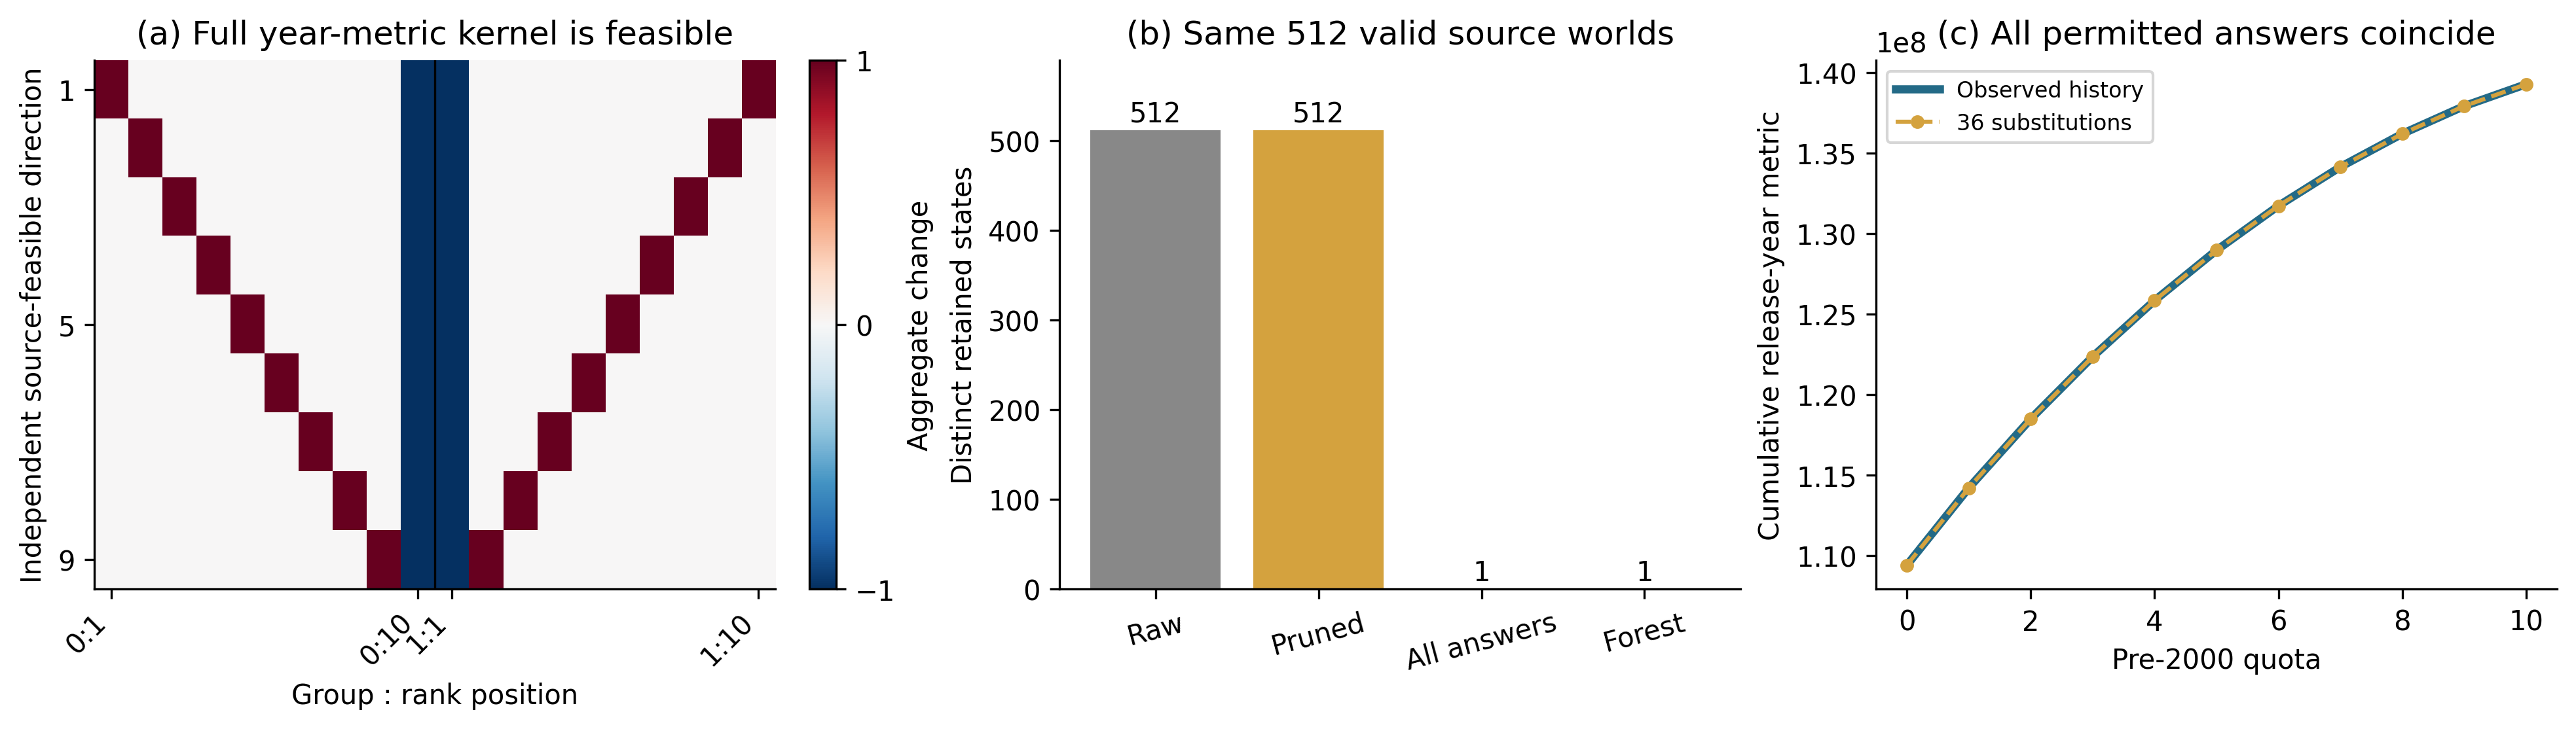

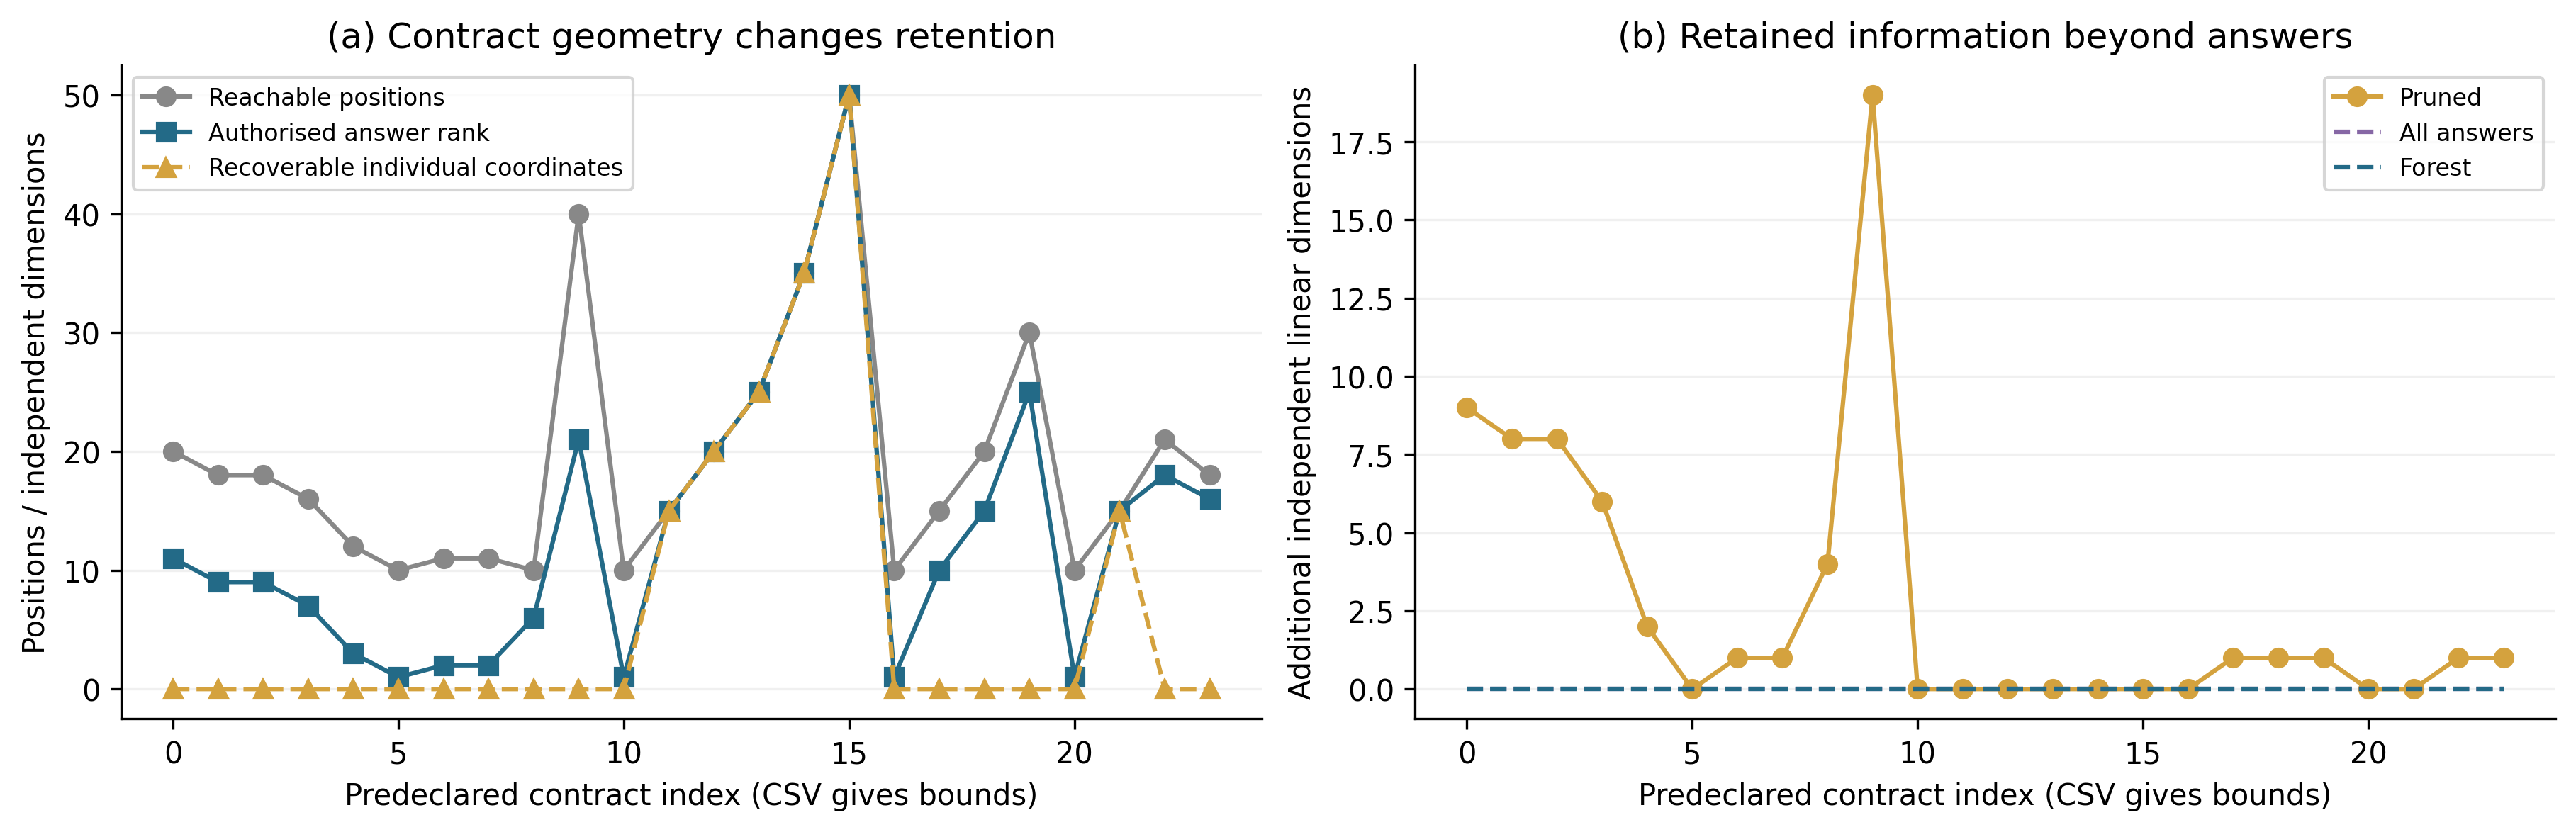

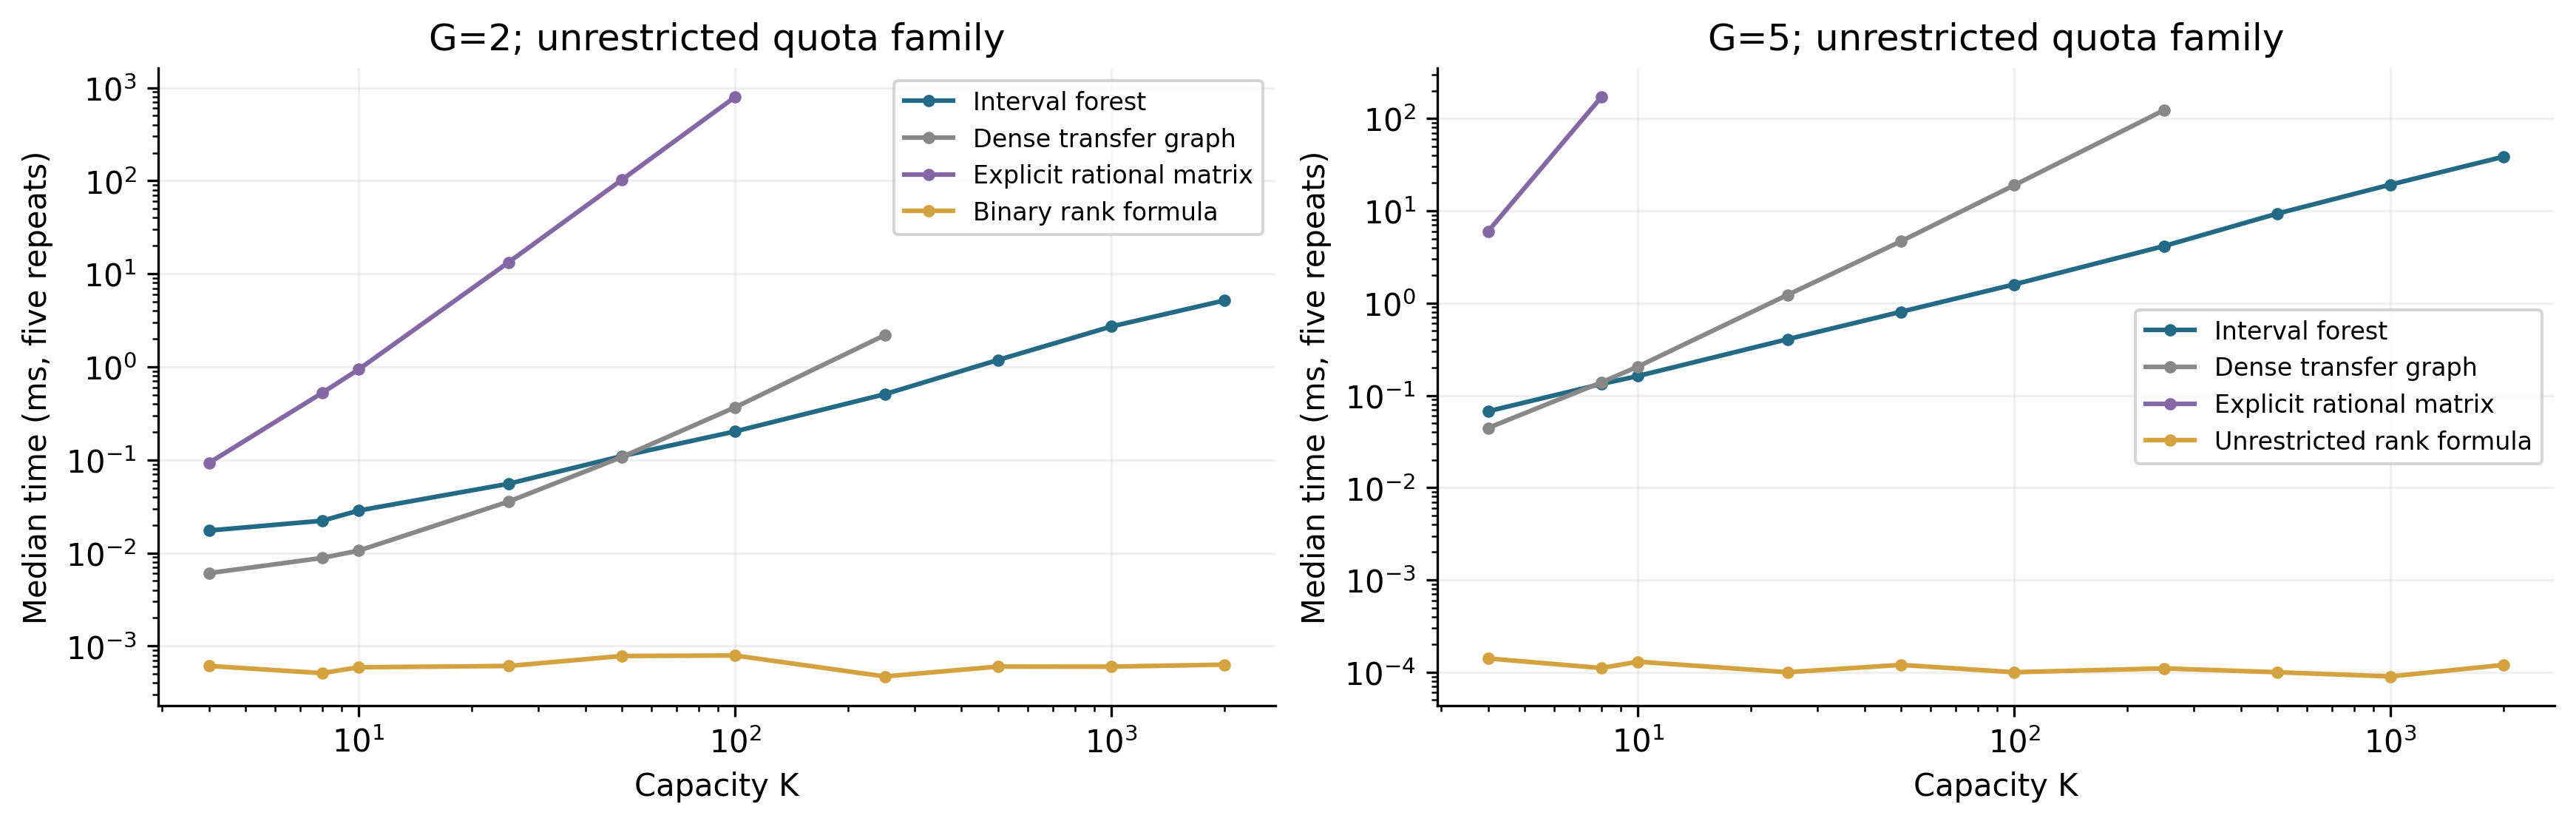

In [8]:
for name in ('fixed_catalogue_information','contract_sensitivity','compiler_scalability'):
    display(Image(filename=str(RESULTS/'figures'/f'{name}.png')))

In [9]:
checks = pd.read_csv(RESULTS/'tables/checks.csv')
assert checks.passed.all()
display(checks[['check','passed','count']])
verified = subprocess.run([sys.executable,str(PACKAGE_DIR/'verify.py'),str(RESULTS)],
                          cwd=str(PACKAGE_DIR),check=True,text=True,stdout=subprocess.PIPE)
print(verified.stdout)
print('All final checks passed. Remaining limitations: results/SCIENTIFIC_SCOPE.json.')

,check,passed,count
0,A0: four frozen representations and exact stru...,True,129
1,A1: four frozen representations and exact stru...,True,89
2,M0: four frozen representations and exact stru...,True,99
3,M1: four frozen representations and exact stru...,True,69
4,Every reachable pairwise contrast: structural ...,True,1538
5,M0: graph and independent legal-query attacks ...,True,40
6,M0 negative controls reject missing answers an...,True,2
7,Full MovieLens CSV parser/window oracle matche...,True,8
8,Fixed catalogue: 36 disjoint valid source subs...,True,36
9,Nine independent feasible year-metric directio...,True,9


PASS: 105 file hashes, exact M0 decoder, rank-nine M1 kernel, and 512 world certificates.
Source-level revalidation: run study.py with the official MovieLens archive; raw data are intentionally not bundled.

All final checks passed. Remaining limitations: results/SCIENTIFIC_SCOPE.json.


In [10]:
RESULTS_ZIP = Path.cwd()/'RetainQ_Study_Results.zip'
with zipfile.ZipFile(RESULTS_ZIP,'w',zipfile.ZIP_DEFLATED,compresslevel=9) as archive:
    for path in sorted(PACKAGE_DIR.rglob('*')):
        if path.is_file() and '__pycache__' not in path.parts:
            archive.write(path,path.relative_to(PACKAGE_DIR).as_posix())
display(FileLink(RESULTS_ZIP.name))
try:
    from google.colab import files as colab_files
except ImportError:
    print('Complete code and results archive is ready.')
else:
    colab_files.download(str(RESULTS_ZIP))

RetainQ_Study_Results.zip

Complete code and results archive is ready.
